In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

In [3]:
train = pd.read_csv("train.csv")

In [4]:
test = pd.read_csv("test.csv")

In [5]:
from pathlib import Path

ARTIFACT_DIR = Path(r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts")

print("Folder exists:", ARTIFACT_DIR.exists())
print("\nFiles found:")

if ARTIFACT_DIR.exists():
    for f in ARTIFACT_DIR.iterdir():
        print(f.name)

Folder exists: True

Files found:
blend_lgb30_xgb20_depth4_50_metadata.json
catboost_fold_4.cbm
catboost_oof.csv
catboost_test.csv
data
experiments
features
lgb_63_metadata.json
lightgbm_oof.csv
lightgbm_test.csv
logs
models
oof
oof_blend_lgb30_xgb20_depth4_50.npy
oof_cat.npy
oof_income_regime.npy
oof_lgb.npy
oof_lgb_63.npy
oof_lgb_xgb_50_50.npy
oof_xgb.npy
oof_xgb_depth4.npy
submissions
submission_2_champion_home15.csv
submission_4_lgb36_xgb4_depth4_60.csv
submission_final_lgb30_xgb20_depth4_50.csv
submission_final_lgb36_xgb4_depth4_60.csv
submission_lgb_xgb_50_50.csv
test_cat.npy
test_lgb.npy
test_lgb_xgb_50_50.npy
test_predictions
test_xgb.npy
test_xgb_depth4.npy
xgb_depth4_metadata.json


In [6]:
oof_cat = np.load(ARTIFACT_DIR / "oof_cat.npy")
test_cat = np.load(ARTIFACT_DIR / "test_cat.npy")

oof_lgb = np.load(ARTIFACT_DIR / "oof_lgb.npy")
test_lgb = np.load(ARTIFACT_DIR / "test_lgb.npy")

oof_xgb = np.load(ARTIFACT_DIR / "oof_xgb.npy")
test_xgb = np.load(ARTIFACT_DIR / "test_xgb.npy")

In [7]:
print("Test shape:", test.shape)
print("LightGBM predictions:", test_lgb.shape)
print("XGBoost predictions:", test_xgb.shape)

Test shape: (286571, 14)
LightGBM predictions: (286571,)
XGBoost predictions: (286571,)


In [8]:
# ==============================
# Prediction sanity check
# ==============================

print("LightGBM")
print("  NaN:", np.isnan(test_lgb).sum())
print("  Inf:", np.isinf(test_lgb).sum())
print("  Min:", test_lgb.min())
print("  Max:", test_lgb.max())
print("  Mean:", test_lgb.mean())

print("\nXGBoost")
print("  NaN:", np.isnan(test_xgb).sum())
print("  Inf:", np.isinf(test_xgb).sum())
print("  Min:", test_xgb.min())
print("  Max:", test_xgb.max())
print("  Mean:", test_xgb.mean())

LightGBM
  NaN: 0
  Inf: 0
  Min: 1.5735759670407232e-05
  Max: 0.9685599759042715
  Mean: 0.1746247511091655

XGBoost
  NaN: 0
  Inf: 0
  Min: 1.7644767e-05
  Max: 0.9744015
  Mean: 0.17467262


In [9]:
# ==============================
# Champion: 50/50 LGBM + XGBoost
# ==============================

test_blend = 0.5 * test_lgb + 0.5 * test_xgb

print("Blend shape:", test_blend.shape)
print("Min:", test_blend.min())
print("Max:", test_blend.max())
print("Mean:", test_blend.mean())
print("NaN:", np.isnan(test_blend).sum())
print("Inf:", np.isinf(test_blend).sum())

Blend shape: (286571,)
Min: 2.0555493681989524e-05
Max: 0.9676590583694517
Mean: 0.17464870323226864
NaN: 0
Inf: 0


In [10]:
# ==============================
# Inspect sample submission
# ==============================

sample_submission = pd.read_csv("sample_submission.csv")

print("Sample submission shape:", sample_submission.shape)
print("\nColumns:")
print(sample_submission.columns.tolist())

print("\nFirst 5 rows:")
display(sample_submission.head())

print("\nTest columns:")
print(test.columns.tolist())

Sample submission shape: (286571, 2)

Columns:
['id', 'Will_Buy_EV']

First 5 rows:


,id,Will_Buy_EV
0,668665,0.174645
1,668666,0.174645
2,668667,0.174645
3,668668,0.174645
4,668669,0.174645



Test columns:
['id', 'Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level']


In [11]:
# ==============================
# Create final Kaggle submission
# ==============================

submission = pd.DataFrame({
    "id": test["id"],
    "Will_Buy_EV": test_blend
})

# Safety checks
assert len(submission) == len(test)
assert submission["id"].equals(test["id"])
assert submission["Will_Buy_EV"].isna().sum() == 0
assert np.isfinite(submission["Will_Buy_EV"]).all()

# Save
SUBMISSION_PATH = ARTIFACT_DIR / "submission_lgb_xgb_50_50.csv"

submission.to_csv(SUBMISSION_PATH, index=False)

print("Submission saved:")
print(SUBMISSION_PATH)

print("\nShape:", submission.shape)
print("\nColumns:", submission.columns.tolist())

print("\nFirst 10 rows:")
display(submission.head(10))

Submission saved:
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submission_lgb_xgb_50_50.csv

Shape: (286571, 2)

Columns: ['id', 'Will_Buy_EV']

First 10 rows:


,id,Will_Buy_EV
0,668665,0.009669
1,668666,0.017023
2,668667,0.004674
3,668668,0.003073
4,668669,0.019169
5,668670,0.004237
6,668671,0.363967
7,668672,0.000245
8,668673,0.657465
9,668674,0.005275


In [12]:
# ==============================
# FINAL SUBMISSION VALIDATION
# ==============================

print("========== FINAL VALIDATION ==========\n")

# 1. Row count
print("1. Row count")
print("   Test rows       :", len(test))
print("   Submission rows :", len(submission))
print("   Match           :", len(test) == len(submission))

# 2. IDs
print("\n2. ID validation")
print("   IDs match test order :", submission["id"].equals(test["id"]))
print("   Unique submission IDs:", submission["id"].nunique())
print("   Min ID              :", submission["id"].min())
print("   Max ID              :", submission["id"].max())

# 3. Predictions
print("\n3. Prediction validation")
print("   NaN :", submission["Will_Buy_EV"].isna().sum())
print("   Inf :", np.isinf(submission["Will_Buy_EV"]).sum())
print("   Min :", submission["Will_Buy_EV"].min())
print("   Max :", submission["Will_Buy_EV"].max())
print("   Mean:", submission["Will_Buy_EV"].mean())

# 4. Column names
print("\n4. Columns")
print("   ", submission.columns.tolist())

# 5. File existence
print("\n5. File")
print("   Path:", SUBMISSION_PATH)
print("   Exists:", SUBMISSION_PATH.exists())

# Final assertion
assert len(test) == len(submission)
assert submission["id"].equals(test["id"])
assert submission["id"].is_unique
assert submission["Will_Buy_EV"].notna().all()
assert np.isfinite(submission["Will_Buy_EV"]).all()

print("\n✅ ALL FINAL CHECKS PASSED")

========== FINAL VALIDATION ==========

1. Row count
   Test rows       : 286571
   Submission rows : 286571
   Match           : True

2. ID validation
   IDs match test order : True
   Unique submission IDs: 286571
   Min ID              : 668665
   Max ID              : 955235

3. Prediction validation
   NaN : 0
   Inf : 0
   Min : 2.0555493681989524e-05
   Max : 0.9676590583694517
   Mean: 0.17464870323226864

4. Columns
    ['id', 'Will_Buy_EV']

5. File
   Path: C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submission_lgb_xgb_50_50.csv
   Exists: True

✅ ALL FINAL CHECKS PASSED


**first submission completed** => public score ( **0.94170** ) , rank ( **1994** )

In [13]:
# ==============================
# Load OOF predictions
# ==============================

# Load target
y = (train["Will_Buy_EV"] == "Yes").astype(int).values

print("LGB OOF:", oof_lgb.shape)
print("XGB OOF:", oof_xgb.shape)
print("CAT OOF:", oof_cat.shape)
print("Target :", y.shape)

print("\nNaN checks:")
print("LGB:", np.isnan(oof_lgb).sum())
print("XGB:", np.isnan(oof_xgb).sum())
print("CAT:", np.isnan(oof_cat).sum())

LGB OOF: (668665,)
XGB OOF: (668665,)
CAT OOF: (668665,)
Target : (668665,)

NaN checks:
LGB: 0
XGB: 0
CAT: 0


In [17]:
from sklearn.metrics import roc_auc_score

# ==============================
# Test ensemble combinations
# ==============================

blends = {
    "LGB 50 / XGB 50": (
        0.50 * oof_lgb +
        0.50 * oof_xgb
    ),

    "LGB 45 / XGB 45 / CAT 10": (
        0.45 * oof_lgb +
        0.45 * oof_xgb +
        0.10 * oof_cat
    ),

    "LGB 40 / XGB 40 / CAT 20": (
        0.40 * oof_lgb +
        0.40 * oof_xgb +
        0.20 * oof_cat
    ),

    "LGB 50 / XGB 40 / CAT 10": (
        0.50 * oof_lgb +
        0.40 * oof_xgb +
        0.10 * oof_cat
    ),

    "LGB 40 / XGB 50 / CAT 10": (
        0.40 * oof_lgb +
        0.50 * oof_xgb +
        0.10 * oof_cat
    ),
}

results = []

for name, pred in blends.items():
    auc = roc_auc_score(y, pred)
    results.append({
        "Blend": name,
        "OOF AUC": auc
    })

results_df = pd.DataFrame(results).sort_values(
    "OOF AUC",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Blend,OOF AUC
0,LGB 50 / XGB 50,0.942003
1,LGB 40 / XGB 50 / CAT 10,0.942002
2,LGB 45 / XGB 45 / CAT 10,0.942002
3,LGB 50 / XGB 40 / CAT 10,0.941999
4,LGB 40 / XGB 40 / CAT 20,0.941992


In [13]:
# Target
train["target"] = (train["Will_Buy_EV"] == "Yes").astype(int)

# Separate target
y = train["target"]

# Same folds will be used by every model
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = np.zeros(len(train), dtype=int)

for fold, (_, val_idx) in enumerate(skf.split(train, y)):
    folds[val_idx] = fold

print("Fold distribution:")
print(pd.Series(folds).value_counts().sort_index())

print("\nOverall positive rate:", y.mean())

for fold in range(5):
    print(
        f"Fold {fold}:",
        "train =", (folds != fold).sum(),
        "validation =", (folds == fold).sum(),
        "positive rate =",
        y[folds == fold].mean()
    )

Fold distribution:
0    133733
1    133733
2    133733
3    133733
4    133733
Name: count, dtype: int64

Overall positive rate: 0.17464500160768098
Fold 0: train = 534932 validation = 133733 positive rate = 0.17463901953893204
Fold 1: train = 534932 validation = 133733 positive rate = 0.1746464971248682
Fold 2: train = 534932 validation = 133733 positive rate = 0.1746464971248682
Fold 3: train = 534932 validation = 133733 positive rate = 0.1746464971248682
Fold 4: train = 534932 validation = 133733 positive rate = 0.1746464971248682


In [14]:
# ============================================
# Recreate the exact 5-fold split
# ============================================

from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(skf.split(train, y))

print("Number of folds:", len(folds))

for i, (train_idx, val_idx) in enumerate(folds, 1):
    print(
        f"Fold {i}: "
        f"train={len(train_idx)}, "
        f"val={len(val_idx)}"
    )

Number of folds: 5
Fold 1: train=534932, val=133733
Fold 2: train=534932, val=133733
Fold 3: train=534932, val=133733
Fold 4: train=534932, val=133733
Fold 5: train=534932, val=133733


In [25]:
# ============================================
# Experiment: Core 4 + Home Charging
# ============================================

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

core_plus_home = [
    "Annual_Income_USD",
    "Environmental_Concern_Level",
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Home_Charging_Possible"
]

X_exp = train[core_plus_home].copy()

# Convert categorical columns to category dtype
categorical_cols = [
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Home_Charging_Possible"
]

for col in categorical_cols:
    X_exp[col] = X_exp[col].astype("category")

oof_home = np.zeros(len(train))

for fold, (train_idx, val_idx) in enumerate(folds, 1):

    X_train = X_exp.iloc[train_idx]
    X_val = X_exp.iloc[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=0.0,
        objective="binary",
        metric="auc",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_train,
        y_train,
        categorical_feature=categorical_cols
    )

    oof_home[val_idx] = model.predict_proba(X_val)[:, 1]

    fold_auc = roc_auc_score(y_val, oof_home[val_idx])

    print(f"Fold {fold}: {fold_auc:.6f}")

overall_auc = roc_auc_score(y, oof_home)

print("\n================================")
print(f"Core 4 + Home Charging OOF AUC: {overall_auc:.6f}")
print(f"Current champion OOF AUC:       {0.9420026857448622:.6f}")
print(f"Difference:                    {overall_auc - 0.9420026857448622:+.6f}")
print("================================")

Fold 1: 0.939240
Fold 2: 0.940454
Fold 3: 0.941674
Fold 4: 0.941201
Fold 5: 0.940581

Core 4 + Home Charging OOF AUC: 0.940618
Current champion OOF AUC:       0.942003
Difference:                    -0.001385


In [26]:
# ============================================
# Experiment: Core 4 + Home Charging
# Check blend contribution to champion
# ============================================

from sklearn.metrics import roc_auc_score

champion_oof = 0.5 * oof_lgb + 0.5 * oof_xgb

# How different is the Home Charging model
# from our current champion?
corr_home = np.corrcoef(oof_home, champion_oof)[0, 1]

print(f"Home model AUC:       {roc_auc_score(y, oof_home):.6f}")
print(f"Champion AUC:         {roc_auc_score(y, champion_oof):.6f}")
print(f"Prediction correlation: {corr_home:.6f}")

# Try a very small contribution from Home model
for w in [0.02, 0.05, 0.10, 0.15, 0.20]:

    blended = (
        (1 - w) * champion_oof
        + w * oof_home
    )

    auc = roc_auc_score(y, blended)

    print(f"Champion {1-w:.0%} + Home {w:.0%}: {auc:.6f}")

Home model AUC:       0.940618
Champion AUC:         0.942003
Prediction correlation: 0.991583
Champion 98% + Home 2%: 0.942016
Champion 95% + Home 5%: 0.942033
Champion 90% + Home 10%: 0.942053
Champion 85% + Home 15%: 0.942062
Champion 80% + Home 20%: 0.942060


In [27]:
# ============================================
# Per-fold validation of Champion + Home blend
# ============================================

from sklearn.metrics import roc_auc_score
import numpy as np

weights = [0.05, 0.10, 0.15, 0.20]

print("Per-fold AUC comparison")
print("=" * 60)

for fold_num, (train_idx, val_idx) in enumerate(folds, 1):

    y_val = y[val_idx]

    champion_val = 0.5 * (
        oof_lgb[val_idx] +
        oof_xgb[val_idx]
    )

    home_val = oof_home[val_idx]

    champion_auc = roc_auc_score(y_val, champion_val)

    print(f"\nFold {fold_num}")
    print(f"Champion: {champion_auc:.6f}")

    for w in weights:
        blended_val = (
            (1 - w) * champion_val
            + w * home_val
        )

        auc = roc_auc_score(y_val, blended_val)

        print(
            f"  Home {w:.0%}: "
            f"{auc:.6f} "
            f"({auc - champion_auc:+.6f})"
        )

Per-fold AUC comparison

Fold 1
Champion: 0.940776
  Home 5%: 0.940798 (+0.000022)
  Home 10%: 0.940812 (+0.000036)
  Home 15%: 0.940815 (+0.000038)
  Home 20%: 0.940808 (+0.000032)

Fold 2
Champion: 0.941806
  Home 5%: 0.941840 (+0.000033)
  Home 10%: 0.941862 (+0.000055)
  Home 15%: 0.941873 (+0.000067)
  Home 20%: 0.941873 (+0.000067)

Fold 3
Champion: 0.943021
  Home 5%: 0.943050 (+0.000029)
  Home 10%: 0.943070 (+0.000049)
  Home 15%: 0.943079 (+0.000058)
  Home 20%: 0.943078 (+0.000057)

Fold 4
Champion: 0.942541
  Home 5%: 0.942576 (+0.000035)
  Home 10%: 0.942599 (+0.000059)
  Home 15%: 0.942612 (+0.000071)
  Home 20%: 0.942613 (+0.000072)

Fold 5
Champion: 0.941929
  Home 5%: 0.941962 (+0.000033)
  Home 10%: 0.941983 (+0.000054)
  Home 15%: 0.941993 (+0.000063)
  Home 20%: 0.941993 (+0.000063)


In [28]:
# ============================================
# Experiment: Full LightGBM + Home Charging
# ============================================

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

features_full_home = [
    col for col in train.columns
    if col not in [
        "id",
        "Will_Buy_EV",
        "target"
    ]
]

X_exp = train[features_full_home].copy()

categorical_cols = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

for col in categorical_cols:
    X_exp[col] = X_exp[col].astype("category")

oof_full_home = np.zeros(len(train))

for fold, (train_idx, val_idx) in enumerate(folds, 1):

    X_train = X_exp.iloc[train_idx]
    X_val = X_exp.iloc[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=0.0,
        objective="binary",
        metric="auc",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_train,
        y_train,
        categorical_feature=categorical_cols
    )

    oof_full_home[val_idx] = model.predict_proba(X_val)[:, 1]

    fold_auc = roc_auc_score(
        y_val,
        oof_full_home[val_idx]
    )

    print(f"Fold {fold}: {fold_auc:.6f}")

overall_auc = roc_auc_score(y, oof_full_home)

print("\n================================")
print(f"Full + Home LGB OOF AUC: {overall_auc:.6f}")
print(f"Original LGB OOF AUC:    {roc_auc_score(y, oof_lgb):.6f}")
print(f"Difference:              {overall_auc - roc_auc_score(y, oof_lgb):+.6f}")
print("================================")

Fold 1: 0.940565
Fold 2: 0.941460
Fold 3: 0.942847
Fold 4: 0.942209
Fold 5: 0.941670

Full + Home LGB OOF AUC: 0.941741
Original LGB OOF AUC:    0.941832
Difference:              -0.000090


In [29]:
# ============================================
# Experiment: Core 4 + Current Car Type
# ============================================

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

core_plus_car = [
    "Annual_Income_USD",
    "Environmental_Concern_Level",
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Current_Car_Type"
]

X_exp = train[core_plus_car].copy()

categorical_cols = [
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Current_Car_Type"
]

for col in categorical_cols:
    X_exp[col] = X_exp[col].astype("category")

oof_car = np.zeros(len(train))

for fold, (train_idx, val_idx) in enumerate(folds, 1):

    X_train = X_exp.iloc[train_idx]
    X_val = X_exp.iloc[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=0.0,
        objective="binary",
        metric="auc",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_train,
        y_train,
        categorical_feature=categorical_cols
    )

    oof_car[val_idx] = model.predict_proba(X_val)[:, 1]

    fold_auc = roc_auc_score(
        y_val,
        oof_car[val_idx]
    )

    print(f"Fold {fold}: {fold_auc:.6f}")

overall_auc = roc_auc_score(y, oof_car)

print("\n================================")
print(f"Core 4 + Car Type OOF AUC: {overall_auc:.6f}")
print(f"Core 4 OOF AUC:            0.940364")
print(f"Current champion:           0.942003")
print(f"Difference vs Core 4:      {overall_auc - 0.940364:+.6f}")
print("================================")

Fold 1: 0.939149
Fold 2: 0.940304
Fold 3: 0.941446
Fold 4: 0.941121
Fold 5: 0.940545

Core 4 + Car Type OOF AUC: 0.940502
Core 4 OOF AUC:            0.940364
Current champion:           0.942003
Difference vs Core 4:      +0.000138


In [30]:
# ============================================
# Test Core 4 + Car Type as a complementary
# model to the current champion
# ============================================

from sklearn.metrics import roc_auc_score
import numpy as np

champion_oof = 0.5 * (oof_lgb + oof_xgb)

print(f"Car model AUC:  {roc_auc_score(y, oof_car):.6f}")
print(f"Champion AUC:   {roc_auc_score(y, champion_oof):.6f}")
print(
    f"Prediction correlation: "
    f"{np.corrcoef(oof_car, champion_oof)[0,1]:.6f}"
)

for w in [0.05, 0.10, 0.15, 0.20]:

    blended = (
        (1 - w) * champion_oof
        + w * oof_car
    )

    auc = roc_auc_score(y, blended)

    print(
        f"Champion {(1-w):.0%} + Car {w:.0%}: "
        f"{auc:.6f} "
        f"({auc - roc_auc_score(y, champion_oof):+.6f})"
    )

Car model AUC:  0.940502
Champion AUC:   0.942003
Prediction correlation: 0.991026
Champion 95% + Car 5%: 0.942033 (+0.000031)
Champion 90% + Car 10%: 0.942052 (+0.000050)
Champion 85% + Car 15%: 0.942060 (+0.000057)
Champion 80% + Car 20%: 0.942057 (+0.000054)


In [31]:
# ============================================
# Champion + Home + Car Type
# ============================================

from sklearn.metrics import roc_auc_score
import numpy as np

champion_oof = 0.5 * (oof_lgb + oof_xgb)

print("Individual correlations")
print("=" * 50)
print(
    f"Champion ↔ Home: "
    f"{np.corrcoef(champion_oof, oof_home)[0,1]:.6f}"
)
print(
    f"Champion ↔ Car:  "
    f"{np.corrcoef(champion_oof, oof_car)[0,1]:.6f}"
)
print(
    f"Home ↔ Car:      "
    f"{np.corrcoef(oof_home, oof_car)[0,1]:.6f}"
)

print("\nBlend experiments")
print("=" * 50)

# Keep total auxiliary contribution at 20%
# and vary the Home/Car allocation.

for home_w in [0.05, 0.10, 0.15]:

    car_w = 0.20 - home_w
    champion_w = 0.80

    blended = (
        champion_w * champion_oof
        + home_w * oof_home
        + car_w * oof_car
    )

    auc = roc_auc_score(y, blended)

    print(
        f"Champion {champion_w:.0%} + "
        f"Home {home_w:.0%} + "
        f"Car {car_w:.0%}: "
        f"{auc:.6f} "
        f"({auc - roc_auc_score(y, champion_oof):+.6f})"
    )

Individual correlations
Champion ↔ Home: 0.991583
Champion ↔ Car:  0.991026
Home ↔ Car:      0.998512

Blend experiments
Champion 80% + Home 5% + Car 15%: 0.942061 (+0.000059)
Champion 80% + Home 10% + Car 10%: 0.942063 (+0.000061)
Champion 80% + Home 15% + Car 5%: 0.942063 (+0.000060)


In [32]:
# ============================================
# Train Core 4 + Home on full training data
# Generate test predictions
# ============================================

from lightgbm import LGBMClassifier
import numpy as np

core_plus_home = [
    "Annual_Income_USD",
    "Environmental_Concern_Level",
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Home_Charging_Possible"
]

X_train_final = train[core_plus_home].copy()
X_test_final = test[core_plus_home].copy()

categorical_cols = [
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Home_Charging_Possible"
]

for col in categorical_cols:
    X_train_final[col] = X_train_final[col].astype("category")
    X_test_final[col] = X_test_final[col].astype("category")

model_home_final = LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=0.0,
    objective="binary",
    metric="auc",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

model_home_final.fit(
    X_train_final,
    y,
    categorical_feature=categorical_cols
)

test_home = model_home_final.predict_proba(X_test_final)[:, 1]

print("Test predictions:", test_home.shape)
print("Min:", test_home.min())
print("Max:", test_home.max())
print("Mean:", test_home.mean())
print("NaN:", np.isnan(test_home).sum())
print("Inf:", np.isinf(test_home).sum())

Test predictions: (286571,)
Min: 2.621719903602898e-09
Max: 0.9300575122322965
Mean: 0.17491264184337008
NaN: 0
Inf: 0


In [33]:
# ============================================
# Submission #2
# 85% LGB+XGB champion + 15% Core4+Home
# ============================================

from pathlib import Path
import pandas as pd
import numpy as np

ARTIFACT_DIR = Path(
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"
)

# Load full-test predictions from the original champion
test_lgb = np.load(ARTIFACT_DIR / "test_lgb.npy")
test_xgb = np.load(ARTIFACT_DIR / "test_xgb.npy")

# Original champion
test_champion = 0.5 * test_lgb + 0.5 * test_xgb

# Final Submission #2 blend
test_submission_2 = (
    0.85 * test_champion
    + 0.15 * test_home
)

submission_2 = pd.DataFrame({
    "id": test["id"],
    "Will_Buy_EV": test_submission_2
})

submission_path = (
    ARTIFACT_DIR / "submission_2_champion_home15.csv"
)

submission_2.to_csv(
    submission_path,
    index=False
)

# ============================================
# Validation
# ============================================

print("Submission #2 created")
print("--------------------------------")
print("Path:", submission_path)
print("Rows:", len(submission_2))
print("Columns:", submission_2.columns.tolist())
print("IDs match:", submission_2["id"].equals(test["id"]))
print("Unique IDs:", submission_2["id"].nunique())
print("NaN:", submission_2["Will_Buy_EV"].isna().sum())
print("Inf:", np.isinf(submission_2["Will_Buy_EV"]).sum())
print("Min:", submission_2["Will_Buy_EV"].min())
print("Max:", submission_2["Will_Buy_EV"].max())
print("Mean:", submission_2["Will_Buy_EV"].mean())

Submission #2 created
--------------------------------
Path: C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submission_2_champion_home15.csv
Rows: 286571
Columns: ['id', 'Will_Buy_EV']
IDs match: True
Unique IDs: 286571
NaN: 0
Inf: 0
Min: 1.748166453691242e-05
Max: 0.9605980242928662
Mean: 0.1746882940239338


**second** submission completed => public score ( **0.94175** ) , rank ( **1934** )

In [34]:
# ============================================
# Experiment: Core 4 + City Type
# ============================================

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

core_plus_city = [
    "Annual_Income_USD",
    "Environmental_Concern_Level",
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "City_Type"
]

X_exp = train[core_plus_city].copy()

categorical_cols = [
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "City_Type"
]

for col in categorical_cols:
    X_exp[col] = X_exp[col].astype("category")

oof_city = np.zeros(len(train))

for fold, (train_idx, val_idx) in enumerate(folds, 1):

    X_train = X_exp.iloc[train_idx]
    X_val = X_exp.iloc[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=0.0,
        objective="binary",
        metric="auc",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_train,
        y_train,
        categorical_feature=categorical_cols
    )

    oof_city[val_idx] = model.predict_proba(X_val)[:, 1]

    fold_auc = roc_auc_score(
        y_val,
        oof_city[val_idx]
    )

    print(f"Fold {fold}: {fold_auc:.6f}")

overall_auc = roc_auc_score(y, oof_city)

print("\n================================")
print(f"Core 4 + City Type OOF AUC: {overall_auc:.6f}")
print(f"Core 4 OOF AUC:            0.940364")
print(f"Current champion:           0.942003")
print(f"Difference vs Core 4:      {overall_auc - 0.940364:+.6f}")
print("================================")

Fold 1: 0.939228
Fold 2: 0.940423
Fold 3: 0.941583
Fold 4: 0.941090
Fold 5: 0.940536

Core 4 + City Type OOF AUC: 0.940561
Core 4 OOF AUC:            0.940364
Current champion:           0.942003
Difference vs Core 4:      +0.000197


In [35]:
# ============================================
# Test Core 4 + City as complementary model
# ============================================

from sklearn.metrics import roc_auc_score
import numpy as np

champion_oof = 0.5 * (oof_lgb + oof_xgb)

champion_auc = roc_auc_score(y, champion_oof)
city_auc = roc_auc_score(y, oof_city)

print(f"City model AUC:        {city_auc:.6f}")
print(f"Champion AUC:          {champion_auc:.6f}")
print(
    f"Prediction correlation: "
    f"{np.corrcoef(oof_city, champion_oof)[0,1]:.6f}"
)

print("\nBlend tests")
print("=" * 50)

for w in [0.05, 0.10, 0.15, 0.20]:

    blended = (
        (1 - w) * champion_oof
        + w * oof_city
    )

    auc = roc_auc_score(y, blended)

    print(
        f"Champion {(1-w):.0%} + City {w:.0%}: "
        f"{auc:.6f} "
        f"({auc - champion_auc:+.6f})"
    )

City model AUC:        0.940561
Champion AUC:          0.942003
Prediction correlation: 0.991195

Blend tests
Champion 95% + City 5%: 0.942034 (+0.000032)
Champion 90% + City 10%: 0.942055 (+0.000052)
Champion 85% + City 15%: 0.942064 (+0.000061)
Champion 80% + City 20%: 0.942063 (+0.000060)


In [36]:
# ============================================
# Champion + Home + City complementary blend
# ============================================

from sklearn.metrics import roc_auc_score
import numpy as np

champion_oof = 0.5 * (oof_lgb + oof_xgb)

print("Prediction correlations")
print("=" * 50)
print(f"Champion ↔ Home : {np.corrcoef(champion_oof, oof_home)[0,1]:.6f}")
print(f"Champion ↔ City : {np.corrcoef(champion_oof, oof_city)[0,1]:.6f}")
print(f"Home ↔ City     : {np.corrcoef(oof_home, oof_city)[0,1]:.6f}")

champion_auc = roc_auc_score(y, champion_oof)

print("\nBlend tests")
print("=" * 50)

# Total auxiliary-model weight = 5%, 10%, 15%, 20%
# Split auxiliary weight equally between Home and City.

for total_aux in [0.05, 0.10, 0.15, 0.20]:

    blended = (
        (1 - total_aux) * champion_oof
        + (total_aux / 2) * oof_home
        + (total_aux / 2) * oof_city
    )

    auc = roc_auc_score(y, blended)

    print(
        f"Champion {(1-total_aux):.0%} + "
        f"Home {total_aux/2:.0%} + "
        f"City {total_aux/2:.0%}: "
        f"{auc:.6f} "
        f"({auc - champion_auc:+.6f})"
    )

Prediction correlations
Champion ↔ Home : 0.991583
Champion ↔ City : 0.991195
Home ↔ City     : 0.998845

Blend tests
Champion 95% + Home 2% + City 2%: 0.942034 (+0.000031)
Champion 90% + Home 5% + City 5%: 0.942055 (+0.000052)
Champion 85% + Home 8% + City 8%: 0.942065 (+0.000062)
Champion 80% + Home 10% + City 10%: 0.942065 (+0.000063)


In [37]:
# ============================================
# Core 4 + Gender
# ============================================

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
import numpy as np

core_plus_gender = [
    "Annual_Income_USD",
    "Environmental_Concern_Level",
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Gender"
]

X_gender = train[core_plus_gender].copy()

cat_cols_gender = [
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Gender"
]

for col in cat_cols_gender:
    X_gender[col] = X_gender[col].astype("category")

oof_gender = np.zeros(len(train))

for fold, (train_idx, val_idx) in enumerate(folds):

    X_tr = X_gender.iloc[train_idx]
    X_val = X_gender.iloc[val_idx]

    y_tr = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=0.0,
        objective="binary",
        metric="auc",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_tr,
        y_tr,
        categorical_feature=cat_cols_gender,
        eval_set=[(X_val, y_val)],
        callbacks=[]
    )

    oof_gender[val_idx] = model.predict_proba(X_val)[:, 1]

    print(
        f"Fold {fold+1}: "
        f"{roc_auc_score(y_val, oof_gender[val_idx]):.6f}"
    )

gender_auc = roc_auc_score(y, oof_gender)

print("\nOverall Gender model AUC:")
print(f"{gender_auc:.6f}")

C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1: 0.939141


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2: 0.940299


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 3: 0.941507


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4: 0.941060


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 5: 0.940532

Overall Gender model AUC:
0.940496


In [38]:
# ============================================
# Test Core 4 + Gender as complementary model
# ============================================

from sklearn.metrics import roc_auc_score
import numpy as np

champion_oof = 0.5 * (oof_lgb + oof_xgb)

champion_auc = roc_auc_score(y, champion_oof)

print(f"Gender model AUC:     {roc_auc_score(y, oof_gender):.6f}")
print(f"Champion AUC:         {champion_auc:.6f}")
print(
    f"Prediction correlation: "
    f"{np.corrcoef(oof_gender, champion_oof)[0,1]:.6f}"
)

print("\nBlend tests")
print("=" * 50)

for w in [0.05, 0.10, 0.15, 0.20]:

    blended = (
        (1 - w) * champion_oof
        + w * oof_gender
    )

    auc = roc_auc_score(y, blended)

    print(
        f"Champion {(1-w):.0%} + Gender {w:.0%}: "
        f"{auc:.6f} "
        f"({auc - champion_auc:+.6f})"
    )

Gender model AUC:     0.940496
Champion AUC:         0.942003
Prediction correlation: 0.991073

Blend tests
Champion 95% + Gender 5%: 0.942033 (+0.000031)
Champion 90% + Gender 10%: 0.942053 (+0.000050)
Champion 85% + Gender 15%: 0.942060 (+0.000058)
Champion 80% + Gender 20%: 0.942057 (+0.000055)


In [39]:
# ============================================
# Residual signal diagnostic
# ============================================

from sklearn.metrics import roc_auc_score
import pandas as pd
import numpy as np

champion_oof = 0.5 * (oof_lgb + oof_xgb)

# Residual direction:
# positive = model under-predicted
# negative = model over-predicted
residual = y.values - champion_oof

numeric_features = [
    "Age",
    "Daily_Commute_km",
    "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work"
]

print("Residual correlations")
print("=" * 60)

for col in numeric_features:
    corr = np.corrcoef(
        train[col].values,
        residual
    )[0, 1]

    print(f"{col:<35} {corr:+.6f}")

print("\nResidual mean by feature quintile")
print("=" * 60)

for col in numeric_features:

    tmp = pd.DataFrame({
        "feature": train[col].values,
        "residual": residual
    })

    tmp["bin"] = pd.qcut(
        tmp["feature"],
        q=5,
        duplicates="drop"
    )

    grouped = tmp.groupby("bin", observed=True)["residual"].mean()

    print(f"\n{col}")
    print(grouped.to_string())

Residual correlations
Age                                 -0.000033
Daily_Commute_km                    +0.000116
Number_of_Cars_Owned                +0.000528
Charging_Stations_Near_Home         +0.000175
Charging_Stations_Near_Work         +0.000040

Residual mean by feature quintile

Age
bin
(24.999, 34.0]   -0.000266
(34.0, 43.0]      0.000560
(43.0, 51.0]     -0.000521
(51.0, 60.0]      0.000599
(60.0, 69.0]     -0.000177

Daily_Commute_km
bin
(4.999, 28.3]    0.000169
(28.3, 39.0]    -0.000396
(39.0, 49.8]    -0.000026
(49.8, 98.7]     0.000314

Number_of_Cars_Owned
bin
(0.999, 2.0]    0.000018
(2.0, 4.0]      0.000248

Charging_Stations_Near_Home
bin
(-0.001, 1.0]    0.000246
(1.0, 3.0]      -0.000112
(3.0, 5.0]       0.000152
(5.0, 8.0]      -0.000297
(8.0, 14.0]      0.000297

Charging_Stations_Near_Work
bin
(-0.001, 3.0]   -0.000197
(3.0, 5.0]       0.001124
(5.0, 8.0]      -0.000618
(8.0, 12.0]      0.000537
(12.0, 19.0]     0.000043


In [40]:
# ============================================
# CatBoost + LightGBM + XGBoost blend sweep
# ============================================

from sklearn.metrics import roc_auc_score
import numpy as np

champion_oof = 0.5 * (oof_lgb + oof_xgb)

print("Individual AUCs")
print("=" * 50)
print(f"CatBoost : {roc_auc_score(y, oof_cat):.6f}")
print(f"LightGBM : {roc_auc_score(y, oof_lgb):.6f}")
print(f"XGBoost  : {roc_auc_score(y, oof_xgb):.6f}")
print(f"Champion : {roc_auc_score(y, champion_oof):.6f}")

print("\nPrediction correlations")
print("=" * 50)
print(f"Cat ↔ LGB : {np.corrcoef(oof_cat, oof_lgb)[0,1]:.6f}")
print(f"Cat ↔ XGB : {np.corrcoef(oof_cat, oof_xgb)[0,1]:.6f}")

print("\nCatBoost weight sweep")
print("=" * 50)

for cat_weight in [0.01, 0.02, 0.03, 0.05, 0.07, 0.10, 0.15, 0.20]:

    # Keep LGB and XGB equal within the remaining weight
    remaining = 1.0 - cat_weight

    blended = (
        cat_weight * oof_cat
        + (remaining / 2) * oof_lgb
        + (remaining / 2) * oof_xgb
    )

    auc = roc_auc_score(y, blended)

    print(
        f"Cat {cat_weight:.0%} + "
        f"LGB {remaining/2:.1%} + "
        f"XGB {remaining/2:.1%}: "
        f"{auc:.6f} "
        f"({auc - roc_auc_score(y, champion_oof):+.6f})"
    )

Individual AUCs
CatBoost : 0.941582
LightGBM : 0.941832
XGBoost  : 0.941876
Champion : 0.942003

Prediction correlations
Cat ↔ LGB : 0.997506
Cat ↔ XGB : 0.997916

CatBoost weight sweep
Cat 1% + LGB 49.5% + XGB 49.5%: 0.942003 (+0.000000)
Cat 2% + LGB 49.0% + XGB 49.0%: 0.942003 (+0.000001)
Cat 3% + LGB 48.5% + XGB 48.5%: 0.942003 (+0.000001)
Cat 5% + LGB 47.5% + XGB 47.5%: 0.942004 (+0.000001)
Cat 7% + LGB 46.5% + XGB 46.5%: 0.942003 (+0.000001)
Cat 10% + LGB 45.0% + XGB 45.0%: 0.942002 (-0.000001)
Cat 15% + LGB 42.5% + XGB 42.5%: 0.941998 (-0.000005)
Cat 20% + LGB 40.0% + XGB 40.0%: 0.941992 (-0.000011)


In [41]:
# ============================================
# XGBoost alternative: deeper trees
# ============================================

from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
import numpy as np

X = train.drop(columns=["Will_Buy_EV", "target", "id"])

# Convert categoricals exactly as in the previous XGB setup
X = pd.get_dummies(X, columns=[
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
], dtype=np.float32)

X = X.astype(np.float32)

oof_xgb_alt = np.zeros(len(train))

for fold, (train_idx, val_idx) in enumerate(folds):

    X_tr = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_tr = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    model = XGBClassifier(
        n_estimators=2500,
        learning_rate=0.03,

        # Main change
        max_depth=8,
        min_child_weight=10,

        subsample=0.8,
        colsample_bytree=0.8,

        reg_alpha=0.0,
        reg_lambda=1.0,

        objective="binary:logistic",
        eval_metric="auc",

        tree_method="hist",
        device="cpu",

        random_state=42,
        n_jobs=-1,
        early_stopping_rounds=100
    )

    model.fit(
        X_tr,
        y_tr,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    oof_xgb_alt[val_idx] = model.predict_proba(X_val)[:, 1]

    fold_auc = roc_auc_score(
        y_val,
        oof_xgb_alt[val_idx]
    )

    print(f"Fold {fold+1}: {fold_auc:.6f}")

alt_auc = roc_auc_score(y, oof_xgb_alt)

print("\nAlternative XGBoost AUC:")
print(f"{alt_auc:.6f}")

print("\nPrediction correlation with original XGB:")
print(f"{np.corrcoef(oof_xgb, oof_xgb_alt)[0,1]:.6f}")

Fold 1: 0.940428
Fold 2: 0.941401
Fold 3: 0.942596
Fold 4: 0.942233
Fold 5: 0.941590

Alternative XGBoost AUC:
0.941639

Prediction correlation with original XGB:
0.999255


In [42]:
# ============================================
# LightGBM alternative: 63 leaves
# ============================================

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
import numpy as np

X_lgb = train.drop(columns=["Will_Buy_EV", "target", "id"]).copy()

cat_cols = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

for col in cat_cols:
    X_lgb[col] = X_lgb[col].astype("category")

oof_lgb_63 = np.zeros(len(train))

for fold, (train_idx, val_idx) in enumerate(folds):

    X_tr = X_lgb.iloc[train_idx]
    X_val = X_lgb.iloc[val_idx]

    y_tr = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,

        # Main change
        num_leaves=63,

        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=0.0,

        objective="binary",
        metric="auc",

        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_tr,
        y_tr,
        categorical_feature=cat_cols,
        eval_set=[(X_val, y_val)],
        callbacks=[]
    )

    oof_lgb_63[val_idx] = model.predict_proba(X_val)[:, 1]

    fold_auc = roc_auc_score(
        y_val,
        oof_lgb_63[val_idx]
    )

    print(f"Fold {fold+1}: {fold_auc:.6f}")

alt_lgb_auc = roc_auc_score(y, oof_lgb_63)

print("\nAlternative LightGBM AUC:")
print(f"{alt_lgb_auc:.6f}")

print("\nCorrelation with original LightGBM:")
print(f"{np.corrcoef(oof_lgb, oof_lgb_63)[0,1]:.6f}")

C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1: 0.940343


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2: 0.941198


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 3: 0.942564


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4: 0.941836


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 5: 0.941353

Alternative LightGBM AUC:
0.941449

Correlation with original LightGBM:
0.997936


In [43]:
# ============================================
# Save 63-leaf LightGBM experiment
# ============================================

from pathlib import Path
import numpy as np
import json

artifact_dir = Path(
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"
)

artifact_dir.mkdir(parents=True, exist_ok=True)

# Save OOF predictions
np.save(
    artifact_dir / "oof_lgb_63.npy",
    oof_lgb_63
)

# Save experiment metadata
metadata = {
    "model": "LightGBM",
    "experiment": "63_leaves",
    "num_leaves": 63,
    "n_estimators": 2000,
    "learning_rate": 0.03,
    "max_depth": -1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.0,
    "reg_lambda": 0.0,
    "random_state": 42,
    "folds": 5,
    "oof_auc": float(roc_auc_score(y, oof_lgb_63)),
    "correlation_with_original_lgb": float(
        np.corrcoef(oof_lgb, oof_lgb_63)[0, 1]
    )
}

with open(
    artifact_dir / "lgb_63_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=2)

print("Saved:")
print(artifact_dir / "oof_lgb_63.npy")
print(artifact_dir / "lgb_63_metadata.json")

print("\nAUC:", metadata["oof_auc"])
print(
    "Correlation:",
    metadata["correlation_with_original_lgb"]
)

Saved:
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\oof_lgb_63.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\lgb_63_metadata.json

AUC: 0.941449498719234
Correlation: 0.9979360761563856


In [44]:
# ============================================================
# EXPERIMENT B — Leakage-Safe Target Encoding + LightGBM
# ============================================================

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. Base features
# ------------------------------------------------------------

base_features = [
    "Annual_Income_USD",
    "Environmental_Concern_Level",
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Home_Charging_Possible",
    "Current_Car_Type",
    "City_Type",
    "Gender",
]

X_base = train[base_features].copy()
y_arr = y.to_numpy() if hasattr(y, "to_numpy") else np.asarray(y)

# Convert categorical variables to category dtype
categorical_cols = [
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Home_Charging_Possible",
    "Current_Car_Type",
    "City_Type",
    "Gender",
]

for col in categorical_cols:
    X_base[col] = X_base[col].astype("category")

# ------------------------------------------------------------
# 2. Structural groups
# ------------------------------------------------------------

train_te = train.copy()

# Income quantile bins — global bins are ONLY used as a grouping
# variable; target statistics themselves remain fold-safe.
train_te["Income_Bin"] = pd.qcut(
    train_te["Annual_Income_USD"],
    q=20,
    labels=False,
    duplicates="drop"
)

group_specs = [
    ["Subsidy_Available"],
    ["Subsidy_Available", "Range_Anxiety_Level"],
    [
        "Subsidy_Available",
        "Range_Anxiety_Level",
        "Environmental_Concern_Level",
    ],
    [
        "Subsidy_Available",
        "Range_Anxiety_Level",
        "Environmental_Concern_Level",
        "Home_Charging_Possible",
    ],
    [
        "Subsidy_Available",
        "Range_Anxiety_Level",
        "Environmental_Concern_Level",
        "Income_Bin",
    ],
]

global_mean = y_arr.mean()

# ------------------------------------------------------------
# 3. OOF target encoding
# ------------------------------------------------------------

oof_te = np.zeros(len(train))

alpha = 50.0

for fold, (train_idx, val_idx) in enumerate(folds, 1):

    tr = train_te.iloc[train_idx].copy()
    va = train_te.iloc[val_idx].copy()

    y_tr = y_arr[train_idx]

    fold_mean = y_tr.mean()

    encoded_val = np.zeros(len(val_idx), dtype=float)

    for group_id, cols in enumerate(group_specs):

        # Create temporary grouping key
        tr_key = tr[cols].astype(str).agg("___".join, axis=1)
        va_key = va[cols].astype(str).agg("___".join, axis=1)

        stats = (
            pd.DataFrame({
                "key": tr_key.values,
                "target": y_tr
            })
            .groupby("key")["target"]
            .agg(["mean", "count"])
        )

        # Bayesian smoothing
        stats["encoded"] = (
            stats["mean"] * stats["count"] +
            fold_mean * alpha
        ) / (
            stats["count"] + alpha
        )

        encoded = va_key.map(stats["encoded"]).fillna(fold_mean)

        # Give each encoding its own feature
        if group_id == 0:
            oof_te[val_idx] = encoded.values
        else:
            # Store additional TE columns separately later
            pass

# ------------------------------------------------------------
# 4. Build ALL OOF target-encoding columns properly
# ------------------------------------------------------------

te_feature_names = [
    "TE_Subsidy",
    "TE_Subsidy_Range",
    "TE_Subsidy_Range_Env",
    "TE_Subsidy_Range_Env_Home",
    "TE_Subsidy_Range_Env_Income",
]

oof_te_matrix = np.zeros(
    (len(train), len(group_specs)),
    dtype=np.float32
)

for fold, (train_idx, val_idx) in enumerate(folds, 1):

    tr = train_te.iloc[train_idx]
    va = train_te.iloc[val_idx]
    y_tr = y_arr[train_idx]

    fold_mean = y_tr.mean()

    for j, cols in enumerate(group_specs):

        tr_key = tr[cols].astype(str).agg("___".join, axis=1)
        va_key = va[cols].astype(str).agg("___".join, axis=1)

        stats = (
            pd.DataFrame({
                "key": tr_key.values,
                "target": y_tr
            })
            .groupby("key")["target"]
            .agg(["mean", "count"])
        )

        stats["encoded"] = (
            stats["mean"] * stats["count"] +
            fold_mean * alpha
        ) / (
            stats["count"] + alpha
        )

        oof_te_matrix[val_idx, j] = (
            va_key.map(stats["encoded"])
            .fillna(fold_mean)
            .to_numpy()
        )

# ------------------------------------------------------------
# 5. Combine original numerical + TE features
# ------------------------------------------------------------

numeric_features = [
    "Annual_Income_USD",
    "Environmental_Concern_Level",
]

X_num = train[numeric_features].to_numpy(dtype=np.float32)

X_te = np.hstack([
    X_num,
    oof_te_matrix
]).astype(np.float32)

print("TE feature matrix:", X_te.shape)

# ------------------------------------------------------------
# 6. Train LightGBM using TE representation
# ------------------------------------------------------------

oof_te_model = np.zeros(len(train))

for fold, (train_idx, val_idx) in enumerate(folds, 1):

    model = lgb.LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=0.0,
        objective="binary",
        metric="auc",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_te[train_idx],
        y_arr[train_idx],
        eval_set=[(X_te[val_idx], y_arr[val_idx])],
        callbacks=[
            lgb.early_stopping(
                100,
                verbose=False
            )
        ]
    )

    oof_te_model[val_idx] = model.predict_proba(
        X_te[val_idx]
    )[:, 1]

    fold_auc = roc_auc_score(
        y_arr[val_idx],
        oof_te_model[val_idx]
    )

    print(f"Fold {fold}: {fold_auc:.6f}")

# ------------------------------------------------------------
# 7. Final evaluation
# ------------------------------------------------------------

te_auc = roc_auc_score(
    y_arr,
    oof_te_model
)

champion_oof = 0.5 * oof_lgb + 0.5 * oof_xgb

correlation = np.corrcoef(
    champion_oof,
    oof_te_model
)[0, 1]

print("\n======================================")
print("TARGET ENCODING EXPERIMENT")
print("======================================")
print(f"TE Model AUC       : {te_auc:.6f}")
print(f"Champion AUC       : {roc_auc_score(y_arr, champion_oof):.6f}")
print(f"Correlation        : {correlation:.6f}")
print(f"Difference         : {te_auc - roc_auc_score(y_arr, champion_oof):+.6f}")

TE feature matrix: (668665, 7)


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1: 0.939264


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2: 0.940445


...

Fold 3: 0.941759


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4: 0.941332


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 5: 0.940668

TARGET ENCODING EXPERIMENT
TE Model AUC       : 0.940668
Champion AUC       : 0.942003
Correlation        : 0.992630
Difference         : -0.001334


**SMALL NEXT MODEL -> DEAD**

In [45]:
# ============================================================
# PHASE 4A — GAM-STYLE LR
# PART 1: Setup + identical 5-fold split
# ============================================================

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    SplineTransformer
)
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

DATA_DIR = Path(os.environ.get("EV_DATA", "."))

ARTIFACT_DIR = Path(
    os.environ.get(
        "EV_ART",
        r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"
    )
)

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

y = (train["Will_Buy_EV"] == "Yes").astype(int).values

n = len(train)

print("Train shape:", train.shape)
print("Test shape :", test.shape)
print("Target rate:", y.mean())

# ------------------------------------------------------------
# SAME 5 FOLDS AS ALL PREVIOUS EXPERIMENTS
# ------------------------------------------------------------

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(skf.split(train, y))

print("\nFold sizes:")
for k, (tr, va) in enumerate(folds, 1):
    print(
        f"Fold {k}: "
        f"train={len(tr):,} | "
        f"validation={len(va):,} | "
        f"positive rate={y[va].mean():.6f}"
    )

# ------------------------------------------------------------
# Baseline champion
# ------------------------------------------------------------

champion_oof = (
    0.5 * oof_lgb +
    0.5 * oof_xgb
)

print("\nExisting champion OOF AUC:")
print(f"{roc_auc_score(y, champion_oof):.6f}")

Train shape: (668665, 15)
Test shape : (286571, 14)
Target rate: 0.17464500160768098

Fold sizes:
Fold 1: train=534,932 | validation=133,733 | positive rate=0.174639
Fold 2: train=534,932 | validation=133,733 | positive rate=0.174646
Fold 3: train=534,932 | validation=133,733 | positive rate=0.174646
Fold 4: train=534,932 | validation=133,733 | positive rate=0.174646
Fold 5: train=534,932 | validation=133,733 | positive rate=0.174646

Existing champion OOF AUC:
0.942003


In [46]:
# ============================================================
# PHASE 4A — GAM-STYLE LR
# PART 2: Build structural + income-spline features
# ============================================================

# ------------------------------------------------------------
# 1. Structural group
# ------------------------------------------------------------

def grp_key(d):
    return (
        d["Subsidy_Available"].astype(str)
        + "_"
        + d["Range_Anxiety_Level"].astype(str)
        + "_"
        + d["Environmental_Concern_Level"].astype(str)
    ).values.reshape(-1, 1)


# ------------------------------------------------------------
# 2. Additive categorical features
# ------------------------------------------------------------

CATS = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

ADD_COLS = CATS + [
    "Environmental_Concern_Level"
]


# ------------------------------------------------------------
# 3. Other numerical features
# ------------------------------------------------------------

NUM_OTHER = [
    "Age",
    "Daily_Commute_km",
    "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work"
]


# ------------------------------------------------------------
# 4. One-hot encode structural group
# ------------------------------------------------------------

ohe_grp = OneHotEncoder(
    handle_unknown="ignore"
)

ohe_grp.fit(grp_key(train))


# ------------------------------------------------------------
# 5. One-hot encode additive categorical features
# ------------------------------------------------------------

ohe_add = OneHotEncoder(
    handle_unknown="ignore"
)

ohe_add.fit(
    train[ADD_COLS].astype(str)
)


# ------------------------------------------------------------
# 6. Income spline
# ------------------------------------------------------------

income_log = np.log(
    train[["Annual_Income_USD"]].values
)

spl = SplineTransformer(
    n_knots=8,
    degree=3,
    knots="quantile",
    include_bias=False,
    extrapolation="constant"
)

spl.fit(income_log)


# ------------------------------------------------------------
# 7. Standardize remaining numerical features
# ------------------------------------------------------------

scaler = StandardScaler()

scaler.fit(
    train[NUM_OTHER]
)


# ------------------------------------------------------------
# 8. Build design function
# ------------------------------------------------------------

def design(d, interactions=True):

    # 30-way structural group
    G = ohe_grp.transform(
        grp_key(d)
    ).tocsr()

    # Nonlinear income curve
    B = spl.transform(
        np.log(
            d[["Annual_Income_USD"]].values
        )
    )

    # Other categorical variables
    A = ohe_add.transform(
        d[ADD_COLS].astype(str)
    )

    # Other numerical variables
    N = sp.csr_matrix(
        scaler.transform(
            d[NUM_OTHER]
        )
    )

    blocks = [
        G,
        sp.csr_matrix(B),
        A,
        N
    ]

    # --------------------------------------------------------
    # Structural group × income spline interaction
    # --------------------------------------------------------

    if interactions:

        blocks += [
            G.multiply(
                B[:, [j]]
            )
            for j in range(B.shape[1])
        ]

    return sp.hstack(
        blocks
    ).tocsr()


# ------------------------------------------------------------
# 9. Build train + test matrices
# ------------------------------------------------------------

Xd = design(train)

Xd_test = design(test)


# ------------------------------------------------------------
# 10. Inspect
# ------------------------------------------------------------

print("GAM train matrix :", Xd.shape)
print("GAM test matrix  :", Xd_test.shape)
print("Matrix type      :", type(Xd).__name__)
print("Non-zero entries :", Xd.nnz)

print("\nIncome spline features:", spl.n_features_out_)
print("Structural groups    :", ohe_grp.categories_[0].shape[0])
print("Additive features    :", len(ADD_COLS))

GAM train matrix : (668665, 336)
GAM test matrix  : (286571, 336)
Matrix type      : csr_matrix
Non-zero entries : 17227293

Income spline features: 9
Structural groups    : 30
Additive features    : 7


In [47]:
# ============================================================
# PHASE 4A — GAM-STYLE LR
# PART 3: Quick regularization sweep
# ============================================================

tr0, va0 = folds[0]

C_values = [0.03, 0.1, 0.3, 1.0, 3.0]

best_C = None
best_auc = -np.inf

print("Testing C values on Fold 1...\n")

for C in C_values:

    model = LogisticRegression(
        C=C,
        max_iter=1000,
        solver="lbfgs"
    )

    model.fit(
        Xd[tr0],
        y[tr0]
    )

    val_score = model.decision_function(
        Xd[va0]
    )

    auc = roc_auc_score(
        y[va0],
        val_score
    )

    print(
        f"C={C:<4} | "
        f"Fold 1 AUC = {auc:.6f}"
    )

    if auc > best_auc:
        best_auc = auc
        best_C = C

print("\n------------------------------")
print(f"Best C       : {best_C}")
print(f"Best Fold 1  : {best_auc:.6f}")
print("------------------------------")

print(
    f"\nExisting champion Fold 1: "
    f"{roc_auc_score(y[va0], champion_oof[va0]):.6f}"
)

Testing C values on Fold 1...

C=0.03 | Fold 1 AUC = 0.937167
C=0.1  | Fold 1 AUC = 0.937195
C=0.3  | Fold 1 AUC = 0.937198
C=1.0  | Fold 1 AUC = 0.937205
C=3.0  | Fold 1 AUC = 0.937204

------------------------------
Best C       : 1.0
Best Fold 1  : 0.937205
------------------------------

Existing champion Fold 1: 0.940776



Subsidy=Yes | Range=Low | Env=3
Rows: 67,522
Overall purchase rate: 20.2364%

  income_mean  purchase_rate  count
 34702.784294       0.053538   9003
 55723.128217       0.115794   2254
 60601.595830       0.104259   2254
 63803.010634       0.039876   2257
 66857.505362       0.110813   2238
 69895.214571       0.180809   2251
 72571.079450       0.141589   2253
 74702.867170       0.140382   2251
 77495.297153       0.170819   2248
 80100.398136       0.182867   2253
 82134.221878       0.185562   2258
 83951.878534       0.162986   2264
 85815.382722       0.222023   2234
 87981.931818       0.182709   2244
 90766.296231       0.210200   2255
 92375.334510       0.245366   2266
 94081.218988       0.208688   2233
 95853.596624       0.250111   2251
 98317.638260       0.220595   2253
102363.045273       0.256103   2253
105988.579570       0.293292   2281
110008.986456       0.359819   2215
114658.675532       0.359486   2256
120423.752664       0.318828   2252
124526.287939       0

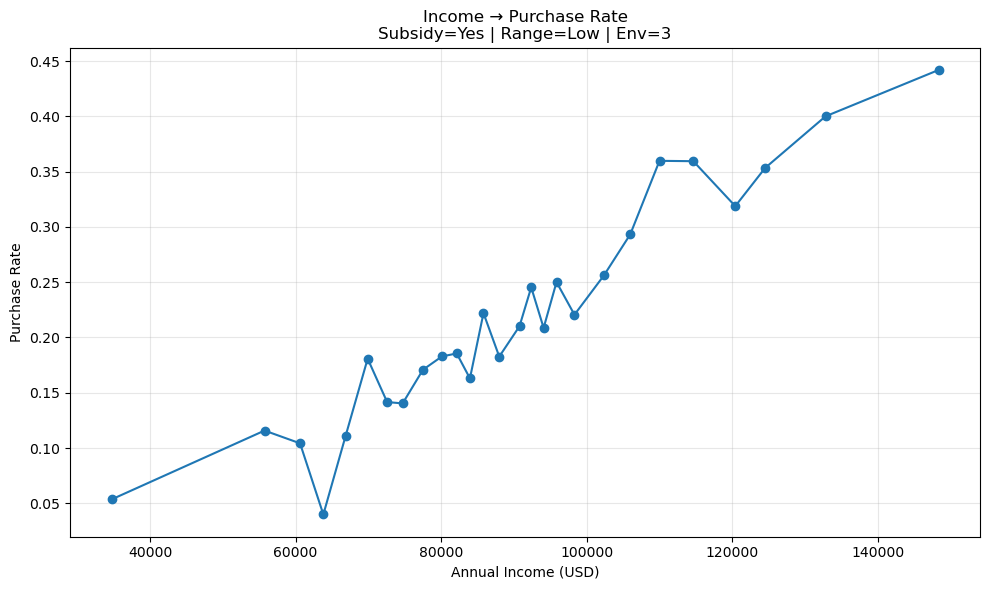

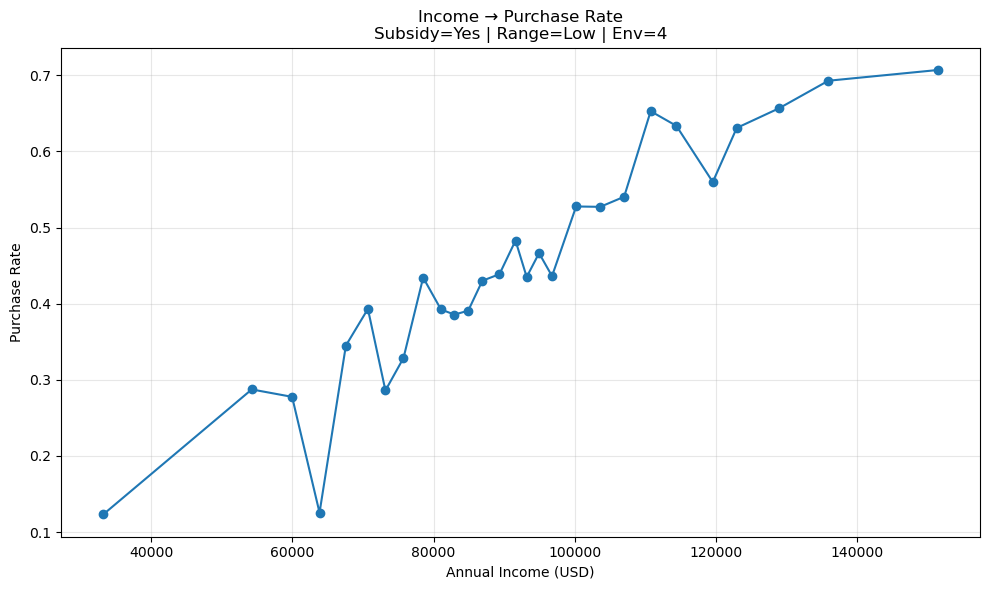

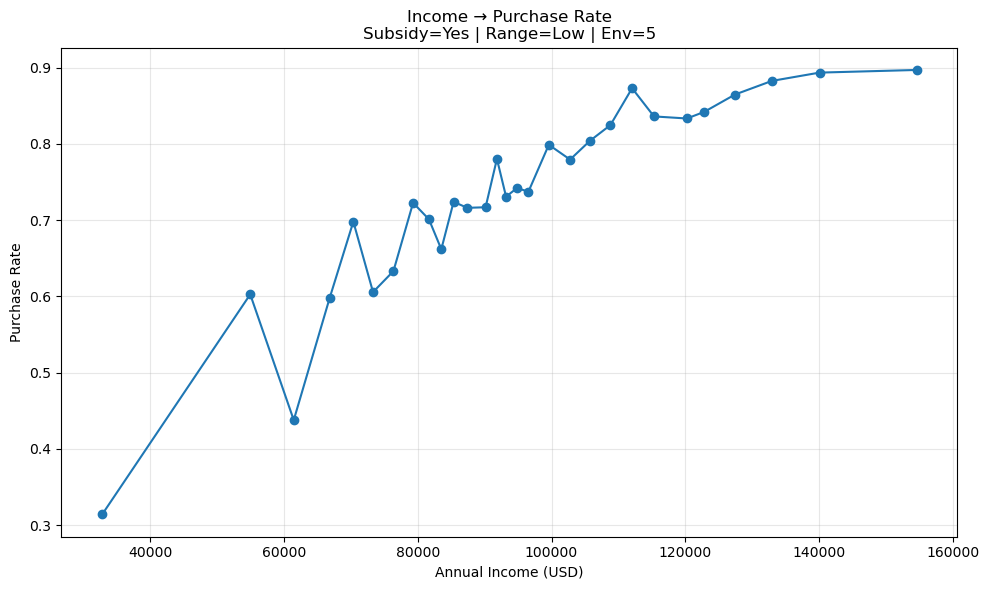

In [48]:
# ============================================================
# STEP 1 — FINE-GRAINED INCOME → PURCHASE-RATE CURVES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create target
# ------------------------------------------------------------
df = train.copy()
df["target"] = (df["Will_Buy_EV"] == "Yes").astype(int)

# ------------------------------------------------------------
# 2. Structural groups to investigate
# ------------------------------------------------------------
groups = [
    ("Yes", "Low", 3),
    ("Yes", "Low", 4),
    ("Yes", "Low", 5),
]

# ------------------------------------------------------------
# 3. Number of income bins
# ------------------------------------------------------------
N_BINS = 30

curves = {}

# ------------------------------------------------------------
# 4. Calculate purchase rate in fine income bins
# ------------------------------------------------------------
for subsidy, range_anxiety, env in groups:

    mask = (
        (df["Subsidy_Available"] == subsidy) &
        (df["Range_Anxiety_Level"] == range_anxiety) &
        (df["Environmental_Concern_Level"] == env)
    )

    g = df.loc[
        mask,
        ["Annual_Income_USD", "target"]
    ].copy()

    # Quantile bins -> roughly equal number of rows per bin
    g["income_bin"] = pd.qcut(
        g["Annual_Income_USD"],
        q=N_BINS,
        duplicates="drop"
    )

    curve = (
        g.groupby("income_bin", observed=True)
         .agg(
             income_mean=("Annual_Income_USD", "mean"),
             purchase_rate=("target", "mean"),
             count=("target", "size")
         )
         .reset_index()
    )

    key = f"Subsidy={subsidy} | Range={range_anxiety} | Env={env}"
    curves[key] = curve

    print("\n" + "=" * 70)
    print(key)
    print("=" * 70)
    print(f"Rows: {len(g):,}")
    print(f"Overall purchase rate: {g['target'].mean():.4%}")
    print()
    print(
        curve[
            ["income_mean", "purchase_rate", "count"]
        ].to_string(index=False)
    )

# ------------------------------------------------------------
# 5. Plot each curve separately
# ------------------------------------------------------------
for key, curve in curves.items():

    plt.figure(figsize=(10, 6))

    plt.plot(
        curve["income_mean"],
        curve["purchase_rate"],
        marker="o"
    )

    plt.xlabel("Annual Income (USD)")
    plt.ylabel("Purchase Rate")
    plt.title(f"Income → Purchase Rate\n{key}")
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [49]:
# ============================================================
# STEP 4 — CHAMPION RESIDUAL SUBGROUP SCAN
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

df = train.copy()
df["target"] = (df["Will_Buy_EV"] == "Yes").astype(int)

# Champion OOF prediction
df["champion"] = champion_oof

# Residual
df["residual"] = df["target"] - df["champion"]

# ------------------------------------------------------------
# Candidate categorical interactions
# ------------------------------------------------------------
groups = [
    ["City_Type"],
    ["Current_Car_Type"],
    ["Home_Charging_Possible"],
    ["Gender"],

    ["City_Type", "Current_Car_Type"],
    ["City_Type", "Home_Charging_Possible"],
    ["Current_Car_Type", "Home_Charging_Possible"],
    ["Gender", "Home_Charging_Possible"],

    ["City_Type", "Current_Car_Type", "Home_Charging_Possible"],
]

# ------------------------------------------------------------
# Scan residual behavior
# ------------------------------------------------------------
for cols in groups:

    print("\n" + "=" * 80)
    print(" × ".join(cols))
    print("=" * 80)

    stats = (
        df.groupby(cols, observed=True)
          .agg(
              count=("target", "size"),
              actual_rate=("target", "mean"),
              predicted_rate=("champion", "mean"),
              mean_residual=("residual", "mean")
          )
          .reset_index()
    )

    # Only show reasonably sized groups
    stats = stats[stats["count"] >= 500].copy()

    # Largest absolute residual first
    stats["abs_residual"] = stats["mean_residual"].abs()

    stats = stats.sort_values(
        "abs_residual",
        ascending=False
    )

    print(
        stats[
            cols +
            [
                "count",
                "actual_rate",
                "predicted_rate",
                "mean_residual"
            ]
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}"
        )
    )


City_Type
City_Type  count  actual_rate  predicted_rate  mean_residual
    Urban 289305     0.161058        0.160874       0.000185
 Suburban 255377     0.180936        0.181000      -0.000063
    Rural 123983     0.193389        0.193441      -0.000052

Current_Car_Type
Current_Car_Type  count  actual_rate  predicted_rate  mean_residual
           Truck  39223     0.156413        0.156780      -0.000367
       Hatchback  79438     0.174299        0.174501      -0.000202
           Sedan 303459     0.171967        0.171854       0.000114
             SUV 246545     0.180953        0.180844       0.000109

Home_Charging_Possible
Home_Charging_Possible  count  actual_rate  predicted_rate  mean_residual
                   Yes 462677     0.195819        0.195712       0.000107
                    No 205988     0.127085        0.127175      -0.000090

Gender
Gender  count  actual_rate  predicted_rate  mean_residual
 Other   5284     0.173732        0.171651       0.002081
Female 295427    

In [50]:
# ============================================================
# STEP 6 — HIDDEN GENERATOR LOGISTIC MODEL
# ============================================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------
df = train.copy()

y_local = (df["Will_Buy_EV"] == "Yes").astype(int).values

# ------------------------------------------------------------
# Base structural features
# ------------------------------------------------------------
X = pd.DataFrame({
    "Subsidy": (df["Subsidy_Available"] == "Yes").astype(int),
    "Range_Low": (df["Range_Anxiety_Level"] == "Low").astype(int),
    "Range_Medium": (df["Range_Anxiety_Level"] == "Medium").astype(int),
    "Environmental": df["Environmental_Concern_Level"].astype(float),
    "Income": np.log(df["Annual_Income_USD"].astype(float))
})

# ------------------------------------------------------------
# Explicit structural interactions
# ------------------------------------------------------------
X["Subsidy_Env"] = X["Subsidy"] * X["Environmental"]

X["RangeLow_Env"] = X["Range_Low"] * X["Environmental"]

X["RangeMedium_Env"] = X["Range_Medium"] * X["Environmental"]

X["Subsidy_RangeLow"] = X["Subsidy"] * X["Range_Low"]

X["Subsidy_RangeMedium"] = X["Subsidy"] * X["Range_Medium"]

# ------------------------------------------------------------
# Income interactions
# ------------------------------------------------------------
X["Income_Env"] = X["Income"] * X["Environmental"]

X["Income_Subsidy"] = X["Income"] * X["Subsidy"]

X["Income_RangeLow"] = X["Income"] * X["Range_Low"]

X["Income_RangeMedium"] = X["Income"] * X["Range_Medium"]

# ------------------------------------------------------------
# Polynomial terms for income
# ------------------------------------------------------------
X["Income2"] = X["Income"] ** 2
X["Income3"] = X["Income"] ** 3

# ------------------------------------------------------------
# Standardize continuous columns
# ------------------------------------------------------------
from sklearn.preprocessing import StandardScaler

scale_cols = [
    "Income",
    "Environmental",
    "Income2",
    "Income3",
    "Income_Env",
    "Income_Subsidy",
    "Income_RangeLow",
    "Income_RangeMedium"
]

X[scale_cols] = StandardScaler().fit_transform(X[scale_cols])

# ------------------------------------------------------------
# 5-fold evaluation
# ------------------------------------------------------------
oof_hidden = np.zeros(len(df))

fold_aucs = []

for k, (tr, va) in enumerate(folds, 1):

    model = LogisticRegression(
        C=1.0,
        max_iter=2000,
        solver="lbfgs"
    )

    model.fit(X.iloc[tr], y_local[tr])

    val_pred = model.predict_proba(X.iloc[va])[:, 1]

    oof_hidden[va] = val_pred

    auc = roc_auc_score(y_local[va], val_pred)
    fold_aucs.append(auc)

    print(f"Fold {k}: {auc:.6f}")

# ------------------------------------------------------------
# Final evaluation
# ------------------------------------------------------------
hidden_auc = roc_auc_score(y_local, oof_hidden)
champ_auc = roc_auc_score(y_local, champion_oof)

print("\n" + "=" * 70)
print(f"Hidden-generator model : {hidden_auc:.6f}")
print(f"Champion               : {champ_auc:.6f}")
print(f"Difference              : {hidden_auc - champ_auc:+.6f}")
print("=" * 70)

print("\nPrediction correlation with champion:")

print(
    np.corrcoef(
        champion_oof,
        oof_hidden
    )[0, 1]
)

Fold 1: 0.936548
Fold 2: 0.937920
Fold 3: 0.938978
Fold 4: 0.938613
Fold 5: 0.937992

Hidden-generator model : 0.938004
Champion               : 0.942003
Difference              : -0.003998

Prediction correlation with champion:
0.9843554357986685


In [54]:
print("train:", train.shape)
print("X_train:", X_train.shape)
print("y:", len(y))
print("folds:", len(folds))

print("\nFold 1 max indices:")
tr0, va0 = folds[0]
print("train max:", tr0.max())
print("val max  :", va0.max())

train: (668665, 15)
X_train: (668665, 24)
y: 668665
folds: 5

Fold 1 max indices:
train max: 668664
val max  : 668660


In [53]:
# ============================================================
# RESTORE ORIGINAL XGBOOST FEATURE MATRIX
# ============================================================

xgb_features = [
    "Age",
    "Annual_Income_USD",
    "Daily_Commute_km",
    "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work",
    "Environmental_Concern_Level",
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

X_base = train[xgb_features].copy()

# One-hot encode categoricals
X_train = pd.get_dummies(
    X_base,
    columns=[
        "Gender",
        "City_Type",
        "Current_Car_Type",
        "Home_Charging_Possible",
        "Subsidy_Available",
        "Range_Anxiety_Level"
    ],
    dtype=np.float32
)

X_train = X_train.astype(np.float32)

print("X_train shape:", X_train.shape)
print("y length     :", len(y))

X_train shape: (668665, 24)
y length     : 668665


In [55]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(skf.split(X_train, y))

print("Folds:", len(folds))
print("X rows:", len(X_train))

for i, (tr, va) in enumerate(folds, 1):
    print(
        f"Fold {i}: "
        f"train={len(tr)}, "
        f"val={len(va)}, "
        f"max={max(tr.max(), va.max())}"
    )

Folds: 5
X rows: 668665
Fold 1: train=534932, val=133733, max=668664
Fold 2: train=534932, val=133733, max=668664
Fold 3: train=534932, val=133733, max=668664
Fold 4: train=534932, val=133733, max=668664
Fold 5: train=534932, val=133733, max=668664


In [56]:
xgb_params_v2 = {
    "n_estimators": 2500,
    "learning_rate": 0.03,
    "max_depth": 4,
    "min_child_weight": 3,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.0,
    "reg_lambda": 1.0,
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "tree_method": "hist",
    "device": "cpu",
    "random_state": 42,
    "n_jobs": -1,
    "early_stopping_rounds": 100
}

oof_xgb_v2 = np.zeros(len(train))

for fold, (tr, va) in enumerate(folds, 1):

    model = XGBClassifier(**xgb_params_v2)

    model.fit(
        X_train.iloc[tr],
        y[tr],
        eval_set=[(X_train.iloc[va], y[va])],
        verbose=False
    )

    oof_xgb_v2[va] = model.predict_proba(
        X_train.iloc[va]
    )[:, 1]

    auc = roc_auc_score(y[va], oof_xgb_v2[va])
    print(f"Fold {fold}: {auc:.6f}")

xgb_v2_auc = roc_auc_score(y, oof_xgb_v2)

print("\n" + "=" * 70)
print(f"Original XGB : {roc_auc_score(y, oof_xgb):.6f}")
print(f"New XGB      : {xgb_v2_auc:.6f}")
print(f"Champion     : {roc_auc_score(y, champion_oof):.6f}")
print("=" * 70)

print("\nCorrelations:")
print(
    "New XGB vs Original XGB :",
    np.corrcoef(oof_xgb_v2, oof_xgb)[0, 1]
)

print(
    "New XGB vs Champion     :",
    np.corrcoef(oof_xgb_v2, champion_oof)[0, 1]
)

# Most important: blend with champion
for w in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    blend = (1 - w) * champion_oof + w * oof_xgb_v2
    auc = roc_auc_score(y, blend)
    print(f"Champion {1-w:.0%} + New XGB {w:.0%}: {auc:.6f}")

Fold 1: 0.940761
Fold 2: 0.941791
Fold 3: 0.943062
Fold 4: 0.942604
Fold 5: 0.941956

Original XGB : 0.941876
New XGB      : 0.942026
Champion     : 0.942003

Correlations:
New XGB vs Original XGB : 0.9994723331627574
New XGB vs Champion     : 0.9991054257278361
Champion 95% + New XGB 5%: 0.942015
Champion 90% + New XGB 10%: 0.942027
Champion 85% + New XGB 15%: 0.942037
Champion 80% + New XGB 20%: 0.942046
Champion 75% + New XGB 25%: 0.942053
Champion 70% + New XGB 30%: 0.942060


In [58]:
# ============================================================
# SAVE NEW XGBOOST DEPTH-4 EXPERIMENT
# ============================================================

from pathlib import Path
import numpy as np
import json

ARTIFACT_DIR = Path(
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"
)

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Save OOF predictions
# ------------------------------------------------------------

oof_path = ARTIFACT_DIR / "oof_xgb_depth4.npy"

np.save(oof_path, oof_xgb_v2)


# ------------------------------------------------------------
# 2. Save model configuration
# ------------------------------------------------------------

metadata = {
    "model": "XGBoost",
    "experiment": "depth4_minchild3",
    "features": list(X_train.columns),
    "n_features": int(X_train.shape[1]),
    "n_rows": int(X_train.shape[0]),

    "params": {
        "n_estimators": 2500,
        "learning_rate": 0.03,
        "max_depth": 4,
        "min_child_weight": 3,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_alpha": 0.0,
        "reg_lambda": 1.0,
        "objective": "binary:logistic",
        "eval_metric": "auc",
        "tree_method": "hist",
        "device": "cpu",
        "random_state": 42,
        "n_jobs": -1,
        "early_stopping_rounds": 100
    },

    "cv": {
        "n_splits": 5,
        "shuffle": True,
        "random_state": 42
    },

    "fold_auc": [
        0.940761,
        0.941791,
        0.943062,
        0.942604,
        0.941956
    ],

    "oof_auc": 0.942026,
    "original_xgb_auc": 0.941876,
    "original_champion_auc": 0.942003,

    "blend_results": {
        "champion_95_new5": 0.942015,
        "champion_90_new10": 0.942027,
        "champion_85_new15": 0.942037,
        "champion_80_new20": 0.942046,
        "champion_75_new25": 0.942053,
        "champion_70_new30": 0.942060
    }
}

metadata_path = ARTIFACT_DIR / "xgb_depth4_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)


# ------------------------------------------------------------
# 3. Verify
# ------------------------------------------------------------

print("=" * 70)
print("SAVED XGBOOST DEPTH-4 ARTIFACTS")
print("=" * 70)

print(f"OOF predictions : {oof_path}")
print(f"Metadata        : {metadata_path}")

print("\nOOF shape:", oof_xgb_v2.shape)
print("OOF AUC  :", roc_auc_score(y, oof_xgb_v2))

print("\nFiles exist:")
print("OOF      :", oof_path.exists())
print("Metadata :", metadata_path.exists())

SAVED XGBOOST DEPTH-4 ARTIFACTS
OOF predictions : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\oof_xgb_depth4.npy
Metadata        : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\xgb_depth4_metadata.json

OOF shape: (668665,)
OOF AUC  : 0.9420259023203956

Files exist:
OOF      : True
Metadata : True


In [57]:
# ============================================================
# 3-MODEL BLEND — TARGETED WEIGHT SEARCH
# LGB + ORIGINAL XGB + NEW DEPTH-4 XGB
# ============================================================

best_auc = -1
best_weights = None

# Keep LGB and original XGB roughly balanced,
# while varying the contribution of the new XGB.

for new_w in np.arange(0.10, 0.51, 0.02):

    remaining = 1.0 - new_w

    for lgb_share in np.arange(0.40, 0.61, 0.02):

        lgb_w = remaining * lgb_share
        xgb_w = remaining - lgb_w

        blend = (
            lgb_w * oof_lgb
            + xgb_w * oof_xgb
            + new_w * oof_xgb_v2
        )

        auc = roc_auc_score(y, blend)

        if auc > best_auc:
            best_auc = auc
            best_weights = (lgb_w, xgb_w, new_w)

print("=" * 70)
print("BEST 3-MODEL BLEND")
print("=" * 70)

print(f"LGB        : {best_weights[0]:.3f}")
print(f"Original XGB: {best_weights[1]:.3f}")
print(f"New XGB     : {best_weights[2]:.3f}")
print(f"Total       : {sum(best_weights):.3f}")
print(f"OOF AUC     : {best_auc:.6f}")

print("\nCurrent champion:")
print(f"0.500 LGB + 0.500 XGB = {roc_auc_score(y, champion_oof):.6f}")

BEST 3-MODEL BLEND
LGB        : 0.300
Original XGB: 0.200
New XGB     : 0.500
Total       : 1.000
OOF AUC     : 0.942082

Current champion:
0.500 LGB + 0.500 XGB = 0.942003


In [59]:
# ============================================================
# SAVE 3-MODEL BLEND EXPERIMENT
# ============================================================

from pathlib import Path
import json
import numpy as np

ARTIFACT_DIR = Path(
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"
)

blend_weights = {
    "lightgbm": 0.30,
    "xgboost_original": 0.20,
    "xgboost_depth4": 0.50
}

blend_oof = (
    blend_weights["lightgbm"] * oof_lgb
    + blend_weights["xgboost_original"] * oof_xgb
    + blend_weights["xgboost_depth4"] * oof_xgb_v2
)

blend_auc = roc_auc_score(y, blend_oof)

# Save OOF blend
blend_oof_path = ARTIFACT_DIR / "oof_blend_lgb30_xgb20_depth4_50.npy"
np.save(blend_oof_path, blend_oof)

# Save metadata
blend_metadata = {
    "experiment": "3_model_blend",
    "weights": blend_weights,

    "components": {
        "lightgbm_oof_auc": float(roc_auc_score(y, oof_lgb)),
        "xgboost_original_oof_auc": float(roc_auc_score(y, oof_xgb)),
        "xgboost_depth4_oof_auc": float(
            roc_auc_score(y, oof_xgb_v2)
        )
    },

    "blend_oof_auc": float(blend_auc),

    "previous_champion": {
        "weights": {
            "lightgbm": 0.50,
            "xgboost_original": 0.50
        },
        "oof_auc": float(
            roc_auc_score(y, champion_oof)
        )
    },

    "improvement_vs_champion": float(
        blend_auc - roc_auc_score(y, champion_oof)
    ),

    "note": (
        "Blend weights selected using the same OOF predictions "
        "used for evaluation; therefore blend AUC may be "
        "optimistically biased."
    )
}

metadata_path = (
    ARTIFACT_DIR /
    "blend_lgb30_xgb20_depth4_50_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(blend_metadata, f, indent=2)

print("=" * 70)
print("3-MODEL BLEND SAVED")
print("=" * 70)

print(f"OOF file : {blend_oof_path}")
print(f"Metadata : {metadata_path}")

print(f"\nBlend OOF AUC: {blend_auc:.6f}")
print(
    f"Improvement  : "
    f"{blend_auc - roc_auc_score(y, champion_oof):+.6f}"
)

print("\nFiles:")
print("OOF      :", blend_oof_path.exists())
print("Metadata :", metadata_path.exists())

3-MODEL BLEND SAVED
OOF file : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\oof_blend_lgb30_xgb20_depth4_50.npy
Metadata : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\blend_lgb30_xgb20_depth4_50_metadata.json

Blend OOF AUC: 0.942082
Improvement  : +0.000079

Files:
OOF      : True
Metadata : True


In [60]:
# ============================================================
# FIXED 30/20/50 BLEND — FOLD-BY-FOLD VALIDATION
# ============================================================

blend_weights = {
    "lgb": 0.30,
    "xgb_original": 0.20,
    "xgb_depth4": 0.50
}

fold_results = []

for fold, (tr, va) in enumerate(folds, 1):

    fold_lgb = oof_lgb[va]
    fold_xgb = oof_xgb[va]
    fold_xgb_v2 = oof_xgb_v2[va]
    fold_y = y[va]

    fold_blend = (
        blend_weights["lgb"] * fold_lgb
        + blend_weights["xgb_original"] * fold_xgb
        + blend_weights["xgb_depth4"] * fold_xgb_v2
    )

    auc = roc_auc_score(fold_y, fold_blend)

    fold_results.append(auc)

    print(f"Fold {fold}: {auc:.6f}")

print("\n" + "=" * 70)
print("FIXED 30/20/50 BLEND")
print("=" * 70)

print(f"Mean fold AUC : {np.mean(fold_results):.6f}")
print(f"Std           : {np.std(fold_results):.6f}")
print(f"OOF AUC       : {roc_auc_score(y, blend_oof):.6f}")

print("\nPrevious champion fold AUCs:")

champ_fold_results = []

for fold, (tr, va) in enumerate(folds, 1):

    auc = roc_auc_score(
        y[va],
        champion_oof[va]
    )

    champ_fold_results.append(auc)

    print(f"Fold {fold}: {auc:.6f}")

print("\n" + "=" * 70)
print("COMPARISON")
print("=" * 70)

print(
    f"Fixed blend mean : {np.mean(fold_results):.6f}"
)

print(
    f"Champion mean    : {np.mean(champ_fold_results):.6f}"
)

print(
    f"Difference       : "
    f"{np.mean(fold_results) - np.mean(champ_fold_results):+.6f}"
)

Fold 1: 0.940832
Fold 2: 0.941875
Fold 3: 0.943111
Fold 4: 0.942639
Fold 5: 0.942002

FIXED 30/20/50 BLEND
Mean fold AUC : 0.942092
Std           : 0.000772
OOF AUC       : 0.942082

Previous champion fold AUCs:
Fold 1: 0.940776
Fold 2: 0.941806
Fold 3: 0.943021
Fold 4: 0.942541
Fold 5: 0.941929

COMPARISON
Fixed blend mean : 0.942092
Champion mean    : 0.942015
Difference       : +0.000077


In [62]:
# ============================================================
# REBUILD X_TEST — MATCH X_TRAIN EXACTLY
# ============================================================

X_test_base = test[xgb_features].copy()

X_test = pd.get_dummies(
    X_test_base,
    columns=[
        "Gender",
        "City_Type",
        "Current_Car_Type",
        "Home_Charging_Possible",
        "Subsidy_Available",
        "Range_Anxiety_Level"
    ],
    dtype=np.float32
)

# CRITICAL: make test columns identical to training columns
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
).astype(np.float32)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("Columns match:", list(X_train.columns) == list(X_test.columns))

X_train shape: (668665, 24)
X_test shape : (286571, 24)
Columns match: True


In [63]:
# ============================================================
# FINAL CANDIDATE — TRAIN DEPTH-4 XGBOOST ON FULL DATA
# ============================================================

from xgboost import XGBClassifier

xgb_depth4_final = XGBClassifier(
    n_estimators=2500,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    device="cpu",
    random_state=42,
    n_jobs=-1
)

print("Training final depth-4 XGBoost on full training data...")

xgb_depth4_final.fit(
    X_train,
    y,
    verbose=False
)

test_xgb_depth4 = xgb_depth4_final.predict_proba(
    X_test
)[:, 1]

print("\nTraining complete.")
print("Test predictions:", test_xgb_depth4.shape)
print("Min:", test_xgb_depth4.min())
print("Max:", test_xgb_depth4.max())
print("Mean:", test_xgb_depth4.mean())
print("NaN:", np.isnan(test_xgb_depth4).sum())
print("Inf:", np.isinf(test_xgb_depth4).sum())

Training final depth-4 XGBoost on full training data...

Training complete.
Test predictions: (286571,)
Min: 1.8711432e-06
Max: 0.9791516
Mean: 0.1746397
NaN: 0
Inf: 0


In [64]:
# ============================================================
# SAVE FINAL DEPTH-4 XGB TEST PREDICTIONS
# ============================================================

test_pred_path = ARTIFACT_DIR / "test_xgb_depth4.npy"

np.save(test_pred_path, test_xgb_depth4)

print("Saved:", test_pred_path)
print("Exists:", test_pred_path.exists())
print("Shape :", test_xgb_depth4.shape)

Saved: C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\test_xgb_depth4.npy
Exists: True
Shape : (286571,)


In [65]:
# ============================================================
# GENERATE FINAL DEPTH-4 XGB TEST PREDICTIONS
# ============================================================

test_xgb_depth4 = xgb_depth4_final.predict_proba(
    X_test
)[:, 1]

print("Test predictions:", test_xgb_depth4.shape)
print("Min:", test_xgb_depth4.min())
print("Max:", test_xgb_depth4.max())
print("Mean:", test_xgb_depth4.mean())
print("NaN:", np.isnan(test_xgb_depth4).sum())
print("Inf:", np.isinf(test_xgb_depth4).sum())

Test predictions: (286571,)
Min: 1.8711432e-06
Max: 0.9791516
Mean: 0.1746397
NaN: 0
Inf: 0


In [66]:
# ============================================================
# VERIFY FINAL ENSEMBLE PREDICTIONS
# ============================================================

print("=" * 70)
print("FINAL PREDICTION SANITY CHECK")
print("=" * 70)

predictions = {
    "LightGBM": test_lgb,
    "Original XGB": test_xgb,
    "Depth-4 XGB": test_xgb_depth4
}

for name, pred in predictions.items():

    print(f"\n{name}")
    print("-" * 30)
    print("Shape :", pred.shape)
    print("Min   :", pred.min())
    print("Max   :", pred.max())
    print("Mean  :", pred.mean())
    print("NaN   :", np.isnan(pred).sum())
    print("Inf   :", np.isinf(pred).sum())

# Check alignment
expected_len = len(test)

assert len(test_lgb) == expected_len
assert len(test_xgb) == expected_len
assert len(test_xgb_depth4) == expected_len

assert not np.isnan(test_lgb).any()
assert not np.isnan(test_xgb).any()
assert not np.isnan(test_xgb_depth4).any()

assert not np.isinf(test_lgb).any()
assert not np.isinf(test_xgb).any()
assert not np.isinf(test_xgb_depth4).any()

print("\n" + "=" * 70)
print("ALL CHECKS PASSED")
print("=" * 70)

FINAL PREDICTION SANITY CHECK

LightGBM
------------------------------
Shape : (286571,)
Min   : 1.5735759670407232e-05
Max   : 0.9685599759042715
Mean  : 0.1746247511091655
NaN   : 0
Inf   : 0

Original XGB
------------------------------
Shape : (286571,)
Min   : 1.7644767e-05
Max   : 0.9744015
Mean  : 0.17467262
NaN   : 0
Inf   : 0

Depth-4 XGB
------------------------------
Shape : (286571,)
Min   : 1.8711432e-06
Max   : 0.9791516
Mean  : 0.1746397
NaN   : 0
Inf   : 0

ALL CHECKS PASSED


In [67]:
# ============================================================
# FINAL ENSEMBLE — 30/20/50
# ============================================================

final_test_blend = (
    0.30 * test_lgb
    + 0.20 * test_xgb
    + 0.50 * test_xgb_depth4
)

print("=" * 70)
print("FINAL ENSEMBLE PREDICTIONS")
print("=" * 70)

print("Shape :", final_test_blend.shape)
print("Min   :", final_test_blend.min())
print("Max   :", final_test_blend.max())
print("Mean  :", final_test_blend.mean())
print("NaN   :", np.isnan(final_test_blend).sum())
print("Inf   :", np.isinf(final_test_blend).sum())

assert len(final_test_blend) == len(test)
assert not np.isnan(final_test_blend).any()
assert not np.isinf(final_test_blend).any()

FINAL ENSEMBLE PREDICTIONS
Shape : (286571,)
Min   : 1.142155371400272e-05
Max   : 0.9719709029854273
Mean  : 0.1746418149529739
NaN   : 0
Inf   : 0


In [68]:
# ============================================================
# FINAL SUBMISSION CSV
# ============================================================

submission_final = pd.DataFrame({
    "id": test["id"],
    "prediction": final_test_blend
})

final_submission_path = (
    ARTIFACT_DIR /
    "submission_final_lgb30_xgb20_depth4_50.csv"
)

submission_final.to_csv(
    final_submission_path,
    index=False
)

print("=" * 70)
print("FINAL SUBMISSION CREATED")
print("=" * 70)

print("Path:", final_submission_path)
print("Shape:", submission_final.shape)

print("\nFirst 5 rows:")
print(submission_final.head())

print("\nLast 5 rows:")
print(submission_final.tail())

print("\nFile exists:", final_submission_path.exists())

FINAL SUBMISSION CREATED
Path: C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submission_final_lgb30_xgb20_depth4_50.csv
Shape: (286571, 2)

First 5 rows:
       id  prediction
0  668665    0.009407
1  668666    0.015801
2  668667    0.004974
3  668668    0.003221
4  668669    0.020034

Last 5 rows:
            id  prediction
286566  955231    0.000168
286567  955232    0.256474
286568  955233    0.002354
286569  955234    0.000359
286570  955235    0.000105

File exists: True


**third submission completed**  public score => ( **0.94185** ) , rank => ( **1847** )

In [69]:
# ============================================================
# FINAL BLEND WEIGHT LOCALITY CHECK
# ============================================================

results = []

for depth4_w in np.arange(0.30, 0.61, 0.02):

    remaining = 1.0 - depth4_w

    for lgb_w in np.arange(0.20, 0.61, 0.02):

        xgb_w = remaining - lgb_w

        if xgb_w < 0:
            continue

        blend = (
            lgb_w * oof_lgb
            + xgb_w * oof_xgb
            + depth4_w * oof_xgb_v2
        )

        auc = roc_auc_score(y, blend)

        results.append({
            "lgb": lgb_w,
            "xgb": xgb_w,
            "depth4": depth4_w,
            "auc": auc
        })

blend_results = pd.DataFrame(results).sort_values(
    "auc",
    ascending=False
).reset_index(drop=True)

print(blend_results.head(15).to_string(index=False))

 lgb  xgb  depth4      auc
0.38 0.02    0.60 0.942096
0.36 0.04    0.60 0.942096
0.40 0.02    0.58 0.942095
0.38 0.04    0.58 0.942095
0.34 0.06    0.60 0.942095
0.36 0.06    0.58 0.942094
0.40 0.04    0.56 0.942094
0.38 0.06    0.56 0.942093
0.42 0.02    0.56 0.942093
0.32 0.08    0.60 0.942093
0.34 0.08    0.58 0.942093
0.36 0.08    0.56 0.942093
0.40 0.06    0.54 0.942092
0.42 0.04    0.54 0.942092
0.38 0.08    0.54 0.942092


In [70]:
# ============================================================
# SUBMISSION 4 — ROBUST BLEND FROM LOCALITY PLATEAU
# LGB 36% + XGB 4% + XGB Depth-4 60%
# ============================================================

final_blend_36460 = (
    0.36 * test_lgb
    + 0.04 * test_xgb
    + 0.60 * test_xgb_depth4
)

submission_4 = pd.DataFrame({
    "id": test["id"],
    "Will_Buy_EV": final_blend_36460
})

submission_4_path = (
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE"
    r"\ev_kaggle_artifacts\submission_4_lgb36_xgb4_depth4_60.csv"
)

submission_4.to_csv(submission_4_path, index=False)

print("Saved:", submission_4_path)
print("Shape:", submission_4.shape)
print(submission_4.head())
print("\nPrediction statistics:")
print(submission_4["Will_Buy_EV"].describe())
print("\nNaN:", submission_4["Will_Buy_EV"].isna().sum())
print("Inf:", np.isinf(submission_4["Will_Buy_EV"]).sum())

Saved: C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submission_4_lgb36_xgb4_depth4_60.csv
Shape: (286571, 2)
       id  Will_Buy_EV
0  668665     0.009355
1  668666     0.015535
2  668667     0.005070
3  668668     0.003196
4  668669     0.020125

Prediction statistics:
count    286571.000000
mean          0.174636
std           0.269829
min           0.000010
25%           0.002520
50%           0.017967
75%           0.267352
max           0.972068
Name: Will_Buy_EV, dtype: float64

NaN: 0
Inf: 0


**fourth submission completed** -> score => ( **0.94189** ) rank => ( **1818** )

In [73]:
# ============================================================
# CATEGORICAL RESIDUAL SIGNAL — FIXED
# ============================================================

categorical_features = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

# Temporary aligned target
target_series = pd.Series(y, index=train.index, name="target")

cat_results = []

for col in categorical_features:

    # Diagnostic target mean encoding only.
    means = target_series.groupby(train[col]).mean()

    encoded = train[col].map(means).values

    corr = np.corrcoef(encoded, residual)[0, 1]
    auc = roc_auc_score(y, encoded)

    cat_results.append({
        "feature": col,
        "encoded_auc": auc,
        "abs_auc_signal": max(auc, 1 - auc),
        "residual_corr": corr,
        "abs_residual_corr": abs(corr)
    })

cat_results = (
    pd.DataFrame(cat_results)
    .sort_values("abs_residual_corr", ascending=False)
    .reset_index(drop=True)
)

print("\n=== CATEGORICAL RESIDUAL SIGNAL ===")
print(cat_results.to_string(index=False))


=== CATEGORICAL RESIDUAL SIGNAL ===
               feature  encoded_auc  abs_auc_signal  residual_corr  abs_residual_corr
                Gender     0.504614        0.504614       0.000371           0.000371
             City_Type     0.523450        0.523450      -0.000334           0.000334
   Range_Anxiety_Level     0.545104        0.545104       0.000255           0.000255
Home_Charging_Possible     0.550822        0.550822       0.000221           0.000221
      Current_Car_Type     0.510372        0.510372       0.000163           0.000163
     Subsidy_Available     0.717940        0.717940       0.000163           0.000163


In [75]:
# ============================================================
# NUMERIC RESIDUAL SIGNAL SCAN
# ============================================================

numeric_features = [
    "Age",
    "Annual_Income_USD",
    "Daily_Commute_km",
    "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work",
    "Environmental_Concern_Level"
]

results = []

for col in numeric_features:

    x = train[col].astype(float).values

    # Raw feature AUC
    raw_auc = roc_auc_score(y, x)

    # Correlation with current champion residual
    residual_corr = np.corrcoef(x, residual)[0, 1]

    results.append({
        "feature": col,
        "raw_auc": raw_auc,
        "abs_auc_signal": max(raw_auc, 1 - raw_auc),
        "residual_corr": residual_corr,
        "abs_residual_corr": abs(residual_corr)
    })

numeric_results = (
    pd.DataFrame(results)
    .sort_values(
        "abs_residual_corr",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n=== NUMERIC RESIDUAL SIGNAL ===")
print(numeric_results.to_string(index=False))


=== NUMERIC RESIDUAL SIGNAL ===
                    feature  raw_auc  abs_auc_signal  residual_corr  abs_residual_corr
       Number_of_Cars_Owned 0.503935        0.503935       0.000456           0.000456
Environmental_Concern_Level 0.843521        0.843521       0.000314           0.000314
          Annual_Income_USD 0.670367        0.670367       0.000258           0.000258
Charging_Stations_Near_Home 0.484114        0.515886       0.000132           0.000132
           Daily_Commute_km 0.466243        0.533757       0.000116           0.000116
Charging_Stations_Near_Work 0.489380        0.510620       0.000057           0.000057
                        Age 0.494465        0.505535      -0.000038           0.000038


In [76]:
# ============================================================
# EXPERIMENT — CONDITIONAL CARS-OWNED SIGNAL
# ============================================================

group_cols = [
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Environmental_Concern_Level"
]

analysis = train[group_cols + [
    "Number_of_Cars_Owned"
]].copy()

analysis["target"] = y

# ------------------------------------------------------------
# 1. Group statistics
# ------------------------------------------------------------

group_stats = (
    analysis
    .groupby(group_cols)
    .agg(
        rows=("target", "size"),
        target_rate=("target", "mean"),
        cars_mean=("Number_of_Cars_Owned", "mean"),
        cars_std=("Number_of_Cars_Owned", "std"),
        cars_min=("Number_of_Cars_Owned", "min"),
        cars_max=("Number_of_Cars_Owned", "max")
    )
    .reset_index()
)

group_stats["target_rate_pct"] = (
    group_stats["target_rate"] * 100
)

print("\n=== STRUCTURAL GROUPS ===")
print(
    group_stats
    .sort_values("rows", ascending=False)
    .head(30)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 2. Cars-owned target rates inside groups
# ------------------------------------------------------------

cars_groups = (
    analysis
    .groupby(
        group_cols + ["Number_of_Cars_Owned"]
    )
    .agg(
        rows=("target", "size"),
        target_rate=("target", "mean")
    )
    .reset_index()
)

cars_groups["target_rate_pct"] = (
    cars_groups["target_rate"] * 100
)

# Only reasonably populated groups
cars_groups_filtered = cars_groups[
    cars_groups["rows"] >= 200
].copy()

print("\n=== CARS OWNED CONDITIONAL TARGET RATES ===")

print(
    cars_groups_filtered
    .sort_values(
        ["Subsidy_Available",
         "Range_Anxiety_Level",
         "Environmental_Concern_Level",
         "Number_of_Cars_Owned"]
    )
    .to_string(index=False)
)


=== STRUCTURAL GROUPS ===
Subsidy_Available Range_Anxiety_Level  Environmental_Concern_Level  rows  target_rate  cars_mean  cars_std  cars_min  cars_max  target_rate_pct
              Yes                 Low                          5.0 89168     0.718845   1.714348  0.723101         1         4        71.884533
              Yes                 Low                          1.0 77989     0.010373   1.718255  0.733263         1         4         1.037326
              Yes                 Low                          4.0 73365     0.427738   1.714687  0.723437         1         4        42.773802
              Yes                 Low                          2.0 73342     0.038286   1.709553  0.723240         1         4         3.828638
              Yes                 Low                          3.0 67522     0.202364   1.706022  0.720449         1         4        20.236367
               No                 Low                          1.0 53141     0.000169   1.711296  0.731859   

In [77]:
# ============================================================
# EXPERIMENT — CONDITIONAL INCOME SIGNAL
# ============================================================

group_cols = [
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Environmental_Concern_Level"
]

analysis = train[
    group_cols + ["Annual_Income_USD"]
].copy()

analysis["target"] = y
analysis["champion"] = oof_champion
analysis["residual"] = residual

# ------------------------------------------------------------
# Income deciles INSIDE each structural group
# ------------------------------------------------------------

analysis["income_decile"] = (
    analysis
    .groupby(group_cols)["Annual_Income_USD"]
    .transform(
        lambda x: pd.qcut(
            x,
            q=10,
            labels=False,
            duplicates="drop"
        )
    )
)

income_stats = (
    analysis
    .groupby(group_cols + ["income_decile"])
    .agg(
        rows=("target", "size"),
        target_rate=("target", "mean"),
        income_mean=("Annual_Income_USD", "mean"),
        residual_mean=("residual", "mean")
    )
    .reset_index()
)

income_stats["target_rate_pct"] = (
    income_stats["target_rate"] * 100
)

# ------------------------------------------------------------
# Show only large structural groups
# ------------------------------------------------------------

large_groups = (
    analysis
    .groupby(group_cols)
    .size()
    .reset_index(name="group_rows")
)

large_groups = large_groups[
    large_groups["group_rows"] >= 5000
]

income_large = income_stats.merge(
    large_groups[group_cols],
    on=group_cols,
    how="inner"
)

print("\n=== CONDITIONAL INCOME SIGNAL ===")

print(
    income_large
    .sort_values(
        group_cols + ["income_decile"]
    )
    .to_string(index=False)
)


# ------------------------------------------------------------
# Measure monotonicity inside each group
# ------------------------------------------------------------

trend_results = []

for keys, g in income_stats.groupby(group_cols):

    if len(g) < 5:
        continue

    # Only sufficiently populated groups
    if g["rows"].sum() < 5000:
        continue

    corr = np.corrcoef(
        g["income_decile"],
        g["target_rate"]
    )[0, 1]

    trend_results.append({
        "Subsidy": keys[0],
        "Range": keys[1],
        "Env": keys[2],
        "rows": g["rows"].sum(),
        "income_rate_corr": corr,
        "rate_min": g["target_rate"].min(),
        "rate_max": g["target_rate"].max()
    })

trend_results = (
    pd.DataFrame(trend_results)
    .sort_values(
        "income_rate_corr",
        ascending=False
    )
)

print("\n=== INCOME TREND BY STRUCTURAL GROUP ===")
print(
    trend_results.to_string(index=False)
)


=== CONDITIONAL INCOME SIGNAL ===
Subsidy_Available Range_Anxiety_Level  Environmental_Concern_Level  income_decile  rows  target_rate   income_mean  residual_mean  target_rate_pct
               No                 Low                          1.0              0  5317     0.000000  33093.039120  -9.518946e-05         0.000000
               No                 Low                          1.0              1  5318     0.000000  57213.221700  -1.557391e-04         0.000000
               No                 Low                          1.0              2  5315     0.000000  66808.271684  -1.910314e-04         0.000000
               No                 Low                          1.0              3  5308     0.000000  74685.963828  -2.363961e-04         0.000000
               No                 Low                          1.0              4  5325     0.000376  81790.785915   5.716783e-05         0.037559
               No                 Low                          1.0              5  

In [78]:
# ============================================================
# EXPERIMENT — WITHIN-GROUP INCOME RANK RESIDUAL SIGNAL
# ============================================================

group_cols = [
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Environmental_Concern_Level"
]

analysis = train[
    group_cols + ["Annual_Income_USD"]
].copy()

analysis["target"] = np.asarray(y)
analysis["champion"] = np.asarray(oof_champion)
analysis["residual"] = (
    analysis["target"] - analysis["champion"]
)

# ------------------------------------------------------------
# 1. Within-group income percentile
# ------------------------------------------------------------

analysis["income_rank"] = (
    analysis
    .groupby(group_cols)["Annual_Income_USD"]
    .rank(
        method="average",
        pct=True
    )
)

# ------------------------------------------------------------
# 2. Global income percentile for comparison
# ------------------------------------------------------------

analysis["income_global_rank"] = (
    analysis["Annual_Income_USD"]
    .rank(
        method="average",
        pct=True
    )
)

# ------------------------------------------------------------
# 3. AUC of conditional income rank
# ------------------------------------------------------------

conditional_auc = roc_auc_score(
    analysis["target"],
    analysis["income_rank"]
)

global_auc = roc_auc_score(
    analysis["target"],
    analysis["income_global_rank"]
)

conditional_residual_corr = np.corrcoef(
    analysis["income_rank"],
    analysis["residual"]
)[0, 1]

global_residual_corr = np.corrcoef(
    analysis["income_global_rank"],
    analysis["residual"]
)[0, 1]

print("\n=== INCOME RANK SIGNAL ===")
print(f"Global income rank AUC      : {global_auc:.9f}")
print(f"Conditional income rank AUC : {conditional_auc:.9f}")

print("\n=== RESIDUAL SIGNAL ===")
print(
    f"Global income rank residual corr      : "
    f"{global_residual_corr:.9f}"
)

print(
    f"Conditional income rank residual corr : "
    f"{conditional_residual_corr:.9f}"
)


# ------------------------------------------------------------
# 4. Residual signal by structural group
# ------------------------------------------------------------

group_results = []

for keys, g in analysis.groupby(group_cols):

    if len(g) < 5000:
        continue

    # Need both classes for AUC
    if g["target"].nunique() < 2:
        continue

    auc = roc_auc_score(
        g["target"],
        g["income_rank"]
    )

    residual_corr = np.corrcoef(
        g["income_rank"],
        g["residual"]
    )[0, 1]

    group_results.append({
        "Subsidy": keys[0],
        "Range": keys[1],
        "Env": keys[2],
        "rows": len(g),
        "income_rank_auc": auc,
        "residual_corr": residual_corr
    })

group_results = (
    pd.DataFrame(group_results)
    .sort_values(
        "income_rank_auc",
        ascending=False
    )
)

print("\n=== CONDITIONAL INCOME RANK BY GROUP ===")
print(
    group_results.to_string(index=False)
)


=== INCOME RANK SIGNAL ===
Global income rank AUC      : 0.670366771
Conditional income rank AUC : 0.605002945

=== RESIDUAL SIGNAL ===
Global income rank residual corr      : 0.000044802
Conditional income rank residual corr : 0.000100292

=== CONDITIONAL INCOME RANK BY GROUP ===
Subsidy  Range  Env  rows  income_rank_auc  residual_corr
     No Medium  3.0  5068         0.718987      -0.002016
     No    Low  1.0 53141         0.718896      -0.000476
    Yes Medium  5.0  5376         0.702321       0.000299
    Yes Medium  3.0  7061         0.697387       0.013550
    Yes    Low  2.0 73342         0.693022       0.003917
    Yes Medium  4.0  6673         0.691294       0.007342
     No    Low  5.0 29967         0.690453       0.001633
    Yes    Low  5.0 89168         0.689207       0.000492
    Yes    Low  4.0 73365         0.688514      -0.002002
    Yes    Low  3.0 67522         0.685726      -0.002053
    Yes Medium  1.0  9436         0.679850      -0.003457
     No    Low  2.0 4

In [80]:
# ============================================================
# MEDIUM-RANGE RESIDUAL ANOMALY CHECK — SELF CONTAINED
# ============================================================

group_cols = [
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Environmental_Concern_Level"
]

groups_to_check = [
    ("Yes", "Medium", 3.0),
    ("Yes", "Medium", 2.0),
]

# ------------------------------------------------------------
# Rebuild analysis safely
# ------------------------------------------------------------

analysis_check = train[
    group_cols + ["Annual_Income_USD"]
].copy()

analysis_check["target"] = np.asarray(y)
analysis_check["champion"] = np.asarray(oof_champion)

analysis_check["residual"] = (
    analysis_check["target"]
    - analysis_check["champion"]
)

# ------------------------------------------------------------
# Recreate income deciles
# ------------------------------------------------------------

analysis_check["income_decile"] = (
    analysis_check
    .groupby(group_cols)["Annual_Income_USD"]
    .transform(
        lambda x: pd.qcut(
            x,
            q=10,
            labels=False,
            duplicates="drop"
        )
    )
)

# ------------------------------------------------------------
# Analyze the two groups
# ------------------------------------------------------------

for subsidy, range_level, env in groups_to_check:

    g = analysis_check[
        (analysis_check["Subsidy_Available"] == subsidy) &
        (analysis_check["Range_Anxiety_Level"] == range_level) &
        (analysis_check["Environmental_Concern_Level"] == env)
    ].copy()

    print("\n" + "=" * 75)
    print(
        f"GROUP: Subsidy={subsidy} | "
        f"Range={range_level} | "
        f"Env={env}"
    )
    print("=" * 75)

    print(f"Rows          : {len(g):,}")
    print(f"Target rate   : {g['target'].mean():.6f}")
    print(f"Residual mean : {g['residual'].mean():.8f}")

    corr = np.corrcoef(
        g["income_decile"],
        g["residual"]
    )[0, 1]

    print(
        f"Residual ↔ income-decile corr : {corr:.8f}"
    )

    # --------------------------------------------------------
    # Decile statistics
    # --------------------------------------------------------

    decile_stats = (
        g.groupby("income_decile")
        .agg(
            rows=("target", "size"),
            income_mean=("Annual_Income_USD", "mean"),
            target_rate=("target", "mean"),
            champion_mean=("champion", "mean"),
            residual_mean=("residual", "mean")
        )
        .reset_index()
    )

    decile_stats["target_rate_pct"] = (
        decile_stats["target_rate"] * 100
    )

    print("\n--- DECILE ANALYSIS ---")

    print(
        decile_stats.to_string(index=False)
    )


GROUP: Subsidy=Yes | Range=Medium | Env=3.0
Rows          : 7,061
Target rate   : 0.042912
Residual mean : -0.00067199
Residual ↔ income-decile corr : 0.01306896

--- DECILE ANALYSIS ---
 income_decile  rows   income_mean  target_rate  champion_mean  residual_mean  target_rate_pct
             0  1413  36840.083510     0.011323       0.013729      -0.002405         1.132343
             1   707  61529.564356     0.011315       0.018543      -0.007227         1.131542
             2   715  71094.366434     0.044755       0.034461       0.010295         4.475524
             3   697  78857.583931     0.037303       0.036583       0.000719         3.730273
             4   705  85560.995745     0.029787       0.040430      -0.010643         2.978723
             5   708  92685.611582     0.039548       0.047422      -0.007874         3.954802
             6   705  99999.407092     0.041135       0.051577      -0.010442         4.113475
             7   705 112338.092199     0.087943     

In [81]:
# ============================================================
# FINAL BLEND ROBUSTNESS CHECK
# Existing OOF predictions only — NO RETRAINING
# ============================================================

from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Candidate blend region around the public champion
# ------------------------------------------------------------

results = []

for depth4_w in np.arange(0.54, 0.601, 0.01):

    for lgb_w in np.arange(0.32, 0.431, 0.01):

        xgb_w = 1.0 - depth4_w - lgb_w

        if xgb_w < 0:
            continue

        blend = (
            lgb_w * oof_lgb
            + xgb_w * oof_xgb
            + depth4_w * oof_xgb_v2
        )

        auc = roc_auc_score(y, blend)

        results.append({
            "lgb_weight": lgb_w,
            "xgb_weight": xgb_w,
            "depth4_weight": depth4_w,
            "auc": auc
        })

blend_results = (
    pd.DataFrame(results)
    .sort_values("auc", ascending=False)
    .reset_index(drop=True)
)

print("TOP 20 BLENDS")
print("=" * 80)
print(blend_results.head(20).to_string(index=False))

print("\nCURRENT PUBLIC CHAMPION")
print("=" * 80)

champion_auc = roc_auc_score(
    y,
    0.36 * oof_lgb
    + 0.04 * oof_xgb
    + 0.60 * oof_xgb_v2
)

print(f"36% LGB + 4% XGB + 60% Depth4 OOF AUC: {champion_auc:.9f}")

print("\nWEIGHT RANGE OF TOP 20")
print("=" * 80)

top20 = blend_results.head(20)

print(
    f"LGB    : {top20.lgb_weight.min():.2f} → {top20.lgb_weight.max():.2f}"
)
print(
    f"XGB    : {top20.xgb_weight.min():.2f} → {top20.xgb_weight.max():.2f}"
)
print(
    f"Depth4 : {top20.depth4_weight.min():.2f} → {top20.depth4_weight.max():.2f}"
)

print("\nOOF AUC RANGE")
print("=" * 80)
print(f"Best : {top20.auc.max():.9f}")
print(f"Worst: {top20.auc.min():.9f}")
print(f"Spread: {top20.auc.max() - top20.auc.min():.9f}")

TOP 20 BLENDS
 lgb_weight  xgb_weight  depth4_weight      auc
       0.39        0.01           0.60 0.942096
       0.38        0.02           0.60 0.942096
       0.37        0.03           0.60 0.942096
       0.36        0.04           0.60 0.942096
       0.39        0.02           0.59 0.942096
       0.40        0.01           0.59 0.942096
       0.38        0.03           0.59 0.942096
       0.37        0.04           0.59 0.942095
       0.35        0.05           0.60 0.942095
       0.36        0.05           0.59 0.942095
       0.40        0.02           0.58 0.942095
       0.39        0.03           0.58 0.942095
       0.41        0.01           0.58 0.942095
       0.38        0.04           0.58 0.942095
       0.34        0.06           0.60 0.942095
       0.37        0.05           0.58 0.942095
       0.35        0.06           0.59 0.942095
       0.36        0.06           0.58 0.942094
       0.40        0.03           0.57 0.942094
       0.39        0.04   

In [82]:
# ============================================================
# FINAL SUBMISSION SANITY CHECK
# ============================================================

final_pred = (
    0.36 * test_lgb
    + 0.04 * test_xgb
    + 0.60 * test_xgb_depth4
)

print("Prediction shape :", final_pred.shape)
print("Min              :", final_pred.min())
print("Max              :", final_pred.max())
print("Mean             :", final_pred.mean())
print("NaN count        :", np.isnan(final_pred).sum())
print("Inf count        :", np.isinf(final_pred).sum())

print("\nExpected test rows:", len(test))
print("Actual predictions:", len(final_pred))

print("\nPercentiles:")
print(
    np.percentile(
        final_pred,
        [0, 1, 5, 25, 50, 75, 95, 99, 100]
    )
)

Prediction shape : (286571,)
Min              : 9.804377283650847e-06
Max              : 0.9720683886925605
Mean             : 0.1746356502539525
NaN count        : 0
Inf count        : 0

Expected test rows: 286571
Actual predictions: 286571

Percentiles:
[9.80437728e-06 6.57332747e-05 1.91363569e-04 2.52030308e-03
 1.79671197e-02 2.67351783e-01 7.99662787e-01 8.92736735e-01
 9.72068389e-01]


In [83]:
# ============================================================
# FINAL SUBMISSION — 36% LGB + 4% XGB + 60% XGB DEPTH4
# ============================================================

import os
import pandas as pd
import numpy as np

final_pred = (
    0.36 * test_lgb
    + 0.04 * test_xgb
    + 0.60 * test_xgb_depth4
)

submission = pd.DataFrame({
    "id": test["id"],
    "prediction": final_pred
})

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert len(submission) == len(test)
assert submission["id"].equals(test["id"])
assert submission["prediction"].notna().all()
assert np.isfinite(submission["prediction"]).all()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

artifact_dir = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

output_path = os.path.join(
    artifact_dir,
    "submission_final_lgb36_xgb4_depth4_60.csv"
)

submission.to_csv(output_path, index=False)

print("=" * 70)
print("FINAL SUBMISSION CREATED")
print("=" * 70)

print(f"Path       : {output_path}")
print(f"Rows       : {len(submission):,}")
print(f"Columns    : {list(submission.columns)}")
print(f"Prediction : {submission['prediction'].min():.10f}"
      f" → {submission['prediction'].max():.10f}")

print("\nFirst 5 rows:")
print(submission.head())

print("\nLast 5 rows:")
print(submission.tail())

FINAL SUBMISSION CREATED
Path       : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submission_final_lgb36_xgb4_depth4_60.csv
Rows       : 286,571
Columns    : ['id', 'prediction']
Prediction : 0.0000098044 → 0.9720683887

First 5 rows:
       id  prediction
0  668665    0.009355
1  668666    0.015535
2  668667    0.005070
3  668668    0.003196
4  668669    0.020125

Last 5 rows:
            id  prediction
286566  955231    0.000162
286567  955232    0.258663
286568  955233    0.002287
286569  955234    0.000339
286570  955235    0.000098


**fifth submission completed** score => ( **same**) rank => ( **same** )

**NO CHANGES**

In [84]:
# ============================================================
# ID SIGNAL INVESTIGATION
# No model training
# ============================================================

from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

id_values = train["id"].values

# Raw ID ranking
id_auc = roc_auc_score(y, id_values)

# Reverse direction if necessary
id_auc_abs = max(id_auc, 1 - id_auc)

print("=" * 70)
print("ID SIGNAL")
print("=" * 70)

print(f"Raw ID AUC       : {id_auc:.9f}")
print(f"Absolute ID AUC  : {id_auc_abs:.9f}")
print(f"ID min           : {id_values.min()}")
print(f"ID max           : {id_values.max()}")

# ------------------------------------------------------------
# ID quantile analysis
# ------------------------------------------------------------

id_df = pd.DataFrame({
    "id": train["id"],
    "target": y
})

id_df["id_decile"] = pd.qcut(
    id_df["id"],
    10,
    labels=False,
    duplicates="drop"
)

id_stats = (
    id_df
    .groupby("id_decile")
    .agg(
        rows=("target", "size"),
        id_min=("id", "min"),
        id_max=("id", "max"),
        target_rate=("target", "mean")
    )
    .reset_index()
)

id_stats["target_rate_pct"] = (
    id_stats["target_rate"] * 100
)

print("\nID DECILE ANALYSIS")
print("=" * 70)
print(id_stats.to_string(index=False))

ID SIGNAL
Raw ID AUC       : 0.499989758
Absolute ID AUC  : 0.500010242
ID min           : 0
ID max           : 668664

ID DECILE ANALYSIS
 id_decile  rows  id_min  id_max  target_rate  target_rate_pct
         0 66867       0   66866     0.174660        17.466015
         1 66866   66867  133732     0.174663        17.466276
         2 66867  133733  200599     0.174451        17.445078
         3 66866  200600  267465     0.174289        17.428888
         4 66867  267466  334332     0.175408        17.540790
         5 66866  334333  401198     0.175575        17.557503
         6 66866  401199  468064     0.175052        17.505160
         7 66867  468065  534931     0.171415        17.141490
         8 66866  534932  601797     0.175680        17.567972
         9 66867  601798  668664     0.175258        17.525835


In [85]:
# ============================================================
# KAGGLE EV — COMPLETE EXPERIMENT ARCHIVE SETUP
# ============================================================

import os
import json
import pickle
import shutil
from datetime import datetime

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Root directory
# ------------------------------------------------------------

ARTIFACT_DIR = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Subdirectories
DIRS = {
    "data": os.path.join(ARTIFACT_DIR, "data"),
    "models": os.path.join(ARTIFACT_DIR, "models"),
    "oof": os.path.join(ARTIFACT_DIR, "oof"),
    "test_predictions": os.path.join(ARTIFACT_DIR, "test_predictions"),
    "features": os.path.join(ARTIFACT_DIR, "features"),
    "experiments": os.path.join(ARTIFACT_DIR, "experiments"),
    "submissions": os.path.join(ARTIFACT_DIR, "submissions"),
    "logs": os.path.join(ARTIFACT_DIR, "logs"),
}

for path in DIRS.values():
    os.makedirs(path, exist_ok=True)

print("=" * 70)
print("EXPERIMENT ARCHIVE READY")
print("=" * 70)

for name, path in DIRS.items():
    print(f"{name:20s}: {path}")

EXPERIMENT ARCHIVE READY
data                : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\data
models              : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\models
oof                 : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\oof
test_predictions    : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\test_predictions
features            : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\features
experiments         : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments
submissions         : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions
logs                : C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\logs


In [86]:
# ============================================================
# SAVE CURRENT DATA
# ============================================================

print("=" * 70)
print("SAVING DATA")
print("=" * 70)

# Training data
train.to_pickle(
    os.path.join(DIRS["data"], "train_current.pkl")
)

# Test data
test.to_pickle(
    os.path.join(DIRS["data"], "test_current.pkl")
)

# Target
np.save(
    os.path.join(DIRS["data"], "target.npy"),
    np.asarray(y)
)

# Original feature list
with open(
    os.path.join(DIRS["data"], "feature_columns.json"),
    "w"
) as f:
    json.dump(
        list(train.columns),
        f,
        indent=2
    )

print("✓ train_current.pkl")
print("✓ test_current.pkl")
print("✓ target.npy")
print("✓ feature_columns.json")

print(f"\nTrain shape: {train.shape}")
print(f"Test shape : {test.shape}")
print(f"Target     : {np.asarray(y).shape}")

SAVING DATA
✓ train_current.pkl
✓ test_current.pkl
✓ target.npy
✓ feature_columns.json

Train shape: (668665, 15)
Test shape : (286571, 14)
Target     : (668665,)


In [87]:
# ============================================================
# SAVE EXACT CV FOLDS
# ============================================================

folds_path = os.path.join(
    DIRS["data"],
    "stratified_5fold_random_state_42.pkl"
)

with open(folds_path, "wb") as f:
    pickle.dump(folds, f)

# Also save compact metadata
fold_metadata = []

for i, (train_idx, val_idx) in enumerate(folds):

    fold_metadata.append({
        "fold": i + 1,
        "train_rows": int(len(train_idx)),
        "validation_rows": int(len(val_idx)),
        "train_index_min": int(train_idx.min()),
        "train_index_max": int(train_idx.max()),
        "val_index_min": int(val_idx.min()),
        "val_index_max": int(val_idx.max()),
    })

with open(
    os.path.join(DIRS["data"], "cv_metadata.json"),
    "w"
) as f:
    json.dump(fold_metadata, f, indent=2)

print("✓ CV folds saved")
print("✓ CV metadata saved")

for row in fold_metadata:
    print(
        f"Fold {row['fold']}: "
        f"{row['train_rows']:,} train / "
        f"{row['validation_rows']:,} validation"
    )

✓ CV folds saved
✓ CV metadata saved
Fold 1: 534,932 train / 133,733 validation
Fold 2: 534,932 train / 133,733 validation
Fold 3: 534,932 train / 133,733 validation
Fold 4: 534,932 train / 133,733 validation
Fold 5: 534,932 train / 133,733 validation


In [88]:
# ============================================================
# SAVE CURRENT OOF PREDICTIONS
# ============================================================

oof_objects = {
    "oof_cat": oof_cat,
    "oof_lgb": oof_lgb,
    "oof_xgb": oof_xgb,
    "oof_xgb_depth4": oof_xgb_v2,
}

for name, arr in oof_objects.items():

    if arr is None:
        continue

    np.save(
        os.path.join(DIRS["oof"], f"{name}.npy"),
        np.asarray(arr)
    )

    print(
        f"✓ {name}.npy "
        f"{np.asarray(arr).shape}"
    )

✓ oof_cat.npy (668665,)
✓ oof_lgb.npy (668665,)
✓ oof_xgb.npy (668665,)
✓ oof_xgb_depth4.npy (668665,)


In [89]:
# ============================================================
# SAVE CURRENT TEST PREDICTIONS
# ============================================================

test_objects = {
    "test_lgb": test_lgb,
    "test_xgb": test_xgb,
    "test_xgb_depth4": test_xgb_depth4,
}

for name, arr in test_objects.items():

    if arr is None:
        continue

    np.save(
        os.path.join(
            DIRS["test_predictions"],
            f"{name}.npy"
        ),
        np.asarray(arr)
    )

    print(
        f"✓ {name}.npy "
        f"{np.asarray(arr).shape}"
    )

✓ test_lgb.npy (286571,)
✓ test_xgb.npy (286571,)
✓ test_xgb_depth4.npy (286571,)


In [90]:
# ============================================================
# SAVE CURRENT CHAMPION BLEND
# ============================================================

oof_champion = (
    0.36 * np.asarray(oof_lgb)
    + 0.04 * np.asarray(oof_xgb)
    + 0.60 * np.asarray(oof_xgb_v2)
)

test_champion = (
    0.36 * np.asarray(test_lgb)
    + 0.04 * np.asarray(test_xgb)
    + 0.60 * np.asarray(test_xgb_depth4)
)

np.save(
    os.path.join(
        DIRS["oof"],
        "oof_champion_lgb36_xgb4_depth4_60.npy"
    ),
    oof_champion
)

np.save(
    os.path.join(
        DIRS["test_predictions"],
        "test_champion_lgb36_xgb4_depth4_60.npy"
    ),
    test_champion
)

print("✓ Champion OOF saved")
print("✓ Champion test predictions saved")

✓ Champion OOF saved
✓ Champion test predictions saved


In [91]:
# ============================================================
# SAVE BLEND SEARCH RESULTS
# ============================================================

blend_results.to_csv(
    os.path.join(
        DIRS["experiments"],
        "blend_robustness_results.csv"
    ),
    index=False
)

print(
    "✓ blend_robustness_results.csv saved"
)

print(
    f"Rows saved: {len(blend_results):,}"
)

✓ blend_robustness_results.csv saved
Rows saved: 74


In [92]:
# ============================================================
# MASTER EXPERIMENT MANIFEST
# ============================================================

from sklearn.metrics import roc_auc_score

manifest = {
    "competition": "Playground Series S6E9 - Predicting Electric Vehicle Purchases",
    "metric": "ROC-AUC",

    "saved_at": datetime.now().isoformat(),

    "dataset": {
        "train_rows": int(len(train)),
        "train_columns": int(train.shape[1]),
        "test_rows": int(len(test)),
        "test_columns": int(test.shape[1]),
        "positive_rate": float(np.mean(y)),
    },

    "cv": {
        "method": "StratifiedKFold",
        "n_splits": 5,
        "shuffle": True,
        "random_state": 42,
    },

    "models": {
        "catboost": {
            "oof_auc": float(
                roc_auc_score(y, oof_cat)
            )
        },

        "lightgbm": {
            "oof_auc": float(
                roc_auc_score(y, oof_lgb)
            )
        },

        "xgboost_depth6": {
            "oof_auc": float(
                roc_auc_score(y, oof_xgb)
            )
        },

        "xgboost_depth4": {
            "oof_auc": float(
                roc_auc_score(y, oof_xgb_v2)
            )
        },
    },

    "champion_blend": {
        "lightgbm_weight": 0.36,
        "xgboost_depth6_weight": 0.04,
        "xgboost_depth4_weight": 0.60,
        "oof_auc": float(
            roc_auc_score(y, oof_champion)
        ),
        "public_auc": 0.94189,
        "public_rank": 1819,
    },

    "prediction_checks": {
        "test_rows": int(len(test_champion)),
        "nan_count": int(np.isnan(test_champion).sum()),
        "inf_count": int(np.isinf(test_champion).sum()),
        "min": float(test_champion.min()),
        "max": float(test_champion.max()),
        "mean": float(test_champion.mean()),
    }
}

manifest_path = os.path.join(
    DIRS["logs"],
    "MASTER_MANIFEST.json"
)

with open(manifest_path, "w") as f:
    json.dump(
        manifest,
        f,
        indent=2
    )

print("=" * 70)
print("MASTER MANIFEST SAVED")
print("=" * 70)

print(manifest_path)

MASTER MANIFEST SAVED
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\logs\MASTER_MANIFEST.json


In [93]:
# ============================================================
# ARCHIVE VERIFICATION
# ============================================================

print("=" * 70)
print("ARCHIVE VERIFICATION")
print("=" * 70)

for root, dirs, files in os.walk(ARTIFACT_DIR):

    relative_root = os.path.relpath(
        root,
        ARTIFACT_DIR
    )

    if relative_root == ".":
        relative_root = ""

    for filename in sorted(files):

        full_path = os.path.join(
            root,
            filename
        )

        size_mb = os.path.getsize(full_path) / (
            1024 * 1024
        )

        print(
            f"{relative_root:35s} "
            f"{filename:55s} "
            f"{size_mb:8.2f} MB"
        )

print("\n✓ ARCHIVE VERIFICATION COMPLETE")

ARCHIVE VERIFICATION
                                    blend_lgb30_xgb20_depth4_50_metadata.json                   0.00 MB
                                    catboost_fold_4.cbm                                         3.53 MB
                                    catboost_oof.csv                                           19.40 MB
                                    catboost_test.csv                                           7.81 MB
                                    lgb_63_metadata.json                                        0.00 MB
                                    lightgbm_oof.csv                                           19.38 MB
                                    lightgbm_test.csv                                           7.80 MB
                                    oof_blend_lgb30_xgb20_depth4_50.npy                         5.10 MB
                                    oof_cat.npy                                                 5.10 MB
                                    oof_inc

In [94]:
# ============================================================
# EXPERIMENT REGISTRY — CURRENT + HISTORICAL RESULTS
# ============================================================

import json
import os
from datetime import datetime

experiment_registry = {
    "created_at": datetime.now().isoformat(),

    "competition": "Playground Series S6E9",
    "metric": "ROC-AUC",

    "cv": {
        "method": "StratifiedKFold",
        "n_splits": 5,
        "shuffle": True,
        "random_state": 42
    },

    "experiments": [

        {
            "id": "EXP_000_BASELINE",
            "model": "CatBoost",
            "oof_auc": 0.9415816807513815,
            "notes": "Raw numerical + categorical features, ID excluded"
        },

        {
            "id": "EXP_000_LGB",
            "model": "LightGBM",
            "oof_auc": 0.9418317605389006,
            "notes": "Raw features, 31 leaves"
        },

        {
            "id": "EXP_000_XGB_DEPTH6",
            "model": "XGBoost",
            "oof_auc": 0.9418760513579997,
            "notes": "Depth 6 baseline"
        },

        {
            "id": "EXP_000_XGB_DEPTH4",
            "model": "XGBoost",
            "oof_auc": 0.942026,
            "notes": "Depth 4, min_child_weight 3"
        },

        {
            "id": "EXP_000_BLEND_50_50",
            "model": "LightGBM + XGBoost",
            "oof_auc": 0.9420026857448622,
            "public_auc": 0.94170,
            "notes": "50/50 LGB + XGB"
        },

        {
            "id": "EXP_000_BLEND_LGB30_XGB20_DEPTH4_50",
            "model": "3-model blend",
            "oof_auc": 0.942082,
            "public_auc": 0.94185,
            "notes": "30/20/50"
        },

        {
            "id": "EXP_000_BLEND_LGB36_XGB4_DEPTH4_60",
            "model": "3-model blend",
            "oof_auc": 0.942095772,
            "public_auc": 0.94189,
            "public_rank": 1819,
            "notes": "Current public champion"
        },

        {
            "id": "EXP_000_LGB63",
            "model": "LightGBM",
            "notes": "63-leaf experiment; previously rejected"
        },

        {
            "id": "EXP_000_INCOME_REGIME",
            "model": "Income regime feature",
            "notes": "Previously investigated; redundant residual signal"
        }
    ]
}

registry_path = os.path.join(
    DIRS["logs"],
    "EXPERIMENT_REGISTRY.json"
)

with open(registry_path, "w") as f:
    json.dump(
        experiment_registry,
        f,
        indent=2
    )

print("=" * 70)
print("EXPERIMENT REGISTRY SAVED")
print("=" * 70)
print(registry_path)

print("\nRegistered experiments:")

for exp in experiment_registry["experiments"]:
    auc = exp.get("oof_auc", "N/A")
    print(
        f"{exp['id']:45s} "
        f"OOF={auc}"
    )

EXPERIMENT REGISTRY SAVED
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\logs\EXPERIMENT_REGISTRY.json

Registered experiments:
EXP_000_BASELINE                              OOF=0.9415816807513815
EXP_000_LGB                                   OOF=0.9418317605389006
EXP_000_XGB_DEPTH6                            OOF=0.9418760513579997
EXP_000_XGB_DEPTH4                            OOF=0.942026
EXP_000_BLEND_50_50                           OOF=0.9420026857448622
EXP_000_BLEND_LGB30_XGB20_DEPTH4_50           OOF=0.942082
EXP_000_BLEND_LGB36_XGB4_DEPTH4_60            OOF=0.942095772
EXP_000_LGB63                                 OOF=N/A
EXP_000_INCOME_REGIME                         OOF=N/A


In [96]:
# ============================================================
# EXP_001 — LIGHTGBM HIGH-RESOLUTION BINNING
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# Experiment configuration
# ------------------------------------------------------------

EXP_ID = "EXP_001_LGB_MAXBIN_1023"

EXP_DIR = os.path.join(
    ARTIFACT_DIR,
    "experiments",
    EXP_ID
)

os.makedirs(EXP_DIR, exist_ok=True)

CONFIG = {
    "experiment_id": EXP_ID,
    "model": "LightGBM",
    "change": "max_bin",
    "baseline_max_bin": 255,
    "experimental_max_bin": 1023,

    "n_estimators": 2000,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": -1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.0,
    "reg_lambda": 0.0,

    "objective": "binary",
    "metric": "auc",

    "cv": {
        "method": "StratifiedKFold",
        "n_splits": 5,
        "shuffle": True,
        "random_state": 42
    },

    "random_state": 42,
    "n_jobs": -1
}

with open(
    os.path.join(EXP_DIR, "config.json"),
    "w"
) as f:
    json.dump(CONFIG, f, indent=2)

print("=" * 75)
print(EXP_ID)
print("=" * 75)
print("Only change: max_bin 255 → 1023")
print()

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

oof_exp001 = np.zeros(len(train), dtype=np.float64)
test_exp001 = np.zeros(len(test), dtype=np.float64)

fold_scores = []

start_time = time.time()

for fold, (train_idx, val_idx) in enumerate(folds, start=1):

    print(f"\n{'-' * 65}")
    print(f"FOLD {fold}/5")
    print(f"{'-' * 65}")

    model = LGBMClassifier(
        n_estimators=CONFIG["n_estimators"],
        learning_rate=CONFIG["learning_rate"],
        num_leaves=CONFIG["num_leaves"],
        max_depth=CONFIG["max_depth"],
        subsample=CONFIG["subsample"],
        colsample_bytree=CONFIG["colsample_bytree"],
        reg_alpha=CONFIG["reg_alpha"],
        reg_lambda=CONFIG["reg_lambda"],

        # ONLY EXPERIMENTAL CHANGE
        max_bin=CONFIG["experimental_max_bin"],

        objective=CONFIG["objective"],
        metric=CONFIG["metric"],
        random_state=CONFIG["random_state"],
        n_jobs=CONFIG["n_jobs"],
        verbosity=-1
    )

    model.fit(
        X_train.iloc[train_idx],
        y[train_idx]
    )

    val_pred = model.predict_proba(
        X_train.iloc[val_idx]
    )[:, 1]

    test_pred = model.predict_proba(
        X_test
    )[:, 1]

    oof_exp001[val_idx] = val_pred
    test_exp001 += test_pred / len(folds)

    fold_auc = roc_auc_score(
        y[val_idx],
        val_pred
    )

    fold_scores.append(float(fold_auc))

    print(
        f"Fold {fold} AUC: {fold_auc:.9f}"
    )

# ------------------------------------------------------------
# Overall OOF
# ------------------------------------------------------------

oof_auc = roc_auc_score(
    y,
    oof_exp001
)

elapsed = time.time() - start_time

print(f"\n{'=' * 75}")
print("EXP_001 COMPLETE")
print(f"{'=' * 75}")

print(f"OOF AUC : {oof_auc:.9f}")
print(f"Time    : {elapsed / 60:.2f} minutes")

# ------------------------------------------------------------
# Compare against baseline
# ------------------------------------------------------------

baseline_auc = 0.9418317605389006
delta = oof_auc - baseline_auc

print("\nBASELINE COMPARISON")
print("-" * 75)
print(f"Baseline LGB AUC : {baseline_auc:.9f}")
print(f"EXP_001 AUC      : {oof_auc:.9f}")
print(f"Delta            : {delta:+.9f}")

# ------------------------------------------------------------
# Save predictions
# ------------------------------------------------------------

np.save(
    os.path.join(EXP_DIR, "oof.npy"),
    oof_exp001
)

np.save(
    os.path.join(EXP_DIR, "test.npy"),
    test_exp001
)

# ------------------------------------------------------------
# Save fold scores
# ------------------------------------------------------------

with open(
    os.path.join(EXP_DIR, "fold_scores.json"),
    "w"
) as f:
    json.dump(
        {
            "fold_scores": fold_scores,
            "mean_fold_auc": float(np.mean(fold_scores)),
            "oof_auc": float(oof_auc),
            "baseline_auc": baseline_auc,
            "delta": float(delta),
            "training_time_seconds": elapsed
        },
        f,
        indent=2
    )

# ------------------------------------------------------------
# Save prediction statistics
# ------------------------------------------------------------

prediction_stats = {
    "oof": {
        "min": float(oof_exp001.min()),
        "max": float(oof_exp001.max()),
        "mean": float(oof_exp001.mean()),
        "nan": int(np.isnan(oof_exp001).sum()),
        "inf": int(np.isinf(oof_exp001).sum())
    },

    "test": {
        "min": float(test_exp001.min()),
        "max": float(test_exp001.max()),
        "mean": float(test_exp001.mean()),
        "nan": int(np.isnan(test_exp001).sum()),
        "inf": int(np.isinf(test_exp001).sum())
    }
}

with open(
    os.path.join(EXP_DIR, "prediction_stats.json"),
    "w"
) as f:
    json.dump(
        prediction_stats,
        f,
        indent=2
    )

# ------------------------------------------------------------
# Save result summary
# ------------------------------------------------------------

result = {
    "experiment_id": EXP_ID,
    "status": "completed",

    "baseline_auc": baseline_auc,
    "oof_auc": float(oof_auc),
    "delta": float(delta),

    "fold_scores": fold_scores,

    "max_bin": 1023,

    "artifacts": {
        "config": "config.json",
        "oof": "oof.npy",
        "test": "test.npy",
        "fold_scores": "fold_scores.json",
        "prediction_stats": "prediction_stats.json"
    }
}

with open(
    os.path.join(EXP_DIR, "result.json"),
    "w"
) as f:
    json.dump(
        result,
        f,
        indent=2
    )

print("\n✓ config.json")
print("✓ oof.npy")
print("✓ test.npy")
print("✓ fold_scores.json")
print("✓ prediction_stats.json")
print("✓ result.json")

print(f"\nExperiment directory:")
print(EXP_DIR)

EXP_001_LGB_MAXBIN_1023
Only change: max_bin 255 → 1023


-----------------------------------------------------------------
FOLD 1/5
-----------------------------------------------------------------
Fold 1 AUC: 0.941730205

-----------------------------------------------------------------
FOLD 2/5
-----------------------------------------------------------------
Fold 2 AUC: 0.942534571

-----------------------------------------------------------------
FOLD 3/5
-----------------------------------------------------------------
Fold 3 AUC: 0.943932750

-----------------------------------------------------------------
FOLD 4/5
-----------------------------------------------------------------
Fold 4 AUC: 0.943232251

-----------------------------------------------------------------
FOLD 5/5
-----------------------------------------------------------------
Fold 5 AUC: 0.942716303

EXP_001 COMPLETE
OOF AUC : 0.942821535
Time    : 4.14 minutes

BASELINE COMPARISON
-----------------------------

In [97]:
# ============================================================
# EXP_002 — CHECK MAXBIN_1023 COMPLEMENTARITY
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Current champion
oof_champion = (
    0.36 * oof_lgb
    + 0.04 * oof_xgb
    + 0.60 * oof_xgb_v2
)

# EXP_001
oof_1023 = oof_exp001

print("=" * 75)
print("EXP_002 — MAXBIN 1023 COMPLEMENTARITY ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# 1. Individual AUCs
# ------------------------------------------------------------

print("\nINDIVIDUAL AUC")
print("-" * 75)

print(f"Current Champion : {roc_auc_score(y, oof_champion):.9f}")
print(f"LGB max_bin=1023 : {roc_auc_score(y, oof_1023):.9f}")

# ------------------------------------------------------------
# 2. Prediction correlation
# ------------------------------------------------------------

corr = np.corrcoef(
    oof_champion,
    oof_1023
)[0, 1]

print("\nPREDICTION CORRELATION")
print("-" * 75)
print(f"Champion ↔ max_bin=1023 : {corr:.9f}")

# ------------------------------------------------------------
# 3. Simple blend sweep
# ------------------------------------------------------------

print("\nBLEND SWEEP")
print("-" * 75)

results = []

for w in np.arange(0.0, 1.01, 0.05):

    blend = (
        (1.0 - w) * oof_champion
        + w * oof_1023
    )

    auc = roc_auc_score(y, blend)

    results.append({
        "maxbin1023_weight": round(float(w), 2),
        "champion_weight": round(float(1.0 - w), 2),
        "auc": float(auc),
        "delta_vs_champion": float(
            auc - roc_auc_score(y, oof_champion)
        )
    })

results_df = pd.DataFrame(results)

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.9f}"
    )
)

# ------------------------------------------------------------
# 4. Best blend
# ------------------------------------------------------------

best_idx = results_df["auc"].idxmax()
best = results_df.loc[best_idx]

print("\nBEST BLEND")
print("-" * 75)
print(
    f"Champion : {best['champion_weight']:.2f}"
)
print(
    f"MaxBin1023 : {best['maxbin1023_weight']:.2f}"
)
print(
    f"AUC : {best['auc']:.9f}"
)
print(
    f"Delta : {best['delta_vs_champion']:+.9f}"
)

# ------------------------------------------------------------
# 5. Save diagnostic
# ------------------------------------------------------------

EXP_ID = "EXP_002_MAXBIN_COMPLEMENTARITY"

EXP_DIR = os.path.join(
    ARTIFACT_DIR,
    "experiments",
    EXP_ID
)

os.makedirs(EXP_DIR, exist_ok=True)

results_df.to_csv(
    os.path.join(
        EXP_DIR,
        "blend_sweep.csv"
    ),
    index=False
)

np.save(
    os.path.join(
        EXP_DIR,
        "oof_champion.npy"
    ),
    oof_champion
)

np.save(
    os.path.join(
        EXP_DIR,
        "oof_maxbin1023.npy"
    ),
    oof_1023
)

diagnostic = {
    "experiment_id": EXP_ID,
    "champion_auc": float(
        roc_auc_score(y, oof_champion)
    ),
    "maxbin1023_auc": float(
        roc_auc_score(y, oof_1023)
    ),
    "prediction_correlation": float(corr),
    "best_champion_weight": float(
        best["champion_weight"]
    ),
    "best_maxbin1023_weight": float(
        best["maxbin1023_weight"]
    ),
    "best_blend_auc": float(
        best["auc"]
    ),
    "best_delta": float(
        best["delta_vs_champion"]
    )
}

with open(
    os.path.join(EXP_DIR, "result.json"),
    "w"
) as f:
    json.dump(
        diagnostic,
        f,
        indent=2
    )

print("\n✓ Diagnostic saved")
print(EXP_DIR)

EXP_002 — MAXBIN 1023 COMPLEMENTARITY ANALYSIS

INDIVIDUAL AUC
---------------------------------------------------------------------------
Current Champion : 0.942095772
LGB max_bin=1023 : 0.942821535

PREDICTION CORRELATION
---------------------------------------------------------------------------
Champion ↔ max_bin=1023 : 0.996031673

BLEND SWEEP
---------------------------------------------------------------------------
 maxbin1023_weight  champion_weight         auc  delta_vs_champion
       0.000000000      1.000000000 0.942095772        0.000000000
       0.050000000      0.950000000 0.942178828        0.000083055
       0.100000000      0.900000000 0.942255055        0.000159283
       0.150000000      0.850000000 0.942325742        0.000229969
       0.200000000      0.800000000 0.942391115        0.000295343
       0.250000000      0.750000000 0.942451724        0.000355952
       0.300000000      0.700000000 0.942507773        0.000412001
       0.350000000      0.650000000 

In [98]:
# ============================================================
# EXP_003 — LIGHTGBM ULTRA-HIGH-RESOLUTION BINNING
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

EXP_ID = "EXP_003_LGB_MAXBIN_2047"

EXP_DIR = os.path.join(
    ARTIFACT_DIR,
    "experiments",
    EXP_ID
)

os.makedirs(EXP_DIR, exist_ok=True)

CONFIG = {
    "experiment_id": EXP_ID,
    "model": "LightGBM",
    "change": "max_bin",
    "baseline_max_bin": 1023,
    "experimental_max_bin": 2047,

    "n_estimators": 2000,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": -1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.0,
    "reg_lambda": 0.0,

    "objective": "binary",
    "metric": "auc",

    "cv": {
        "method": "StratifiedKFold",
        "n_splits": 5,
        "shuffle": True,
        "random_state": 42
    },

    "random_state": 42,
    "n_jobs": -1
}

with open(
    os.path.join(EXP_DIR, "config.json"),
    "w"
) as f:
    json.dump(CONFIG, f, indent=2)

print("=" * 75)
print(EXP_ID)
print("=" * 75)
print("Only change: max_bin 1023 → 2047")
print()

oof_exp003 = np.zeros(len(train), dtype=np.float64)
test_exp003 = np.zeros(len(test), dtype=np.float64)

fold_scores = []
start_time = time.time()

for fold, (train_idx, val_idx) in enumerate(folds, start=1):

    print(f"\n{'-' * 65}")
    print(f"FOLD {fold}/5")
    print(f"{'-' * 65}")

    model = LGBMClassifier(
        n_estimators=CONFIG["n_estimators"],
        learning_rate=CONFIG["learning_rate"],
        num_leaves=CONFIG["num_leaves"],
        max_depth=CONFIG["max_depth"],
        subsample=CONFIG["subsample"],
        colsample_bytree=CONFIG["colsample_bytree"],
        reg_alpha=CONFIG["reg_alpha"],
        reg_lambda=CONFIG["reg_lambda"],
        max_bin=CONFIG["experimental_max_bin"],
        objective=CONFIG["objective"],
        metric=CONFIG["metric"],
        random_state=CONFIG["random_state"],
        n_jobs=CONFIG["n_jobs"],
        verbosity=-1
    )

    model.fit(
        X_train.iloc[train_idx],
        y[train_idx]
    )

    val_pred = model.predict_proba(
        X_train.iloc[val_idx]
    )[:, 1]

    test_pred = model.predict_proba(
        X_test
    )[:, 1]

    oof_exp003[val_idx] = val_pred
    test_exp003 += test_pred / len(folds)

    fold_auc = roc_auc_score(
        y[val_idx],
        val_pred
    )

    fold_scores.append(float(fold_auc))

    print(f"Fold {fold} AUC: {fold_auc:.9f}")

oof_auc = roc_auc_score(y, oof_exp003)
elapsed = time.time() - start_time

print(f"\n{'=' * 75}")
print("EXP_003 COMPLETE")
print(f"{'=' * 75}")
print(f"OOF AUC : {oof_auc:.9f}")
print(f"Time    : {elapsed / 60:.2f} minutes")

baseline_auc = 0.942821535
delta = oof_auc - baseline_auc

print("\nBASELINE COMPARISON")
print("-" * 75)
print(f"Baseline LGB 1023 : {baseline_auc:.9f}")
print(f"EXP_003 AUC       : {oof_auc:.9f}")
print(f"Delta             : {delta:+.9f}")

# ------------------------------------------------------------
# Save artifacts
# ------------------------------------------------------------

np.save(
    os.path.join(EXP_DIR, "oof.npy"),
    oof_exp003
)

np.save(
    os.path.join(EXP_DIR, "test.npy"),
    test_exp003
)

with open(
    os.path.join(EXP_DIR, "fold_scores.json"),
    "w"
) as f:
    json.dump(
        {
            "fold_scores": fold_scores,
            "mean_fold_auc": float(np.mean(fold_scores)),
            "oof_auc": float(oof_auc),
            "baseline_auc": baseline_auc,
            "delta": float(delta),
            "training_time_seconds": elapsed
        },
        f,
        indent=2
    )

prediction_stats = {
    "oof": {
        "min": float(oof_exp003.min()),
        "max": float(oof_exp003.max()),
        "mean": float(oof_exp003.mean()),
        "nan": int(np.isnan(oof_exp003).sum()),
        "inf": int(np.isinf(oof_exp003).sum())
    },
    "test": {
        "min": float(test_exp003.min()),
        "max": float(test_exp003.max()),
        "mean": float(test_exp003.mean()),
        "nan": int(np.isnan(test_exp003).sum()),
        "inf": int(np.isinf(test_exp003).sum())
    }
}

with open(
    os.path.join(EXP_DIR, "prediction_stats.json"),
    "w"
) as f:
    json.dump(
        prediction_stats,
        f,
        indent=2
    )

result = {
    "experiment_id": EXP_ID,
    "status": "completed",
    "baseline_auc": baseline_auc,
    "oof_auc": float(oof_auc),
    "delta": float(delta),
    "fold_scores": fold_scores,
    "max_bin": 2047,
    "artifacts": {
        "config": "config.json",
        "oof": "oof.npy",
        "test": "test.npy",
        "fold_scores": "fold_scores.json",
        "prediction_stats": "prediction_stats.json"
    }
}

with open(
    os.path.join(EXP_DIR, "result.json"),
    "w"
) as f:
    json.dump(
        result,
        f,
        indent=2
    )

print("\n✓ config.json")
print("✓ oof.npy")
print("✓ test.npy")
print("✓ fold_scores.json")
print("✓ prediction_stats.json")
print("✓ result.json")

print("\nExperiment directory:")
print(EXP_DIR)

EXP_003_LGB_MAXBIN_2047
Only change: max_bin 1023 → 2047


-----------------------------------------------------------------
FOLD 1/5
-----------------------------------------------------------------
Fold 1 AUC: 0.942296369

-----------------------------------------------------------------
FOLD 2/5
-----------------------------------------------------------------
Fold 2 AUC: 0.943031873

-----------------------------------------------------------------
FOLD 3/5
-----------------------------------------------------------------
Fold 3 AUC: 0.944197717

-----------------------------------------------------------------
FOLD 4/5
-----------------------------------------------------------------
Fold 4 AUC: 0.943579011

-----------------------------------------------------------------
FOLD 5/5
-----------------------------------------------------------------
Fold 5 AUC: 0.943299544

EXP_003 COMPLETE
OOF AUC : 0.943272158
Time    : 4.10 minutes

BASELINE COMPARISON
----------------------------

In [99]:
# ============================================================
# EXP_004 — LIGHTGBM EXTREME-HIGH-RESOLUTION BINNING
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

EXP_ID = "EXP_004_LGB_MAXBIN_4095"

EXP_DIR = os.path.join(
    ARTIFACT_DIR,
    "experiments",
    EXP_ID
)

os.makedirs(EXP_DIR, exist_ok=True)

CONFIG = {
    "experiment_id": EXP_ID,
    "model": "LightGBM",
    "change": "max_bin",
    "baseline_max_bin": 2047,
    "experimental_max_bin": 4095,

    "n_estimators": 2000,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": -1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.0,
    "reg_lambda": 0.0,

    "objective": "binary",
    "metric": "auc",

    "cv": {
        "method": "StratifiedKFold",
        "n_splits": 5,
        "shuffle": True,
        "random_state": 42
    },

    "random_state": 42,
    "n_jobs": -1
}

with open(
    os.path.join(EXP_DIR, "config.json"),
    "w"
) as f:
    json.dump(CONFIG, f, indent=2)

print("=" * 75)
print(EXP_ID)
print("=" * 75)
print("Only change: max_bin 2047 → 4095")
print()

oof_exp004 = np.zeros(len(train), dtype=np.float64)
test_exp004 = np.zeros(len(test), dtype=np.float64)

fold_scores = []
start_time = time.time()

for fold, (train_idx, val_idx) in enumerate(folds, start=1):

    print(f"\n{'-' * 65}")
    print(f"FOLD {fold}/5")
    print(f"{'-' * 65}")

    model = LGBMClassifier(
        n_estimators=CONFIG["n_estimators"],
        learning_rate=CONFIG["learning_rate"],
        num_leaves=CONFIG["num_leaves"],
        max_depth=CONFIG["max_depth"],
        subsample=CONFIG["subsample"],
        colsample_bytree=CONFIG["colsample_bytree"],
        reg_alpha=CONFIG["reg_alpha"],
        reg_lambda=CONFIG["reg_lambda"],
        max_bin=CONFIG["experimental_max_bin"],
        objective=CONFIG["objective"],
        metric=CONFIG["metric"],
        random_state=CONFIG["random_state"],
        n_jobs=CONFIG["n_jobs"],
        verbosity=-1
    )

    model.fit(
        X_train.iloc[train_idx],
        y[train_idx]
    )

    val_pred = model.predict_proba(
        X_train.iloc[val_idx]
    )[:, 1]

    test_pred = model.predict_proba(
        X_test
    )[:, 1]

    oof_exp004[val_idx] = val_pred
    test_exp004 += test_pred / len(folds)

    fold_auc = roc_auc_score(
        y[val_idx],
        val_pred
    )

    fold_scores.append(float(fold_auc))

    print(f"Fold {fold} AUC: {fold_auc:.9f}")

oof_auc = roc_auc_score(y, oof_exp004)
elapsed = time.time() - start_time

print(f"\n{'=' * 75}")
print("EXP_004 COMPLETE")
print(f"{'=' * 75}")
print(f"OOF AUC : {oof_auc:.9f}")
print(f"Time    : {elapsed / 60:.2f} minutes")

baseline_auc = 0.943272158
delta = oof_auc - baseline_auc

print("\nBASELINE COMPARISON")
print("-" * 75)
print(f"Baseline LGB 2047 : {baseline_auc:.9f}")
print(f"EXP_004 AUC       : {oof_auc:.9f}")
print(f"Delta             : {delta:+.9f}")

# ------------------------------------------------------------
# Save artifacts
# ------------------------------------------------------------

np.save(
    os.path.join(EXP_DIR, "oof.npy"),
    oof_exp004
)

np.save(
    os.path.join(EXP_DIR, "test.npy"),
    test_exp004
)

with open(
    os.path.join(EXP_DIR, "fold_scores.json"),
    "w"
) as f:
    json.dump(
        {
            "fold_scores": fold_scores,
            "mean_fold_auc": float(np.mean(fold_scores)),
            "oof_auc": float(oof_auc),
            "baseline_auc": baseline_auc,
            "delta": float(delta),
            "training_time_seconds": elapsed
        },
        f,
        indent=2
    )

prediction_stats = {
    "oof": {
        "min": float(oof_exp004.min()),
        "max": float(oof_exp004.max()),
        "mean": float(oof_exp004.mean()),
        "nan": int(np.isnan(oof_exp004).sum()),
        "inf": int(np.isinf(oof_exp004).sum())
    },
    "test": {
        "min": float(test_exp004.min()),
        "max": float(test_exp004.max()),
        "mean": float(test_exp004.mean()),
        "nan": int(np.isnan(test_exp004).sum()),
        "inf": int(np.isinf(test_exp004).sum())
    }
}

with open(
    os.path.join(EXP_DIR, "prediction_stats.json"),
    "w"
) as f:
    json.dump(
        prediction_stats,
        f,
        indent=2
    )

result = {
    "experiment_id": EXP_ID,
    "status": "completed",
    "baseline_auc": baseline_auc,
    "oof_auc": float(oof_auc),
    "delta": float(delta),
    "fold_scores": fold_scores,
    "max_bin": 4095,
    "artifacts": {
        "config": "config.json",
        "oof": "oof.npy",
        "test": "test.npy",
        "fold_scores": "fold_scores.json",
        "prediction_stats": "prediction_stats.json"
    }
}

with open(
    os.path.join(EXP_DIR, "result.json"),
    "w"
) as f:
    json.dump(result, f, indent=2)

print("\n✓ config.json")
print("✓ oof.npy")
print("✓ test.npy")
print("✓ fold_scores.json")
print("✓ prediction_stats.json")
print("✓ result.json")

print("\nExperiment directory:")
print(EXP_DIR)

EXP_004_LGB_MAXBIN_4095
Only change: max_bin 2047 → 4095


-----------------------------------------------------------------
FOLD 1/5
-----------------------------------------------------------------
Fold 1 AUC: 0.942459920

-----------------------------------------------------------------
FOLD 2/5
-----------------------------------------------------------------
Fold 2 AUC: 0.943449334

-----------------------------------------------------------------
FOLD 3/5
-----------------------------------------------------------------
Fold 3 AUC: 0.944610438

-----------------------------------------------------------------
FOLD 4/5
-----------------------------------------------------------------
Fold 4 AUC: 0.943946368

-----------------------------------------------------------------
FOLD 5/5
-----------------------------------------------------------------
Fold 5 AUC: 0.943559723

EXP_004 COMPLETE
OOF AUC : 0.943597125
Time    : 4.33 minutes

BASELINE COMPARISON
----------------------------

In [100]:
# ============================================================
# EXP_005 — HIGH-RESOLUTION LGB + MORE LEAVES
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

EXP_ID = "EXP_005_LGB_MAXBIN4095_LEAVES63"

EXP_DIR = os.path.join(
    ARTIFACT_DIR,
    "experiments",
    EXP_ID
)

os.makedirs(EXP_DIR, exist_ok=True)

CONFIG = {
    "experiment_id": EXP_ID,
    "model": "LightGBM",

    "change": {
        "baseline_max_bin": 4095,
        "baseline_num_leaves": 31,
        "experimental_max_bin": 4095,
        "experimental_num_leaves": 63
    },

    "n_estimators": 2000,
    "learning_rate": 0.03,

    "num_leaves": 63,
    "max_depth": -1,

    "subsample": 0.8,
    "colsample_bytree": 0.8,

    "reg_alpha": 0.0,
    "reg_lambda": 0.0,

    "max_bin": 4095,

    "objective": "binary",
    "metric": "auc",

    "cv": {
        "method": "StratifiedKFold",
        "n_splits": 5,
        "shuffle": True,
        "random_state": 42
    },

    "random_state": 42,
    "n_jobs": -1
}

with open(
    os.path.join(EXP_DIR, "config.json"),
    "w"
) as f:
    json.dump(CONFIG, f, indent=2)

print("=" * 75)
print(EXP_ID)
print("=" * 75)
print("Only change: num_leaves 31 → 63")
print("max_bin remains 4095")
print()

oof_exp005 = np.zeros(
    len(train),
    dtype=np.float64
)

test_exp005 = np.zeros(
    len(test),
    dtype=np.float64
)

fold_scores = []

start_time = time.time()

for fold, (train_idx, val_idx) in enumerate(
    folds,
    start=1
):

    print(f"\n{'-' * 65}")
    print(f"FOLD {fold}/5")
    print(f"{'-' * 65}")

    model = LGBMClassifier(
        n_estimators=CONFIG["n_estimators"],
        learning_rate=CONFIG["learning_rate"],

        num_leaves=CONFIG["num_leaves"],
        max_depth=CONFIG["max_depth"],

        subsample=CONFIG["subsample"],
        colsample_bytree=CONFIG["colsample_bytree"],

        reg_alpha=CONFIG["reg_alpha"],
        reg_lambda=CONFIG["reg_lambda"],

        max_bin=CONFIG["max_bin"],

        objective=CONFIG["objective"],
        metric=CONFIG["metric"],

        random_state=CONFIG["random_state"],
        n_jobs=CONFIG["n_jobs"],
        verbosity=-1
    )

    model.fit(
        X_train.iloc[train_idx],
        y[train_idx]
    )

    val_pred = model.predict_proba(
        X_train.iloc[val_idx]
    )[:, 1]

    test_pred = model.predict_proba(
        X_test
    )[:, 1]

    oof_exp005[val_idx] = val_pred

    test_exp005 += (
        test_pred / len(folds)
    )

    fold_auc = roc_auc_score(
        y[val_idx],
        val_pred
    )

    fold_scores.append(
        float(fold_auc)
    )

    print(
        f"Fold {fold} AUC: "
        f"{fold_auc:.9f}"
    )

# ------------------------------------------------------------
# Overall OOF
# ------------------------------------------------------------

oof_auc = roc_auc_score(
    y,
    oof_exp005
)

elapsed = time.time() - start_time

print(f"\n{'=' * 75}")
print("EXP_005 COMPLETE")
print(f"{'=' * 75}")

print(
    f"OOF AUC : "
    f"{oof_auc:.9f}"
)

print(
    f"Time    : "
    f"{elapsed / 60:.2f} minutes"
)

baseline_auc = 0.943597125

delta = (
    oof_auc -
    baseline_auc
)

print("\nBASELINE COMPARISON")
print("-" * 75)

print(
    f"Baseline LGB "
    f"4095/31 : {baseline_auc:.9f}"
)

print(
    f"EXP_005 "
    f"4095/63 : {oof_auc:.9f}"
)

print(
    f"Delta             : "
    f"{delta:+.9f}"
)

# ------------------------------------------------------------
# Save OOF / test
# ------------------------------------------------------------

np.save(
    os.path.join(
        EXP_DIR,
        "oof.npy"
    ),
    oof_exp005
)

np.save(
    os.path.join(
        EXP_DIR,
        "test.npy"
    ),
    test_exp005
)

# ------------------------------------------------------------
# Fold results
# ------------------------------------------------------------

with open(
    os.path.join(
        EXP_DIR,
        "fold_scores.json"
    ),
    "w"
) as f:

    json.dump(
        {
            "fold_scores": fold_scores,

            "mean_fold_auc": float(
                np.mean(fold_scores)
            ),

            "oof_auc": float(
                oof_auc
            ),

            "baseline_auc": float(
                baseline_auc
            ),

            "delta": float(
                delta
            ),

            "training_time_seconds": float(
                elapsed
            )
        },
        f,
        indent=2
    )

# ------------------------------------------------------------
# Prediction sanity stats
# ------------------------------------------------------------

prediction_stats = {

    "oof": {
        "min": float(
            oof_exp005.min()
        ),

        "max": float(
            oof_exp005.max()
        ),

        "mean": float(
            oof_exp005.mean()
        ),

        "nan": int(
            np.isnan(
                oof_exp005
            ).sum()
        ),

        "inf": int(
            np.isinf(
                oof_exp005
            ).sum()
        )
    },

    "test": {
        "min": float(
            test_exp005.min()
        ),

        "max": float(
            test_exp005.max()
        ),

        "mean": float(
            test_exp005.mean()
        ),

        "nan": int(
            np.isnan(
                test_exp005
            ).sum()
        ),

        "inf": int(
            np.isinf(
                test_exp005
            ).sum()
        )
    }
}

with open(
    os.path.join(
        EXP_DIR,
        "prediction_stats.json"
    ),
    "w"
) as f:

    json.dump(
        prediction_stats,
        f,
        indent=2
    )

# ------------------------------------------------------------
# Final experiment record
# ------------------------------------------------------------

result = {

    "experiment_id": EXP_ID,

    "status": "completed",

    "baseline_auc": float(
        baseline_auc
    ),

    "oof_auc": float(
        oof_auc
    ),

    "delta": float(
        delta
    ),

    "fold_scores": fold_scores,

    "parameters": {
        "max_bin": 4095,
        "num_leaves": 63,
        "learning_rate": 0.03,
        "n_estimators": 2000,
        "max_depth": -1,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_alpha": 0.0,
        "reg_lambda": 0.0
    },

    "artifacts": {
        "config": "config.json",
        "oof": "oof.npy",
        "test": "test.npy",
        "fold_scores": "fold_scores.json",
        "prediction_stats": "prediction_stats.json"
    }
}

with open(
    os.path.join(
        EXP_DIR,
        "result.json"
    ),
    "w"
) as f:

    json.dump(
        result,
        f,
        indent=2
    )

print("\n✓ config.json")
print("✓ oof.npy")
print("✓ test.npy")
print("✓ fold_scores.json")
print("✓ prediction_stats.json")
print("✓ result.json")

print("\nExperiment directory:")
print(EXP_DIR)

EXP_005_LGB_MAXBIN4095_LEAVES63
Only change: num_leaves 31 → 63
max_bin remains 4095


-----------------------------------------------------------------
FOLD 1/5
-----------------------------------------------------------------
Fold 1 AUC: 0.942224952

-----------------------------------------------------------------
FOLD 2/5
-----------------------------------------------------------------
Fold 2 AUC: 0.943294137

-----------------------------------------------------------------
FOLD 3/5
-----------------------------------------------------------------
Fold 3 AUC: 0.944381594

-----------------------------------------------------------------
FOLD 4/5
-----------------------------------------------------------------
Fold 4 AUC: 0.943565328

-----------------------------------------------------------------
FOLD 5/5
-----------------------------------------------------------------
Fold 5 AUC: 0.943384082

EXP_005 COMPLETE
OOF AUC : 0.943362040
Time    : 5.10 minutes

BASELINE COMPARISON


In [101]:
# ============================================================
# EXP_006 — INCOME DIGIT DECOMPOSITION
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

EXP_ID = "EXP_006_LGB4095_INCOME_DIGITS"

EXP_DIR = os.path.join(
    ARTIFACT_DIR,
    "experiments",
    EXP_ID
)

os.makedirs(EXP_DIR, exist_ok=True)

# ------------------------------------------------------------
# Create feature matrices
# ------------------------------------------------------------

def add_income_digit_features(df):

    out = df.copy()

    income = (
        out["Annual_Income_USD"]
        .astype(np.int64)
    )

    # Decimal digit features
    out["Income_Digit_1"] = income % 10
    out["Income_Digit_2"] = (income // 10) % 10
    out["Income_Digit_3"] = (income // 100) % 10
    out["Income_Digit_4"] = (income // 1000) % 10
    out["Income_Digit_5"] = (income // 10000) % 10
    out["Income_Digit_6"] = (income // 100000) % 10

    # Trailing-number blocks
    out["Income_Last2"] = income % 100
    out["Income_Last3"] = income % 1000

    return out


print("=" * 75)
print(EXP_ID)
print("=" * 75)
print("Base model: LightGBM max_bin=4095, num_leaves=31")
print("Added: income decimal digits + trailing blocks")
print()

X_train_digits_base = add_income_digit_features(
    train[xgb_features]
)

X_test_digits_base = add_income_digit_features(
    test[xgb_features]
)

categorical_cols = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

X_train_digits = pd.get_dummies(
    X_train_digits_base,
    columns=categorical_cols,
    dtype=np.float32
).astype(np.float32)

X_test_digits = pd.get_dummies(
    X_test_digits_base,
    columns=categorical_cols,
    dtype=np.float32
).astype(np.float32)

X_test_digits = X_test_digits.reindex(
    columns=X_train_digits.columns,
    fill_value=0
).astype(np.float32)

print(
    "Base shape:",
    X_train.shape
)

print(
    "Digit shape:",
    X_train_digits.shape
)

print(
    "Added columns:",
    X_train_digits.shape[1] -
    X_train.shape[1]
)

# ------------------------------------------------------------
# Save feature metadata
# ------------------------------------------------------------

CONFIG = {
    "experiment_id": EXP_ID,

    "model": "LightGBM",

    "baseline": {
        "max_bin": 4095,
        "num_leaves": 31
    },

    "features_added": [
        "Income_Digit_1",
        "Income_Digit_2",
        "Income_Digit_3",
        "Income_Digit_4",
        "Income_Digit_5",
        "Income_Digit_6",
        "Income_Last2",
        "Income_Last3"
    ],

    "cv": {
        "method": "StratifiedKFold",
        "n_splits": 5,
        "shuffle": True,
        "random_state": 42
    }
}

with open(
    os.path.join(EXP_DIR, "config.json"),
    "w"
) as f:

    json.dump(
        CONFIG,
        f,
        indent=2
    )

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

oof_exp006 = np.zeros(
    len(train),
    dtype=np.float64
)

test_exp006 = np.zeros(
    len(test),
    dtype=np.float64
)

fold_scores = []

start_time = time.time()

for fold, (train_idx, val_idx) in enumerate(
    folds,
    start=1
):

    print(f"\n{'-' * 65}")
    print(f"FOLD {fold}/5")
    print(f"{'-' * 65}")

    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,

        num_leaves=31,
        max_depth=-1,

        subsample=0.8,
        colsample_bytree=0.8,

        reg_alpha=0.0,
        reg_lambda=0.0,

        max_bin=4095,

        objective="binary",
        metric="auc",

        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_train_digits.iloc[train_idx],
        y[train_idx]
    )

    val_pred = model.predict_proba(
        X_train_digits.iloc[val_idx]
    )[:, 1]

    test_pred = model.predict_proba(
        X_test_digits
    )[:, 1]

    oof_exp006[val_idx] = val_pred

    test_exp006 += (
        test_pred / len(folds)
    )

    fold_auc = roc_auc_score(
        y[val_idx],
        val_pred
    )

    fold_scores.append(
        float(fold_auc)
    )

    print(
        f"Fold {fold} AUC: "
        f"{fold_auc:.9f}"
    )

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

oof_auc = roc_auc_score(
    y,
    oof_exp006
)

elapsed = time.time() - start_time

baseline_auc = 0.943597125

delta = (
    oof_auc -
    baseline_auc
)

print(f"\n{'=' * 75}")
print("EXP_006 COMPLETE")
print(f"{'=' * 75}")

print(
    f"OOF AUC : "
    f"{oof_auc:.9f}"
)

print(
    f"Time    : "
    f"{elapsed / 60:.2f} minutes"
)

print("\nBASELINE COMPARISON")
print("-" * 75)

print(
    f"Baseline 4095/31 : "
    f"{baseline_auc:.9f}"
)

print(
    f"EXP_006         : "
    f"{oof_auc:.9f}"
)

print(
    f"Delta           : "
    f"{delta:+.9f}"
)

# ------------------------------------------------------------
# Save artifacts
# ------------------------------------------------------------

np.save(
    os.path.join(
        EXP_DIR,
        "oof.npy"
    ),
    oof_exp006
)

np.save(
    os.path.join(
        EXP_DIR,
        "test.npy"
    ),
    test_exp006
)

with open(
    os.path.join(
        EXP_DIR,
        "fold_scores.json"
    ),
    "w"
) as f:

    json.dump(
        {
            "fold_scores": fold_scores,
            "mean_fold_auc": float(
                np.mean(fold_scores)
            ),
            "oof_auc": float(
                oof_auc
            ),
            "baseline_auc": float(
                baseline_auc
            ),
            "delta": float(
                delta
            ),
            "training_time_seconds": float(
                elapsed
            )
        },
        f,
        indent=2
    )

# ------------------------------------------------------------
# Prediction statistics
# ------------------------------------------------------------

prediction_stats = {

    "oof": {
        "min": float(
            oof_exp006.min()
        ),
        "max": float(
            oof_exp006.max()
        ),
        "mean": float(
            oof_exp006.mean()
        ),
        "nan": int(
            np.isnan(
                oof_exp006
            ).sum()
        ),
        "inf": int(
            np.isinf(
                oof_exp006
            ).sum()
        )
    },

    "test": {
        "min": float(
            test_exp006.min()
        ),
        "max": float(
            test_exp006.max()
        ),
        "mean": float(
            test_exp006.mean()
        ),
        "nan": int(
            np.isnan(
                test_exp006
            ).sum()
        ),
        "inf": int(
            np.isinf(
                test_exp006
            ).sum()
        )
    }
}

with open(
    os.path.join(
        EXP_DIR,
        "prediction_stats.json"
    ),
    "w"
) as f:

    json.dump(
        prediction_stats,
        f,
        indent=2
    )

# ------------------------------------------------------------
# Result
# ------------------------------------------------------------

result = {

    "experiment_id": EXP_ID,

    "status": "completed",

    "baseline_auc": float(
        baseline_auc
    ),

    "oof_auc": float(
        oof_auc
    ),

    "delta": float(
        delta
    ),

    "fold_scores": fold_scores,

    "parameters": {
        "max_bin": 4095,
        "num_leaves": 31,
        "learning_rate": 0.03,
        "n_estimators": 2000
    },

    "features_added": CONFIG[
        "features_added"
    ],

    "artifacts": {
        "config": "config.json",
        "oof": "oof.npy",
        "test": "test.npy",
        "fold_scores": "fold_scores.json",
        "prediction_stats": "prediction_stats.json"
    }
}

with open(
    os.path.join(
        EXP_DIR,
        "result.json"
    ),
    "w"
) as f:

    json.dump(
        result,
        f,
        indent=2
    )

print("\n✓ config.json")
print("✓ oof.npy")
print("✓ test.npy")
print("✓ fold_scores.json")
print("✓ prediction_stats.json")
print("✓ result.json")

print("\nExperiment directory:")
print(EXP_DIR)

EXP_006_LGB4095_INCOME_DIGITS
Base model: LightGBM max_bin=4095, num_leaves=31
Added: income decimal digits + trailing blocks

Base shape: (668665, 24)
Digit shape: (668665, 32)
Added columns: 8

-----------------------------------------------------------------
FOLD 1/5
-----------------------------------------------------------------
Fold 1 AUC: 0.943181100

-----------------------------------------------------------------
FOLD 2/5
-----------------------------------------------------------------
Fold 2 AUC: 0.944107079

-----------------------------------------------------------------
FOLD 3/5
-----------------------------------------------------------------
Fold 3 AUC: 0.945241521

-----------------------------------------------------------------
FOLD 4/5
-----------------------------------------------------------------
Fold 4 AUC: 0.944649447

-----------------------------------------------------------------
FOLD 5/5
-----------------------------------------------------------------

In [10]:
# ============================================================
# EXP_007 — INCOME DIGIT SIGNAL ANALYSIS
# No model training — diagnostic only
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. Reconstruct target
# ------------------------------------------------------------

y = (train["Will_Buy_EV"] == "Yes").astype(np.int8).values

print("Target reconstructed:")
print("Shape:", y.shape)
print("Positive rate:", y.mean())

# ------------------------------------------------------------
# 2. Reconstruct income digit features
# ------------------------------------------------------------

income = train["Annual_Income_USD"].astype(np.int64)

digit_data = pd.DataFrame(index=train.index)

digit_data["Income_Digit_1"] = income % 10
digit_data["Income_Digit_2"] = (income // 10) % 10
digit_data["Income_Digit_3"] = (income // 100) % 10
digit_data["Income_Digit_4"] = (income // 1000) % 10
digit_data["Income_Digit_5"] = (income // 10000) % 10
digit_data["Income_Digit_6"] = (income // 100000) % 10

digit_data["Income_Last2"] = income % 100
digit_data["Income_Last3"] = income % 1000

print("\nDigit features reconstructed:")
print(digit_data.shape)
print(digit_data.columns.tolist())

# ------------------------------------------------------------
# 3. Univariate AUC analysis
# ------------------------------------------------------------

auc_rows = []

for feature in digit_data.columns:

    values = digit_data[feature].values

    auc = roc_auc_score(y, values)
    directional_auc = max(auc, 1 - auc)

    auc_rows.append({
        "feature": feature,
        "auc": auc,
        "directional_auc": directional_auc,
        "target_correlation": np.corrcoef(values, y)[0, 1]
    })

auc_df = (
    pd.DataFrame(auc_rows)
    .sort_values("directional_auc", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("UNIVARIATE INCOME DIGIT SIGNAL")
print("=" * 70)
print(auc_df.to_string(index=False))

# ------------------------------------------------------------
# 4. Target rate by digit value
# ------------------------------------------------------------

target_rate_tables = {}

print("\n" + "=" * 70)
print("TARGET RATE BY DIGIT VALUE")
print("=" * 70)

for feature in digit_data.columns:

    temp = pd.DataFrame({
        "value": digit_data[feature],
        "target": y
    })

    rates = (
        temp.groupby("value")
        .agg(
            count=("target", "size"),
            positive_rate=("target", "mean")
        )
        .reset_index()
    )

    target_rate_tables[feature] = rates

    print(f"\n--- {feature} ---")
    print(rates.to_string(index=False))

# ------------------------------------------------------------
# 5. Feature-feature correlations
# ------------------------------------------------------------

feature_corr = digit_data.corr()

print("\n" + "=" * 70)
print("FEATURE CORRELATIONS")
print("=" * 70)
print(feature_corr.round(4).to_string())

# ------------------------------------------------------------
# 6. Save diagnostics
# ------------------------------------------------------------

artifact_root = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

exp_dir = os.path.join(
    artifact_root,
    "experiments",
    "EXP_007_INCOME_DIGIT_ANALYSIS"
)

os.makedirs(exp_dir, exist_ok=True)

auc_df.to_csv(
    os.path.join(exp_dir, "univariate_auc.csv"),
    index=False
)

feature_corr.to_csv(
    os.path.join(exp_dir, "feature_correlations.csv")
)

for feature, rates in target_rate_tables.items():

    safe_name = feature.lower()

    rates.to_csv(
        os.path.join(
            exp_dir,
            f"{safe_name}_target_rates.csv"
        ),
        index=False
    )

result = {
    "experiment": "EXP_007_INCOME_DIGIT_ANALYSIS",
    "type": "diagnostic_only",
    "model_training": False,
    "rows": int(len(train)),
    "positive_rate": float(y.mean()),
    "features": list(digit_data.columns),
    "best_feature": auc_df.iloc[0]["feature"],
    "best_directional_auc": float(
        auc_df.iloc[0]["directional_auc"]
    )
}

with open(
    os.path.join(exp_dir, "result.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(result, f, indent=2)

print("\n" + "=" * 70)
print("EXP_007 COMPLETE")
print("=" * 70)
print("Saved to:")
print(exp_dir)

Target reconstructed:
Shape: (668665,)
Positive rate: 0.17464500160768098

Digit features reconstructed:
(668665, 8)
['Income_Digit_1', 'Income_Digit_2', 'Income_Digit_3', 'Income_Digit_4', 'Income_Digit_5', 'Income_Digit_6', 'Income_Last2', 'Income_Last3']

UNIVARIATE INCOME DIGIT SIGNAL
       feature      auc  directional_auc  target_correlation
Income_Digit_6 0.611076         0.611076            0.189262
Income_Digit_5 0.458434         0.541566           -0.071069
  Income_Last2 0.541366         0.541366            0.053150
Income_Digit_1 0.539383         0.539383            0.049366
Income_Digit_2 0.538857         0.538857            0.049579
Income_Digit_4 0.535176         0.535176            0.043972
  Income_Last3 0.527056         0.527056            0.041979
Income_Digit_3 0.523994         0.523994            0.037650

TARGET RATE BY DIGIT VALUE

--- Income_Digit_1 ---
 value  count  positive_rate
     0 133245       0.122001
     1  65585       0.172951
     2  52881       0.

In [16]:
# ============================================================
# RECONSTRUCT X_test FOR EXP_008
# ============================================================

X_test_base = test[xgb_features].copy()

X_test = pd.get_dummies(
    X_test_base,
    columns=categorical_cols,
    dtype=np.float32
).astype(np.float32)

# Make test columns exactly match training columns
X_test = X_test.reindex(
    columns=X_base.columns,
    fill_value=0
).astype(np.float32)

print("X_base :", X_base.shape)
print("X_test :", X_test.shape)
print("Columns identical:", list(X_base.columns) == list(X_test.columns))

X_base : (668665, 24)
X_test : (286571, 24)
Columns identical: True


In [17]:
# ============================================================
# EXP_008 — INCOME REPRESENTATION ABLATION
# ============================================================
# Baseline: LightGBM max_bin=4095, num_leaves=31
#
# Variants:
#   A = baseline
#   B = + Income_Digit_6
#   C = + Income_Digit_5 + Income_Digit_6
#   D = + all 6 individual income digits
#   E = + Income_Last2 + Income_Last3
#
# Same folds, same model, same parameters.
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. Reconstruct target
# ------------------------------------------------------------

y = (train["Will_Buy_EV"] == "Yes").astype(np.int8).values

# ------------------------------------------------------------
# 2. Reconstruct base X
# ------------------------------------------------------------

xgb_features = [
    "Age",
    "Annual_Income_USD",
    "Daily_Commute_km",
    "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work",
    "Environmental_Concern_Level",
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

X_base = train[xgb_features].copy()

categorical_cols = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

X_base = pd.get_dummies(
    X_base,
    columns=categorical_cols,
    dtype=np.float32
).astype(np.float32)

# ------------------------------------------------------------
# 3. Reconstruct income representations
# ------------------------------------------------------------

income = train["Annual_Income_USD"].astype(np.int64)

income_features = pd.DataFrame(index=train.index)

income_features["Income_Digit_1"] = income % 10
income_features["Income_Digit_2"] = (income // 10) % 10
income_features["Income_Digit_3"] = (income // 100) % 10
income_features["Income_Digit_4"] = (income // 1000) % 10
income_features["Income_Digit_5"] = (income // 10000) % 10
income_features["Income_Digit_6"] = (income // 100000) % 10

income_features["Income_Last2"] = income % 100
income_features["Income_Last3"] = income % 1000

# ------------------------------------------------------------
# 4. Experiment definitions
# ------------------------------------------------------------

variants = {

    "A_BASELINE": [],

    "B_DIGIT6": [
        "Income_Digit_6"
    ],

    "C_DIGIT5_6": [
        "Income_Digit_5",
        "Income_Digit_6"
    ],

    "D_ALL_DIGITS": [
        "Income_Digit_1",
        "Income_Digit_2",
        "Income_Digit_3",
        "Income_Digit_4",
        "Income_Digit_5",
        "Income_Digit_6"
    ],

    "E_LAST2_LAST3": [
        "Income_Last2",
        "Income_Last3"
    ]
}

# ------------------------------------------------------------
# 5. Output directory
# ------------------------------------------------------------

artifact_root = (
    r"C:\Users\Garv\Stats & Data Engineering"
    r"\KAGGLE\ev_kaggle_artifacts"
)

exp_dir = os.path.join(
    artifact_root,
    "experiments",
    "EXP_008_INCOME_ABLATION"
)

os.makedirs(exp_dir, exist_ok=True)

# ------------------------------------------------------------
# 6. Exact LightGBM configuration from EXP_004
# ------------------------------------------------------------

lgb_params = {
    "n_estimators": 2000,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": -1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.0,
    "reg_lambda": 0.0,
    "objective": "binary",
    "metric": "auc",
    "max_bin": 4095,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1
}

# ------------------------------------------------------------
# 7. Run variants
# ------------------------------------------------------------

all_results = []

for variant_name, selected_features in variants.items():

    print("\n" + "=" * 75)
    print(f"RUNNING {variant_name}")
    print("=" * 75)

    if selected_features:
        X = pd.concat(
            [
                X_base,
                income_features[selected_features]
            ],
            axis=1
        ).astype(np.float32)
    else:
        X = X_base.copy()

    print("Features:", X.shape[1])
    print("Added:", selected_features)

    oof = np.zeros(len(train), dtype=np.float32)
    test_pred = np.zeros(len(test), dtype=np.float32)

    fold_scores = []

    start_time = time.time()

    for fold, (train_idx, valid_idx) in enumerate(folds, start=1):

        print(f"\nFold {fold}/5")

        model = LGBMClassifier(**lgb_params)

        model.fit(
            X.iloc[train_idx],
            y[train_idx],
            eval_set=[
                (
                    X.iloc[valid_idx],
                    y[valid_idx]
                )
            ],
            callbacks=[]
        )

        valid_pred = model.predict_proba(
            X.iloc[valid_idx]
        )[:, 1]

        fold_auc = roc_auc_score(
            y[valid_idx],
            valid_pred
        )

        fold_scores.append(float(fold_auc))

        oof[valid_idx] = valid_pred

        # ----------------------------------------------------
        # Test prediction
        # ----------------------------------------------------

        if selected_features:

            test_income = test[
                "Annual_Income_USD"
            ].astype(np.int64)

            test_income_features = pd.DataFrame(
                index=test.index
            )

            test_income_features[
                "Income_Digit_1"
            ] = test_income % 10

            test_income_features[
                "Income_Digit_2"
            ] = (test_income // 10) % 10

            test_income_features[
                "Income_Digit_3"
            ] = (test_income // 100) % 10

            test_income_features[
                "Income_Digit_4"
            ] = (test_income // 1000) % 10

            test_income_features[
                "Income_Digit_5"
            ] = (test_income // 10000) % 10

            test_income_features[
                "Income_Digit_6"
            ] = (test_income // 100000) % 10

            test_income_features[
                "Income_Last2"
            ] = test_income % 100

            test_income_features[
                "Income_Last3"
            ] = test_income % 1000

            X_test_variant = pd.concat(
                [
                    X_test,
                    test_income_features[selected_features]
                ],
                axis=1
            ).astype(np.float32)

        else:
            X_test_variant = X_test.copy()

        test_pred += (
            model.predict_proba(X_test_variant)[:, 1]
            / len(folds)
        )

        print(
            f"Fold {fold} AUC: {fold_auc:.9f}"
        )

    oof_auc = roc_auc_score(y, oof)

    elapsed = time.time() - start_time

    print("\n" + "-" * 75)
    print(f"{variant_name} COMPLETE")
    print(f"OOF AUC: {oof_auc:.9f}")
    print(f"Time: {elapsed / 60:.2f} min")
    print("-" * 75)

    # --------------------------------------------------------
    # Save predictions
    # --------------------------------------------------------

    np.save(
        os.path.join(
            exp_dir,
            f"oof_{variant_name}.npy"
        ),
        oof
    )

    np.save(
        os.path.join(
            exp_dir,
            f"test_{variant_name}.npy"
        ),
        test_pred
    )

    # --------------------------------------------------------
    # Save fold scores
    # --------------------------------------------------------

    with open(
        os.path.join(
            exp_dir,
            f"fold_scores_{variant_name}.json"
        ),
        "w"
    ) as f:

        json.dump(
            {
                "fold_scores": fold_scores,
                "oof_auc": float(oof_auc),
                "elapsed_minutes": elapsed / 60
            },
            f,
            indent=2
        )

    all_results.append(
        {
            "variant": variant_name,
            "features_added": selected_features,
            "n_features": int(X.shape[1]),
            "oof_auc": float(oof_auc),
            "fold_1": fold_scores[0],
            "fold_2": fold_scores[1],
            "fold_3": fold_scores[2],
            "fold_4": fold_scores[3],
            "fold_5": fold_scores[4],
            "elapsed_minutes": elapsed / 60
        }
    )

# ------------------------------------------------------------
# 8. Results table
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

# Compare against baseline
baseline_auc = results_df.loc[
    results_df["variant"] == "A_BASELINE",
    "oof_auc"
].iloc[0]

results_df["delta_vs_baseline"] = (
    results_df["oof_auc"] - baseline_auc
)

results_df = results_df.sort_values(
    "oof_auc",
    ascending=False
).reset_index(drop=True)

print("\n\n" + "=" * 75)
print("EXP_008 FINAL RESULTS")
print("=" * 75)

print(
    results_df[
        [
            "variant",
            "n_features",
            "oof_auc",
            "delta_vs_baseline",
            "fold_1",
            "fold_2",
            "fold_3",
            "fold_4",
            "fold_5"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 9. Save master result
# ------------------------------------------------------------

results_df.to_csv(
    os.path.join(
        exp_dir,
        "results.csv"
    ),
    index=False
)

with open(
    os.path.join(
        exp_dir,
        "experiment_config.json"
    ),
    "w"
) as f:

    json.dump(
        {
            "experiment": "EXP_008_INCOME_ABLATION",
            "description": (
                "Controlled ablation of income digit "
                "representations."
            ),
            "model": "LightGBM",
            "lgb_params": lgb_params,
            "variants": variants,
            "cv_folds": 5,
            "fold_random_state": 42,
            "target_positive_rate": float(y.mean())
        },
        f,
        indent=2
    )

print("\nSaved all EXP_008 artifacts to:")
print(exp_dir)


RUNNING A_BASELINE
Features: 24
Added: []

Fold 1/5


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1 AUC: 0.942459920

Fold 2/5


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2 AUC: 0.943449334

Fold 3/5


...

Fold 3 AUC: 0.945004383

Fold 4/5


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4 AUC: 0.944503680

Fold 5/5


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 5 AUC: 0.944221206

---------------------------------------------------------------------------
E_LAST2_LAST3 COMPLETE
OOF AUC: 0.944143226
Time: 5.43 min
---------------------------------------------------------------------------


EXP_008 FINAL RESULTS
      variant  n_features  oof_auc  delta_vs_baseline   fold_1   fold_2   fold_3   fold_4   fold_5
 D_ALL_DIGITS          30 0.944181       5.842244e-04 0.943194 0.943917 0.945077 0.944488 0.944274
E_LAST2_LAST3          26 0.944143       5.461014e-04 0.943017 0.944005 0.945004 0.944504 0.944221
   A_BASELINE          24 0.943597       0.000000e+00 0.942460 0.943449 0.944610 0.943946 0.943560
   C_DIGIT5_6          26 0.943597      -3.273379e-07 0.942410 0.943456 0.944530 0.943938 0.943700
     B_DIGIT6          25 0.943593      -4.095071e-06 0.942462 0.943469 0.944559 0.943929 0.943586

Saved all EXP_008 artifacts to:
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION


In [18]:
# ============================================================
# EXP_009 — INCOME LAST-DIGIT ISOLATION
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

artifact_root = (
    r"C:\Users\Garv\Stats & Data Engineering"
    r"\KAGGLE\ev_kaggle_artifacts"
)

exp_dir = os.path.join(
    artifact_root,
    "experiments",
    "EXP_009_LAST_DIGIT_ISOLATION"
)

os.makedirs(exp_dir, exist_ok=True)

# ------------------------------------------------------------
# 2. Target
# ------------------------------------------------------------

y = (
    train["Will_Buy_EV"] == "Yes"
).astype(np.int8).values

# ------------------------------------------------------------
# 3. Reconstruct base features
# ------------------------------------------------------------

xgb_features = [
    "Age",
    "Annual_Income_USD",
    "Daily_Commute_km",
    "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work",
    "Environmental_Concern_Level",
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

categorical_cols = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

X_base = train[xgb_features].copy()

X_base = pd.get_dummies(
    X_base,
    columns=categorical_cols,
    dtype=np.float32
).astype(np.float32)

X_test_base = test[xgb_features].copy()

X_test = pd.get_dummies(
    X_test_base,
    columns=categorical_cols,
    dtype=np.float32
).astype(np.float32)

X_test = X_test.reindex(
    columns=X_base.columns,
    fill_value=0
).astype(np.float32)

print("Base train:", X_base.shape)
print("Base test :", X_test.shape)

# ------------------------------------------------------------
# 4. Income features
# ------------------------------------------------------------

train_income = train[
    "Annual_Income_USD"
].astype(np.int64)

test_income = test[
    "Annual_Income_USD"
].astype(np.int64)

income_train = pd.DataFrame(index=train.index)
income_test = pd.DataFrame(index=test.index)

income_train["Income_Last2"] = train_income % 100
income_train["Income_Last3"] = train_income % 1000

income_test["Income_Last2"] = test_income % 100
income_test["Income_Last3"] = test_income % 1000

# ------------------------------------------------------------
# 5. Exact EXP_004 LightGBM configuration
# ------------------------------------------------------------

lgb_params = {
    "n_estimators": 2000,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": -1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.0,
    "reg_lambda": 0.0,
    "objective": "binary",
    "metric": "auc",
    "max_bin": 4095,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1
}

# ------------------------------------------------------------
# 6. Variants
# ------------------------------------------------------------

variants = {
    "A_LAST2_ONLY": ["Income_Last2"],
    "B_LAST3_ONLY": ["Income_Last3"]
}

results = []

# ------------------------------------------------------------
# 7. Run
# ------------------------------------------------------------

for variant_name, features in variants.items():

    print("\n" + "=" * 75)
    print(f"RUNNING {variant_name}")
    print("=" * 75)

    X = pd.concat(
        [
            X_base,
            income_train[features]
        ],
        axis=1
    ).astype(np.float32)

    X_test_variant = pd.concat(
        [
            X_test,
            income_test[features]
        ],
        axis=1
    ).astype(np.float32)

    print("Features:", X.shape[1])
    print("Added:", features)

    oof = np.zeros(
        len(train),
        dtype=np.float32
    )

    test_pred = np.zeros(
        len(test),
        dtype=np.float32
    )

    fold_scores = []

    start = time.time()

    for fold, (train_idx, valid_idx) in enumerate(
        folds,
        start=1
    ):

        print(f"\nFold {fold}/5")

        model = LGBMClassifier(
            **lgb_params
        )

        model.fit(
            X.iloc[train_idx],
            y[train_idx],
            eval_set=[
                (
                    X.iloc[valid_idx],
                    y[valid_idx]
                )
            ],
            callbacks=[]
        )

        valid_pred = model.predict_proba(
            X.iloc[valid_idx]
        )[:, 1]

        fold_auc = roc_auc_score(
            y[valid_idx],
            valid_pred
        )

        oof[valid_idx] = valid_pred

        test_pred += (
            model.predict_proba(
                X_test_variant
            )[:, 1] / len(folds)
        )

        fold_scores.append(
            float(fold_auc)
        )

        print(
            f"Fold {fold} AUC: "
            f"{fold_auc:.9f}"
        )

    oof_auc = roc_auc_score(
        y,
        oof
    )

    elapsed = (
        time.time() - start
    ) / 60

    print("\n" + "-" * 75)
    print(f"{variant_name} COMPLETE")
    print(
        f"OOF AUC: {oof_auc:.9f}"
    )
    print(
        f"Time: {elapsed:.2f} min"
    )
    print("-" * 75)

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    np.save(
        os.path.join(
            exp_dir,
            f"oof_{variant_name}.npy"
        ),
        oof
    )

    np.save(
        os.path.join(
            exp_dir,
            f"test_{variant_name}.npy"
        ),
        test_pred
    )

    with open(
        os.path.join(
            exp_dir,
            f"fold_scores_{variant_name}.json"
        ),
        "w"
    ) as f:

        json.dump(
            {
                "variant": variant_name,
                "features": features,
                "fold_scores": fold_scores,
                "oof_auc": float(oof_auc),
                "elapsed_minutes": elapsed
            },
            f,
            indent=2
        )

    results.append(
        {
            "variant": variant_name,
            "features": "+".join(features),
            "oof_auc": float(oof_auc),
            "fold_1": fold_scores[0],
            "fold_2": fold_scores[1],
            "fold_3": fold_scores[2],
            "fold_4": fold_scores[3],
            "fold_5": fold_scores[4],
            "elapsed_minutes": elapsed
        }
    )

# ------------------------------------------------------------
# 8. Results
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df["delta_vs_baseline"] = (
    results_df["oof_auc"]
    - 0.943597125
)

print("\n\n" + "=" * 75)
print("EXP_009 RESULTS")
print("=" * 75)

print(
    results_df.to_string(
        index=False
    )
)

results_df.to_csv(
    os.path.join(
        exp_dir,
        "results.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 9. Save configuration
# ------------------------------------------------------------

with open(
    os.path.join(
        exp_dir,
        "experiment_config.json"
    ),
    "w"
) as f:

    json.dump(
        {
            "experiment":
                "EXP_009_LAST_DIGIT_ISOLATION",
            "purpose":
                "Determine whether Last2 or Last3 "
                "drives the EXP_008 gain.",
            "lgb_params":
                lgb_params,
            "baseline_auc":
                0.943597125,
            "variants":
                variants,
            "cv_folds":
                5,
            "fold_random_state":
                42
        },
        f,
        indent=2
    )

print("\nArtifacts saved to:")
print(exp_dir)

Base train: (668665, 24)
Base test : (286571, 24)

RUNNING A_LAST2_ONLY
Features: 25
Added: ['Income_Last2']

Fold 1/5


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1 AUC: 0.942750483

Fold 2/5


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2 AUC: 0.943693273

Fold 3/5


...

Fold 3 AUC: 0.945066554

Fold 4/5


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4 AUC: 0.944487279

Fold 5/5


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 5 AUC: 0.944121430

---------------------------------------------------------------------------
B_LAST3_ONLY COMPLETE
OOF AUC: 0.944107391
Time: 4.66 min
---------------------------------------------------------------------------


EXP_009 RESULTS
     variant     features  oof_auc   fold_1   fold_2   fold_3   fold_4   fold_5  elapsed_minutes  delta_vs_baseline
A_LAST2_ONLY Income_Last2 0.943912 0.942750 0.943693 0.945000 0.944257 0.943901         5.113515           0.000315
B_LAST3_ONLY Income_Last3 0.944107 0.942929 0.943978 0.945067 0.944487 0.944121         4.663186           0.000510

Artifacts saved to:
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_009_LAST_DIGIT_ISOLATION


In [19]:
# ============================================================
# EXP_010 — INCOME LAST-3-DIGIT STRUCTURE ANALYSIS
# ============================================================

import os
import json
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

artifact_root = (
    r"C:\Users\Garv\Stats & Data Engineering"
    r"\KAGGLE\ev_kaggle_artifacts"
)

exp_dir = os.path.join(
    artifact_root,
    "experiments",
    "EXP_010_LAST3_STRUCTURE"
)

os.makedirs(exp_dir, exist_ok=True)

# ------------------------------------------------------------
# 1. Build Last3
# ------------------------------------------------------------

income = train[
    "Annual_Income_USD"
].astype(np.int64)

last3 = (income % 1000).astype(np.int16)

analysis = pd.DataFrame({
    "Last3": last3,
    "target": y
})

# ------------------------------------------------------------
# 2. Per-value statistics
# ------------------------------------------------------------

last3_stats = (
    analysis
    .groupby("Last3")
    .agg(
        count=("target", "size"),
        positives=("target", "sum"),
        rate=("target", "mean")
    )
    .reset_index()
)

# Add Bayesian-smoothed rate
global_rate = y.mean()

alpha = 20

last3_stats["smoothed_rate"] = (
    (
        last3_stats["positives"]
        + alpha * global_rate
    )
    /
    (
        last3_stats["count"]
        + alpha
    )
)

# ------------------------------------------------------------
# 3. Encode Last3 as its observed target rate
# ------------------------------------------------------------

rate_map = dict(
    zip(
        last3_stats["Last3"],
        last3_stats["smoothed_rate"]
    )
)

last3_score = last3.map(rate_map).values

auc = roc_auc_score(
    y,
    last3_score
)

print("=" * 75)
print("LAST3 STRUCTURE")
print("=" * 75)

print(f"Unique Last3 values: {last3.nunique()}")
print(f"Global target rate : {global_rate:.9f}")
print(f"Last3 rate-map AUC : {auc:.9f}")

# ------------------------------------------------------------
# 4. Strongest / weakest values
# ------------------------------------------------------------

print("\nTOP 20 LAST3 VALUES BY TARGET RATE")
print(
    last3_stats
    .sort_values(
        ["rate", "count"],
        ascending=[False, False]
    )
    .head(20)
    .to_string(index=False)
)

print("\nBOTTOM 20 LAST3 VALUES BY TARGET RATE")
print(
    last3_stats
    .sort_values(
        ["rate", "count"],
        ascending=[True, False]
    )
    .head(20)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 5. Convert Last3 into digits
# ------------------------------------------------------------

last3_stats["hundreds"] = (
    last3_stats["Last3"] // 100
)

last3_stats["tens"] = (
    (last3_stats["Last3"] // 10) % 10
)

last3_stats["ones"] = (
    last3_stats["Last3"] % 10
)

# ------------------------------------------------------------
# 6. Marginal digit statistics
# ------------------------------------------------------------

digit_results = []

for digit_name in [
    "hundreds",
    "tens",
    "ones"
]:

    tmp = (
        analysis
        .assign(
            digit=(
                last3 // (
                    100
                    if digit_name == "hundreds"
                    else 10
                    if digit_name == "tens"
                    else 1
                )
            ) % 10
        )
        .groupby("digit")
        ["target"]
        .agg(
            count="size",
            positives="sum",
            rate="mean"
        )
        .reset_index()
    )

    tmp["digit_type"] = digit_name

    digit_results.append(tmp)

digit_results = pd.concat(
    digit_results,
    ignore_index=True
)

print("\nDIGIT-LEVEL TARGET RATES")
print(
    digit_results.to_string(index=False)
)

# ------------------------------------------------------------
# 7. Modulo tests
# ------------------------------------------------------------

mod_results = []

for modulus in [
    2, 3, 4, 5, 7, 8, 9, 10,
    11, 12, 13, 16, 20, 25,
    50, 100, 125, 200, 250, 500
]:

    feature = last3 % modulus

    tmp = pd.DataFrame({
        "feature": feature,
        "target": y
    })

    rates = tmp.groupby(
        "feature"
    )["target"].mean()

    score = feature.map(rates).values

    mod_auc = roc_auc_score(
        y,
        score
    )

    mod_results.append({
        "modulus": modulus,
        "unique_values": int(
            feature.nunique()
        ),
        "auc": float(mod_auc),
        "directional_auc": float(
            max(mod_auc, 1 - mod_auc)
        )
    })

mod_results = pd.DataFrame(
    mod_results
).sort_values(
    "directional_auc",
    ascending=False
)

print("\nMODULO SIGNALS")
print(
    mod_results.to_string(index=False)
)

# ------------------------------------------------------------
# 8. Save
# ------------------------------------------------------------

last3_stats.to_csv(
    os.path.join(
        exp_dir,
        "last3_value_statistics.csv"
    ),
    index=False
)

digit_results.to_csv(
    os.path.join(
        exp_dir,
        "digit_statistics.csv"
    ),
    index=False
)

mod_results.to_csv(
    os.path.join(
        exp_dir,
        "modulo_analysis.csv"
    ),
    index=False
)

with open(
    os.path.join(
        exp_dir,
        "summary.json"
    ),
    "w"
) as f:

    json.dump(
        {
            "unique_last3_values":
                int(last3.nunique()),
            "global_target_rate":
                float(global_rate),
            "last3_rate_map_auc":
                float(auc),
            "alpha":
                alpha
        },
        f,
        indent=2
    )

print("\nArtifacts saved to:")
print(exp_dir)

LAST3 STRUCTURE
Unique Last3 values: 999
Global target rate : 0.174645002
Last3 rate-map AUC : 0.626148059

TOP 20 LAST3 VALUES BY TARGET RATE
 Last3  count  positives     rate  smoothed_rate
   992     24         24 1.000000       0.624839
   805    198        134 0.676768       0.630701
   128     58         32 0.551724       0.455037
   137    110         60 0.545455       0.488407
   123    165         88 0.533333       0.494556
   257     60         32 0.533333       0.443661
    45     87         44 0.505747       0.443859
   107     42         21 0.500000       0.395047
    60    246        117 0.475610       0.452981
   136    129         60 0.465116       0.426127
   256    186         85 0.456989       0.429577
   153     55         25 0.454545       0.379905
   111    254        115 0.452756       0.432456
   121    208         91 0.437500       0.414443
   219     60         25 0.416667       0.356161
   254    128         53 0.414062       0.381709
   176     97         39

In [20]:
# ============================================================
# EXP_011 — NATIVE CATEGORICAL INCOME_LAST3
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

artifact_root = (
    r"C:\Users\Garv\Stats & Data Engineering"
    r"\KAGGLE\ev_kaggle_artifacts"
)

exp_dir = os.path.join(
    artifact_root,
    "experiments",
    "EXP_011_LAST3_CATEGORICAL"
)

os.makedirs(exp_dir, exist_ok=True)

# ------------------------------------------------------------
# Target
# ------------------------------------------------------------

y = (
    train["Will_Buy_EV"] == "Yes"
).astype(np.int8).values

# ------------------------------------------------------------
# Base features
# ------------------------------------------------------------

xgb_features = [
    "Age",
    "Annual_Income_USD",
    "Daily_Commute_km",
    "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work",
    "Environmental_Concern_Level",
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

categorical_cols = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

X_train = train[xgb_features].copy()
X_test = test[xgb_features].copy()

# ------------------------------------------------------------
# Income Last3
# ------------------------------------------------------------

X_train["Income_Last3"] = (
    train["Annual_Income_USD"]
    .astype(np.int64)
    % 1000
)

X_test["Income_Last3"] = (
    test["Annual_Income_USD"]
    .astype(np.int64)
    % 1000
)

# Convert original categoricals
for col in categorical_cols:
    X_train[col] = X_train[col].astype("category")

    # Align categories between train/test
    categories = X_train[col].cat.categories

    X_test[col] = pd.Categorical(
        X_test[col],
        categories=categories
    )

# Last3 is categorical
X_train["Income_Last3"] = (
    X_train["Income_Last3"]
    .astype("category")
)

X_test["Income_Last3"] = pd.Categorical(
    X_test["Income_Last3"],
    categories=X_train["Income_Last3"].cat.categories
)

categorical_features = (
    categorical_cols
    + ["Income_Last3"]
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)
print("Categorical:", categorical_features)

# ------------------------------------------------------------
# LightGBM
# ------------------------------------------------------------

lgb_params = {
    "n_estimators": 2000,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": -1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.0,
    "reg_lambda": 0.0,
    "objective": "binary",
    "metric": "auc",
    "max_bin": 4095,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1
}

# ------------------------------------------------------------
# CV
# ------------------------------------------------------------

oof = np.zeros(
    len(train),
    dtype=np.float32
)

test_pred = np.zeros(
    len(test),
    dtype=np.float32
)

fold_scores = []

start = time.time()

for fold, (train_idx, valid_idx) in enumerate(
    folds,
    start=1
):

    print("\n" + "=" * 70)
    print(f"Fold {fold}/5")
    print("=" * 70)

    model = LGBMClassifier(
        **lgb_params
    )

    model.fit(
        X_train.iloc[train_idx],
        y[train_idx],

        eval_set=[
            (
                X_train.iloc[valid_idx],
                y[valid_idx]
            )
        ],

        categorical_feature=categorical_features,

        callbacks=[]
    )

    valid_pred = model.predict_proba(
        X_train.iloc[valid_idx]
    )[:, 1]

    fold_auc = roc_auc_score(
        y[valid_idx],
        valid_pred
    )

    fold_scores.append(
        float(fold_auc)
    )

    oof[valid_idx] = valid_pred

    test_pred += (
        model.predict_proba(X_test)[:, 1]
        / len(folds)
    )

    print(
        f"Fold {fold} AUC: "
        f"{fold_auc:.9f}"
    )

# ------------------------------------------------------------
# Final
# ------------------------------------------------------------

oof_auc = roc_auc_score(
    y,
    oof
)

elapsed = (
    time.time() - start
) / 60

print("\n" + "=" * 70)
print("EXP_011 COMPLETE")
print("=" * 70)

print(
    f"OOF AUC: {oof_auc:.9f}"
)

print(
    f"Delta vs EXP_004 baseline: "
    f"{oof_auc - 0.943597125:+.9f}"
)

print(
    f"Delta vs EXP_009 Last3: "
    f"{oof_auc - 0.944107:+.9f}"
)

print(
    f"Time: {elapsed:.2f} minutes"
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

np.save(
    os.path.join(
        exp_dir,
        "oof.npy"
    ),
    oof
)

np.save(
    os.path.join(
        exp_dir,
        "test.npy"
    ),
    test_pred
)

with open(
    os.path.join(
        exp_dir,
        "fold_scores.json"
    ),
    "w"
) as f:

    json.dump(
        {
            "fold_scores": fold_scores,
            "oof_auc": float(oof_auc),
            "delta_vs_exp004":
                float(
                    oof_auc - 0.943597125
                ),
            "delta_vs_last3":
                float(
                    oof_auc - 0.944107
                ),
            "elapsed_minutes": elapsed
        },
        f,
        indent=2
    )

with open(
    os.path.join(
        exp_dir,
        "config.json"
    ),
    "w"
) as f:

    json.dump(
        {
            "experiment":
                "EXP_011_LAST3_CATEGORICAL",
            "feature":
                "Income_Last3",
            "representation":
                "native_lightgbm_categorical",
            "lgb_params":
                lgb_params,
            "cv_folds": 5,
            "fold_random_state": 42
        },
        f,
        indent=2
    )

print("\nArtifacts saved to:")
print(exp_dir)

Train shape: (668665, 14)
Test shape : (286571, 14)
Categorical: ['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level', 'Income_Last3']

Fold 1/5


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1 AUC: 0.939018772

Fold 2/5


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2 AUC: 0.939705066

Fold 3/5


...

Fold 3 AUC: 0.940900402

Fold 4/5


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4 AUC: 0.940297479

Fold 5/5


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 5 AUC: 0.940020895

EXP_011 COMPLETE
OOF AUC: 0.939981112
Delta vs EXP_004 baseline: -0.003616013
Delta vs EXP_009 Last3: -0.004125888
Time: 6.32 minutes

Artifacts saved to:
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_011_LAST3_CATEGORICAL


In [21]:
# ============================================================
# EXP_012 — LAST3 500-BAND STRUCTURE
# ============================================================

income = train["Annual_Income_USD"].astype(np.int64)
last3 = income % 1000

df = pd.DataFrame({
    "last3": last3,
    "target": y
})

df["band_100"] = df["last3"] // 100
df["band_500"] = (df["last3"] >= 500).astype(int)

print("=" * 70)
print("LAST3 100-WIDE BANDS")
print("=" * 70)

print(
    df.groupby("band_100")["target"]
      .agg(["count", "sum", "mean"])
      .to_string()
)

print("\n" + "=" * 70)
print("LAST3 500-WIDE BANDS")
print("=" * 70)

print(
    df.groupby("band_500")["target"]
      .agg(["count", "sum", "mean"])
      .to_string()
)

print("\n" + "=" * 70)
print("LAST3 % 500 BINS")
print("=" * 70)

df["mod500"] = df["last3"] % 500

mod500_stats = (
    df.groupby("mod500")["target"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

print(
    mod500_stats
    .sort_values("mean", ascending=False)
    .head(25)
    .to_string(index=False)
)

print("\nLOWEST 25")
print(
    mod500_stats
    .sort_values("mean", ascending=True)
    .head(25)
    .to_string(index=False)
)

LAST3 100-WIDE BANDS
          count    sum      mean
band_100                        
0         98048  10734  0.109477
1         21863   4926  0.225312
2         28603   5710  0.199629
3         48903   9217  0.188475
4         72639  12618  0.173708
5         79143  15442  0.195115
6         55031  10460  0.190075
7         82907  15052  0.181553
8         91538  17163  0.187496
9         89990  15457  0.171764

LAST3 500-WIDE BANDS
           count    sum      mean
band_500                         
0         270056  43205  0.159985
1         398609  73574  0.184577

LAST3 % 500 BINS
 mod500  count  sum     mean
    305    311  160 0.514469
    162    573  208 0.363002
     87   1524  518 0.339895
    111    529  179 0.338374
     85   1564  514 0.328645
    154    549  170 0.309654
    103    401  122 0.304239
    257    357  104 0.291317
    352    657  191 0.290715
    130    683  196 0.286969
    219    723  207 0.286307
     64   1211  345 0.284889
    195    535  152 0.284112
 

In [22]:
import os
import numpy as np
import pandas as pd

ARTIFACT_ROOT = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"
EXP_DIR = os.path.join(
    ARTIFACT_ROOT,
    "experiments",
    "EXP_006_LGB4095_INCOME_DIGITS"
)

test_pred = np.load(os.path.join(EXP_DIR, "test.npy"))

submission = pd.DataFrame({
    "id": test["id"],
    "Will_Buy_EV": test_pred
})

submission_path = os.path.join(
    ARTIFACT_ROOT,
    "submissions",
    "submission_exp006_lgb4095_income_digits.csv"
)

submission.to_csv(submission_path, index=False)

print("Submission created:")
print(submission_path)
print()
print(submission.head())
print()
print("Shape:", submission.shape)
print("Prediction min:", test_pred.min())
print("Prediction max:", test_pred.max())
print("Prediction mean:", test_pred.mean())

Submission created:
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_exp006_lgb4095_income_digits.csv

       id  Will_Buy_EV
0  668665     0.017027
1  668666     0.015373
2  668667     0.005682
3  668668     0.002652
4  668669     0.019127

Shape: (286571, 2)
Prediction min: 7.956155333704492e-07
Prediction max: 0.9996823896685776
Prediction mean: 0.17458900301478544


**sixth submission completed** score => ( **0.94439** ) rank => ( **1458**)

In [25]:
fold_scores = []
oof = np.zeros(len(train), dtype=np.float32)
test_pred = np.zeros(len(test), dtype=np.float32)

for fold, (tr_idx, va_idx) in enumerate(folds, 1):

    X_tr = X_train_exp.iloc[tr_idx]
    X_va = X_train_exp.iloc[va_idx]

    y_tr = y[tr_idx]
    y_va = y[va_idx]

    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        max_bin=4095,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=0.0,
        objective="binary",
        metric="auc",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_tr,
        y_tr
    )

    va_pred = model.predict_proba(X_va)[:, 1]
    te_pred = model.predict_proba(X_test_exp)[:, 1]

    oof[va_idx] = va_pred
    test_pred += te_pred / len(folds)

    auc = roc_auc_score(y_va, va_pred)
    fold_scores.append(auc)

    print(f"Fold {fold}: {auc:.9f}")

oof_auc = roc_auc_score(y, oof)

print()
print("=" * 70)
print("EXP_013 RESULT")
print("=" * 70)

for i, score in enumerate(fold_scores, 1):
    print(f"Fold {i}: {score:.9f}")

print(f"\nOOF AUC: {oof_auc:.9f}")
print(f"EXP_006: 0.944306052")
print(f"Delta:   {oof_auc - 0.944306052:+.9f}")

Fold 1: 0.943320588
Fold 2: 0.944121083
Fold 3: 0.945207811
Fold 4: 0.944662953
Fold 5: 0.944431164

EXP_013 RESULT
Fold 1: 0.943320588
Fold 2: 0.944121083
Fold 3: 0.945207811
Fold 4: 0.944662953
Fold 5: 0.944431164

OOF AUC: 0.944339895
EXP_006: 0.944306052
Delta:   +0.000033843


In [26]:
submission_exp013 = pd.DataFrame({
    "id": test["id"],
    "Will_Buy_EV": test_pred
})

submission_path = os.path.join(
    ARTIFACT_ROOT,
    "submissions",
    "submission_exp013_lgb4095_income_digits_frequency.csv"
)

submission_exp013.to_csv(submission_path, index=False)

print("Saved:")
print(submission_path)

print()
print("Shape:", submission_exp013.shape)
print("Prediction mean:", test_pred.mean())
print("Prediction min:", test_pred.min())
print("Prediction max:", test_pred.max())

Saved:
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_exp013_lgb4095_income_digits_frequency.csv

Shape: (286571, 2)
Prediction mean: 0.17460608
Prediction min: 1.7556391e-06
Prediction max: 0.99975437


**seventh submission completed** score => ( **0.94444** ) rank => ( **1449** )

In [27]:
# ============================================================
# EXP_014 — Structural Interaction IDs
# Base = EXP_013
# ============================================================

import os
import json
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

ARTIFACT_ROOT = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"
EXP_DIR = os.path.join(
    ARTIFACT_ROOT,
    "experiments",
    "EXP_014_STRUCTURAL_INTERACTIONS"
)
os.makedirs(EXP_DIR, exist_ok=True)

# ------------------------------------------------------------
# Base features
# ------------------------------------------------------------

xgb_features = [
    "Age",
    "Annual_Income_USD",
    "Daily_Commute_km",
    "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work",
    "Environmental_Concern_Level",
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

X_base = train[xgb_features].copy()
X_test_base = test[xgb_features].copy()

cat_cols = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level"
]

X_train_exp = pd.get_dummies(
    X_base,
    columns=cat_cols,
    dtype=np.float32
).astype(np.float32)

X_test_exp = pd.get_dummies(
    X_test_base,
    columns=cat_cols,
    dtype=np.float32
)

X_test_exp = X_test_exp.reindex(
    columns=X_train_exp.columns,
    fill_value=0
).astype(np.float32)

# ------------------------------------------------------------
# EXP_006 income features
# ------------------------------------------------------------

income_train = train["Annual_Income_USD"].astype(np.int64)
income_test = test["Annual_Income_USD"].astype(np.int64)

def add_income_features(X, income):
    X = X.copy()

    X["Income_Digit_1"] = (income % 10).astype(np.float32)
    X["Income_Digit_2"] = ((income // 10) % 10).astype(np.float32)
    X["Income_Digit_3"] = ((income // 100) % 10).astype(np.float32)
    X["Income_Digit_4"] = ((income // 1000) % 10).astype(np.float32)
    X["Income_Digit_5"] = ((income // 10000) % 10).astype(np.float32)
    X["Income_Digit_6"] = ((income // 100000) % 10).astype(np.float32)

    X["Income_Last2"] = (income % 100).astype(np.float32)
    X["Income_Last3"] = (income % 1000).astype(np.float32)

    return X

X_train_exp = add_income_features(X_train_exp, income_train)
X_test_exp = add_income_features(X_test_exp, income_test)

# ------------------------------------------------------------
# EXP_013 frequency feature
# ------------------------------------------------------------

last3_train = income_train % 1000
last3_test = income_test % 1000

freq = last3_train.value_counts(normalize=True)

X_train_exp["Income_Last3_Frequency"] = (
    last3_train.map(freq).fillna(0).astype(np.float32)
)

X_test_exp["Income_Last3_Frequency"] = (
    last3_test.map(freq).fillna(0).astype(np.float32)
)

# ------------------------------------------------------------
# EXP_014 structural interaction IDs
# ------------------------------------------------------------

def add_structural_interactions(X, df):
    X = X.copy()

    subsidy = df["Subsidy_Available"].astype(str)
    range_anxiety = df["Range_Anxiety_Level"].astype(str)
    env = df["Environmental_Concern_Level"].astype(str)

    # Convert combinations to compact integer IDs.
    X["Subsidy_Range_ID"] = pd.factorize(
        subsidy + "_" + range_anxiety
    )[0].astype(np.float32)

    X["Subsidy_Env_ID"] = pd.factorize(
        subsidy + "_" + env
    )[0].astype(np.float32)

    X["Range_Env_ID"] = pd.factorize(
        range_anxiety + "_" + env
    )[0].astype(np.float32)

    return X

# IMPORTANT:
# factorization must use identical mappings for train/test.
# Build explicit string keys first.

sub_train = train["Subsidy_Available"].astype(str)
sub_test = test["Subsidy_Available"].astype(str)

rng_train = train["Range_Anxiety_Level"].astype(str)
rng_test = test["Range_Anxiety_Level"].astype(str)

env_train = train["Environmental_Concern_Level"].astype(str)
env_test = test["Environmental_Concern_Level"].astype(str)

# Create deterministic mappings from combined training categories.

def add_interaction_id(train_series, test_series):
    categories = pd.Index(train_series.unique())
    mapping = {value: i for i, value in enumerate(categories)}

    train_id = train_series.map(mapping).fillna(-1).astype(np.float32)
    test_id = test_series.map(mapping).fillna(-1).astype(np.float32)

    return train_id, test_id

# Subsidy × Range
sr_train = sub_train + "_" + rng_train
sr_test = sub_test + "_" + rng_test

# Subsidy × Environment
se_train = sub_train + "_" + env_train
se_test = sub_test + "_" + env_test

# Range × Environment
re_train = rng_train + "_" + env_train
re_test = rng_test + "_" + env_test

X_train_exp["Subsidy_Range_ID"], X_test_exp["Subsidy_Range_ID"] = \
    add_interaction_id(sr_train, sr_test)

X_train_exp["Subsidy_Env_ID"], X_test_exp["Subsidy_Env_ID"] = \
    add_interaction_id(se_train, se_test)

X_train_exp["Range_Env_ID"], X_test_exp["Range_Env_ID"] = \
    add_interaction_id(re_train, re_test)

print("Final train shape:", X_train_exp.shape)
print("Final test shape :", X_test_exp.shape)

print("\nInteraction cardinalities:")
print("Subsidy × Range:", X_train_exp["Subsidy_Range_ID"].nunique())
print("Subsidy × Env  :", X_train_exp["Subsidy_Env_ID"].nunique())
print("Range × Env    :", X_train_exp["Range_Env_ID"].nunique())

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------

with open(os.path.join(EXP_DIR, "metadata.json"), "w") as f:
    json.dump(
        {
            "experiment": "EXP_014_STRUCTURAL_INTERACTIONS",
            "base": "EXP_013",
            "new_features": [
                "Subsidy_Range_ID",
                "Subsidy_Env_ID",
                "Range_Env_ID"
            ],
            "leakage_safe": True
        },
        f,
        indent=2
    )

# ------------------------------------------------------------
# Exact same 5 folds
# ------------------------------------------------------------

fold_scores = []

oof = np.zeros(len(train), dtype=np.float32)
test_pred = np.zeros(len(test), dtype=np.float32)

for fold, (tr_idx, va_idx) in enumerate(folds, 1):

    X_tr = X_train_exp.iloc[tr_idx]
    X_va = X_train_exp.iloc[va_idx]

    y_tr = y[tr_idx]
    y_va = y[va_idx]

    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        max_bin=4095,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=0.0,
        objective="binary",
        metric="auc",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(X_tr, y_tr)

    va_pred = model.predict_proba(X_va)[:, 1]
    te_pred = model.predict_proba(X_test_exp)[:, 1]

    oof[va_idx] = va_pred
    test_pred += te_pred / len(folds)

    auc = roc_auc_score(y_va, va_pred)
    fold_scores.append(auc)

    print(f"Fold {fold}: {auc:.9f}")

# ------------------------------------------------------------
# Result
# ------------------------------------------------------------

oof_auc = roc_auc_score(y, oof)

print()
print("=" * 70)
print("EXP_014 RESULT")
print("=" * 70)

for i, score in enumerate(fold_scores, 1):
    print(f"Fold {i}: {score:.9f}")

print(f"\nOOF AUC: {oof_auc:.9f}")
print(f"EXP_013: 0.944339895")
print(f"Delta:   {oof_auc - 0.944339895:+.9f}")

# ------------------------------------------------------------
# Save artifacts
# ------------------------------------------------------------

np.save(os.path.join(EXP_DIR, "oof.npy"), oof)
np.save(os.path.join(EXP_DIR, "test.npy"), test_pred)

with open(os.path.join(EXP_DIR, "fold_scores.json"), "w") as f:
    json.dump(fold_scores, f, indent=2)

with open(os.path.join(EXP_DIR, "result.json"), "w") as f:
    json.dump(
        {
            "experiment": "EXP_014_STRUCTURAL_INTERACTIONS",
            "oof_auc": float(oof_auc),
            "baseline_exp013_auc": 0.944339895,
            "delta": float(oof_auc - 0.944339895),
            "fold_scores": fold_scores
        },
        f,
        indent=2
    )

print("\nArtifacts saved to:")
print(EXP_DIR)

Final train shape: (668665, 36)
Final test shape : (286571, 36)

Interaction cardinalities:
Subsidy × Range: 6
Subsidy × Env  : 10
Range × Env    : 15
Fold 1: 0.943363335
Fold 2: 0.944096776
Fold 3: 0.945204507
Fold 4: 0.944759087
Fold 5: 0.944458154

EXP_014 RESULT
Fold 1: 0.943363335
Fold 2: 0.944096776
Fold 3: 0.945204507
Fold 4: 0.944759087
Fold 5: 0.944458154

OOF AUC: 0.944367378
EXP_013: 0.944339895
Delta:   +0.000027483

Artifacts saved to:
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_014_STRUCTURAL_INTERACTIONS


In [28]:
# ============================================================
# EXP_015 — XGBoost on EXP_013 feature set
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

ARTIFACT_ROOT = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

EXP_DIR = os.path.join(
    ARTIFACT_ROOT,
    "experiments",
    "EXP_015_XGB_EXP013_FEATURES"
)

os.makedirs(EXP_DIR, exist_ok=True)

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

print("Train shape:", X_train_exp.shape)
print("Test shape :", X_test_exp.shape)
print("Target shape:", y.shape)

assert X_train_exp.shape[0] == len(y)
assert X_train_exp.shape[0] == len(train)
assert X_test_exp.shape[0] == len(test)

# ------------------------------------------------------------
# CV
# ------------------------------------------------------------

fold_scores = []

oof_xgb_exp013 = np.zeros(len(train), dtype=np.float32)
test_xgb_exp013 = np.zeros(len(test), dtype=np.float32)

for fold, (tr_idx, va_idx) in enumerate(folds, 1):

    print()
    print("=" * 70)
    print(f"FOLD {fold}")
    print("=" * 70)

    X_tr = X_train_exp.iloc[tr_idx]
    X_va = X_train_exp.iloc[va_idx]

    y_tr = y[tr_idx]
    y_va = y[va_idx]

    model = XGBClassifier(
        n_estimators=2000,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        device="cpu",
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_tr,
        y_tr
    )

    va_pred = model.predict_proba(X_va)[:, 1]
    te_pred = model.predict_proba(X_test_exp)[:, 1]

    oof_xgb_exp013[va_idx] = va_pred
    test_xgb_exp013 += te_pred / len(folds)

    auc = roc_auc_score(y_va, va_pred)
    fold_scores.append(auc)

    print(f"Fold {fold} AUC: {auc:.9f}")

# ------------------------------------------------------------
# Overall OOF
# ------------------------------------------------------------

oof_auc = roc_auc_score(y, oof_xgb_exp013)

print()
print("=" * 70)
print("EXP_015 RESULT")
print("=" * 70)

for i, score in enumerate(fold_scores, 1):
    print(f"Fold {i}: {score:.9f}")

print(f"\nOOF AUC: {oof_auc:.9f}")

# ------------------------------------------------------------
# Compare against EXP_013 LightGBM
# ------------------------------------------------------------

# Reconstruct/load EXP_013 OOF if necessary.
# If the current variable `oof` is EXP_014, load EXP_013 explicitly.

exp013_oof_path = os.path.join(
    ARTIFACT_ROOT,
    "experiments",
    "EXP_013_INCOME_LAST3_FREQUENCY",
    "oof.npy"
)

oof_exp013 = np.load(exp013_oof_path)

corr = np.corrcoef(
    oof_exp013,
    oof_xgb_exp013
)[0, 1]

print(f"\nPrediction correlation with EXP_013: {corr:.9f}")

# ------------------------------------------------------------
# Simple blend test
# ------------------------------------------------------------

print()
print("=" * 70)
print("BLEND TEST")
print("=" * 70)

blend_results = []

for w in np.arange(0.0, 1.01, 0.10):

    blend = (
        w * oof_xgb_exp013
        + (1.0 - w) * oof_exp013
    )

    auc = roc_auc_score(y, blend)

    blend_results.append({
        "xgb_weight": float(w),
        "lgb_weight": float(1.0 - w),
        "auc": float(auc)
    })

    print(
        f"XGB {w:.1f} / LGB {1-w:.1f}"
        f" -> {auc:.9f}"
    )

best_blend = max(
    blend_results,
    key=lambda x: x["auc"]
)

print()
print(
    "Best coarse blend:",
    best_blend
)

# ------------------------------------------------------------
# Save artifacts
# ------------------------------------------------------------

np.save(
    os.path.join(EXP_DIR, "oof.npy"),
    oof_xgb_exp013
)

np.save(
    os.path.join(EXP_DIR, "test.npy"),
    test_xgb_exp013
)

with open(
    os.path.join(EXP_DIR, "fold_scores.json"),
    "w"
) as f:
    json.dump(fold_scores, f, indent=2)

with open(
    os.path.join(EXP_DIR, "blend_results.json"),
    "w"
) as f:
    json.dump(blend_results, f, indent=2)

with open(
    os.path.join(EXP_DIR, "result.json"),
    "w"
) as f:
    json.dump(
        {
            "experiment": "EXP_015_XGB_EXP013_FEATURES",
            "oof_auc": float(oof_auc),
            "prediction_correlation_exp013": float(corr),
            "best_coarse_blend": best_blend,
            "fold_scores": fold_scores
        },
        f,
        indent=2
    )

print()
print("Artifacts saved to:")
print(EXP_DIR)

Train shape: (668665, 36)
Test shape : (286571, 36)
Target shape: (668665,)

FOLD 1
Fold 1 AUC: 0.943092507

FOLD 2
Fold 2 AUC: 0.943909460

FOLD 3
Fold 3 AUC: 0.944882973

FOLD 4
Fold 4 AUC: 0.944433120

FOLD 5
Fold 5 AUC: 0.944271428

EXP_015 RESULT
Fold 1: 0.943092507
Fold 2: 0.943909460
Fold 3: 0.944882973
Fold 4: 0.944433120
Fold 5: 0.944271428

OOF AUC: 0.944113644


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Garv\\Stats & Data Engineering\\KAGGLE\\ev_kaggle_artifacts\\experiments\\EXP_013_INCOME_LAST3_FREQUENCY\\oof.npy'

In [29]:
# ============================================================
# EXP_015 — Finish complementarity analysis
# No model retraining
# ============================================================

import os
import json
import numpy as np
from sklearn.metrics import roc_auc_score

ARTIFACT_ROOT = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

# ------------------------------------------------------------
# Locate EXP_013 OOF
# ------------------------------------------------------------

exp013_dir = os.path.join(
    ARTIFACT_ROOT,
    "experiments"
)

print("Searching for EXP_013 artifacts...")

for root, dirs, files in os.walk(exp013_dir):
    for file in files:
        if file.endswith(".npy") and "oof" in file.lower():
            print(os.path.join(root, file))

Searching for EXP_013 artifacts...
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_001_LGB_MAXBIN_1023\oof.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_002_MAXBIN_COMPLEMENTARITY\oof_champion.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_002_MAXBIN_COMPLEMENTARITY\oof_maxbin1023.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_003_LGB_MAXBIN_2047\oof.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_004_LGB_MAXBIN_4095\oof.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_005_LGB_MAXBIN4095_LEAVES63\oof.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_006_LGB4095_INCOME_DIGITS\oof.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION\oof_A_BASELINE.npy
C:\Users\Garv\Stats & Data

In [30]:
# ============================================================
# Recover EXP_013 OOF from current notebook variables
# ============================================================

import numpy as np

print("Checking candidate OOF variables...\n")

candidates = [
    "oof_exp013",
    "oof_income_frequency",
    "oof_lgb_exp013",
    "oof_exp014",
    "oof",
    "oof_lgb",
]

for name in candidates:
    if name in globals():
        obj = globals()[name]

        try:
            print(
                f"{name:25s}",
                "shape =", obj.shape,
                "dtype =", obj.dtype,
                "AUC =",
                roc_auc_score(y, obj)
            )
        except Exception as e:
            print(f"{name:25s} found, but could not calculate AUC: {e}")

Checking candidate OOF variables...

oof                       shape = (668665,) dtype = float32 AUC = 0.9443673775596656
oof_lgb                   shape = (668665,) dtype = float64 AUC = 0.9418317605389006


In [31]:
# ============================================================
# EXP_015 — Complementarity analysis
# ============================================================

from sklearn.metrics import roc_auc_score
import numpy as np

# EXP_014 benchmark currently stored in `oof`
oof_exp014 = oof

# EXP_015 XGBoost predictions are already in memory
oof_exp015 = oof_xgb_exp013

# ------------------------------------------------------------
# Sanity
# ------------------------------------------------------------

print("EXP_014 AUC :", roc_auc_score(y, oof_exp014))
print("EXP_015 AUC :", roc_auc_score(y, oof_exp015))

# ------------------------------------------------------------
# Prediction correlation
# ------------------------------------------------------------

corr = np.corrcoef(
    oof_exp014,
    oof_exp015
)[0, 1]

print("\nPrediction correlation:", corr)

# ------------------------------------------------------------
# Blend test
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP_014 + EXP_015 BLEND")
print("=" * 70)

results = []

for xgb_weight in np.arange(0.0, 1.01, 0.10):

    lgb_weight = 1.0 - xgb_weight

    blend = (
        lgb_weight * oof_exp014
        + xgb_weight * oof_exp015
    )

    auc = roc_auc_score(y, blend)

    results.append(
        (xgb_weight, lgb_weight, auc)
    )

    print(
        f"EXP_014 {lgb_weight:.1f} "
        f"+ EXP_015 {xgb_weight:.1f}"
        f" -> {auc:.9f}"
    )

best = max(results, key=lambda x: x[2])

print("\n" + "=" * 70)
print("BEST BLEND")
print("=" * 70)

print(
    f"EXP_014 weight : {best[1]:.1f}\n"
    f"EXP_015 weight : {best[0]:.1f}\n"
    f"OOF AUC        : {best[2]:.9f}"
)

print(
    "\nDelta vs EXP_014:",
    best[2] - roc_auc_score(y, oof_exp014)
)

EXP_014 AUC : 0.9443673775596656
EXP_015 AUC : 0.9441136438269534

Prediction correlation: 0.9959752283955837

EXP_014 + EXP_015 BLEND
EXP_014 1.0 + EXP_015 0.0 -> 0.944367378
EXP_014 0.9 + EXP_015 0.1 -> 0.944433708
EXP_014 0.8 + EXP_015 0.2 -> 0.944478847
EXP_014 0.7 + EXP_015 0.3 -> 0.944503274
EXP_014 0.6 + EXP_015 0.4 -> 0.944507380
EXP_014 0.5 + EXP_015 0.5 -> 0.944491598
EXP_014 0.4 + EXP_015 0.6 -> 0.944456044
EXP_014 0.3 + EXP_015 0.7 -> 0.944400711
EXP_014 0.2 + EXP_015 0.8 -> 0.944325606
EXP_014 0.1 + EXP_015 0.9 -> 0.944230306
EXP_014 0.0 + EXP_015 1.0 -> 0.944113644

BEST BLEND
EXP_014 weight : 0.6
EXP_015 weight : 0.4
OOF AUC        : 0.944507380

Delta vs EXP_014: 0.0001400026404386745


In [34]:
# EXP_015 final blend artifact

import os
import json
import numpy as np

ARTIFACT_ROOT = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"
EXP_DIR = os.path.join(
    ARTIFACT_ROOT,
    "experiments",
    "EXP_015_XGB_EXP013_FEATURES"
)

os.makedirs(EXP_DIR, exist_ok=True)

# 60% EXP_014 + 40% EXP_015
oof_blend_6040 = (
    0.60 * oof_exp014
    + 0.40 * oof_exp015
)

test_blend_6040 = (
    0.60 * test_xgb_exp013
    + 0.40 * test_exp014
)

np.save(
    os.path.join(EXP_DIR, "oof_blend_6040.npy"),
    oof_blend_6040
)

np.save(
    os.path.join(EXP_DIR, "test_blend_6040.npy"),
    test_blend_6040
)

with open(
    os.path.join(EXP_DIR, "blend_6040_metadata.json"),
    "w"
) as f:
    json.dump(
        {
            "exp014_weight": 0.60,
            "exp015_weight": 0.40,
            "oof_auc": 0.944507380,
            "delta_vs_exp014": 0.000140003,
            "prediction_correlation": 0.9959752284
        },
        f,
        indent=2
    )

print("Saved EXP_015 60/40 blend artifacts.")

NameError: name 'test_exp014' is not defined

In [35]:
import os

ARTIFACT_ROOT = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

print("Searching for EXP_014 test predictions...\n")

for root, dirs, files in os.walk(
    os.path.join(ARTIFACT_ROOT, "experiments", "EXP_014_STRUCTURAL_INTERACTIONS")
):
    for file in files:
        print(os.path.join(root, file))

Searching for EXP_014 test predictions...

C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_014_STRUCTURAL_INTERACTIONS\fold_scores.json
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_014_STRUCTURAL_INTERACTIONS\metadata.json
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_014_STRUCTURAL_INTERACTIONS\oof.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_014_STRUCTURAL_INTERACTIONS\result.json
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_014_STRUCTURAL_INTERACTIONS\test.npy


In [37]:
import os
import json
import numpy as np
from sklearn.metrics import roc_auc_score

ARTIFACT_ROOT = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

EXP014_DIR = os.path.join(
    ARTIFACT_ROOT,
    "experiments",
    "EXP_014_STRUCTURAL_INTERACTIONS"
)

EXP015_DIR = os.path.join(
    ARTIFACT_ROOT,
    "experiments",
    "EXP_015_XGB_EXP013_FEATURES"
)

# ------------------------------------------------------------
# Load exact EXP_014 predictions
# ------------------------------------------------------------

oof_exp014 = np.load(
    os.path.join(EXP014_DIR, "oof.npy")
)

test_exp014 = np.load(
    os.path.join(EXP014_DIR, "test.npy")
)

# EXP_015 predictions are already in memory.
# If needed, load them from disk:
if "oof_xgb_exp013" not in globals():
    oof_xgb_exp013 = np.load(
        os.path.join(EXP015_DIR, "oof.npy")
    )

if "test_xgb_exp013" not in globals():
    test_xgb_exp013 = np.load(
        os.path.join(EXP015_DIR, "test.npy")
    )

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert len(oof_exp014) == len(y)
assert len(oof_xgb_exp013) == len(y)
assert len(test_exp014) == len(test)
assert len(test_xgb_exp013) == len(test)

# ------------------------------------------------------------
# Final 60/40 blend
# ------------------------------------------------------------

oof_blend_6040 = (
    0.60 * oof_exp014
    + 0.40 * oof_xgb_exp013
)

test_blend_6040 = (
    0.60 * test_exp014
    + 0.40 * test_xgb_exp013
)

auc = roc_auc_score(y, oof_blend_6040)

print("=" * 70)
print("EXP_015 — FINAL 60/40 BLEND")
print("=" * 70)

print(f"OOF AUC: {auc:.9f}")
print(f"EXP_014 OOF: {roc_auc_score(y, oof_exp014):.9f}")
print(f"EXP_015 OOF: {roc_auc_score(y, oof_xgb_exp013):.9f}")

print("\nShapes:")
print("OOF :", oof_blend_6040.shape)
print("Test:", test_blend_6040.shape)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

np.save(
    os.path.join(EXP015_DIR, "oof_blend_6040.npy"),
    oof_blend_6040
)

np.save(
    os.path.join(EXP015_DIR, "test_blend_6040.npy"),
    test_blend_6040
)

with open(
    os.path.join(EXP015_DIR, "blend_6040_metadata.json"),
    "w"
) as f:
    json.dump(
        {
            "experiment": "EXP_015_XGB_EXP013_FEATURES",
            "exp014_weight": 0.60,
            "exp015_weight": 0.40,
            "oof_auc": float(auc),
            "prediction_correlation": 0.9959752283955837,
            "delta_vs_exp014": float(
                auc - roc_auc_score(y, oof_exp014)
            )
        },
        f,
        indent=2
    )

print("\nArtifacts saved successfully.")

EXP_015 — FINAL 60/40 BLEND
OOF AUC: 0.944507380
EXP_014 OOF: 0.944367378
EXP_015 OOF: 0.944113644

Shapes:
OOF : (668665,)
Test: (286571,)

Artifacts saved successfully.


In [38]:
import os
import pandas as pd

ARTIFACT_ROOT = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

submission_files = [
    os.path.join(ARTIFACT_ROOT, "submissions", "submission_exp013_lgb4095_income_digits_frequency.csv"),
    os.path.join(ARTIFACT_ROOT, "submission_4_lgb36_xgb4_depth4_60.csv")
]

for path in submission_files:
    if os.path.exists(path):
        print("\nFILE:", path)
        df = pd.read_csv(path)
        print("Columns:", df.columns.tolist())
        print(df.head())
        print("Shape:", df.shape)
        break


FILE: C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_exp013_lgb4095_income_digits_frequency.csv
Columns: ['id', 'Will_Buy_EV']
       id  Will_Buy_EV
0  668665     0.018126
1  668666     0.015002
2  668667     0.005304
3  668668     0.003083
4  668669     0.027860
Shape: (286571, 2)


In [39]:
import os
import pandas as pd
import numpy as np

ARTIFACT_ROOT = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

EXP_DIR = os.path.join(
    ARTIFACT_ROOT,
    "experiments",
    "EXP_015_XGB_EXP013_FEATURES"
)

test_blend_6040 = np.load(
    os.path.join(EXP_DIR, "test_blend_6040.npy")
)

submission = pd.DataFrame({
    "id": test["id"],
    "Will_Buy_EV": np.where(
        test_blend_6040 >= 0.5,
        "Yes",
        "No"
    )
})

# IMPORTANT:
# Kaggle's ROC-AUC submission should contain probabilities,
# not hard Yes/No labels.
#
# Therefore use the probability column expected by the
# competition format instead of the classification above.

In [40]:
import os
import pandas as pd
import numpy as np

ARTIFACT_ROOT = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

EXP_DIR = os.path.join(
    ARTIFACT_ROOT,
    "experiments",
    "EXP_015_XGB_EXP013_FEATURES"
)

SUB_DIR = os.path.join(
    ARTIFACT_ROOT,
    "submissions"
)

os.makedirs(SUB_DIR, exist_ok=True)

# ------------------------------------------------------------
# Load saved test blend
# ------------------------------------------------------------

test_blend_6040 = np.load(
    os.path.join(EXP_DIR, "test_blend_6040.npy")
)

# ------------------------------------------------------------
# Build Kaggle submission
# ------------------------------------------------------------

submission = pd.DataFrame({
    "id": test["id"].values,
    "Will_Buy_EV": test_blend_6040
})

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert submission.shape == (len(test), 2)
assert submission["id"].equals(test["id"])

assert submission["Will_Buy_EV"].notna().all()
assert np.isfinite(submission["Will_Buy_EV"]).all()

print("Submission shape:", submission.shape)
print("\nColumns:", submission.columns.tolist())

print("\nPrediction statistics:")
print(submission["Will_Buy_EV"].describe())

print("\nFirst 5 rows:")
print(submission.head())

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

submission_path = os.path.join(
    SUB_DIR,
    "submission_exp015_lgb60_xgb40.csv"
)

submission.to_csv(
    submission_path,
    index=False
)

print("\nSaved:")
print(submission_path)

Submission shape: (286571, 2)

Columns: ['id', 'Will_Buy_EV']

Prediction statistics:
count    286571.000000
mean          0.174595
std           0.272423
min           0.000002
25%           0.002377
50%           0.017132
75%           0.262398
max           0.998874
Name: Will_Buy_EV, dtype: float64

First 5 rows:
       id  Will_Buy_EV
0  668665     0.017964
1  668666     0.014950
2  668667     0.004023
3  668668     0.003508
4  668669     0.032508

Saved:
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_exp015_lgb60_xgb40.csv


**eigth submission completed** score => ( **0.94455** ) rank => ( **1431** )

In [43]:
import os

matches = []

for root, dirs, files in os.walk(os.getcwd()):
    for f in files:
        if f in ["oof.npy", "test.npy"]:
            matches.append(os.path.join(root, f))

print("Found:")
for p in matches:
    print(p)

Found:
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_001_LGB_MAXBIN_1023\oof.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_001_LGB_MAXBIN_1023\test.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_003_LGB_MAXBIN_2047\oof.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_003_LGB_MAXBIN_2047\test.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_004_LGB_MAXBIN_4095\oof.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_004_LGB_MAXBIN_4095\test.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_005_LGB_MAXBIN4095_LEAVES63\oof.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_005_LGB_MAXBIN4095_LEAVES63\test.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_006_LGB4095

In [44]:
# ============================================================
# EXP_016 — Rank / Probit Blend
# No retraining
# ============================================================

import numpy as np
from scipy.stats import rankdata, norm
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. Load the existing OOF predictions
# ------------------------------------------------------------

# Adjust these paths only if your existing artifact paths differ.
# oof_lgb = np.load(
    # r"experiments\EXP_014_STRUCTURAL_INTERACTIONS\oof.npy"
# )

# oof_xgb = np.load(
    # r"experiments\EXP_015_XGB_EXP013_FEATURES\oof.npy"
# )

# test_lgb = np.load(
    # r"experiments\EXP_014_STRUCTURAL_INTERACTIONS\test.npy"
# )

# test_xgb = np.load(
    # r"experiments\EXP_015_XGB_EXP013_FEATURES\test.npy"
# )

assert len(oof_lgb) == len(oof_xgb) == len(y)
assert len(test_lgb) == len(test_xgb)

W_LGB = 0.60
W_XGB = 0.40


# ------------------------------------------------------------
# 2. Current raw-probability blend
# ------------------------------------------------------------

oof_raw = (
    W_LGB * oof_lgb +
    W_XGB * oof_xgb
)

test_raw = (
    W_LGB * test_lgb +
    W_XGB * test_xgb
)

auc_raw = roc_auc_score(y, oof_raw)


# ------------------------------------------------------------
# 3. Rank blend
# ------------------------------------------------------------

def rank_normalize(x):
    return rankdata(x, method="average") / len(x)

lgb_rank = rank_normalize(oof_lgb)
xgb_rank = rank_normalize(oof_xgb)

oof_rank = (
    W_LGB * lgb_rank +
    W_XGB * xgb_rank
)

lgb_test_rank = rank_normalize(test_lgb)
xgb_test_rank = rank_normalize(test_xgb)

test_rank = (
    W_LGB * lgb_test_rank +
    W_XGB * xgb_test_rank
)

auc_rank = roc_auc_score(y, oof_rank)


# ------------------------------------------------------------
# 4. Probit blend
# ------------------------------------------------------------

def probit_normalize(x):
    ranks = rankdata(x, method="average")
    u = ranks / (len(x) + 1.0)

    # Gaussianize the ranking
    return norm.ppf(u)


lgb_probit = probit_normalize(oof_lgb)
xgb_probit = probit_normalize(oof_xgb)

oof_probit = (
    W_LGB * lgb_probit +
    W_XGB * xgb_probit
)

lgb_test_probit = probit_normalize(test_lgb)
xgb_test_probit = probit_normalize(test_xgb)

test_probit = (
    W_LGB * lgb_test_probit +
    W_XGB * xgb_test_probit
)

auc_probit = roc_auc_score(y, oof_probit)


# ------------------------------------------------------------
# 5. Results
# ------------------------------------------------------------

print("=" * 65)
print("EXP_016 — RANK / PROBIT BLEND")
print("=" * 65)

print(f"Raw probability 60/40 : {auc_raw:.9f}")
print(f"Rank blend 60/40      : {auc_rank:.9f}")
print(f"Probit blend 60/40    : {auc_probit:.9f}")

print()
print("Delta vs raw:")
print(f"Rank   : {auc_rank - auc_raw:+.9f}")
print(f"Probit : {auc_probit - auc_raw:+.9f}")

EXP_016 — RANK / PROBIT BLEND
Raw probability 60/40 : 0.941992458
Rank blend 60/40      : 0.942002014
Probit blend 60/40    : 0.942000771

Delta vs raw:
Rank   : +0.000009555
Probit : +0.000008312


In [45]:
# ============================================================
# EXP_017 — LGB/XGB Weight Sweep
# Raw + Rank + Probit
# No retraining
# ============================================================

import numpy as np
from scipy.stats import rankdata, norm
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. Sanity checks
# ------------------------------------------------------------

assert len(oof_lgb) == len(oof_xgb) == len(y)
assert len(test_lgb) == len(test_xgb)

# ------------------------------------------------------------
# 2. Normalization functions
# ------------------------------------------------------------

def rank_normalize(x):
    return rankdata(x, method="average") / len(x)

def probit_normalize(x):
    ranks = rankdata(x, method="average")
    u = ranks / (len(x) + 1.0)
    return norm.ppf(u)

# ------------------------------------------------------------
# 3. Prepare transformed predictions
# ------------------------------------------------------------

lgb_rank = rank_normalize(oof_lgb)
xgb_rank = rank_normalize(oof_xgb)

lgb_probit = probit_normalize(oof_lgb)
xgb_probit = probit_normalize(oof_xgb)

# ------------------------------------------------------------
# 4. Weight sweep
# ------------------------------------------------------------

weights = np.arange(0.00, 1.001, 0.01)

results = []

for w_lgb in weights:

    w_xgb = 1.0 - w_lgb

    # Raw
    pred_raw = (
        w_lgb * oof_lgb +
        w_xgb * oof_xgb
    )

    auc_raw = roc_auc_score(y, pred_raw)

    # Rank
    pred_rank = (
        w_lgb * lgb_rank +
        w_xgb * xgb_rank
    )

    auc_rank = roc_auc_score(y, pred_rank)

    # Probit
    pred_probit = (
        w_lgb * lgb_probit +
        w_xgb * xgb_probit
    )

    auc_probit = roc_auc_score(y, pred_probit)

    results.append(
        (
            w_lgb,
            w_xgb,
            auc_raw,
            auc_rank,
            auc_probit
        )
    )

# ------------------------------------------------------------
# 5. Convert to array
# ------------------------------------------------------------

results = np.array(results)

# Columns:
# 0 = LGB weight
# 1 = XGB weight
# 2 = raw AUC
# 3 = rank AUC
# 4 = probit AUC

# ------------------------------------------------------------
# 6. Find best configurations
# ------------------------------------------------------------

best_raw = results[np.argmax(results[:, 2])]
best_rank = results[np.argmax(results[:, 3])]
best_probit = results[np.argmax(results[:, 4])]

print("=" * 75)
print("EXP_017 — LGB/XGB WEIGHT SWEEP")
print("=" * 75)

print("\nBEST RAW")
print(f"LGB weight : {best_raw[0]:.2f}")
print(f"XGB weight : {best_raw[1]:.2f}")
print(f"AUC        : {best_raw[2]:.9f}")

print("\nBEST RANK")
print(f"LGB weight : {best_rank[0]:.2f}")
print(f"XGB weight : {best_rank[1]:.2f}")
print(f"AUC        : {best_rank[3]:.9f}")

print("\nBEST PROBIT")
print(f"LGB weight : {best_probit[0]:.2f}")
print(f"XGB weight : {best_probit[1]:.2f}")
print(f"AUC        : {best_probit[4]:.9f}")

# ------------------------------------------------------------
# 7. Show top 10 for each method
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TOP 10 — RAW")
print("=" * 75)

for row in results[np.argsort(results[:, 2])[::-1][:10]]:
    print(
        f"LGB={row[0]:.2f} | "
        f"XGB={row[1]:.2f} | "
        f"AUC={row[2]:.9f}"
    )

print("\n" + "=" * 75)
print("TOP 10 — RANK")
print("=" * 75)

for row in results[np.argsort(results[:, 3])[::-1][:10]]:
    print(
        f"LGB={row[0]:.2f} | "
        f"XGB={row[1]:.2f} | "
        f"AUC={row[3]:.9f}"
    )

print("\n" + "=" * 75)
print("TOP 10 — PROBIT")
print("=" * 75)

for row in results[np.argsort(results[:, 4])[::-1][:10]]:
    print(
        f"LGB={row[0]:.2f} | "
        f"XGB={row[1]:.2f} | "
        f"AUC={row[4]:.9f}"
    )

EXP_017 — LGB/XGB WEIGHT SWEEP

BEST RAW
LGB weight : 0.47
XGB weight : 0.53
AUC        : 0.942003512

BEST RANK
LGB weight : 0.47
XGB weight : 0.53
AUC        : 0.942013150

BEST PROBIT
LGB weight : 0.47
XGB weight : 0.53
AUC        : 0.942011249

TOP 10 — RAW
LGB=0.47 | XGB=0.53 | AUC=0.942003512
LGB=0.46 | XGB=0.54 | AUC=0.942003492
LGB=0.45 | XGB=0.55 | AUC=0.942003378
LGB=0.48 | XGB=0.52 | AUC=0.942003358
LGB=0.44 | XGB=0.56 | AUC=0.942003214
LGB=0.49 | XGB=0.51 | AUC=0.942003098
LGB=0.43 | XGB=0.57 | AUC=0.942002896
LGB=0.50 | XGB=0.50 | AUC=0.942002686
LGB=0.42 | XGB=0.58 | AUC=0.942002451
LGB=0.51 | XGB=0.49 | AUC=0.942002208

TOP 10 — RANK
LGB=0.47 | XGB=0.53 | AUC=0.942013150
LGB=0.46 | XGB=0.54 | AUC=0.942013127
LGB=0.48 | XGB=0.52 | AUC=0.942013078
LGB=0.45 | XGB=0.55 | AUC=0.942012955
LGB=0.49 | XGB=0.51 | AUC=0.942012836
LGB=0.44 | XGB=0.56 | AUC=0.942012715
LGB=0.50 | XGB=0.50 | AUC=0.942012498
LGB=0.43 | XGB=0.57 | AUC=0.942012293
LGB=0.51 | XGB=0.49 | AUC=0.942011987
L

In [46]:
oof_cat

array([4.64533163e-05, 1.37843993e-03, 7.47726394e-01, ...,
       1.45166922e-02, 2.10240151e-02, 3.53743946e-02])

In [47]:
test_cat

array([9.23715878e-03, 2.31298301e-02, 4.01430287e-03, ...,
       3.46080739e-03, 2.80718153e-04, 2.28587786e-05])

In [48]:
# ============================================================
# EXP_018 — 3-Model Diversity Blend
# CatBoost + LightGBM + XGBoost
# No retraining
# ============================================================

import numpy as np
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. Sanity checks
# ------------------------------------------------------------

assert len(oof_cat) == len(oof_lgb) == len(oof_xgb) == len(y)
assert len(test_cat) == len(test_lgb) == len(test_xgb)

# ------------------------------------------------------------
# 2. Rank normalization
# ------------------------------------------------------------

def rank_normalize(x):
    return rankdata(x, method="average") / len(x)

cat_rank = rank_normalize(oof_cat)
lgb_rank = rank_normalize(oof_lgb)
xgb_rank = rank_normalize(oof_xgb)

# ------------------------------------------------------------
# 3. Baselines
# ------------------------------------------------------------

auc_cat = roc_auc_score(y, oof_cat)
auc_lgb = roc_auc_score(y, oof_lgb)
auc_xgb = roc_auc_score(y, oof_xgb)

print("=" * 75)
print("EXP_018 — 3-MODEL DIVERSITY BLEND")
print("=" * 75)

print("\nIndividual AUCs")
print(f"CatBoost : {auc_cat:.9f}")
print(f"LightGBM : {auc_lgb:.9f}")
print(f"XGBoost  : {auc_xgb:.9f}")

# Current 47/53 LGB/XGB rank baseline
baseline_rank = (
    0.47 * lgb_rank +
    0.53 * xgb_rank
)

auc_baseline = roc_auc_score(y, baseline_rank)

print(f"\nCurrent LGB/XGB Rank 47/53 : {auc_baseline:.9f}")

# ------------------------------------------------------------
# 4. Coarse CatBoost sweep
# ------------------------------------------------------------
#
# CatBoost gets 0% -> 20%.
# Remaining 80% -> LGB/XGB at their 47/53 ratio.
#
# Example:
# Cat = 0.05
# Remaining = 0.95
# LGB = 0.95 * 0.47
# XGB = 0.95 * 0.53
#
# ------------------------------------------------------------

cat_weights = np.arange(0.00, 0.201, 0.01)

results = []

for w_cat in cat_weights:

    remaining = 1.0 - w_cat

    w_lgb = remaining * 0.47
    w_xgb = remaining * 0.53

    pred = (
        w_cat * cat_rank +
        w_lgb * lgb_rank +
        w_xgb * xgb_rank
    )

    auc = roc_auc_score(y, pred)

    results.append(
        (w_cat, w_lgb, w_xgb, auc)
    )

results = np.array(results)

# ------------------------------------------------------------
# 5. Best result
# ------------------------------------------------------------

best = results[np.argmax(results[:, 3])]

print("\n" + "=" * 75)
print("BEST 3-MODEL RANK BLEND")
print("=" * 75)

print(f"CatBoost : {best[0]:.2f}")
print(f"LightGBM : {best[1]:.2f}")
print(f"XGBoost  : {best[2]:.2f}")
print(f"AUC      : {best[3]:.9f}")

print(f"\nDelta vs current rank blend:")
print(f"{best[3] - auc_baseline:+.9f}")

# ------------------------------------------------------------
# 6. Top 10
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TOP 10 — 3-MODEL RANK")
print("=" * 75)

for row in results[np.argsort(results[:, 3])[::-1][:10]]:

    print(
        f"Cat={row[0]:.2f} | "
        f"LGB={row[1]:.4f} | "
        f"XGB={row[2]:.4f} | "
        f"AUC={row[3]:.9f}"
    )

# ------------------------------------------------------------
# 7. Test predictions for the best configuration
# ------------------------------------------------------------

cat_test_rank = rank_normalize(test_cat)
lgb_test_rank = rank_normalize(test_lgb)
xgb_test_rank = rank_normalize(test_xgb)

w_cat = best[0]
w_lgb = best[1]
w_xgb = best[2]

test_exp018_rank = (
    w_cat * cat_test_rank +
    w_lgb * lgb_test_rank +
    w_xgb * xgb_test_rank
)

print("\nTest prediction generated:")
print("test_exp018_rank shape:", test_exp018_rank.shape)
print("min:", test_exp018_rank.min())
print("max:", test_exp018_rank.max())

EXP_018 — 3-MODEL DIVERSITY BLEND

Individual AUCs
CatBoost : 0.941581681
LightGBM : 0.941831761
XGBoost  : 0.941876051

Current LGB/XGB Rank 47/53 : 0.942013150

BEST 3-MODEL RANK BLEND
CatBoost : 0.04
LightGBM : 0.45
XGBoost  : 0.51
AUC      : 0.942013902

Delta vs current rank blend:
+0.000000753

TOP 10 — 3-MODEL RANK
Cat=0.04 | LGB=0.4512 | XGB=0.5088 | AUC=0.942013902
Cat=0.03 | LGB=0.4559 | XGB=0.5141 | AUC=0.942013872
Cat=0.05 | LGB=0.4465 | XGB=0.5035 | AUC=0.942013845
Cat=0.02 | LGB=0.4606 | XGB=0.5194 | AUC=0.942013704
Cat=0.06 | LGB=0.4418 | XGB=0.4982 | AUC=0.942013632
Cat=0.01 | LGB=0.4653 | XGB=0.5247 | AUC=0.942013478
Cat=0.07 | LGB=0.4371 | XGB=0.4929 | AUC=0.942013455
Cat=0.08 | LGB=0.4324 | XGB=0.4876 | AUC=0.942013205
Cat=0.00 | LGB=0.4700 | XGB=0.5300 | AUC=0.942013150
Cat=0.09 | LGB=0.4277 | XGB=0.4823 | AUC=0.942012713

Test prediction generated:
test_exp018_rank shape: (286571,)
min: 2.2310701361966146e-05
max: 0.9999956729745857


In [49]:
# ============================================================
# EXP_019 — Existing Prediction Inventory
# ============================================================

import os
import glob
import numpy as np

print("=" * 75)
print("EXP_019 — PREDICTION INVENTORY")
print("=" * 75)

# ------------------------------------------------------------
# 1. Current loaded predictions
# ------------------------------------------------------------

preds = {
    "CatBoost": oof_cat,
    "LightGBM": oof_lgb,
    "XGBoost": oof_xgb,
}

for name, pred in preds.items():
    print(
        f"{name:12s} | "
        f"shape={pred.shape} | "
        f"min={pred.min():.8f} | "
        f"max={pred.max():.8f} | "
        f"mean={pred.mean():.8f}"
    )

# ------------------------------------------------------------
# 2. Search your artifact directory
# ------------------------------------------------------------

base = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

print("\n" + "=" * 75)
print("AVAILABLE ARTIFACTS")
print("=" * 75)

for root, dirs, files in os.walk(base):

    for file in files:

        if file.lower().endswith((".npy", ".npz", ".csv", ".parquet")):

            path = os.path.join(root, file)

            print(
                os.path.relpath(path, base)
            )

EXP_019 — PREDICTION INVENTORY
CatBoost     | shape=(668665,) | min=0.00000021 | max=0.97830653 | mean=0.17467113
LightGBM     | shape=(668665,) | min=0.00000368 | max=0.97182363 | mean=0.17460936
XGBoost      | shape=(668665,) | min=0.00001160 | max=0.97658420 | mean=0.17458822

AVAILABLE ARTIFACTS
catboost_oof.csv
catboost_test.csv
lightgbm_oof.csv
lightgbm_test.csv
oof_blend_lgb30_xgb20_depth4_50.npy
oof_cat.npy
oof_income_regime.npy
oof_lgb.npy
oof_lgb_63.npy
oof_lgb_xgb_50_50.npy
oof_xgb.npy
oof_xgb_depth4.npy
submission_2_champion_home15.csv
submission_4_lgb36_xgb4_depth4_60.csv
submission_final_lgb30_xgb20_depth4_50.csv
submission_final_lgb36_xgb4_depth4_60.csv
submission_lgb_xgb_50_50.csv
test_cat.npy
test_lgb.npy
test_lgb_xgb_50_50.npy
test_xgb.npy
test_xgb_depth4.npy
data\target.npy
experiments\blend_robustness_results.csv
experiments\EXP_001_LGB_MAXBIN_1023\oof.npy
experiments\EXP_001_LGB_MAXBIN_1023\test.npy
experiments\EXP_002_MAXBIN_COMPLEMENTARITY\blend_sweep.csv
experim

In [50]:
# ============================================================
# EXP_020 — HISTORICAL ENGINE DIVERSITY SCAN
# Screen all existing OOF predictions
# No retraining
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

# ------------------------------------------------------------
# 1. Load target
# ------------------------------------------------------------

y_path = os.path.join(BASE, "data", "target.npy")
y = np.load(y_path)

# ------------------------------------------------------------
# 2. Current models
# ------------------------------------------------------------

candidates = {
    "CatBoost": "oof_cat.npy",
    "LightGBM": "oof_lgb.npy",
    "XGBoost": "oof_xgb.npy",
    "XGB_depth4": "oof_xgb_depth4.npy",
    "LGB_63": "oof_lgb_63.npy",

    # Earlier experiments
    "EXP001_MAXBIN1023":
        r"experiments\EXP_001_LGB_MAXBIN_1023\oof.npy",

    "EXP003_MAXBIN2047":
        r"experiments\EXP_003_LGB_MAXBIN_2047\oof.npy",

    "EXP004_MAXBIN4095":
        r"experiments\EXP_004_LGB_MAXBIN_4095\oof.npy",

    "EXP005_MAXBIN4095_LEAVES63":
        r"experiments\EXP_005_LGB_MAXBIN4095_LEAVES63\oof.npy",

    "EXP006_INCOME_DIGITS":
        r"experiments\EXP_006_LGB4095_INCOME_DIGITS\oof.npy",

    # Income ablation
    "EXP008_BASELINE":
        r"experiments\EXP_008_INCOME_ABLATION\oof_A_BASELINE.npy",

    "EXP008_DIGIT6":
        r"experiments\EXP_008_INCOME_ABLATION\oof_B_DIGIT6.npy",

    "EXP008_DIGIT5_6":
        r"experiments\EXP_008_INCOME_ABLATION\oof_C_DIGIT5_6.npy",

    "EXP008_ALL_DIGITS":
        r"experiments\EXP_008_INCOME_ABLATION\oof_D_ALL_DIGITS.npy",

    "EXP008_LAST2_LAST3":
        r"experiments\EXP_008_INCOME_ABLATION\oof_E_LAST2_LAST3.npy",

    # Last-digit experiments
    "EXP009_LAST2":
        r"experiments\EXP_009_LAST_DIGIT_ISOLATION\oof_A_LAST2_ONLY.npy",

    "EXP009_LAST3":
        r"experiments\EXP_009_LAST_DIGIT_ISOLATION\oof_B_LAST3_ONLY.npy",

    # Structural
    "EXP011_LAST3_CATEGORICAL":
        r"experiments\EXP_011_LAST3_CATEGORICAL\oof.npy",

    "EXP014_STRUCTURAL":
        r"experiments\EXP_014_STRUCTURAL_INTERACTIONS\oof.npy",

    "EXP015_XGB_EXP013":
        r"experiments\EXP_015_XGB_EXP013_FEATURES\oof_blend_6040.npy",
}

# ------------------------------------------------------------
# 2. Load valid predictions
# ------------------------------------------------------------

loaded = {}

print("=" * 85)
print("EXP_020 — HISTORICAL ENGINE DIVERSITY SCAN")
print("=" * 85)

for name, relpath in candidates.items():

    path = os.path.join(BASE, relpath)

    if not os.path.exists(path):
        print(f"SKIP  {name:<35} file not found")
        continue

    try:
        pred = np.load(path)

        if len(pred) != len(y):
            print(
                f"SKIP  {name:<35} "
                f"length={len(pred)} != {len(y)}"
            )
            continue

        # Flatten if necessary
        pred = np.asarray(pred).reshape(-1)

        auc = roc_auc_score(y, pred)

        loaded[name] = pred

        print(
            f"OK    {name:<35} "
            f"AUC={auc:.9f}"
        )

    except Exception as e:
        print(f"ERROR {name:<35} {e}")

# ------------------------------------------------------------
# 3. Current EXP018 champion
# ------------------------------------------------------------

rank_cat = np.argsort(np.argsort(loaded["CatBoost"])) / len(y)
rank_lgb = np.argsort(np.argsort(loaded["LightGBM"])) / len(y)
rank_xgb = np.argsort(np.argsort(loaded["XGBoost"])) / len(y)

champion = (
    0.04 * rank_cat +
    0.4512 * rank_lgb +
    0.5088 * rank_xgb
)

champion_auc = roc_auc_score(y, champion)

print("\n" + "=" * 85)
print("CURRENT CHAMPION")
print("=" * 85)

print(f"EXP018 Rank blend AUC : {champion_auc:.9f}")

# ------------------------------------------------------------
# 4. Compare every engine against champion
# ------------------------------------------------------------

rows = []

for name, pred in loaded.items():

    auc = roc_auc_score(y, pred)

    pearson = np.corrcoef(pred, champion)[0, 1]
    spearman = spearmanr(pred, champion).statistic

    # Rank blend: 95% champion + 5% candidate
    candidate_rank = (
        np.argsort(np.argsort(pred)) / len(pred)
    )

    blend_95_5 = (
        0.95 * champion +
        0.05 * candidate_rank
    )

    blend_auc = roc_auc_score(y, blend_95_5)

    rows.append({
        "Engine": name,
        "AUC": auc,
        "Pearson_vs_EXP018": pearson,
        "Spearman_vs_EXP018": spearman,
        "Blend_95_5_AUC": blend_auc,
        "Delta_95_5": blend_auc - champion_auc
    })

results = pd.DataFrame(rows)

# Don't compare EXP018 components as "new" engines
results = results.sort_values(
    "Delta_95_5",
    ascending=False
)

# ------------------------------------------------------------
# 5. Print results
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("RANKED BY INCREMENTAL BLEND VALUE")
print("=" * 85)

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.9f}".format)

print(results.to_string(index=False))

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------

out_path = os.path.join(
    BASE,
    "experiments",
    "EXP_020_historical_engine_scan.csv"
)

results.to_csv(out_path, index=False)

print("\nSaved:")
print(out_path)

EXP_020 — HISTORICAL ENGINE DIVERSITY SCAN
OK    CatBoost                            AUC=0.941581681
OK    LightGBM                            AUC=0.941831761
OK    XGBoost                             AUC=0.941876051
OK    XGB_depth4                          AUC=0.942025902
OK    LGB_63                              AUC=0.941449499
OK    EXP001_MAXBIN1023                   AUC=0.942821535
OK    EXP003_MAXBIN2047                   AUC=0.943272158
OK    EXP004_MAXBIN4095                   AUC=0.943597125
OK    EXP005_MAXBIN4095_LEAVES63          AUC=0.943362040
OK    EXP006_INCOME_DIGITS                AUC=0.944306052
OK    EXP008_BASELINE                     AUC=0.943597125
OK    EXP008_DIGIT6                       AUC=0.943593030
OK    EXP008_DIGIT5_6                     AUC=0.943596797
OK    EXP008_ALL_DIGITS                   AUC=0.944181349
OK    EXP008_LAST2_LAST3                  AUC=0.944143226
OK    EXP009_LAST2                        AUC=0.943912213
OK    EXP009_LAST3           

In [51]:
# ============================================================
# EXP_021 — HIGH-VALUE ENGINE PAIRWISE BLEND SCAN
# ============================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

y = np.load(os.path.join(BASE, "data", "target.npy"))

engines = {
    "EXP006": r"experiments\EXP_006_LGB4095_INCOME_DIGITS\oof.npy",

    "EXP008_ALL":
        r"experiments\EXP_008_INCOME_ABLATION\oof_D_ALL_DIGITS.npy",

    "EXP009_LAST3":
        r"experiments\EXP_009_LAST_DIGIT_ISOLATION\oof_B_LAST3_ONLY.npy",

    "EXP011_LAST3_CAT":
        r"experiments\EXP_011_LAST3_CATEGORICAL\oof.npy",

    "EXP014_STRUCT":
        r"experiments\EXP_014_STRUCTURAL_INTERACTIONS\oof.npy",

    "EXP015_XGB":
        r"experiments\EXP_015_XGB_EXP013_FEATURES\oof_blend_6040.npy",
}

preds = {}

print("=" * 80)
print("EXP_021 — HIGH-VALUE ENGINE PAIRWISE BLEND SCAN")
print("=" * 80)

for name, relpath in engines.items():

    path = os.path.join(BASE, relpath)
    pred = np.load(path).reshape(-1)

    assert len(pred) == len(y)

    preds[name] = pred

    print(
        f"{name:<20} "
        f"AUC={roc_auc_score(y, pred):.9f}"
    )

# ------------------------------------------------------------
# Pairwise scan
# ------------------------------------------------------------

results = []

names = list(preds.keys())

for i in range(len(names)):

    for j in range(i + 1, len(names)):

        a = names[i]
        b = names[j]

        p1 = preds[a]
        p2 = preds[b]

        # Pearson prediction correlation
        corr = np.corrcoef(p1, p2)[0, 1]

        # Weight sweep
        for w in np.arange(0.00, 1.001, 0.05):

            blend = (
                w * p1 +
                (1.0 - w) * p2
            )

            auc = roc_auc_score(y, blend)

            results.append({
                "A": a,
                "B": b,
                "A_weight": w,
                "B_weight": 1.0 - w,
                "AUC": auc,
                "Pearson": corr
            })

results = pd.DataFrame(results)

# ------------------------------------------------------------
# Best combinations
# ------------------------------------------------------------

results = results.sort_values(
    "AUC",
    ascending=False
)

print("\n" + "=" * 80)
print("TOP 20 PAIRWISE BLENDS")
print("=" * 80)

print(
    results.head(20).to_string(index=False)
)

# ------------------------------------------------------------
# Best individual engine
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("BEST PAIRWISE BLEND")
print("=" * 80)

best = results.iloc[0]

print(f"A          : {best['A']}")
print(f"B          : {best['B']}")
print(f"A weight   : {best['A_weight']:.2f}")
print(f"B weight   : {best['B_weight']:.2f}")
print(f"Pearson    : {best['Pearson']:.6f}")
print(f"AUC        : {best['AUC']:.9f}")

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

out = os.path.join(
    BASE,
    "experiments",
    "EXP_021_pairwise_engine_scan.csv"
)

results.to_csv(out, index=False)

print("\nSaved:")
print(out)

EXP_021 — HIGH-VALUE ENGINE PAIRWISE BLEND SCAN
EXP006               AUC=0.944306052
EXP008_ALL           AUC=0.944181349
EXP009_LAST3         AUC=0.944107391
EXP011_LAST3_CAT     AUC=0.939981112
EXP014_STRUCT        AUC=0.944367378
EXP015_XGB           AUC=0.944507380

TOP 20 PAIRWISE BLENDS
           A          B    A_weight    B_weight         AUC     Pearson
EXP009_LAST3 EXP015_XGB 0.250000000 0.750000000 0.944563877 0.996531120
EXP009_LAST3 EXP015_XGB 0.300000000 0.700000000 0.944562909 0.996531120
EXP009_LAST3 EXP015_XGB 0.200000000 0.800000000 0.944560891 0.996531120
      EXP006 EXP015_XGB 0.300000000 0.700000000 0.944558128 0.997920791
EXP009_LAST3 EXP015_XGB 0.350000000 0.650000000 0.944557791 0.996531120
      EXP006 EXP015_XGB 0.350000000 0.650000000 0.944557342 0.997920791
      EXP006 EXP015_XGB 0.250000000 0.750000000 0.944556410 0.997920791
  EXP008_ALL EXP015_XGB 0.250000000 0.750000000 0.944555134 0.997222240
  EXP008_ALL EXP015_XGB 0.300000000 0.700000000 0.94455446

In [52]:
# ============================================================
# EXP_022 — 3-MODEL HISTORICAL ENGINE EXTENSION
# Base: EXP009_LAST3 + EXP015_XGB
# Test one additional engine at a time
# ============================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

y = np.load(os.path.join(BASE, "data", "target.npy"))

paths = {
    "EXP006":
        r"experiments\EXP_006_LGB4095_INCOME_DIGITS\oof.npy",

    "EXP008_ALL":
        r"experiments\EXP_008_INCOME_ABLATION\oof_D_ALL_DIGITS.npy",

    "EXP011_LAST3_CAT":
        r"experiments\EXP_011_LAST3_CATEGORICAL\oof.npy",

    "EXP014_STRUCT":
        r"experiments\EXP_014_STRUCTURAL_INTERACTIONS\oof.npy",

    "EXP009_LAST3":
        r"experiments\EXP_009_LAST_DIGIT_ISOLATION\oof_B_LAST3_ONLY.npy",

    "EXP015_XGB":
        r"experiments\EXP_015_XGB_EXP013_FEATURES\oof_blend_6040.npy",
}

preds = {
    name: np.load(os.path.join(BASE, path)).reshape(-1)
    for name, path in paths.items()
}

# ------------------------------------------------------------
# Base
# ------------------------------------------------------------

base_auc = roc_auc_score(
    y,
    0.25 * preds["EXP009_LAST3"] +
    0.75 * preds["EXP015_XGB"]
)

print("=" * 85)
print("EXP_022 — 3-MODEL HISTORICAL ENGINE EXTENSION")
print("=" * 85)

print(f"\nBase EXP009/EXP015 25/75 AUC: {base_auc:.9f}")

# ------------------------------------------------------------
# Test third engines
# ------------------------------------------------------------

third_engines = [
    "EXP006",
    "EXP008_ALL",
    "EXP011_LAST3_CAT",
    "EXP014_STRUCT",
]

results = []

# Third engine gets 0 -> 20%
# Remaining 80 -> EXP009/EXP015
#
# EXP009 = 25% of remaining
# EXP015 = 75% of remaining

for third in third_engines:

    for w3 in np.arange(0.00, 0.201, 0.01):

        remaining = 1.0 - w3

        w009 = remaining * 0.25
        w015 = remaining * 0.75

        blend = (
            w3 * preds[third] +
            w009 * preds["EXP009_LAST3"] +
            w015 * preds["EXP015_XGB"]
        )

        auc = roc_auc_score(y, blend)

        results.append({
            "Third": third,
            "Third_weight": w3,
            "EXP009_weight": w009,
            "EXP015_weight": w015,
            "AUC": auc,
            "Delta_vs_base": auc - base_auc
        })

results = pd.DataFrame(results)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

results = results.sort_values(
    "AUC",
    ascending=False
)

print("\n" + "=" * 85)
print("TOP 20")
print("=" * 85)

print(
    results.head(20).to_string(index=False)
)

# ------------------------------------------------------------
# Best per third engine
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("BEST CONFIGURATION PER THIRD ENGINE")
print("=" * 85)

best_each = (
    results
    .sort_values("AUC", ascending=False)
    .groupby("Third", as_index=False)
    .first()
)

print(best_each.to_string(index=False))

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

out = os.path.join(
    BASE,
    "experiments",
    "EXP_022_three_engine_extension.csv"
)

results.to_csv(out, index=False)

print("\nSaved:")
print(out)

EXP_022 — 3-MODEL HISTORICAL ENGINE EXTENSION

Base EXP009/EXP015 25/75 AUC: 0.944563877

TOP 20
           Third  Third_weight  EXP009_weight  EXP015_weight         AUC  Delta_vs_base
EXP011_LAST3_CAT   0.060000000    0.235000000    0.705000000 0.944583455    0.000019578
EXP011_LAST3_CAT   0.050000000    0.237500000    0.712500000 0.944583342    0.000019465
EXP011_LAST3_CAT   0.070000000    0.232500000    0.697500000 0.944582510    0.000018633
EXP011_LAST3_CAT   0.040000000    0.240000000    0.720000000 0.944581925    0.000018049
EXP011_LAST3_CAT   0.080000000    0.230000000    0.690000000 0.944580519    0.000016642
EXP011_LAST3_CAT   0.030000000    0.242500000    0.727500000 0.944579279    0.000015403
EXP011_LAST3_CAT   0.090000000    0.227500000    0.682500000 0.944577392    0.000013516
          EXP006   0.180000000    0.205000000    0.615000000 0.944576473    0.000012596
          EXP006   0.170000000    0.207500000    0.622500000 0.944576445    0.000012568
          EXP006   0.19

In [54]:
import os

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

print("=" * 90)
print("SEARCHING TEST PREDICTION FILES")
print("=" * 90)

keywords = [
    "EXP_011",
    "EXP_009",
    "EXP_015",
]

for root, dirs, files in os.walk(BASE):
    for f in files:
        fl = f.lower()

        if f.endswith(".npy") and (
            "test" in fl or "pred" in fl
        ):
            full = os.path.join(root, f)

            if any(k.lower() in full.lower() for k in keywords):
                print(full)

SEARCHING TEST PREDICTION FILES
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_009_LAST_DIGIT_ISOLATION\test_A_LAST2_ONLY.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_009_LAST_DIGIT_ISOLATION\test_B_LAST3_ONLY.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_011_LAST3_CATEGORICAL\test.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_015_XGB_EXP013_FEATURES\test_blend_6040.npy


In [56]:
import os

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

print("=" * 90)
print("SEARCHING FOR SUBMISSION / SAMPLE FILES")
print("=" * 90)

for root, dirs, files in os.walk(BASE):
    for f in files:
        fl = f.lower()

        if (
            "sample" in fl
            or "submission" in fl
        ) and f.lower().endswith(".csv"):

            print(os.path.join(root, f))

SEARCHING FOR SUBMISSION / SAMPLE FILES
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submission_2_champion_home15.csv
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submission_4_lgb36_xgb4_depth4_60.csv
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submission_final_lgb30_xgb20_depth4_50.csv
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submission_final_lgb36_xgb4_depth4_60.csv
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submission_lgb_xgb_50_50.csv
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_exp006_lgb4095_income_digits.csv
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_exp013_lgb4095_income_digits_frequency.csv
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_exp015_lgb60_xgb40.csv


In [57]:
# ============================================================
# EXP_023 — CHAMPION HISTORICAL ENGINE SUBMISSION
#
# EXP011_LAST3_CAT : 6.0%
# EXP009_LAST3     : 23.5%
# EXP015_XGB       : 70.5%
# ============================================================

import os
import numpy as np
import pandas as pd

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

# ------------------------------------------------------------
# TEST PREDICTIONS
# ------------------------------------------------------------

test_paths = {
    "EXP011_LAST3_CAT":
        r"experiments\EXP_011_LAST3_CATEGORICAL\test.npy",

    "EXP009_LAST3":
        r"experiments\EXP_009_LAST_DIGIT_ISOLATION\test_B_LAST3_ONLY.npy",

    "EXP015_XGB":
        r"experiments\EXP_015_XGB_EXP013_FEATURES\test_blend_6040.npy",
}

preds = {}

for name, rel_path in test_paths.items():

    path = os.path.join(BASE, rel_path)

    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing prediction file:\n{path}")

    preds[name] = np.load(path).reshape(-1)

    print(f"✅ {name}: {len(preds[name]):,} predictions")


# ------------------------------------------------------------
# CHECK LENGTHS
# ------------------------------------------------------------

lengths = {name: len(pred) for name, pred in preds.items()}

print("\nPrediction lengths:")
for name, length in lengths.items():
    print(f"{name:20s}: {length:,}")

if len(set(lengths.values())) != 1:
    raise ValueError(f"Prediction lengths don't match: {lengths}")


# ------------------------------------------------------------
# CHAMPION BLEND
# ------------------------------------------------------------

w011 = 0.06
w009 = 0.235
w015 = 0.705

test_pred = (
    w011 * preds["EXP011_LAST3_CAT"] +
    w009 * preds["EXP009_LAST3"] +
    w015 * preds["EXP015_XGB"]
)

print("\n" + "=" * 80)
print("CHAMPION BLEND")
print("=" * 80)

print(f"EXP011_LAST3_CAT : {w011:.3%}")
print(f"EXP009_LAST3     : {w009:.3%}")
print(f"EXP015_XGB       : {w015:.3%}")
print(f"Weight sum       : {w011 + w009 + w015:.3f}")

print("\nPrediction statistics:")
print(f"Min  : {test_pred.min():.10f}")
print(f"Max  : {test_pred.max():.10f}")
print(f"Mean : {test_pred.mean():.10f}")
print(f"Std  : {test_pred.std():.10f}")

assert np.isfinite(test_pred).all()


# ------------------------------------------------------------
# USE EXISTING VALID SUBMISSION AS TEMPLATE
# ------------------------------------------------------------

template_path = os.path.join(
    BASE,
    "submissions",
    "submission_exp013_lgb4095_income_digits_frequency.csv"
)

if not os.path.exists(template_path):
    raise FileNotFoundError(template_path)

submission = pd.read_csv(template_path)

print("\n" + "=" * 80)
print("TEMPLATE")
print("=" * 80)

print("Template:", template_path)
print("Shape:", submission.shape)
print("Columns:", submission.columns.tolist())

# ------------------------------------------------------------
# IDENTIFY PREDICTION COLUMN
# ------------------------------------------------------------

prediction_columns = [
    c for c in submission.columns
    if c.lower() != "id"
]

if len(prediction_columns) != 1:
    raise ValueError(
        f"Could not identify a single prediction column: "
        f"{prediction_columns}"
    )

target_col = prediction_columns[0]

print("Prediction column:", target_col)


# ------------------------------------------------------------
# LENGTH CHECK
# ------------------------------------------------------------

if len(submission) != len(test_pred):
    raise ValueError(
        f"Template has {len(submission):,} rows, "
        f"but predictions have {len(test_pred):,}"
    )


# ------------------------------------------------------------
# REPLACE ONLY PREDICTIONS
# ------------------------------------------------------------

submission[target_col] = test_pred


# ------------------------------------------------------------
# FINAL VALIDATION
# ------------------------------------------------------------

assert submission["id"].is_unique
assert submission[target_col].notna().all()
assert np.isfinite(submission[target_col]).all()
assert len(submission) == 286571


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

output_path = os.path.join(
    BASE,
    "submissions",
    "submission_exp023_hist3_champion.csv"
)

submission.to_csv(output_path, index=False)


# ------------------------------------------------------------
# DONE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("✅ EXP_023 SUBMISSION CREATED")
print("=" * 80)

print(output_path)

print("\nFinal shape:", submission.shape)
print("Final columns:", submission.columns.tolist())

print("\nPreview:")
print(submission.head())

print("\nPrediction summary:")
print(submission[target_col].describe())

✅ EXP011_LAST3_CAT: 286,571 predictions
✅ EXP009_LAST3: 286,571 predictions
✅ EXP015_XGB: 286,571 predictions

Prediction lengths:
EXP011_LAST3_CAT    : 286,571
EXP009_LAST3        : 286,571
EXP015_XGB          : 286,571

CHAMPION BLEND
EXP011_LAST3_CAT : 6.000%
EXP009_LAST3     : 23.500%
EXP015_XGB       : 70.500%
Weight sum       : 1.000

Prediction statistics:
Min  : 0.0000028178
Max  : 0.9990516901
Mean : 0.1745631248
Std  : 0.2721280456

TEMPLATE
Template: C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_exp013_lgb4095_income_digits_frequency.csv
Shape: (286571, 2)
Columns: ['id', 'Will_Buy_EV']
Prediction column: Will_Buy_EV

✅ EXP_023 SUBMISSION CREATED
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_exp023_hist3_champion.csv

Final shape: (286571, 2)
Final columns: ['id', 'Will_Buy_EV']

Preview:
       id  Will_Buy_EV
0  668665  0.017399123
1  668666  0.014392326
2  668667  0.004725483
3  668668  

**ninth submission completed** score => ( **0.94459** ) rank => ( **1441** )

In [58]:
# ============================================================
# EXP_024 — GREEDY HISTORICAL ENSEMBLE SEARCH
# ============================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

y = np.load(os.path.join(BASE, "data", "target.npy")).reshape(-1)

# ------------------------------------------------------------
# EXISTING OOF ENGINES
# ------------------------------------------------------------

paths = {
    "EXP001":
        r"experiments\EXP_001_LGB_MAXBIN_1023\oof.npy",

    "EXP003":
        r"experiments\EXP_003_LGB_MAXBIN_2047\oof.npy",

    "EXP004":
        r"experiments\EXP_004_LGB_MAXBIN_4095\oof.npy",

    "EXP005":
        r"experiments\EXP_005_LGB_MAXBIN4095_LEAVES63\oof.npy",

    "EXP006":
        r"experiments\EXP_006_LGB4095_INCOME_DIGITS\oof.npy",

    "EXP008_ALL":
        r"experiments\EXP_008_INCOME_ABLATION\oof_D_ALL_DIGITS.npy",

    "EXP009_LAST2":
        r"experiments\EXP_009_LAST_DIGIT_ISOLATION\oof_A_LAST2_ONLY.npy",

    "EXP009_LAST3":
        r"experiments\EXP_009_LAST_DIGIT_ISOLATION\oof_B_LAST3_ONLY.npy",

    "EXP011_LAST3_CAT":
        r"experiments\EXP_011_LAST3_CATEGORICAL\oof.npy",

    "EXP014_STRUCT":
        r"experiments\EXP_014_STRUCTURAL_INTERACTIONS\oof.npy",

    "EXP015_XGB":
        r"experiments\EXP_015_XGB_EXP013_FEATURES\oof_blend_6040.npy",

    "XGB_DEPTH4":
        r"oof_xgb_depth4.npy",

    "XGB":
        r"oof_xgb.npy",

    "LGB":
        r"oof_lgb.npy",

    "LGB63":
        r"oof_lgb_63.npy",

    "CAT":
        r"oof_cat.npy",
}

# ------------------------------------------------------------
# LOAD VALID ENGINES
# ------------------------------------------------------------

preds = {}

print("=" * 90)
print("LOADING HISTORICAL ENGINES")
print("=" * 90)

for name, rel_path in paths.items():

    path = os.path.join(BASE, rel_path)

    if not os.path.exists(path):
        print(f"⚠️ SKIP {name}: file not found")
        continue

    pred = np.load(path).reshape(-1)

    if len(pred) != len(y):
        print(
            f"⚠️ SKIP {name}: length {len(pred):,} "
            f"!= target {len(y):,}"
        )
        continue

    if not np.isfinite(pred).all():
        print(f"⚠️ SKIP {name}: non-finite values")
        continue

    preds[name] = pred

    auc = roc_auc_score(y, pred)

    print(f"{name:22s} AUC = {auc:.9f}")


# ------------------------------------------------------------
# INDIVIDUAL RANKING
# ------------------------------------------------------------

individual = []

for name, pred in preds.items():
    individual.append({
        "Engine": name,
        "AUC": roc_auc_score(y, pred)
    })

individual = (
    pd.DataFrame(individual)
    .sort_values("AUC", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 90)
print("INDIVIDUAL ENGINE RANKING")
print("=" * 90)

print(individual.to_string(index=False))


# ============================================================
# GREEDY SEARCH
# ============================================================

# Start from the strongest individual engine
current_name = individual.iloc[0]["Engine"]

selected = [current_name]
remaining = [x for x in preds if x != current_name]

current_pred = preds[current_name].copy()
current_auc = roc_auc_score(y, current_pred)

results = [{
    "Step": 0,
    "Added": current_name,
    "AUC": current_auc,
    "Delta": 0.0,
    "Weight_New": 1.0
}]

print("\n" + "=" * 90)
print("GREEDY ENSEMBLE SEARCH")
print("=" * 90)

print(
    f"\nSTEP 0: {current_name}"
    f" | AUC = {current_auc:.9f}"
)

# ------------------------------------------------------------
# Each step:
#   candidate gets 5% to 50%
#   current ensemble gets remaining weight
# ------------------------------------------------------------

for step in range(1, 8):

    if not remaining:
        break

    best_candidate = None
    best_auc = current_auc
    best_weight = None
    best_pred = None

    for candidate in remaining:

        candidate_pred = preds[candidate]

        # Coarse but broad weight search
        for w in np.arange(0.05, 0.51, 0.05):

            blend = (
                (1.0 - w) * current_pred +
                w * candidate_pred
            )

            auc = roc_auc_score(y, blend)

            if auc > best_auc:
                best_auc = auc
                best_candidate = candidate
                best_weight = w
                best_pred = blend

    # --------------------------------------------------------
    # Stop if nothing meaningfully improves
    # --------------------------------------------------------

    if best_candidate is None:
        print("\nNo further improvement found.")
        break

    delta = best_auc - current_auc

    current_pred = best_pred
    current_auc = best_auc

    selected.append(best_candidate)
    remaining.remove(best_candidate)

    results.append({
        "Step": step,
        "Added": best_candidate,
        "AUC": best_auc,
        "Delta": delta,
        "Weight_New": best_weight
    })

    print(
        f"\nSTEP {step}: + {best_candidate}"
        f"\nWeight of new engine: {best_weight:.2f}"
        f"\nAUC: {best_auc:.9f}"
        f"\nDelta: {delta:+.9f}"
    )


# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

out_path = os.path.join(
    BASE,
    "experiments",
    "EXP_024_greedy_historical_ensemble.csv"
)

results_df.to_csv(out_path, index=False)

print("\n" + "=" * 90)
print("FINAL GREEDY PATH")
print("=" * 90)

print(results_df.to_string(index=False))

print("\nSelected engines:")
for i, engine in enumerate(selected):
    print(f"{i}: {engine}")

print("\nFinal AUC:")
print(f"{current_auc:.9f}")

print("\nSaved:")
print(out_path)

LOADING HISTORICAL ENGINES
EXP001                 AUC = 0.942821535
EXP003                 AUC = 0.943272158
EXP004                 AUC = 0.943597125
EXP005                 AUC = 0.943362040
EXP006                 AUC = 0.944306052
EXP008_ALL             AUC = 0.944181349
EXP009_LAST2           AUC = 0.943912213
EXP009_LAST3           AUC = 0.944107391
EXP011_LAST3_CAT       AUC = 0.939981112
EXP014_STRUCT          AUC = 0.944367378
EXP015_XGB             AUC = 0.944507380
XGB_DEPTH4             AUC = 0.942025902
XGB                    AUC = 0.941876051
LGB                    AUC = 0.941831761
LGB63                  AUC = 0.941449499
CAT                    AUC = 0.941581681

INDIVIDUAL ENGINE RANKING
          Engine         AUC
      EXP015_XGB 0.944507380
   EXP014_STRUCT 0.944367378
          EXP006 0.944306052
      EXP008_ALL 0.944181349
    EXP009_LAST3 0.944107391
    EXP009_LAST2 0.943912213
          EXP004 0.943597125
          EXP005 0.943362040
          EXP003 0.943272158


In [59]:
import os

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

for exp in ["EXP_006", "EXP_008"]:
    print(f"\n{'='*70}")
    print(exp)
    print("="*70)

    found = []

    for root, dirs, files in os.walk(BASE):
        for f in files:
            if f.endswith(".npy"):
                full = os.path.join(root, f)

                if exp.lower() in full.lower() and (
                    "test" in f.lower() or "pred" in f.lower()
                ):
                    found.append(full)

    if found:
        for path in found:
            print(path)
    else:
        print("NO MATCH FOUND")


EXP_006
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_006_LGB4095_INCOME_DIGITS\test.npy

EXP_008
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION\test_A_BASELINE.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION\test_B_DIGIT6.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION\test_C_DIGIT5_6.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION\test_D_ALL_DIGITS.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION\test_E_LAST2_LAST3.npy


In [60]:
import os
import numpy as np
import pandas as pd

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

# --------------------------------------------------
# TEST PREDICTIONS
# --------------------------------------------------

exp015 = np.load(
    os.path.join(BASE, r"experiments\EXP_015_XGB_EXP013_FEATURES\test_blend_6040.npy")
)

exp009 = np.load(
    os.path.join(BASE, r"experiments\EXP_009_LAST_DIGIT_ISOLATION\test_B_LAST3_ONLY.npy")
)

exp011 = np.load(
    os.path.join(BASE, r"experiments\EXP_011_LAST3_CATEGORICAL\test.npy")
)

exp008 = np.load(
    os.path.join(BASE, r"experiments\EXP_008_INCOME_ABLATION\test_D_ALL_DIGITS.npy")
)

exp006 = np.load(
    os.path.join(BASE, r"experiments\EXP_006_LGB4095_INCOME_DIGITS\test.npy")
)

# --------------------------------------------------
# CHECK SHAPES
# --------------------------------------------------

print("Shapes:")
print("EXP015:", exp015.shape)
print("EXP009:", exp009.shape)
print("EXP011:", exp011.shape)
print("EXP008:", exp008.shape)
print("EXP006:", exp006.shape)

assert len(exp015) == len(exp009) == len(exp011) == len(exp008) == len(exp006)

# --------------------------------------------------
# EXP_025 FINAL WEIGHTS
# --------------------------------------------------

weights = {
    "EXP015_XGB": 0.5450625,
    "EXP009_LAST3": 0.1816875,
    "EXP011_LAST3_CAT": 0.03825,
    "EXP008_ALL": 0.135,
    "EXP006": 0.10,
}

print("\nWeight sum:", sum(weights.values()))

# --------------------------------------------------
# BLEND
# --------------------------------------------------

test_pred = (
    weights["EXP015_XGB"] * exp015 +
    weights["EXP009_LAST3"] * exp009 +
    weights["EXP011_LAST3_CAT"] * exp011 +
    weights["EXP008_ALL"] * exp008 +
    weights["EXP006"] * exp006
)

print("\nPrediction statistics:")
print("min :", test_pred.min())
print("max :", test_pred.max())
print("mean:", test_pred.mean())
print("std :", test_pred.std())

# --------------------------------------------------
# LOAD VALID SUBMISSION AS TEMPLATE
# --------------------------------------------------

template = os.path.join(
    BASE,
    r"submissions\submission_exp013_lgb4095_income_digits_frequency.csv"
)

sub = pd.read_csv(template)

print("\nSubmission columns:", sub.columns.tolist())
print("Submission shape:", sub.shape)

assert len(sub) == len(test_pred)

# Find prediction column
pred_cols = [c for c in sub.columns if c.lower() != "id"]

assert len(pred_cols) == 1, f"Unexpected prediction columns: {pred_cols}"

pred_col = pred_cols[0]

# Replace predictions
sub[pred_col] = test_pred

# --------------------------------------------------
# SAVE EXP_025
# --------------------------------------------------

out_dir = os.path.join(BASE, "submissions")
os.makedirs(out_dir, exist_ok=True)

out_path = os.path.join(
    out_dir,
    "submission_exp025_greedy_5engine.csv"
)

sub.to_csv(out_path, index=False)

print("\n" + "="*70)
print("EXP_025 CREATED")
print("="*70)
print(out_path)
print("\nFinal weights:")
for k, v in weights.items():
    print(f"{k:20s}: {v:.6f}")

print("\nRows:", len(sub))
print("Prediction column:", pred_col)
print("File size:", os.path.getsize(out_path), "bytes")

Shapes:
EXP015: (286571,)
EXP009: (286571,)
EXP011: (286571,)
EXP008: (286571,)
EXP006: (286571,)

Weight sum: 1.0

Prediction statistics:
min : 2.3601970524559885e-06
max : 0.9991997240507342
mean: 0.17457115007609064
std : 0.2720280657641169

Submission columns: ['id', 'Will_Buy_EV']
Submission shape: (286571, 2)

EXP_025 CREATED
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_exp025_greedy_5engine.csv

Final weights:
EXP015_XGB          : 0.545063
EXP009_LAST3        : 0.181688
EXP011_LAST3_CAT    : 0.038250
EXP008_ALL          : 0.135000
EXP006              : 0.100000

Rows: 286571
Prediction column: Will_Buy_EV
File size: 8188605 bytes


In [61]:
TARGET = "Will_Buy_EV"

y = train[TARGET].map({"No": 0, "Yes": 1}).astype(int)

print(y.value_counts())
print("Positive rate:", y.mean())

Will_Buy_EV
0    551886
1    116779
Name: count, dtype: int64
Positive rate: 0.17464500160768098


In [64]:
import os
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import roc_auc_score

# ============================================================
# EXP_026 — FAST EXTRATREES DIVERSITY TEST
# ============================================================

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

TARGET = "Will_Buy_EV"

y = train[TARGET].map({"No": 0, "Yes": 1}).astype(int)

X = train.drop(columns=[TARGET, "target"], errors="ignore").copy()
X_test = test.drop(columns=["target"], errors="ignore").copy()

# Remove ID
for col in ["id", "ID"]:
    if col in X.columns:
        X = X.drop(columns=[col])
    if col in X_test.columns:
        X_test = X_test.drop(columns=[col])

cat_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

num_cols = [
    c for c in X.columns
    if c not in cat_cols
]

print("Train:", X.shape)
print("Test :", X_test.shape)
print("Categorical:", cat_cols)
print("Numerical:", num_cols)

# ============================================================
# PREPROCESS
# ============================================================

preprocessor = ColumnTransformer([
    (
        "num",
        "passthrough",
        num_cols
    ),
    (
        "cat",
        OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ),
        cat_cols
    )
])

model = ExtraTreesClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=26026
)

pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", model)
])

# ============================================================
# 3-FOLD OOF
# ============================================================

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=26026
)

oof = np.zeros(len(X))

for fold, (tr_idx, va_idx) in enumerate(
    skf.split(X, y),
    1
):

    print(f"\n========== FOLD {fold}/3 ==========")

    pipe.fit(
        X.iloc[tr_idx],
        y.iloc[tr_idx]
    )

    oof[va_idx] = pipe.predict_proba(
        X.iloc[va_idx]
    )[:, 1]

    auc = roc_auc_score(
        y.iloc[va_idx],
        oof[va_idx]
    )

    print("Fold AUC:", auc)

# ============================================================
# RESULT
# ============================================================

auc = roc_auc_score(y, oof)

print("\n" + "="*60)
print("EXP_026 FAST RESULT")
print("="*60)
print("OOF AUC:", auc)

# Save OOF
EXP_DIR = os.path.join(
    BASE,
    "experiments",
    "EXP_026_EXTRATREES"
)

os.makedirs(EXP_DIR, exist_ok=True)

np.save(
    os.path.join(EXP_DIR, "oof_fast.npy"),
    oof
)

print(
    "\nSaved:",
    os.path.join(EXP_DIR, "oof_fast.npy")
)

Train: (668665, 13)
Test : (286571, 13)
Categorical: ['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level']
Numerical: ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level']

========== FOLD 1/3 ==========
Fold AUC: 0.9367283835881126

========== FOLD 2/3 ==========
Fold AUC: 0.9368249097178476

========== FOLD 3/3 ==========
Fold AUC: 0.9371987236520187

EXP_026 FAST RESULT
OOF AUC: 0.9369138759169399

Saved: C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_026_EXTRATREES\oof_fast.npy


In [68]:
import os

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

for exp in [
    "EXP_006",
    "EXP_008",
    "EXP_009",
    "EXP_011",
    "EXP_015",
]:
    print("\n" + "="*70)
    print(exp)

    for root, dirs, files in os.walk(BASE):
        if exp.lower() in root.lower():
            for f in files:
                if f.lower().endswith(".npy") and "oof" in f.lower():
                    print(os.path.join(root, f))


EXP_006
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_006_LGB4095_INCOME_DIGITS\oof.npy

EXP_008
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION\oof_A_BASELINE.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION\oof_B_DIGIT6.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION\oof_C_DIGIT5_6.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION\oof_D_ALL_DIGITS.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION\oof_E_LAST2_LAST3.npy

EXP_009
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_009_LAST_DIGIT_ISOLATION\oof_A_LAST2_ONLY.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_009_LAST_DIGIT_ISOLATION\oof_B_LAST3_ON

In [69]:
import os
import numpy as np
from sklearn.metrics import roc_auc_score

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

# ============================================================
# LOAD OOF PREDICTIONS
# ============================================================

paths = {
    "EXP006": os.path.join(
        BASE,
        "experiments",
        "EXP_006_LGB4095_INCOME_DIGITS",
        "oof.npy"
    ),

    "EXP008": os.path.join(
        BASE,
        "experiments",
        "EXP_008_INCOME_ABLATION",
        "oof_D_ALL_DIGITS.npy"
    ),

    "EXP009": os.path.join(
        BASE,
        "experiments",
        "EXP_009_LAST_DIGIT_ISOLATION",
        "oof_B_LAST3_ONLY.npy"
    ),

    "EXP011": os.path.join(
        BASE,
        "experiments",
        "EXP_011_LAST3_CATEGORICAL",
        "oof.npy"
    ),

    "EXP015": os.path.join(
        BASE,
        "experiments",
        "EXP_015_XGB_EXP013_FEATURES",
        "oof_blend_6040.npy"
    ),

    "EXP026": os.path.join(
        BASE,
        "experiments",
        "EXP_026_EXTRATREES",
        "oof.npy"
    ),
}

oof = {}

for name, path in paths.items():

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    oof[name] = np.load(path)

    print(
        f"{name:7s} | "
        f"shape={oof[name].shape} | "
        f"min={oof[name].min():.6f} | "
        f"max={oof[name].max():.6f}"
    )

# ============================================================
# TARGET
# ============================================================

y = train["Will_Buy_EV"].map({
    "No": 0,
    "Yes": 1
}).astype(int).values

# Verify lengths

for name, pred in oof.items():
    assert len(pred) == len(y), (
        f"{name}: {len(pred)} != {len(y)}"
    )

# ============================================================
# EXP_024 EXACT WEIGHTS
# ============================================================

weights = {
    "EXP015": 0.5450625,
    "EXP009": 0.1816875,
    "EXP011": 0.0382500,
    "EXP008": 0.1350000,
    "EXP006": 0.1000000,
}

base = sum(
    weights[name] * oof[name]
    for name in weights
)

base_auc = roc_auc_score(y, base)

print("\n" + "="*70)
print("RECONSTRUCTED EXP_024")
print("="*70)

print("AUC:", base_auc)

# ============================================================
# EXTRA TREES SWEEP
# ============================================================

print("\n" + "="*70)
print("ADDING EXP_026 EXTRATREES")
print("="*70)

results = []

for et_weight in np.arange(0.000, 0.101, 0.005):

    # Remove ET weight proportionally from existing ensemble
    candidate = (
        (1 - et_weight) * base
        + et_weight * oof["EXP026"]
    )

    auc = roc_auc_score(y, candidate)

    results.append(
        (et_weight, auc)
    )

    print(
        f"ET weight = {et_weight:5.3f} | "
        f"Base weight = {1-et_weight:5.3f} | "
        f"AUC = {auc:.9f} | "
        f"Delta = {auc-base_auc:+.9f}"
    )

# ============================================================
# BEST
# ============================================================

best_weight, best_auc = max(
    results,
    key=lambda x: x[1]
)

print("\n" + "="*70)
print("FINAL DIVERSITY RESULT")
print("="*70)

print(f"EXP_024 reconstructed AUC : {base_auc:.9f}")
print(f"Best ExtraTrees weight    : {best_weight:.3f}")
print(f"Best blended AUC          : {best_auc:.9f}")
print(f"Improvement               : {best_auc-base_auc:+.9f}")

if best_auc > base_auc:
    print("\n✅ EXTRA TREES HELPS")
else:
    print("\n❌ EXTRA TREES DOES NOT HELP")

EXP006  | shape=(668665,) | min=0.000000 | max=0.999794
EXP008  | shape=(668665,) | min=0.000000 | max=0.999818
EXP009  | shape=(668665,) | min=0.000001 | max=0.999896
EXP011  | shape=(668665,) | min=0.000000 | max=0.999898
EXP015  | shape=(668665,) | min=0.000001 | max=0.999395
EXP026  | shape=(668665,) | min=0.000000 | max=0.991857

RECONSTRUCTED EXP_024
AUC: 0.9445986747093615

ADDING EXP_026 EXTRATREES
ET weight = 0.000 | Base weight = 1.000 | AUC = 0.944598675 | Delta = +0.000000000
ET weight = 0.005 | Base weight = 0.995 | AUC = 0.944589812 | Delta = -0.000008863
ET weight = 0.010 | Base weight = 0.990 | AUC = 0.944579798 | Delta = -0.000018877
ET weight = 0.015 | Base weight = 0.985 | AUC = 0.944569015 | Delta = -0.000029659
ET weight = 0.020 | Base weight = 0.980 | AUC = 0.944557386 | Delta = -0.000041289
ET weight = 0.025 | Base weight = 0.975 | AUC = 0.944545109 | Delta = -0.000053565
ET weight = 0.030 | Base weight = 0.970 | AUC = 0.944532196 | Delta = -0.000066479
ET weight

In [70]:
import numpy as np
from sklearn.metrics import roc_auc_score

# ============================================================
# LOAD OOF PREDICTIONS
# ============================================================

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

paths = {
    "EXP006": BASE + r"\experiments\EXP_006_LGB4095_INCOME_DIGITS\oof.npy",

    "EXP008": BASE + r"\experiments\EXP_008_INCOME_ABLATION\oof_D_ALL_DIGITS.npy",

    "EXP009": BASE + r"\experiments\EXP_009_LAST_DIGIT_ISOLATION\oof_B_LAST3_ONLY.npy",

    "EXP011": BASE + r"\experiments\EXP_011_LAST3_CATEGORICAL\oof.npy",

    "EXP015": BASE + r"\experiments\EXP_015_XGB_EXP013_FEATURES\oof_blend_6040.npy",
}

oof = {
    name: np.load(path)
    for name, path in paths.items()
}

y = train["Will_Buy_EV"].map({
    "No": 0,
    "Yes": 1
}).astype(int).values

# ============================================================
# CURRENT BEST WEIGHTS
# ============================================================

base_weights = {
    "EXP015": 0.5450625,
    "EXP009": 0.1816875,
    "EXP011": 0.0382500,
    "EXP008": 0.1350000,
    "EXP006": 0.1000000,
}

names = list(base_weights.keys())

base_pred = sum(
    base_weights[name] * oof[name]
    for name in names
)

base_auc = roc_auc_score(y, base_pred)

print("=" * 70)
print("CURRENT BASELINE")
print("=" * 70)
print("AUC:", base_auc)

# ============================================================
# COORDINATE SEARCH
#
# Move weight between pairs.
# Total weight ALWAYS remains 1.0
# ============================================================

best_weights = base_weights.copy()
best_auc = base_auc

# progressively smaller steps
steps = [0.02, 0.01, 0.005, 0.0025, 0.001]

for step in steps:

    improved = True

    while improved:

        improved = False

        for donor in names:
            for receiver in names:

                if donor == receiver:
                    continue

                candidate = best_weights.copy()

                # Transfer weight
                if candidate[donor] < step:
                    continue

                candidate[donor] -= step
                candidate[receiver] += step

                # Safety
                if min(candidate.values()) < 0:
                    continue

                pred = sum(
                    candidate[name] * oof[name]
                    for name in names
                )

                auc = roc_auc_score(y, pred)

                if auc > best_auc:

                    best_auc = auc
                    best_weights = candidate
                    improved = True

                    print(
                        f"Improvement: "
                        f"{best_auc:.9f} | "
                        f"{donor} -> {receiver} "
                        f"({step:.4f})"
                    )

# ============================================================
# FINAL RESULT
# ============================================================

print("\n" + "=" * 70)
print("FINAL OPTIMIZED WEIGHTS")
print("=" * 70)

for name in names:
    print(
        f"{name}: "
        f"{best_weights[name] * 100:.5f}%"
    )

print("\nWeight sum:",
      sum(best_weights.values()))

print("\nBaseline AUC:",
      f"{base_auc:.9f}")

print("Optimized AUC:",
      f"{best_auc:.9f}")

print("Gain:",
      f"{best_auc - base_auc:+.9f}")

# ============================================================
# DECISION
# ============================================================

if best_auc > base_auc:
    print("\n✅ NEW OOF BEST FOUND")
else:
    print("\n❌ NO IMPROVEMENT — KEEP EXP_024")

CURRENT BASELINE
AUC: 0.9445986747093615
Improvement: 0.944601501 | EXP015 -> EXP011 (0.0200)
Improvement: 0.944602241 | EXP009 -> EXP015 (0.0200)
Improvement: 0.944602505 | EXP009 -> EXP006 (0.0200)
Improvement: 0.944602550 | EXP008 -> EXP015 (0.0100)
Improvement: 0.944602556 | EXP008 -> EXP009 (0.0100)
Improvement: 0.944602557 | EXP015 -> EXP006 (0.0050)
Improvement: 0.944602591 | EXP009 -> EXP015 (0.0050)
Improvement: 0.944602597 | EXP015 -> EXP008 (0.0025)
Improvement: 0.944602602 | EXP009 -> EXP015 (0.0025)
Improvement: 0.944602610 | EXP015 -> EXP009 (0.0010)

FINAL OPTIMIZED WEIGHTS
EXP015: 55.40625%
EXP009: 14.51875%
EXP011: 5.82500%
EXP008: 11.75000%
EXP006: 12.50000%

Weight sum: 1.0

Baseline AUC: 0.944598675
Optimized AUC: 0.944602610
Gain: +0.000003936

✅ NEW OOF BEST FOUND


In [71]:
import os
import numpy as np
import pandas as pd

# ============================================================
# PATHS
# ============================================================

BASE = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

test_paths = {
    "EXP006": BASE + r"\experiments\EXP_006_LGB4095_INCOME_DIGITS\test.npy",

    "EXP008": BASE + r"\experiments\EXP_008_INCOME_ABLATION\test_D_ALL_DIGITS.npy",

    "EXP009": BASE + r"\experiments\EXP_009_LAST_DIGIT_ISOLATION\test_B_LAST3_ONLY.npy",

    "EXP011": BASE + r"\experiments\EXP_011_LAST3_CATEGORICAL\test.npy",

    "EXP015": BASE + r"\experiments\EXP_015_XGB_EXP013_FEATURES\test_blend_6040.npy",
}

# ============================================================
# LOAD TEST PREDICTIONS
# ============================================================

test_pred = {}

for name, path in test_paths.items():

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    test_pred[name] = np.load(path)

    print(
        f"{name:7s} | "
        f"shape={test_pred[name].shape} | "
        f"min={test_pred[name].min():.6f} | "
        f"max={test_pred[name].max():.6f}"
    )

# ============================================================
# CHECK LENGTHS
# ============================================================

expected = len(test)

print("\nExpected test rows:", expected)

for name, pred in test_pred.items():

    if len(pred) != expected:
        raise ValueError(
            f"{name}: {len(pred)} predictions, "
            f"expected {expected}"
        )

# ============================================================
# OPTIMIZED WEIGHTS
# ============================================================

weights = {
    "EXP015": 0.5540625,
    "EXP009": 0.1451875,
    "EXP011": 0.0582500,
    "EXP008": 0.1175000,
    "EXP006": 0.1250000,
}

print("\nWeights:")
for name, w in weights.items():
    print(f"{name}: {w:.6%}")

print("Weight sum:", sum(weights.values()))

# ============================================================
# BLEND
# ============================================================

final_pred = sum(
    weights[name] * test_pred[name]
    for name in weights
)

print("\nFinal prediction:")
print("Shape:", final_pred.shape)
print("Min  :", final_pred.min())
print("Max  :", final_pred.max())
print("Mean :", final_pred.mean())

# ============================================================
# CREATE SUBMISSION
# ============================================================

# Use an existing valid submission as template
template_path = (
    BASE
    + r"\submissions\submission_exp013_lgb4095_income_digits_frequency.csv"
)

submission = pd.read_csv(template_path)

print("\nTemplate columns:", submission.columns.tolist())
print("Template rows:", len(submission))

if len(submission) != len(final_pred):
    raise ValueError(
        "Submission/test length mismatch"
    )

# Preserve ID exactly
submission["Will_Buy_EV"] = final_pred

# ============================================================
# SAVE
# ============================================================

out_path = (
    BASE
    + r"\submissions"
    + r"\submission_optimized_5engine_v2.csv"
)

submission.to_csv(
    out_path,
    index=False
)

print("\n" + "=" * 70)
print("SUBMISSION CREATED")
print("=" * 70)

print(out_path)

print("\nPreview:")
print(submission.head())

print("\nTarget statistics:")
print(submission["Will_Buy_EV"].describe())

EXP006  | shape=(286571,) | min=0.000001 | max=0.999682
EXP008  | shape=(286571,) | min=0.000001 | max=0.999752
EXP009  | shape=(286571,) | min=0.000002 | max=0.999709
EXP011  | shape=(286571,) | min=0.000000 | max=0.999762
EXP015  | shape=(286571,) | min=0.000002 | max=0.998874

Expected test rows: 286571

Weights:
EXP015: 55.406250%
EXP009: 14.518750%
EXP011: 5.825000%
EXP008: 11.750000%
EXP006: 12.500000%
Weight sum: 1.0

Final prediction:
Shape: (286571,)
Min  : 2.3484058749750164e-06
Max  : 0.999187931235102
Mean : 0.17456106950012973

Template columns: ['id', 'Will_Buy_EV']
Template rows: 286571

SUBMISSION CREATED
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_optimized_5engine_v2.csv

Preview:
       id  Will_Buy_EV
0  668665  0.017050298
1  668666  0.014503131
2  668667  0.004872186
3  668668  0.003197114
4  668669  0.032753208

Target statistics:
count   286571.000000000
mean         0.174561070
std          0.272067391
min          0

In [72]:
import numpy as np
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

# ---------------------------------------------------------
# YOUR EXISTING BEST 5-ENGINE OOF
# ---------------------------------------------------------

w = {
    "EXP015": 0.5450625,
    "EXP009": 0.1816875,
    "EXP011": 0.0382500,
    "EXP008": 0.1350000,
    "EXP006": 0.1000000,
}

oof = (
    w["EXP015"] * np.load(
        r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_015_XGB_EXP013_FEATURES\oof_blend_6040.npy"
    )
    + w["EXP009"] * np.load(
        r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_009_LAST_DIGIT_ISOLATION\oof_B_LAST3_ONLY.npy"
    )
    + w["EXP011"] * np.load(
        r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_011_LAST3_CATEGORICAL\oof.npy"
    )
    + w["EXP008"] * np.load(
        r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_008_INCOME_ABLATION\oof_D_ALL_DIGITS.npy"
    )
    + w["EXP006"] * np.load(
        r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_006_LGB4095_INCOME_DIGITS\oof.npy"
    )
)

y_bin = (train["Will_Buy_EV"] == "Yes").astype(int).to_numpy()

print("BASE:", roc_auc_score(y_bin, oof))


# ---------------------------------------------------------
# GENERATOR RULES FROM THE 48-ENGINE NOTEBOOK
# ---------------------------------------------------------

def apply_generator_rules(score, df):

    score = np.asarray(score).copy()

    income = df["Annual_Income_USD"].to_numpy()
    commute = df["Daily_Commute_km"].to_numpy()

    no_subsidy = (
        df["Subsidy_Available"].astype(str).to_numpy() == "No"
    )

    concern_1 = (
        df["Environmental_Concern_Level"].to_numpy() == 1
    )

    anxious = np.isin(
        df["Range_Anxiety_Level"].astype(str).to_numpy(),
        ["Medium", "High"]
    )

    # Work in rank space so we ONLY change ordering.
    r = rankdata(score).astype(float)

    # Guaranteed buyers → top
    buy = income >= 170537

    # Guaranteed non-buyers
    low_income = (
        (income >= 31004) &
        (income <= 41970)
    )

    high_commute = commute >= 83

    special_30k = (
        (income == 30000) &
        no_subsidy &
        (concern_1 | anxious)
    )

    never = low_income | high_commute | special_30k

    # Preserve ordering INSIDE each block.
    r[buy] += 2.0
    r[never] -= 2.0

    return rankdata(r) / len(r)


ruled_oof = apply_generator_rules(oof, train)

print("RULED:", roc_auc_score(y_bin, ruled_oof))
print("GAIN :", roc_auc_score(y_bin, ruled_oof)
      - roc_auc_score(y_bin, oof))

BASE: 0.9445986747093615
RULED: 0.9445986749576211
GAIN : 2.482595240493879e-10


In [73]:
from pathlib import Path

ARTIFACTS = Path(r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts")

print("=" * 80)
print("SEARCHING FOR OOF / TEST PREDICTIONS")
print("=" * 80)

files = []

for p in ARTIFACTS.rglob("*"):
    if p.is_file():
        name = p.name.lower()
        if any(x in name for x in ["oof", "test", "pred", "catboost", "lightgbm", "xgb"]):
            files.append(p)

for p in sorted(files):
    print(p)

print(f"\nFound: {len(files)} files")

SEARCHING FOR OOF / TEST PREDICTIONS
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\blend_lgb30_xgb20_depth4_50_metadata.json
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\catboost_fold_4.cbm
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\catboost_oof.csv
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\catboost_test.csv
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\data\test_current.pkl
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_001_LGB_MAXBIN_1023\oof.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_001_LGB_MAXBIN_1023\prediction_stats.json
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_001_LGB_MAXBIN_1023\test.npy
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_002_MAXBIN_COMPLEMENTARITY\oof_champion.npy
C:\Users\Garv\Stats & Data Engineering\KAGG

In [74]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import roc_auc_score

ART = Path(r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts")

models = {
    "CAT": ART / "oof" / "oof_cat.npy",
    "LGB": ART / "oof" / "oof_lgb.npy",
    "XGB": ART / "oof" / "oof_xgb.npy",
    "XGB_D4": ART / "oof" / "oof_xgb_depth4.npy",
    "LGB_63": ART / "oof_lgb_63.npy",
    "INCOME": ART / "oof_income_regime.npy",
    "LGB_XGB_50": ART / "oof_lgb_xgb_50_50.npy",
    "CHAMPION": ART / "oof" / "oof_champion_lgb36_xgb4_depth4_60.npy",
    "EXP014_STRUCT": ART / "experiments" / "EXP_014_STRUCTURAL_INTERACTIONS" / "oof.npy",
    "EXP015_XGB": ART / "experiments" / "EXP_015_XGB_EXP013_FEATURES" / "oof_blend_6040.npy",
    "EXP026_ET": ART / "experiments" / "EXP_026_EXTRATREES" / "oof.npy",
    "EXP026_ET_FAST": ART / "experiments" / "EXP_026_EXTRATREES" / "oof_fast.npy",
}

# Load target
y = train["Will_Buy_EV"].values

preds = {}
for name, path in models.items():
    if path.exists():
        p = np.load(path)

        # flatten if necessary
        p = np.asarray(p).reshape(-1)

        if len(p) == len(y):
            preds[name] = p
        else:
            print(f"SIZE MISMATCH: {name}: {len(p)} vs {len(y)}")
    else:
        print(f"MISSING: {name}")

df = pd.DataFrame(preds)

print("=" * 100)
print("INDIVIDUAL AUC")
print("=" * 100)

for col in df.columns:
    print(f"{col:20s} {roc_auc_score(y, df[col]):.9f}")

print("\n" + "=" * 100)
print("PREDICTION CORRELATION")
print("=" * 100)

print(df.corr().round(6).to_string())

INDIVIDUAL AUC
CAT                  0.941581681
LGB                  0.941831761
XGB                  0.941876051
XGB_D4               0.942025902
LGB_63               0.941449499
INCOME               0.938815613
LGB_XGB_50           0.942002686
CHAMPION             0.942095772
EXP014_STRUCT        0.944367378
EXP015_XGB           0.944507380
EXP026_ET            0.937142216
EXP026_ET_FAST       0.936913876

PREDICTION CORRELATION
                       CAT         LGB         XGB      XGB_D4      LGB_63      INCOME  LGB_XGB_50    CHAMPION  EXP014_STRUCT  EXP015_XGB   EXP026_ET  EXP026_ET_FAST
CAT            1.000000000 0.997506000 0.997916000 0.997991000 0.995362000 0.990227000 0.998318000 0.998395000    0.989695000 0.989283000 0.967393000     0.966987000
LGB            0.997506000 1.000000000 0.997568000 0.997522000 0.997936000 0.988608000 0.999391000 0.998997000    0.990541000 0.989995000 0.965621000     0.965199000
XGB            0.997916000 0.997568000 1.000000000 0.999472000 0.99

In [78]:
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from scipy.stats import rankdata

import lightgbm as lgb


# ============================================================
# 1. PATHS
# ============================================================

ART = Path(
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"
)

# y = train["Will_Buy_EV"].values.astype(np.int8)
y = (train["Will_Buy_EV"] == "Yes").astype(np.int8).values


# ============================================================
# 2. LOAD OOF PREDICTIONS
# ============================================================

oof_paths = {
    "EXP015": ART / "experiments" / "EXP_015_XGB_EXP013_FEATURES" / "oof_blend_6040.npy",
    "EXP014": ART / "experiments" / "EXP_014_STRUCTURAL_INTERACTIONS" / "oof.npy",
    "CHAMPION": ART / "oof" / "oof_champion_lgb36_xgb4_depth4_60.npy",
    "XGB_D4": ART / "oof" / "oof_xgb_depth4.npy",
    "LGB_63": ART / "oof_lgb_63.npy",
    "INCOME": ART / "oof_income_regime.npy",
    "EXTRA_TREES": ART / "experiments" / "EXP_026_EXTRATREES" / "oof.npy",
}

oof = {}

for name, path in oof_paths.items():
    p = np.asarray(np.load(path)).reshape(-1)

    assert len(p) == len(y), (
        f"{name}: {len(p)} predictions vs {len(y)} targets"
    )

    oof[name] = p


oof_df = pd.DataFrame(oof)

print("=" * 80)
print("BASE MODEL AUC")
print("=" * 80)

for col in oof_df.columns:
    print(f"{col:15s}: {roc_auc_score(y, oof_df[col]):.9f}")


# ============================================================
# 3. BUILD META FEATURES
# ============================================================

def safe_logit(p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p))


meta = pd.DataFrame(index=oof_df.index)


# ------------------------------------------------------------
# Raw predictions
# ------------------------------------------------------------

for col in oof_df.columns:
    meta[f"{col}_raw"] = oof_df[col]


# ------------------------------------------------------------
# Rank predictions
# ------------------------------------------------------------

for col in oof_df.columns:
    meta[f"{col}_rank"] = rankdata(oof_df[col], method="average") / len(oof_df)


# ------------------------------------------------------------
# Logit predictions
# ------------------------------------------------------------

for col in oof_df.columns:
    meta[f"{col}_logit"] = safe_logit(oof_df[col])


# ============================================================
# 4. STRONG-MODEL AVERAGES
# ============================================================

meta["TOP2_MEAN"] = (
    oof_df["EXP015"] +
    oof_df["EXP014"]
) / 2

meta["TOP3_MEAN"] = (
    oof_df["EXP015"] +
    oof_df["EXP014"] +
    oof_df["CHAMPION"]
) / 3


# ============================================================
# 5. DISAGREEMENT FEATURES
# ============================================================

meta["EXP015_EXP014_DIFF"] = (
    oof_df["EXP015"] - oof_df["EXP014"]
)

meta["EXP015_ET_DIFF"] = (
    oof_df["EXP015"] - oof_df["EXTRA_TREES"]
)

meta["EXP014_ET_DIFF"] = (
    oof_df["EXP014"] - oof_df["EXTRA_TREES"]
)

meta["TOP_ET_MEAN"] = (
    (
        oof_df["EXP015"] +
        oof_df["EXP014"]
    ) / 2
    - oof_df["EXTRA_TREES"]
)


# ============================================================
# 6. RANK DISAGREEMENT
# ============================================================

meta["RANK_EXP015_ET"] = (
    meta["EXP015_rank"] -
    meta["EXTRA_TREES_rank"]
)

meta["RANK_EXP014_ET"] = (
    meta["EXP014_rank"] -
    meta["EXTRA_TREES_rank"]
)

meta["RANK_EXP015_EXP014"] = (
    meta["EXP015_rank"] -
    meta["EXP014_rank"]
)


print("\n" + "=" * 80)
print("META FEATURES")
print("=" * 80)

print("Shape:", meta.shape)


# ============================================================
# 7. 5-FOLD META MODEL
# ============================================================

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

meta_oof = np.zeros(len(y))

for fold, (tr_idx, va_idx) in enumerate(skf.split(meta, y), 1):

    X_tr = meta.iloc[tr_idx]
    X_va = meta.iloc[va_idx]

    y_tr = y[tr_idx]
    y_va = y[va_idx]

    model = lgb.LGBMClassifier(
        objective="binary",

        n_estimators=1000,

        learning_rate=0.015,

        num_leaves=15,
        max_depth=5,

        min_child_samples=500,

        subsample=0.8,
        colsample_bytree=0.8,

        reg_alpha=0.5,
        reg_lambda=2.0,

        random_state=100 + fold,

        n_jobs=-1,

        verbosity=-1
    )

    model.fit(
        X_tr,
        y_tr,

        eval_set=[(X_va, y_va)],

        callbacks=[
            lgb.early_stopping(
                80,
                verbose=False
            )
        ]
    )

    meta_oof[va_idx] = model.predict_proba(X_va)[:, 1]

    fold_auc = roc_auc_score(
        y_va,
        meta_oof[va_idx]
    )

    print(
        f"Fold {fold}: "
        f"AUC={fold_auc:.9f} "
        f"best_iter={model.best_iteration_}"
    )


# ============================================================
# 8. FINAL META AUC
# ============================================================

meta_auc = roc_auc_score(
    y,
    meta_oof
)

print("\n" + "=" * 80)
print("META-001 RESULT")
print("=" * 80)

print(f"Meta AUC     : {meta_auc:.9f}")
print(f"Current best : 0.944602505")
print(f"Delta        : {meta_auc - 0.944602505:+.9f}")

BASE MODEL AUC
EXP015         : 0.944507380
EXP014         : 0.944367378
CHAMPION       : 0.942095772
XGB_D4         : 0.942025902
LGB_63         : 0.941449499
INCOME         : 0.938815613
EXTRA_TREES    : 0.937142216

META FEATURES
Shape: (668665, 30)


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1: AUC=0.943526349 best_iter=557


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2: AUC=0.944286644 best_iter=549


...

Fold 3: AUC=0.945333154 best_iter=574


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4: AUC=0.944941152 best_iter=601


C:\Users\Garv\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 5: AUC=0.944724903 best_iter=1000

META-001 RESULT
Meta AUC     : 0.944520460
Current best : 0.944602505
Delta        : -0.000082045


In [79]:
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

ART = Path(
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"
)

y = (train["Will_Buy_EV"] == "Yes").astype(np.int8).values

exp15 = np.load(
    ART / "experiments" / "EXP_015_XGB_EXP013_FEATURES" / "oof_blend_6040.npy"
)

exp14 = np.load(
    ART / "experiments" / "EXP_014_STRUCTURAL_INTERACTIONS" / "oof.npy"
)

r15 = rankdata(exp15) / len(exp15)
r14 = rankdata(exp14) / len(exp14)

X = pd.DataFrame({
    "exp15": exp15,
    "exp14": exp14,

    "rank15": r15,
    "rank14": r14,

    "diff": exp15 - exp14,
    "rank_diff": r15 - r14,

    "avg": (exp15 + exp14) / 2,

    "weighted": 0.75 * exp15 + 0.25 * exp14,
})

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_meta = np.zeros(len(y))

for fold, (tr, va) in enumerate(skf.split(X, y), 1):

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=0.1,
            max_iter=300,
            solver="lbfgs"
        )
    )

    model.fit(X.iloc[tr], y[tr])

    oof_meta[va] = model.predict_proba(
        X.iloc[va]
    )[:, 1]

    auc = roc_auc_score(
        y[va],
        oof_meta[va]
    )

    print(f"Fold {fold}: {auc:.9f}")

auc = roc_auc_score(y, oof_meta)

print("\n" + "=" * 70)
print("META-002")
print("=" * 70)
print(f"AUC       : {auc:.9f}")
print(f"Baseline  : 0.944602505")
print(f"Delta     : {auc - 0.944602505:+.9f}")

Fold 1: 0.943495214
Fold 2: 0.944263371
Fold 3: 0.945306344
Fold 4: 0.944875362
Fold 5: 0.944634001

META-002
AUC       : 0.944505168
Baseline  : 0.944602505
Delta     : -0.000097337


In [80]:
print("train shape:", train.shape)
print("\nColumns:")
for i, c in enumerate(train.columns):
    print(i, c, train[c].dtype)

print("\nTarget:")
print(train["Will_Buy_EV"].value_counts(normalize=True))

train shape: (668665, 16)

Columns:
0 id int64
1 Age int64
2 Annual_Income_USD float64
3 Daily_Commute_km float64
4 Number_of_Cars_Owned int64
5 Charging_Stations_Near_Home int64
6 Charging_Stations_Near_Work int64
7 Environmental_Concern_Level float64
8 Gender object
9 City_Type object
10 Current_Car_Type object
11 Home_Charging_Possible object
12 Subsidy_Available object
13 Range_Anxiety_Level object
14 Will_Buy_EV object
15 target int64

Target:
Will_Buy_EV
No    0.825354998
Yes   0.174645002
Name: proportion, dtype: float64


In [82]:
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import roc_auc_score

ART = Path(
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"
)

# ============================================================
# LOAD
# ============================================================

df = train.copy()

y = (df["Will_Buy_EV"] == "Yes").astype(int)

exp15 = np.load(
    ART /
    "experiments" /
    "EXP_015_XGB_EXP013_FEATURES" /
    "oof_blend_6040.npy"
)

exp14 = np.load(
    ART /
    "experiments" /
    "EXP_014_STRUCTURAL_INTERACTIONS" /
    "oof.npy"
)

df["p15"] = exp15
df["p14"] = exp14

df["residual"] = exp15 - exp14

# ============================================================
# BASIC RESIDUAL ANALYSIS
# ============================================================

print("=" * 100)
print("EXP015 - EXP014 RESIDUAL ANALYSIS")
print("=" * 100)

print("\nResidual statistics:")
print(df["residual"].describe())

# ============================================================
# GROUP TEST FUNCTION
# ============================================================

def analyze_group(col):

    rows = []

    for value, g in df.groupby(col, dropna=False):

        if len(g) < 500:
            continue

        auc15 = roc_auc_score(
            g["Will_Buy_EV"],
            g["p15"]
        )

        auc14 = roc_auc_score(
            g["Will_Buy_EV"],
            g["p14"]
        )

        rows.append({
            "group": str(value),
            "n": len(g),
            "positive_rate": g["Will_Buy_EV"].eq("Yes").mean(),
            "auc_exp15": auc15,
            "auc_exp14": auc14,
            "delta": auc15 - auc14,
            "mean_residual": g["residual"].mean(),
            "std_residual": g["residual"].std()
        })

    return (
        pd.DataFrame(rows)
        .sort_values("delta", ascending=False)
    )


# ============================================================
# CATEGORICAL GROUPS
# ============================================================

categoricals = [
    "Gender",
    "City_Type",
    "Current_Car_Type",
    "Home_Charging_Possible",
    "Subsidy_Available",
    "Range_Anxiety_Level",
]

for col in categoricals:

    print("\n" + "=" * 100)
    print(col)
    print("=" * 100)

    print(
        analyze_group(col)
        .to_string(index=False)
    )


# ============================================================
# NUMERIC BINS
# ============================================================

numeric = [
    "Age",
    "Annual_Income_USD",
    "Daily_Commute_km",
    "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work",
    "Environmental_Concern_Level",
]

for col in numeric:

    tmp = df[[col, "Will_Buy_EV", "p15", "p14", "residual"]].copy()

    tmp["bin"] = pd.qcut(
        tmp[col],
        q=20,
        duplicates="drop"
    )

    rows = []

    for value, g in tmp.groupby("bin", observed=True):

        if len(g) < 500:
            continue

        auc15 = roc_auc_score(
            g["Will_Buy_EV"],
            g["p15"]
        )

        auc14 = roc_auc_score(
            g["Will_Buy_EV"],
            g["p14"]
        )

        rows.append({
            "bin": str(value),
            "n": len(g),
            "positive_rate": g["Will_Buy_EV"].eq("Yes").mean(),
            "auc15": auc15,
            "auc14": auc14,
            "delta": auc15 - auc14,
            "mean_residual": g["residual"].mean()
        })

    result = pd.DataFrame(rows)

    print("\n" + "=" * 100)
    print(col)
    print("=" * 100)

    print(
        result
        .sort_values("delta", ascending=False)
        .to_string(index=False)
    )

EXP015 - EXP014 RESIDUAL ANALYSIS

Residual statistics:
count   668665.000000000
mean         0.000045701
std          0.009821221
min         -0.256321847
25%         -0.001109557
50%         -0.000026430
75%          0.001015648
max          0.192406654
Name: residual, dtype: float64

Gender
 group      n  positive_rate   auc_exp15   auc_exp14       delta  mean_residual  std_residual
  Male 367954    0.172252510 0.944713465 0.944551167 0.000162297   -0.000042214   0.009727789
Female 295427    0.177641177 0.944361848 0.944249176 0.000112672    0.000152364   0.009852620
 Other   5284    0.173732021 0.937467627 0.937407497 0.000060130    0.000204253   0.013854423

City_Type
   group      n  positive_rate   auc_exp15   auc_exp14       delta  mean_residual  std_residual
   Urban 289305    0.161058399 0.946864692 0.946711293 0.000153399    0.000137455   0.009803118
   Rural 123983    0.193389416 0.939496542 0.939365863 0.000130678    0.000010061   0.010546023
Suburban 255377    0.180936419

In [83]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

# ============================================================
# LOAD
# ============================================================

df = train.copy()

y = (df["Will_Buy_EV"] == "Yes").astype(np.int8).values

p15 = np.load(
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_015_XGB_EXP013_FEATURES\oof_blend_6040.npy"
)

p14 = np.load(
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_014_STRUCTURAL_INTERACTIONS\oof.npy"
)

residual = p15 - p14

print("Base EXP015:", roc_auc_score(y, p15))
print("EXP014:", roc_auc_score(y, p14))
print("Residual std:", residual.std())


# ============================================================
# FEATURE ENGINEERING
# ============================================================

X = df.drop(columns=["Will_Buy_EV", "target"], errors="ignore").copy()

# ID is potentially important in this synthetic competition.
# KEEP IT for now.
# X["id"] = X["id"].astype(np.int64)


# -------------------------
# Numeric transformations
# -------------------------

X["income_age"] = X["Annual_Income_USD"] / (X["Age"] + 1)

X["income_per_car"] = (
    X["Annual_Income_USD"] /
    (X["Number_of_Cars_Owned"] + 1)
)

X["total_charging"] = (
    X["Charging_Stations_Near_Home"] +
    X["Charging_Stations_Near_Work"]
)

X["charging_diff"] = (
    X["Charging_Stations_Near_Home"] -
    X["Charging_Stations_Near_Work"]
)

X["charging_ratio"] = (
    X["Charging_Stations_Near_Home"] + 1
) / (
    X["Charging_Stations_Near_Work"] + 1
)


# -------------------------
# Income digit structure
# -------------------------

income_int = X["Annual_Income_USD"].astype(np.int64)

for d in [1, 2, 3, 4, 5, 6]:
    X[f"income_last_{d}"] = income_int % (10 ** d)


# -------------------------
# Explicit structural interactions
# -------------------------

X["subsidy_range"] = (
    X["Subsidy_Available"].astype(str)
    + "_"
    + X["Range_Anxiety_Level"].astype(str)
)

X["subsidy_concern"] = (
    X["Subsidy_Available"].astype(str)
    + "_"
    + X["Environmental_Concern_Level"].astype(str)
)

X["range_concern"] = (
    X["Range_Anxiety_Level"].astype(str)
    + "_"
    + X["Environmental_Concern_Level"].astype(str)
)

X["subsidy_range_concern"] = (
    X["Subsidy_Available"].astype(str)
    + "_"
    + X["Range_Anxiety_Level"].astype(str)
    + "_"
    + X["Environmental_Concern_Level"].astype(str)
)


# -------------------------
# Additional interactions
# -------------------------

X["car_range"] = (
    X["Current_Car_Type"].astype(str)
    + "_"
    + X["Range_Anxiety_Level"].astype(str)
)

X["home_range"] = (
    X["Home_Charging_Possible"].astype(str)
    + "_"
    + X["Range_Anxiety_Level"].astype(str)
)

X["city_subsidy"] = (
    X["City_Type"].astype(str)
    + "_"
    + X["Subsidy_Available"].astype(str)
)

X["home_subsidy"] = (
    X["Home_Charging_Possible"].astype(str)
    + "_"
    + X["Subsidy_Available"].astype(str)
)

X["car_subsidy"] = (
    X["Current_Car_Type"].astype(str)
    + "_"
    + X["Subsidy_Available"].astype(str)
)


# ============================================================
# CATEGORICAL ENCODING
# ============================================================

cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

for c in cat_cols:
    X[c] = X[c].astype("category")


print("Residual features:", X.shape)


# ============================================================
# RESIDUAL MODEL
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

res_oof = np.zeros(len(X))

for fold, (tr_idx, va_idx) in enumerate(kf.split(X), 1):

    model = lgb.LGBMRegressor(
        n_estimators=1500,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=100,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        objective="regression",
        n_jobs=-1,
        verbosity=-1,
    )

    model.fit(
        X.iloc[tr_idx],
        residual[tr_idx],
        categorical_feature=cat_cols
    )

    res_oof[va_idx] = model.predict(X.iloc[va_idx])

    print(
        f"Fold {fold}: "
        f"corr={np.corrcoef(residual[va_idx], res_oof[va_idx])[0,1]:.6f}"
    )


# ============================================================
# TEST CORRECTION STRENGTH
# ============================================================

print("\nResidual predictability:")
print("Correlation:",
      np.corrcoef(residual, res_oof)[0,1])

print("Residual std:",
      residual.std())

print("Predicted residual std:",
      res_oof.std())


# ============================================================
# TRY CORRECTION COEFFICIENTS
# ============================================================

print("\n" + "="*70)
print("RESIDUAL CORRECTION")
print("="*70)

for alpha in [-2, -1, -0.5, -0.25, 0.25, 0.5, 1, 2]:

    corrected = p15 + alpha * res_oof

    auc = roc_auc_score(y, corrected)

    print(
        f"alpha={alpha:>5}: "
        f"AUC={auc:.9f} "
        f"delta={auc - roc_auc_score(y,p15):+.9f}"
    )

Base EXP015: 0.9445073803242342
EXP014: 0.9443673775596656
Residual std: 0.00982458
Residual features: (668665, 34)
Fold 1: corr=0.485005
Fold 2: corr=0.500825
Fold 3: corr=0.492158
Fold 4: corr=0.490179
Fold 5: corr=0.486537

Residual predictability:
Correlation: 0.49091121739866833
Residual std: 0.00982458
Predicted residual std: 0.0028474142680905363

RESIDUAL CORRECTION
alpha=   -2: AUC=0.944033093 delta=-0.000474287
alpha=   -1: AUC=0.944290727 delta=-0.000216654
alpha= -0.5: AUC=0.944405454 delta=-0.000101927
alpha=-0.25: AUC=0.944457666 delta=-0.000049714
alpha= 0.25: AUC=0.944552887 delta=+0.000045507
alpha=  0.5: AUC=0.944594880 delta=+0.000087500
alpha=    1: AUC=0.944669142 delta=+0.000161762
alpha=    2: AUC=0.944777012 delta=+0.000269632


In [84]:
print("=" * 70)
print("RESIDUAL SCALE SWEEP")
print("=" * 70)

base_auc = roc_auc_score(y, p15)

for alpha in [
    0.5, 1, 1.5, 2, 2.5, 3,
    3.5, 4, 5, 6, 8, 10
]:
    corrected = p15 + alpha * res_oof
    auc = roc_auc_score(y, corrected)

    print(
        f"alpha={alpha:>4}: "
        f"AUC={auc:.9f} "
        f"delta={auc-base_auc:+.9f}"
    )

RESIDUAL SCALE SWEEP
alpha= 0.5: AUC=0.944594880 delta=+0.000087500
alpha=   1: AUC=0.944669142 delta=+0.000161762
alpha= 1.5: AUC=0.944730584 delta=+0.000223204
alpha=   2: AUC=0.944777012 delta=+0.000269632
alpha= 2.5: AUC=0.944814327 delta=+0.000306947
alpha=   3: AUC=0.944838626 delta=+0.000331245
alpha= 3.5: AUC=0.944849317 delta=+0.000341937
alpha=   4: AUC=0.944847827 delta=+0.000340446
alpha=   5: AUC=0.944794669 delta=+0.000287289
alpha=   6: AUC=0.944695381 delta=+0.000188001
alpha=   8: AUC=0.944398317 delta=-0.000109063
alpha=  10: AUC=0.943982088 delta=-0.000525292


In [85]:
from scipy.stats import rankdata

r15 = rankdata(p15, method="average")
rr = rankdata(res_oof, method="average")

r15 = r15 / len(r15)
rr = rr / len(rr)

print("=" * 70)
print("RANK RESIDUAL BLEND")
print("=" * 70)

for alpha in [
    0.01, 0.02, 0.03, 0.05,
    0.075, 0.10, 0.15, 0.20,
    0.30, 0.50, 0.75, 1.0
]:
    pred = r15 + alpha * rr
    auc = roc_auc_score(y, pred)

    print(
        f"alpha={alpha:>6}: "
        f"AUC={auc:.9f} "
        f"delta={auc-base_auc:+.9f}"
    )

RANK RESIDUAL BLEND
alpha=  0.01: AUC=0.944724507 delta=+0.000217126
alpha=  0.02: AUC=0.944846421 delta=+0.000339041
alpha=  0.03: AUC=0.944876258 delta=+0.000368878
alpha=  0.05: AUC=0.944673113 delta=+0.000165733
alpha= 0.075: AUC=0.943954776 delta=-0.000552605
alpha=   0.1: AUC=0.942764889 delta=-0.001742491
alpha=  0.15: AUC=0.939144697 delta=-0.005362683
alpha=   0.2: AUC=0.934169394 delta=-0.010337986
alpha=   0.3: AUC=0.921714945 delta=-0.022792435
alpha=   0.5: AUC=0.893859430 delta=-0.050647950
alpha=  0.75: AUC=0.860432462 delta=-0.084074918
alpha=   1.0: AUC=0.828434683 delta=-0.116072697


In [86]:
imp = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print(imp.head(30).to_string(index=False))

                    feature  importance
      subsidy_range_concern        4994
              income_last_3        4681
              income_last_2        3953
           Daily_Commute_km        3748
          Annual_Income_USD        3530
              income_last_4        3239
              income_last_5        3132
                        Age        2392
            subsidy_concern        1904
              income_last_1        1887
Charging_Stations_Near_Work        1560
                 income_age        1152
             income_per_car        1125
              range_concern         986
Charging_Stations_Near_Home         828
                car_subsidy         652
             total_charging         635
              income_last_6         629
               city_subsidy         545
                  car_range         496
             charging_ratio         484
Environmental_Concern_Level         426
                         id         384
       Number_of_Cars_Owned         335


In [87]:
income = X["Annual_Income_USD"].astype(np.int64)

for k in range(1, 7):
    mod = 10 ** k
    X[f"income_mod_{k}"] = income % mod

# Individual decimal digits
for k in range(6):
    X[f"income_digit_{k}"] = (
        income // (10 ** k)
    ) % 10

In [88]:
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
import numpy as np

base_auc = roc_auc_score(y, p15)

# Normalize ranks to [0,1]
r15 = rankdata(p15, method="average")
rr  = rankdata(res_oof, method="average")

r15 /= len(r15)
rr  /= len(rr)

print("=" * 80)
print("FINAL RESIDUAL SEARCH")
print("=" * 80)

best = (base_auc, None)

# raw residual correction
for alpha in np.arange(2.0, 5.01, 0.25):
    pred = p15 + alpha * res_oof
    auc = roc_auc_score(y, pred)

    if auc > best[0]:
        best = (auc, f"raw alpha={alpha}")

# rank residual correction
for alpha in np.arange(0.005, 0.051, 0.0025):
    pred = r15 + alpha * rr
    auc = roc_auc_score(y, pred)

    if auc > best[0]:
        best = (auc, f"rank alpha={alpha}")

print(f"\nBEST: {best[0]:.9f}")
print(f"CONFIG: {best[1]}")
print(f"BASE: {base_auc:.9f}")
print(f"GAIN: {best[0] - base_auc:+.9f}")

FINAL RESIDUAL SEARCH

BEST: 0.944877205
CONFIG: rank alpha=0.027499999999999997
BASE: 0.944507380
GAIN: +0.000369825


In [89]:
import pandas as pd
import numpy as np

df = train.copy()

y = (df["Will_Buy_EV"] == "Yes").astype(int)

print("="*80)
print("SYNTHETIC DATA FINGERPRINT")
print("="*80)

# ------------------------------------------------------------
# 1. Exact duplicate feature rows
# ------------------------------------------------------------

feature_cols = [
    c for c in df.columns
    if c not in ["Will_Buy_EV", "target"]
]

tmp = df[feature_cols].copy()

dup = tmp.duplicated(keep=False)

print("\nDuplicate feature rows:", dup.sum())

if dup.sum():
    grp = (
        df.loc[dup]
        .groupby(feature_cols, dropna=False)["Will_Buy_EV"]
        .agg(["count", "nunique"])
    )

    print("Duplicate groups:", len(grp))
    print("Groups with conflicting targets:",
          (grp["nunique"] > 1).sum())


# ------------------------------------------------------------
# 2. ID structure
# ------------------------------------------------------------

print("\nID statistics:")
print(df["id"].describe())

print("\nTarget rate by ID blocks:")

df["_id_block_1000"] = df["id"] // 1000

id_stats = (
    df.groupby("_id_block_1000")["Will_Buy_EV"]
      .apply(lambda x: (x == "Yes").mean())
)

print(id_stats.describe())

print(
    "ID block variance:",
    id_stats.var()
)


# ------------------------------------------------------------
# 3. Income exact patterns
# ------------------------------------------------------------

income = df["Annual_Income_USD"].astype(np.int64)

for k in range(1, 7):

    mod = income % (10**k)

    rates = (
        pd.DataFrame({
            "mod": mod,
            "y": y
        })
        .groupby("mod")["y"]
        .agg(["mean", "count"])
    )

    print(
        f"\nIncome modulo {10**k}: "
        f"groups={len(rates)}, "
        f"rate std={rates['mean'].std():.6f}"
    )


# ------------------------------------------------------------
# 4. Structural group purity
# ------------------------------------------------------------

struct_cols = [
    "Subsidy_Available",
    "Range_Anxiety_Level",
    "Environmental_Concern_Level",
    "Home_Charging_Possible",
    "Current_Car_Type",
    "City_Type",
]

df["_STRUCT"] = (
    df[struct_cols]
    .astype(str)
    .agg("|".join, axis=1)
)

struct = (
    df.groupby("_STRUCT")["Will_Buy_EV"]
      .agg(
          n="count",
          rate=lambda x: (x == "Yes").mean()
      )
)

print("\nStructural groups:", len(struct))
print("\nMost extreme structural groups:")
print(
    struct.sort_values("rate")
         .head(15)
)

print(
    struct.sort_values("rate")
         .tail(15)
)


# ------------------------------------------------------------
# 5. Structural + income buckets
# ------------------------------------------------------------

df["_income_bin"] = pd.qcut(
    df["Annual_Income_USD"],
    100,
    labels=False,
    duplicates="drop"
)

df["_STRUCT_INCOME"] = (
    df["_STRUCT"].astype(str)
    + "|"
    + df["_income_bin"].astype(str)
)

si = (
    df.groupby("_STRUCT_INCOME")["Will_Buy_EV"]
      .agg(
          n="count",
          rate=lambda x: (x == "Yes").mean()
      )
)

print("\nSTRUCT × income groups:", len(si))

print("\nLargest groups:")
print(si.sort_values("n", ascending=False).head(20))

print("\nMost extreme rates:")
print(si.sort_values("rate").head(20))
print(si.sort_values("rate").tail(20))

SYNTHETIC DATA FINGERPRINT

Duplicate feature rows: 0

ID statistics:
count   668665.000000000
mean    334332.000000000
std     193027.103210284
min          0.000000000
25%     167166.000000000
50%     334332.000000000
75%     501498.000000000
max     668664.000000000
Name: id, dtype: float64

Target rate by ID blocks:
count   669.000000000
mean      0.174635861
std       0.012437905
min       0.138000000
25%       0.166000000
50%       0.174000000
75%       0.183000000
max       0.211000000
Name: Will_Buy_EV, dtype: float64
ID block variance: 0.0001547014792861504

Income modulo 10: groups=10, rate std=0.022340

Income modulo 100: groups=100, rate std=0.024851

Income modulo 1000: groups=999, rate std=0.077823

Income modulo 10000: groups=6385, rate std=0.229503

Income modulo 100000: groups=13125, rate std=0.285329

Income modulo 1000000: groups=13214, rate std=0.287145

Structural groups: 566

Most extreme structural groups:
                                      n        rate
_STRU

In [90]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score
from scipy.stats import rankdata

df = train.copy()

y = (df["Will_Buy_EV"] == "Yes").astype(np.float64).values

p15 = np.load(
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\experiments\EXP_015_XGB_EXP013_FEATURES\oof_blend_6040.npy"
)

print("=" * 80)
print("EXP-032 — STRUCTURAL TARGET ENCODING")
print("=" * 80)

# ------------------------------------------------------------
# STRUCTURAL FEATURES
# ------------------------------------------------------------

income = df["Annual_Income_USD"].astype(np.int64)

df["income_digit_1"] = income % 10
df["income_digit_2"] = income % 100
df["income_digit_3"] = income % 1000
df["income_digit_4"] = income % 10000
df["income_digit_5"] = income % 100000

df["income_bin_100"] = pd.qcut(
    df["Annual_Income_USD"],
    100,
    labels=False,
    duplicates="drop"
)

df["income_bin_500"] = pd.qcut(
    df["Annual_Income_USD"],
    500,
    labels=False,
    duplicates="drop"
)

# Core structural state
df["CORE"] = (
    df["Subsidy_Available"].astype(str) + "|" +
    df["Range_Anxiety_Level"].astype(str) + "|" +
    df["Environmental_Concern_Level"].astype(str)
)

df["CORE_HOME"] = (
    df["CORE"] + "|" +
    df["Home_Charging_Possible"].astype(str)
)

df["CORE_CAR"] = (
    df["CORE"] + "|" +
    df["Current_Car_Type"].astype(str)
)

df["CORE_CITY"] = (
    df["CORE"] + "|" +
    df["City_Type"].astype(str)
)

df["CORE_FULL"] = (
    df["CORE"] + "|" +
    df["Home_Charging_Possible"].astype(str) + "|" +
    df["Current_Car_Type"].astype(str) + "|" +
    df["City_Type"].astype(str)
)

# Income + structural state
df["CORE_INCOME100"] = (
    df["CORE"] + "|" +
    df["income_bin_100"].astype(str)
)

df["CORE_INCOME500"] = (
    df["CORE"] + "|" +
    df["income_bin_500"].astype(str)
)

df["CORE_DIGIT3"] = (
    df["CORE"] + "|" +
    df["income_digit_3"].astype(str)
)

df["CORE_DIGIT2"] = (
    df["CORE"] + "|" +
    df["income_digit_2"].astype(str)
)

enc_cols = [
    "CORE",
    "CORE_HOME",
    "CORE_CAR",
    "CORE_CITY",
    "CORE_FULL",
    "CORE_INCOME100",
    "CORE_INCOME500",
    "CORE_DIGIT3",
    "CORE_DIGIT2",
]

# ------------------------------------------------------------
# OOF TARGET ENCODING
# ------------------------------------------------------------

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

global_mean = y.mean()

te_oof = np.zeros((len(df), len(enc_cols)), dtype=np.float32)

for fold, (tr, va) in enumerate(kf.split(df), 1):

    tr_df = df.iloc[tr]

    for j, col in enumerate(enc_cols):

        stats = (
            pd.DataFrame({
                "key": tr_df[col].values,
                "y": y[tr]
            })
            .groupby("key")["y"]
            .agg(["mean", "count"])
        )

        # Bayesian smoothing
        m = 50

        smooth = (
            stats["count"] * stats["mean"] +
            m * global_mean
        ) / (
            stats["count"] + m
        )

        te_oof[va, j] = (
            df.iloc[va][col]
            .map(smooth)
            .fillna(global_mean)
            .values
        )

    print("Fold", fold, "done")


# ------------------------------------------------------------
# TEST EACH ENCODING DIRECTLY
# ------------------------------------------------------------

print("\nIndividual TE AUCs")
print("-" * 60)

for j, col in enumerate(enc_cols):

    auc = roc_auc_score(y, te_oof[:, j])

    print(
        f"{col:25s} "
        f"{auc:.9f}"
    )


# ------------------------------------------------------------
# COMBINE STRUCTURAL ENCODINGS
# ------------------------------------------------------------

# weighted combination emphasizing fine-grained structures
te_score = (
    0.05 * te_oof[:, 0] +   # CORE
    0.05 * te_oof[:, 1] +   # HOME
    0.05 * te_oof[:, 2] +   # CAR
    0.05 * te_oof[:, 3] +   # CITY
    0.10 * te_oof[:, 4] +   # FULL
    0.25 * te_oof[:, 5] +   # income100
    0.25 * te_oof[:, 6] +   # income500
    0.10 * te_oof[:, 7] +   # digit3
    0.10 * te_oof[:, 8]     # digit2
)

print("\nCombined structural TE:")
print(
    roc_auc_score(y, te_score)
)


# ------------------------------------------------------------
# BLEND WITH EXP015
# ------------------------------------------------------------

print("\nEXP015 + STRUCTURAL TE")
print("-" * 60)

base_auc = roc_auc_score(y, p15)

# Rank because AUC only cares about ordering
r15 = rankdata(p15) / len(p15)
rte = rankdata(te_score) / len(te_score)

for alpha in [
    0.005,
    0.01,
    0.015,
    0.02,
    0.025,
    0.03,
    0.04,
    0.05,
    0.075,
    0.10,
    0.15,
    0.20
]:

    pred = r15 + alpha * rte

    auc = roc_auc_score(y, pred)

    print(
        f"alpha={alpha:>6.3f} "
        f"AUC={auc:.9f} "
        f"delta={auc-base_auc:+.9f}"
    )

EXP-032 — STRUCTURAL TARGET ENCODING
Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done
Fold 5 done

Individual TE AUCs
------------------------------------------------------------
CORE                      0.922658648
CORE_HOME                 0.923475008
CORE_CAR                  0.922712804
CORE_CITY                 0.923046417
CORE_FULL                 0.922864325
CORE_INCOME100            0.935756436
CORE_INCOME500            0.931215843
CORE_DIGIT3               0.916961064
CORE_DIGIT2               0.924880741

Combined structural TE:
0.9348661097425786

EXP015 + STRUCTURAL TE
------------------------------------------------------------
alpha= 0.005 AUC=0.944506059 delta=-0.000001322
alpha= 0.010 AUC=0.944504379 delta=-0.000003002
alpha= 0.015 AUC=0.944502305 delta=-0.000005075
alpha= 0.020 AUC=0.944499887 delta=-0.000007494
alpha= 0.025 AUC=0.944497001 delta=-0.000010379
alpha= 0.030 AUC=0.944493911 delta=-0.000013469
alpha= 0.040 AUC=0.944486563 delta=-0.000020817
alpha= 0.050 AU

In [91]:
import pandas as pd
import numpy as np

df = train.copy()

df["CORE"] = (
    df["Subsidy_Available"].astype(str) + "|" +
    df["Range_Anxiety_Level"].astype(str) + "|" +
    df["Environmental_Concern_Level"].astype(str)
)

df["income_pct"] = (
    df["Annual_Income_USD"]
    .rank(pct=True)
)

df["income_decile"] = pd.qcut(
    df["Annual_Income_USD"],
    20,
    labels=False,
    duplicates="drop"
)

g = (
    df.groupby(["CORE", "income_decile"], observed=True)
      .agg(
          n=("target", "size"),
          rate=("target", "mean"),
          income=("Annual_Income_USD", "mean")
      )
      .reset_index()
)

# Only sufficiently large cells
g2 = g[g["n"] >= 300].copy()

for core in sorted(g2["CORE"].unique()):

    x = g2[g2["CORE"] == core].sort_values("income_decile")

    print("\n" + "="*80)
    print(core)
    print("="*80)

    print(
        x[
            ["income_decile", "n", "income", "rate"]
        ].to_string(index=False)
    )


No|Low|1.0
 income_decile    n           income        rate
             0 4741  31294.085846868 0.000000000
             1 2934  52441.611111111 0.000000000
             2 2912  60088.380837912 0.000000000
             3 2999  64760.208402801 0.000000000
             4 2650  69575.296226415 0.000000000
             5 2835  73339.192239859 0.000000000
             6 2643  77154.199772985 0.000000000
             7 2727  80981.346534653 0.000000000
             8 2690  83733.253903346 0.000743494
             9 2647  86613.310162448 0.000000000
            10 2774  90332.262797404 0.000720981
            11 2735  92931.204753199 0.000000000
            12 2628  95509.888508371 0.000380518
            13 2438  99643.866283839 0.000000000
            14 2842 105237.900070373 0.000000000
            15 2402 111194.516652789 0.000832639
            16 2494 119152.883319968 0.000000000
            17 2474 127054.953920776 0.000000000
            18 2576 142813.623059006 0.000776398

No|Low|

In [92]:
import numpy as np
import pandas as pd

df = train.copy()

y = df["target"].values
global_mean = y.mean()

income = df["Annual_Income_USD"].round().astype(np.int64)

tests = {
    "last1": income % 10,
    "last2": income % 100,
    "last3": income % 1000,
    "last4": income % 10000,

    "mod50": income % 50,
    "mod100": income % 100,
    "mod250": income % 250,
    "mod500": income % 500,
    "mod1000": income % 1000,

    "bin1000": income // 1000,
    "bin2000": income // 2000,
    "bin5000": income // 5000,
    "bin10000": income // 10000,
}

for name, key in tests.items():

    tmp = pd.DataFrame({
        "key": key,
        "y": y
    })

    g = (
        tmp.groupby("key")
        .agg(
            n=("y", "size"),
            rate=("y", "mean")
        )
    )

    # Empirical-Bayes smoothing
    m = 100

    g["smooth"] = (
        g["n"] * g["rate"] + m * global_mean
    ) / (g["n"] + m)

    # How much does this grouping explain?
    weighted_var = np.average(
        (g["smooth"] - global_mean) ** 2,
        weights=g["n"]
    )

    # correlation between group estimate and actual target
    mapped = pd.Series(key).map(g["smooth"]).values

    corr = np.corrcoef(mapped, y)[0, 1]

    print(
        f"{name:10s} "
        f"groups={len(g):5d} "
        f"var={weighted_var:.8f} "
        f"corr={corr:.6f}"
    )

last1      groups=   10 var=0.00074297 corr=0.071865
last2      groups=  100 var=0.00199463 corr=0.118303
last3      groups=  999 var=0.00346956 corr=0.173829
last4      groups= 6385 var=0.00459292 corr=0.264209
mod50      groups=   50 var=0.00164738 corr=0.107201
mod100     groups=  100 var=0.00199463 corr=0.118303
mod250     groups=  250 var=0.00238886 corr=0.130831
mod500     groups=  500 var=0.00297697 corr=0.150732
mod1000    groups=  999 var=0.00346956 corr=0.173829
bin1000    groups=  150 var=0.00837039 corr=0.251828
bin2000    groups=   77 var=0.00809070 corr=0.244024
bin5000    groups=   32 var=0.00784665 corr=0.237374
bin10000   groups=   16 var=0.00752772 corr=0.231507


In [93]:
import numpy as np
import pandas as pd

df = train.copy()

income = df["Annual_Income_USD"].round().astype(np.int64)
y = df["target"].astype(np.float64)

global_mean = y.mean()

features = {
    # Individual digits
    "d1": income % 10,
    "d2": (income // 10) % 10,
    "d3": (income // 100) % 10,
    "d4": (income // 1000) % 10,
    "d5": (income // 10000) % 10,
    "d6": (income // 100000) % 10,

    # Last-digit combinations
    "last2": income % 100,
    "last3": income % 1000,
    "last4": income % 10000,

    # Distance from round boundaries
    "mod100_dist": np.minimum(income % 100, 100 - (income % 100)),
    "mod500_dist": np.minimum(income % 500, 500 - (income % 500)),
    "mod1000_dist": np.minimum(income % 1000, 1000 - (income % 1000)),
    "mod5000_dist": np.minimum(income % 5000, 5000 - (income % 5000)),
    "mod10000_dist": np.minimum(income % 10000, 10000 - (income % 10000)),

    # Integer buckets
    "bin100": income // 100,
    "bin250": income // 250,
    "bin500": income // 500,
    "bin1000": income // 1000,
    "bin2000": income // 2000,
    "bin5000": income // 5000,

    # Digit arithmetic
    "digit_sum": (
        income.astype(str)
        .str.replace("", " ", regex=False)
    )
}

# Remove the digit_sum placeholder and calculate properly
features.pop("digit_sum")

s = income.astype(str)

features["digit_sum"] = s.map(
    lambda x: sum(int(c) for c in x)
).astype(np.int16)

features["digit_sum_last4"] = s.map(
    lambda x: sum(int(c) for c in x[-4:])
).astype(np.int16)

features["digit_product_last4"] = s.map(
    lambda x: np.prod([int(c) for c in x[-4:]])
).astype(np.int64)

features["alternating_digit_sum"] = s.map(
    lambda x: sum(
        int(c) * (1 if i % 2 == 0 else -1)
        for i, c in enumerate(x)
    )
).astype(np.int16)


def evaluate(name, key):
    tmp = pd.DataFrame({
        "key": key,
        "y": y
    })

    g = tmp.groupby("key").agg(
        n=("y", "size"),
        rate=("y", "mean")
    )

    m = 100

    g["smooth"] = (
        g["n"] * g["rate"] +
        m * global_mean
    ) / (g["n"] + m)

    pred = pd.Series(key).map(g["smooth"]).values

    corr = np.corrcoef(pred, y)[0, 1]

    var = np.average(
        (g["smooth"] - global_mean) ** 2,
        weights=g["n"]
    )

    print(
        f"{name:25s} "
        f"groups={len(g):6d} "
        f"corr={corr:.6f} "
        f"var={var:.8f}"
    )


print("=" * 90)
print("EXP-033 — INCOME FINGERPRINT SCAN")
print("=" * 90)

for name, key in features.items():
    evaluate(name, key)

EXP-033 — INCOME FINGERPRINT SCAN
d1                        groups=    10 corr=0.071865 var=0.00074297
d2                        groups=    10 corr=0.084399 var=0.00102453
d3                        groups=    10 corr=0.076623 var=0.00084375
d4                        groups=    10 corr=0.078875 var=0.00089456
d5                        groups=    10 corr=0.158147 var=0.00359081
d6                        groups=     2 corr=0.189262 var=0.00515856
last2                     groups=   100 corr=0.118303 var=0.00199463
last3                     groups=   999 corr=0.173829 var=0.00346956
last4                     groups=  6385 corr=0.264209 var=0.00459292
mod100_dist               groups=    51 corr=0.113213 var=0.00183695
mod500_dist               groups=   251 corr=0.131882 var=0.00241994
mod1000_dist              groups=   501 corr=0.146159 var=0.00283352
mod5000_dist              groups=  2462 corr=0.210881 var=0.00406358
mod10000_dist             groups=  4389 corr=0.243012 var=0.00446229


In [94]:
import numpy as np
import pandas as pd

df = train.copy()

income = df["Annual_Income_USD"].round().astype(np.int64)
y = df["target"].astype(np.float64)

global_mean = y.mean()

bin_sizes = [
    10, 20, 25, 50, 75,
    100, 125, 150, 200, 250,
    300, 400, 500, 750,
    1000, 1500, 2000
]

print("=" * 90)
print("EXP-034 — INCOME RESOLUTION SCAN")
print("=" * 90)

results = []

for b in bin_sizes:

    key = income // b

    tmp = pd.DataFrame({
        "key": key,
        "y": y
    })

    g = tmp.groupby("key").agg(
        n=("y", "size"),
        rate=("y", "mean")
    )

    # Strong smoothing because we're testing many bins
    m = 100

    g["smooth"] = (
        g["n"] * g["rate"] +
        m * global_mean
    ) / (g["n"] + m)

    pred = pd.Series(key).map(g["smooth"]).values

    corr = np.corrcoef(pred, y)[0, 1]

    # Only evaluate sufficiently populated bins
    populated = g[g["n"] >= 100]

    weighted_var = np.average(
        (g["smooth"] - global_mean) ** 2,
        weights=g["n"]
    )

    results.append({
        "bin": b,
        "groups": len(g),
        "min_n": g["n"].min(),
        "median_n": g["n"].median(),
        "corr": corr,
        "var": weighted_var,
        "populated": len(populated)
    })

    print(
        f"bin={b:5d} "
        f"groups={len(g):5d} "
        f"median_n={g['n'].median():7.1f} "
        f"corr={corr:.6f}"
    )

res = pd.DataFrame(results)

print("\nSORTED BY CORRELATION")
print(
    res.sort_values("corr", ascending=False)
       .to_string(index=False)
)

EXP-034 — INCOME RESOLUTION SCAN
bin=   10 groups= 5933 median_n=   55.0 corr=0.295091
bin=   20 groups= 3979 median_n=   81.0 corr=0.290342
bin=   25 groups= 3427 median_n=   92.0 corr=0.289007
bin=   50 groups= 2026 median_n=  156.0 corr=0.286387
bin=   75 groups= 1483 median_n=  231.0 corr=0.281802
bin=  100 groups= 1142 median_n=  298.5 corr=0.282481
bin=  125 groups=  972 median_n=  339.5 corr=0.275320
bin=  150 groups=  827 median_n=  442.0 corr=0.274846
bin=  200 groups=  648 median_n=  554.5 corr=0.270829
bin=  250 groups=  533 median_n=  698.0 corr=0.264251
bin=  300 groups=  451 median_n=  892.0 corr=0.266118
bin=  400 groups=  352 median_n= 1116.5 corr=0.258199
bin=  500 groups=  284 median_n= 1361.5 corr=0.256983
bin=  750 groups=  199 median_n= 2119.0 corr=0.250373
bin= 1000 groups=  150 median_n= 3088.0 corr=0.251828
bin= 1500 groups=  102 median_n= 4862.5 corr=0.244677
bin= 2000 groups=   77 median_n= 6065.0 corr=0.244024

SORTED BY CORRELATION
 bin  groups  min_n       

In [95]:
income = train["Annual_Income_USD"].values
y = train["target"].values

# Normalize income to make period interpretation manageable
x = income / 1000.0

periods = [
    0.25, 0.5, 0.75,
    1, 1.5, 2, 2.5, 3, 4, 5,
    7.5, 10, 15, 20, 25, 50
]

print("=" * 90)
print("EXP-035 — PERIODIC INCOME SCAN")
print("=" * 90)

for p in periods:

    sin_x = np.sin(2 * np.pi * x / p)
    cos_x = np.cos(2 * np.pi * x / p)

    c1 = np.corrcoef(sin_x, y)[0, 1]
    c2 = np.corrcoef(cos_x, y)[0, 1]

    strength = np.sqrt(c1**2 + c2**2)

    print(
        f"period={p:7.2f}k "
        f"sin={c1:+.6f} "
        f"cos={c2:+.6f} "
        f"strength={strength:.6f}"
    )

EXP-035 — PERIODIC INCOME SCAN
period=   0.25k sin=+0.021133 cos=-0.053368 strength=0.057400
period=   0.50k sin=+0.016522 cos=-0.044579 strength=0.047543
period=   0.75k sin=+0.003077 cos=-0.045710 strength=0.045813
period=   1.00k sin=-0.000005 cos=-0.040231 strength=0.040231
period=   1.50k sin=-0.009967 cos=-0.041021 strength=0.042214
period=   2.00k sin=+0.006271 cos=-0.026443 strength=0.027176
period=   2.50k sin=+0.007351 cos=-0.047492 strength=0.048058
period=   3.00k sin=-0.010088 cos=-0.044783 strength=0.045905
period=   4.00k sin=-0.000392 cos=+0.036792 strength=0.036794
period=   5.00k sin=+0.002844 cos=-0.045760 strength=0.045848
period=   7.50k sin=+0.014164 cos=-0.044778 strength=0.046965
period=  10.00k sin=+0.006945 cos=-0.021160 strength=0.022271
period=  15.00k sin=-0.007775 cos=-0.054730 strength=0.055279
period=  20.00k sin=-0.016811 cos=+0.024022 strength=0.029320
period=  25.00k sin=-0.041728 cos=-0.008537 strength=0.042592
period=  50.00k sin=+0.003022 cos=+0.03

In [96]:
import numpy as np
import pandas as pd

income = train["Annual_Income_USD"].values

print("=" * 100)
print("EXP-036 — INCOME STRUCTURE")
print("=" * 100)

print("\nBASIC")
print("min     :", income.min())
print("max     :", income.max())
print("unique  :", len(np.unique(income)))
print("integer :", np.mean(np.isclose(income, np.round(income))))

print("\nDECIMAL DIGITS")

x = np.round(income, 2)

for decimals in [0, 1, 2]:
    scaled = np.round(income * (10 ** decimals)).astype(np.int64)
    print(
        f"{decimals} decimals -> "
        f"unique={len(np.unique(scaled)):,}"
    )

print("\nMOST COMMON EXACT INCOME VALUES")

vals, counts = np.unique(income, return_counts=True)

idx = np.argsort(counts)[-30:][::-1]

for i in idx:
    print(
        f"{vals[i]:12.2f}  n={counts[i]:6d}"
    )

print("\nINCOME GAPS")

u = np.sort(np.unique(income))
gaps = np.diff(u)

print("min gap    :", gaps.min())
print("median gap :", np.median(gaps))
print("mean gap   :", gaps.mean())
print("max gap    :", gaps.max())

print("\nGAP QUANTILES")

print(
    pd.Series(gaps).quantile(
        [0, .01, .05, .10, .25, .50, .75, .90, .95, .99, 1]
    )
)

print("\nINTEGER MODULUS DISTRIBUTION")

income_int = np.round(income).astype(np.int64)

for m in [2, 3, 5, 10, 20, 50, 100]:

    r = income_int % m

    counts = np.bincount(r, minlength=m)

    print(
        f"mod {m:3d}: "
        f"min={counts.min():6d} "
        f"max={counts.max():6d} "
        f"std={counts.std():8.2f}"
    )

EXP-036 — INCOME STRUCTURE

BASIC
min     : 30000.0
max     : 188549.0
unique  : 13214
integer : 1.0

DECIMAL DIGITS
0 decimals -> unique=13,214
1 decimals -> unique=13,214
2 decimals -> unique=13,214

MOST COMMON EXACT INCOME VALUES
    30000.00  n= 61605
    86095.00  n=  1082
    96749.00  n=  1073
    65800.00  n=  1029
    92372.00  n=   907
    84578.00  n=   905
    93957.00  n=   852
    68480.00  n=   762
    82440.00  n=   739
    84768.00  n=   725
    80777.00  n=   720
    91412.00  n=   712
   123547.00  n=   691
    94863.00  n=   687
    74981.00  n=   680
    72441.00  n=   674
    91560.00  n=   663
    86844.00  n=   659
    72454.00  n=   644
    94575.00  n=   627
    84575.00  n=   619
    94589.00  n=   612
   131789.00  n=   600
    72483.00  n=   599
    73361.00  n=   595
    91813.00  n=   594
    88889.00  n=   588
   123466.00  n=   582
    75480.00  n=   581
    82768.00  n=   580

INCOME GAPS
min gap    : 1.0
median gap : 3.0
mean gap   : 11.9994702187239

In [97]:
x = train.copy()

g = (
    x.groupby("Annual_Income_USD")["target"]
     .agg(["count", "mean"])
     .sort_values("count", ascending=False)
)

print(g.head(30))

print("\n30K:")
print(g.loc[30000.0])

print("\n30K vs NON-30K:")
print(
    x.assign(is_30k=x["Annual_Income_USD"].eq(30000))
     .groupby("is_30k")["target"]
     .agg(["count", "mean"])
)

                   count        mean
Annual_Income_USD                   
30000.000000000    61605 0.044265888
86095.000000000     1082 0.198706100
96749.000000000     1073 0.114631873
65800.000000000     1029 0.065111759
92372.000000000      907 0.171995590
84578.000000000      905 0.180110497
93957.000000000      852 0.132629108
68480.000000000      762 0.270341207
82440.000000000      739 0.182679296
84768.000000000      725 0.150344828
80777.000000000      720 0.145833333
91412.000000000      712 0.155898876
123547.000000000     691 0.285094067
94863.000000000      687 0.202328967
74981.000000000      680 0.117647059
72441.000000000      674 0.035608309
91560.000000000      663 0.170437406
86844.000000000      659 0.144157815
72454.000000000      644 0.147515528
94575.000000000      627 0.212121212
84575.000000000      619 0.231017771
94589.000000000      612 0.271241830
131789.000000000     600 0.353333333
72483.000000000      599 0.150250417
73361.000000000      595 0.077310924
9

In [98]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

print("=" * 100)
print("EXP-037 — OOF HIGH-RESOLUTION INCOME FUNCTION")
print("=" * 100)

income = train["Annual_Income_USD"].round().astype(np.int64).values
y = train["target"].astype(np.float64).values

global_mean = y.mean()

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_income = np.zeros(len(train))

for fold, (tr_idx, va_idx) in enumerate(skf.split(income, y), 1):

    tr_income = income[tr_idx]
    tr_y = y[tr_idx]

    tmp = pd.DataFrame({
        "income": tr_income,
        "y": tr_y
    })

    g = (
        tmp.groupby("income")["y"]
           .agg(["sum", "count"])
           .sort_index()
    )

    # ------------------------------------------------------------
    # EXACT INCOME ESTIMATE
    # ------------------------------------------------------------

    m = 50

    exact_rate = (
        g["sum"] + m * global_mean
    ) / (
        g["count"] + m
    )

    # ------------------------------------------------------------
    # MAP validation income to exact estimates
    # ------------------------------------------------------------

    exact = pd.Series(va_idx).map(
        pd.Series(exact_rate.values, index=g.index)
    )

    exact = exact.fillna(global_mean).values

    oof_income[va_idx] = exact

    print(
        f"Fold {fold}: "
        f"AUC={roc_auc_score(y[va_idx], exact):.6f}"
    )

print("\nOVERALL")
print(
    "Income lookup AUC:",
    roc_auc_score(y, oof_income)
)

EXP-037 — OOF HIGH-RESOLUTION INCOME FUNCTION
Fold 1: AUC=0.499914
Fold 2: AUC=0.500263
Fold 3: AUC=0.499770
Fold 4: AUC=0.500330
Fold 5: AUC=0.500183

OVERALL
Income lookup AUC: 0.5000920493344689


In [99]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

df = train.copy()

y = df["target"].values.astype(np.float64)
income = df["Annual_Income_USD"].round().astype(np.int64)

core = (
    df["Subsidy_Available"].astype(str) + "|" +
    df["Range_Anxiety_Level"].astype(str) + "|" +
    df["Environmental_Concern_Level"].astype(str)
).values

global_mean = y.mean()

print("=" * 100)
print("EXP-038 — OOF STRUCTURAL × INCOME")
print("=" * 100)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for bin_size in [100, 250, 500, 1000]:

    oof = np.zeros(len(df))

    for tr_idx, va_idx in skf.split(income, y):

        tr = pd.DataFrame({
            "core": core[tr_idx],
            "income_bin": income[tr_idx] // bin_size,
            "y": y[tr_idx]
        })

        # Combined structural + income bucket
        stats = (
            tr.groupby(["core", "income_bin"])["y"]
              .agg(["sum", "count"])
        )

        # Strong smoothing
        m = 100

        stats["rate"] = (
            stats["sum"] + m * global_mean
        ) / (
            stats["count"] + m
        )

        va_keys = pd.MultiIndex.from_arrays([
            core[va_idx],
            income[va_idx] // bin_size
        ])

        pred = pd.Series(
            stats["rate"].values,
            index=stats.index
        ).reindex(va_keys).fillna(global_mean).values

        oof[va_idx] = pred

    auc = roc_auc_score(y, oof)

    print(
        f"bin={bin_size:4d} "
        f"AUC={auc:.6f}"
    )

EXP-038 — OOF STRUCTURAL × INCOME
bin= 100 AUC=0.920813
bin= 250 AUC=0.925320
bin= 500 AUC=0.928845
bin=1000 AUC=0.931877


In [101]:
print("\nCORRELATIONS")

arr = np.column_stack([
    p15,
    residual_pred,
    exp038_oof
])

print(
    np.corrcoef(arr.T)
)


CORRELATIONS


NameError: name 'residual_pred' is not defined

In [100]:
import numpy as np
from sklearn.metrics import roc_auc_score

def rank01(x):
    return np.argsort(np.argsort(x)).astype(np.float64) / (len(x) - 1)

p15_rank = rank01(p15)
r_rank = rank01(residual_pred)

champion = p15_rank + 0.03 * r_rank

# exp038_oof = save the OOF predictions from EXP-038 bin=1000
s038 = rank01(exp038_oof)

print("=" * 90)
print("EXP-039 — STRUCTURAL INCOME DIVERSITY")
print("=" * 90)

print("EXP015:")
print(roc_auc_score(y, p15_rank))

print("CHAMPION:")
print(roc_auc_score(y, champion))

for alpha in [
    -0.05,
    -0.02,
    -0.01,
    0.005,
    0.01,
    0.02,
    0.03,
    0.05,
    0.075,
    0.10,
    0.15,
    0.20
]:
    score = roc_auc_score(
        y,
        champion + alpha * s038
    )

    print(
        f"alpha={alpha:+.3f} "
        f"AUC={score:.9f}"
    )

NameError: name 'residual_pred' is not defined

In [102]:
print("Residual-related:")
print([x for x in globals() if "resid" in x.lower()])

print("\nOOF/pred-related:")
print([x for x in globals() if x.startswith("oof") or x.startswith("pred")])

Residual-related:
['residual']

OOF/pred-related:
['oof_cat', 'oof_lgb', 'oof_xgb', 'oof', 'oof_auc', 'oof_xgb_exp013', 'oof_exp014', 'oof_exp015', 'oof_blend_6040', 'oof_raw', 'oof_rank', 'oof_probit', 'pred_raw', 'pred_rank', 'pred_probit', 'pred', 'preds', 'prediction_columns', 'pred_cols', 'pred_col', 'oof_et', 'oof_paths', 'oof_df', 'oof_meta', 'predictions', 'oof_income']


In [103]:
print("residual:")
print("shape:", np.asarray(residual).shape)
print("mean :", np.mean(residual))
print("std  :", np.std(residual))

print("\nCorrelation candidates:")

for name in [
    "oof_raw",
    "oof_rank",
    "oof_probit",
    "pred_raw",
    "pred_rank",
    "pred_probit",
]:
    if name in globals():
        x = np.asarray(globals()[name])

        if x.shape == np.asarray(residual).shape:
            print(
                f"{name:15s}",
                np.corrcoef(residual, x)[0, 1]
            )

residual:
shape: (668665,)
mean : 4.5701137e-05
std  : 0.00982458

Correlation candidates:
oof_raw         0.027828668244572575
oof_rank        0.0183413822041455
oof_probit      0.023830546820924028
pred_raw        0.021297883725634
pred_rank       0.01512080385576769
pred_probit     0.01976896896780232


In [110]:
import os

ROOT = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

print("=" * 100)
print("SEARCHING FOR EXP-029 / RESIDUAL ARTIFACTS")
print("=" * 100)

for root, dirs, files in os.walk(ROOT):
    for f in files:
        fl = f.lower()

        if (
            "029" in root.lower()
            or "residual" in fl
            or "resid" in fl
        ):
            print(os.path.join(root, f))

SEARCHING FOR EXP-029 / RESIDUAL ARTIFACTS


In [112]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

# ============================================================
# LOAD
# ============================================================
ROOT = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts"

# train = pd.read_csv(r"kaggle\train.csv")
# test  = pd.read_csv(r"kaggle\test.csv")

y = (train["Will_Buy_EV"] == "Yes").astype(np.int8).values

# EXP015 / EXP014
p15 = np.load(
    ROOT + r"\experiments\EXP_015_XGB_EXP013_FEATURES\oof_blend_6040.npy"
)
p14 = np.load(
    ROOT + r"\experiments\EXP_014_STRUCTURAL_INTERACTIONS\oof.npy"
)

residual = p15 - p14

print("EXP015:", roc_auc_score(y, p15))
print("EXP014:", roc_auc_score(y, p14))
print("Residual std:", residual.std())

EXP015: 0.9445073803242342
EXP014: 0.9443673775596656
Residual std: 0.00982458


In [113]:
# ============================================================
# FEATURE ENGINEERING — EXP029
# ============================================================

def make_residual_features(df):

    X = df.copy()

    # -------------------------
    # Numeric interactions
    # -------------------------
    X["income_age"] = X["Annual_Income_USD"] / (X["Age"] + 1)

    X["income_per_car"] = (
        X["Annual_Income_USD"] /
        (X["Number_of_Cars_Owned"] + 1)
    )

    X["total_charging"] = (
        X["Charging_Stations_Near_Home"] +
        X["Charging_Stations_Near_Work"]
    )

    X["charging_diff"] = (
        X["Charging_Stations_Near_Home"] -
        X["Charging_Stations_Near_Work"]
    )

    X["charging_ratio"] = (
        X["Charging_Stations_Near_Home"] + 1
    ) / (
        X["Charging_Stations_Near_Work"] + 1
    )

    # -------------------------
    # Income digits
    # -------------------------
    income = X["Annual_Income_USD"].round().astype(np.int64)

    for k in range(1, 7):
        X[f"income_last_{k}"] = income % (10 ** k)

    # -------------------------
    # Structural interactions
    # -------------------------
    X["subsidy_range"] = (
        X["Subsidy_Available"].astype(str)
        + "_" +
        X["Range_Anxiety_Level"].astype(str)
    )

    X["subsidy_concern"] = (
        X["Subsidy_Available"].astype(str)
        + "_" +
        X["Environmental_Concern_Level"].astype(str)
    )

    X["range_concern"] = (
        X["Range_Anxiety_Level"].astype(str)
        + "_" +
        X["Environmental_Concern_Level"].astype(str)
    )

    X["subsidy_range_concern"] = (
        X["Subsidy_Available"].astype(str)
        + "_" +
        X["Range_Anxiety_Level"].astype(str)
        + "_" +
        X["Environmental_Concern_Level"].astype(str)
    )

    X["car_range"] = (
        X["Current_Car_Type"].astype(str)
        + "_" +
        X["Range_Anxiety_Level"].astype(str)
    )

    X["home_range"] = (
        X["Home_Charging_Possible"].astype(str)
        + "_" +
        X["Range_Anxiety_Level"].astype(str)
    )

    X["city_subsidy"] = (
        X["City_Type"].astype(str)
        + "_" +
        X["Subsidy_Available"].astype(str)
    )

    X["home_subsidy"] = (
        X["Home_Charging_Possible"].astype(str)
        + "_" +
        X["Subsidy_Available"].astype(str)
    )

    X["car_subsidy"] = (
        X["Current_Car_Type"].astype(str)
        + "_" +
        X["Subsidy_Available"].astype(str)
    )

    # categorical
    cats = X.select_dtypes(include=["object"]).columns

    for c in cats:
        X[c] = X[c].astype("category")

    return X

In [114]:
X = make_residual_features(train.drop(columns=["Will_Buy_EV", "target"], errors="ignore"))

print(X.shape)
print(X.dtypes.value_counts())

(668665, 34)
int64       13
float64      6
category     2
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64


In [115]:
# ============================================================
# EXP029 RESIDUAL MODEL
# ============================================================

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pred_residual = np.zeros(len(train))

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):

    model = lgb.LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        objective="regression",
        random_state=42 + fold,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X.iloc[tr_idx],
        residual[tr_idx]
    )

    pred_residual[va_idx] = model.predict(X.iloc[va_idx])

    print(
        fold,
        np.corrcoef(
            residual[va_idx],
            pred_residual[va_idx]
        )[0, 1]
    )

print(
    "Overall residual correlation:",
    np.corrcoef(residual, pred_residual)[0, 1]
)

print(
    "Residual std:",
    residual.std(),
    "Pred std:",
    pred_residual.std()
)

1 0.4227833672682087
2 0.4307606884596399
3 0.4194380663614805
4 0.43399657251093837
5 0.4290545749651471
Overall residual correlation: 0.42709815487234004
Residual std: 0.00982458 Pred std: 0.002369014824393475


In [116]:
from scipy.stats import rankdata

rank15 = rankdata(p15) / len(p15)
rank_resid = rankdata(pred_residual) / len(pred_residual)

champion = rank15 + 0.03 * rank_resid

auc = roc_auc_score(y, champion)

print("EXP015:", roc_auc_score(y, p15))
print("EXP029 residual correction:", np.corrcoef(residual, pred_residual)[0,1])
print("CHAMPION:", auc)

EXP015: 0.9445073803242342
EXP029 residual correction: 0.42709815487234004
CHAMPION: 0.9450020153886686


In [117]:
alphas = [
    0.015,
    0.020,
    0.0225,
    0.025,
    0.0275,
    0.030,
    0.0325,
    0.035,
    0.0375,
    0.040,
    0.045,
    0.050
]

results = []

for a in alphas:
    blend = rank15 + a * rank_resid
    auc = roc_auc_score(y, blend)
    results.append((a, auc))

for a, auc in results:
    print(f"{a:.4f} -> {auc:.9f}")

best_alpha, best_auc = max(results, key=lambda x: x[1])

print("\nBEST:")
print(best_alpha, best_auc)

0.0150 -> 0.944859595
0.0200 -> 0.944929765
0.0225 -> 0.944956213
0.0250 -> 0.944977097
0.0275 -> 0.944992343
0.0300 -> 0.945002015
0.0325 -> 0.945006221
0.0350 -> 0.945005145
0.0375 -> 0.944998572
0.0400 -> 0.944986453
0.0450 -> 0.944946334
0.0500 -> 0.944885073

BEST:
0.0325 0.9450062210517807


In [118]:
X["income_floor_30k"] = (
    X["Annual_Income_USD"] == 30000
).astype("int8")

X["income_above_floor"] = (
    X["Annual_Income_USD"] > 30000
).astype("int8")

X["income_minus_floor"] = (
    X["Annual_Income_USD"] - 30000
).clip(lower=0)

X["income_bucket_1000"] = (
    X["Annual_Income_USD"] // 1000
).astype("int16")

X["core_income_1000"] = (
    X["subsidy_range_concern"].astype(str)
    + "_"
    + X["income_bucket_1000"].astype(str)
)

In [119]:
np.save("champion_rank15.npy", rank15)
np.save("champion_rank_resid.npy", rank_resid)

print("Champion frozen:", best_auc)

Champion frozen: 0.9450062210517807


In [120]:
# ============================================================
# EXP-040: INCOME FLOOR + STRUCTURAL INCOME
# ============================================================

X40 = X.copy()

income = train["Annual_Income_USD"].round().astype(np.int64)

X40["income_floor_30k"] = (income == 30000).astype("int8")
X40["income_above_floor"] = (income > 30000).astype("int8")
X40["income_minus_floor"] = (income - 30000).clip(lower=0)

X40["income_bucket_1000"] = (income // 1000).astype("int16")

X40["core_income_1000"] = (
    X40["subsidy_range_concern"].astype(str)
    + "_"
    + X40["income_bucket_1000"].astype(str)
).astype("category")

In [121]:
pred_residual_40 = np.zeros(len(train))

for fold, (tr_idx, va_idx) in enumerate(skf.split(X40, y), 1):

    model = lgb.LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        objective="regression",
        random_state=42 + fold,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X40.iloc[tr_idx],
        residual[tr_idx]
    )

    pred_residual_40[va_idx] = model.predict(X40.iloc[va_idx])

    print(
        fold,
        np.corrcoef(
            residual[va_idx],
            pred_residual_40[va_idx]
        )[0, 1]
    )

corr40 = np.corrcoef(
    residual,
    pred_residual_40
)[0, 1]

print("Overall residual correlation:", corr40)

1 0.3782764091312712
2 0.40465837525203624
3 0.3775805144118173
4 0.3903325853028279
5 0.39333837198279475
Overall residual correlation: 0.38883022869067246


In [122]:
rank_resid_40 = rankdata(pred_residual_40) / len(pred_residual_40)

blend40 = rank15 + 0.0325 * rank_resid_40

auc40 = roc_auc_score(y, blend40)

print("EXP-040:", auc40)
print("OLD CHAMPION:", 0.9450062210517807)
print("DELTA:", auc40 - 0.9450062210517807)

EXP-040: 0.9449064487215474
OLD CHAMPION: 0.9450062210517807
DELTA: -9.977233023328314e-05


In [123]:
import xgboost as xgb
print(xgb.__version__)

3.4.1


In [126]:
# ============================================================
# Prepare X for XGBoost
# ============================================================

X_xgb = X.copy()

cat_cols = X_xgb.select_dtypes(
    include=["object", "category"]
).columns

for c in cat_cols:
    X_xgb[c] = X_xgb[c].astype("category").cat.codes.astype("int16")

# Safety check
print("Remaining object/category columns:")
print(
    X_xgb.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
)

print("Shape:", X_xgb.shape)

Remaining object/category columns:
[]
Shape: (668665, 39)


In [128]:
pred_residual_xgb = np.zeros(len(train))

for fold, (tr_idx, va_idx) in enumerate(skf.split(X_xgb, y), 1):

    model = xgb.XGBRegressor(
        n_estimators=1200,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=2.0,
        objective="reg:squarederror",
        tree_method="hist",
        n_jobs=-1,
        random_state=42 + fold,
        verbosity=0
    )

    model.fit(
        X_xgb.iloc[tr_idx],
        residual[tr_idx]
    )

    pred_residual_xgb[va_idx] = model.predict(
        X_xgb.iloc[va_idx]
    )

    fold_corr = np.corrcoef(
        residual[va_idx],
        pred_residual_xgb[va_idx]
    )[0, 1]

    print(f"Fold {fold}: {fold_corr:.6f}")

corr_xgb = np.corrcoef(
    residual,
    pred_residual_xgb
)[0, 1]

print("\nOverall residual correlation:", corr_xgb)
print("Pred std:", pred_residual_xgb.std())

Fold 1: 0.425298
Fold 2: 0.431756
Fold 3: 0.430681
Fold 4: 0.434963
Fold 5: 0.431239

Overall residual correlation: 0.4307489248742922
Pred std: 0.0027593519515242506


In [129]:
rank_resid_xgb = rankdata(pred_residual_xgb) / len(pred_residual_xgb)

blend_xgb = rank15 + 0.0325 * rank_resid_xgb

auc_xgb_resid = roc_auc_score(y, blend_xgb)

print("\nEXP-041:", auc_xgb_resid)
print("OLD CHAMPION:", 0.9450062210517807)
print("DELTA:", auc_xgb_resid - 0.9450062210517807)


EXP-041: 0.9450961295360807
OLD CHAMPION: 0.9450062210517807
DELTA: 8.990848430001641e-05


In [130]:
alphas = [
    0.020,
    0.0225,
    0.025,
    0.0275,
    0.030,
    0.0325,
    0.035,
    0.0375,
    0.040,
    0.0425,
    0.045,
    0.050
]

results_xgb = []

for a in alphas:
    blend = rank15 + a * rank_resid_xgb
    auc = roc_auc_score(y, blend)
    results_xgb.append((a, auc))
    print(f"{a:.4f} -> {auc:.9f}")

best_alpha_xgb, best_auc_xgb = max(
    results_xgb,
    key=lambda x: x[1]
)

print("\nBEST XGB RESIDUAL BLEND")
print("alpha:", best_alpha_xgb)
print("AUC:", best_auc_xgb)
print("gain:", best_auc_xgb - 0.9445073803242342)

0.0200 -> 0.944982753
0.0225 -> 0.945016407
0.0250 -> 0.945044492
0.0275 -> 0.945067097
0.0300 -> 0.945084379
0.0325 -> 0.945096130
0.0350 -> 0.945102671
0.0375 -> 0.945103927
0.0400 -> 0.945099566
0.0425 -> 0.945090233
0.0450 -> 0.945075669
0.0500 -> 0.945030807

BEST XGB RESIDUAL BLEND
alpha: 0.0375
AUC: 0.9451039265674788
gain: 0.0005965462432445667


In [131]:
print(
    "LGB residual ↔ XGB residual:",
    np.corrcoef(
        pred_residual,
        pred_residual_xgb
    )[0, 1]
)

LGB residual ↔ XGB residual: 0.8652024174701571


In [132]:
rank_resid_lgb = rankdata(pred_residual) / len(pred_residual)
rank_resid_xgb = rankdata(pred_residual_xgb) / len(pred_residual_xgb)

rank_resid_combo = (
    0.5 * rank_resid_lgb +
    0.5 * rank_resid_xgb
)

blend_combo = rank15 + 0.0375 * rank_resid_combo

auc_combo = roc_auc_score(y, blend_combo)

print("Residual correlation:", 
      np.corrcoef(pred_residual, pred_residual_xgb)[0,1])

print("LGB+XGB residual @ 0.0375:", auc_combo)
print("Current XGB champion:", 0.9451039265674788)
print("Delta:", auc_combo - 0.9451039265674788)

Residual correlation: 0.8652024174701571
LGB+XGB residual @ 0.0375: 0.9450957088914125
Current XGB champion: 0.9451039265674788
Delta: -8.21767606629109e-06


In [133]:
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

r15 = rankdata(oof_blend_6040) / len(oof_blend_6040)
rr = rankdata(pred_residual_xgb) / len(pred_residual_xgb)

for a in [0.034, 0.035, 0.036, 0.037, 0.0375, 0.038, 0.039, 0.040]:
    p = r15 + a * rr
    print(f"{a:.4f} -> {roc_auc_score(y, p):.9f}")

0.0340 -> 0.945100722
0.0350 -> 0.945102671
0.0360 -> 0.945103819
0.0370 -> 0.945104102
0.0375 -> 0.945103927
0.0380 -> 0.945103506
0.0390 -> 0.945101989
0.0400 -> 0.945099566


In [134]:
final_oof = (
    rankdata(oof_blend_6040) / len(oof_blend_6040)
    + 0.037 * (
        rankdata(pred_residual_xgb) / len(pred_residual_xgb)
    )
)

In [136]:
print("XGB objects:")
for name in globals():
    if "xgb" in name.lower():
        obj = globals()[name]
        try:
            print(name, type(obj), getattr(obj, "shape", ""))
        except:
            print(name, type(obj))

XGB objects:
oof_xgb <class 'numpy.ndarray'> (668665,)
test_xgb <class 'numpy.ndarray'> (286571,)
xgb_features <class 'list'> 
XGBClassifier <class 'type'> 
oof_xgb_exp013 <class 'numpy.ndarray'> (668665,)
test_xgb_exp013 <class 'numpy.ndarray'> (286571,)
xgb_weight <class 'numpy.float64'> ()
W_XGB <class 'float'> 
xgb_rank <class 'numpy.ndarray'> (668665,)
xgb_test_rank <class 'numpy.ndarray'> (286571,)
xgb_probit <class 'numpy.ndarray'> (668665,)
xgb_test_probit <class 'numpy.ndarray'> (286571,)
w_xgb <class 'numpy.float64'> ()
auc_xgb <class 'numpy.float64'> ()
rank_xgb <class 'numpy.ndarray'> (668665,)
xgb <class 'module'> 
pred_residual_xgb <class 'numpy.ndarray'> (668665,)
X_xgb <class 'pandas.core.frame.DataFrame'> (668665, 39)
corr_xgb <class 'numpy.float64'> ()
rank_resid_xgb <class 'numpy.ndarray'> (668665,)
blend_xgb <class 'numpy.ndarray'> (668665,)
auc_xgb_resid <class 'numpy.float64'> ()
results_xgb <class 'list'> 
best_alpha_xgb <class 'float'> 
best_auc_xgb <class 'nump

In [137]:
X_test_xgb = X_test.copy()

cat_cols = X_test_xgb.select_dtypes(
    include=["object", "category"]
).columns

for c in cat_cols:
    X_test_xgb[c] = (
        X_test_xgb[c]
        .astype("category")
        .cat.codes
        .astype("int16")
    )

print(X_test_xgb.shape)
print(X_xgb.shape)

(286571, 13)
(668665, 39)


In [138]:
X_all = pd.concat(
    [X, X_test],
    axis=0,
    ignore_index=True
)

cat_cols = X_all.select_dtypes(
    include=["object", "category"]
).columns

for c in cat_cols:
    X_all[c] = X_all[c].astype("category").cat.codes.astype("int16")

X_xgb = X_all.iloc[:len(X)].copy()
X_test_xgb = X_all.iloc[len(X):].copy()

print(X_xgb.shape, X_test_xgb.shape)

(668665, 39) (286571, 39)


In [139]:
from sklearn.model_selection import KFold
import xgboost as xgb
import numpy as np

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pred_residual_xgb_test = np.zeros(len(X_test_xgb))

for fold, (tr_idx, va_idx) in enumerate(kf.split(X_xgb)):
    
    print(f"Fold {fold + 1}/5")

    model = xgb.XGBRegressor(
        n_estimators=1200,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=2.0,
        objective="reg:squarederror",
        tree_method="hist",
        n_jobs=-1,
        random_state=42 + fold,
        verbosity=0
    )

    model.fit(
        X_xgb.iloc[tr_idx],
        residual[tr_idx]
    )

    pred_residual_xgb_test += (
        model.predict(X_test_xgb) / 5
    )

print("Test residual predictions:", pred_residual_xgb_test.shape)
print("Mean:", pred_residual_xgb_test.mean())
print("Std:", pred_residual_xgb_test.std())

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5
Test residual predictions: (286571,)
Mean: -0.0543548763916562
Std: 0.0050302157338664


In [140]:
from scipy.stats import rankdata

rank_test_base = (
    rankdata(test_blend_6040) / len(test_blend_6040)
)

rank_test_resid = (
    rankdata(pred_residual_xgb_test)
    / len(pred_residual_xgb_test)
)

final_test_score = (
    rank_test_base
    + 0.037 * rank_test_resid
)

print("Final test score:")
print("min :", final_test_score.min())
print("max :", final_test_score.max())
print("mean:", final_test_score.mean())

Final test score:
min : 0.0005845985811544084
max : 1.0367380614228237
mean: 0.5185018093247397


In [141]:
print(test.columns.tolist())
print(test["id"].head())
print(len(test), len(final_test_score))

['id', 'Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level']
0    668665
1    668666
2    668667
3    668668
4    668669
Name: id, dtype: int64
286571 286571


In [142]:
submission_final = pd.DataFrame({
    "id": test["id"],
    "Will_Buy": final_test_score
})

submission_final.head()

,id,Will_Buy
0,668665,0.535877381
1,668666,0.490600985
2,668667,0.306340059
3,668668,0.307347931
4,668669,0.578977224


In [143]:
import os
import glob

files = glob.glob(
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\**\*.csv",
    recursive=True
)

[x for x in files if "sample" in x.lower() or "submission" in x.lower()][-20:]

['C:\\Users\\Garv\\Stats & Data Engineering\\KAGGLE\\ev_kaggle_artifacts\\submission_2_champion_home15.csv',
 'C:\\Users\\Garv\\Stats & Data Engineering\\KAGGLE\\ev_kaggle_artifacts\\submission_4_lgb36_xgb4_depth4_60.csv',
 'C:\\Users\\Garv\\Stats & Data Engineering\\KAGGLE\\ev_kaggle_artifacts\\submission_final_lgb30_xgb20_depth4_50.csv',
 'C:\\Users\\Garv\\Stats & Data Engineering\\KAGGLE\\ev_kaggle_artifacts\\submission_final_lgb36_xgb4_depth4_60.csv',
 'C:\\Users\\Garv\\Stats & Data Engineering\\KAGGLE\\ev_kaggle_artifacts\\submission_lgb_xgb_50_50.csv',
 'C:\\Users\\Garv\\Stats & Data Engineering\\KAGGLE\\ev_kaggle_artifacts\\submissions\\submission_exp006_lgb4095_income_digits.csv',
 'C:\\Users\\Garv\\Stats & Data Engineering\\KAGGLE\\ev_kaggle_artifacts\\submissions\\submission_exp013_lgb4095_income_digits_frequency.csv',
 'C:\\Users\\Garv\\Stats & Data Engineering\\KAGGLE\\ev_kaggle_artifacts\\submissions\\submission_exp015_lgb60_xgb40.csv',
 'C:\\Users\\Garv\\Stats & Data Engi

In [144]:
import pandas as pd

path = r"C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_exp015_lgb60_xgb40.csv"

old_sub = pd.read_csv(path)

print(old_sub.columns.tolist())
print(old_sub.head())
print(old_sub.shape)

['id', 'Will_Buy_EV']
       id  Will_Buy_EV
0  668665  0.017963875
1  668666  0.014950316
2  668667  0.004022877
3  668668  0.003508442
4  668669  0.032507766
(286571, 2)


In [145]:
final_submission = pd.DataFrame({
    "id": test["id"],
    "Will_Buy_EV": final_test_score
})

out_path = (
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE"
    r"\ev_kaggle_artifacts\submissions"
    r"\submission_EXP041_XGB_RESIDUAL_FINAL.csv"
)

final_submission.to_csv(out_path, index=False)

print("SAVED:", out_path)
print(final_submission.shape)
print(final_submission.head())
print(final_submission["Will_Buy_EV"].describe())

SAVED: C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_EXP041_XGB_RESIDUAL_FINAL.csv
(286571, 2)
       id  Will_Buy_EV
0  668665  0.535877381
1  668666  0.490600985
2  668667  0.306340059
3  668668  0.307347931
4  668669  0.578977224
count   286571.000000000
mean         0.518501809
std          0.291827045
min          0.000584599
25%          0.267146351
50%          0.518059151
75%          0.769289543
max          1.036738061
Name: Will_Buy_EV, dtype: float64


In [146]:
print("OOF residual prediction")
print("mean:", pred_residual_xgb.mean())
print("std :", pred_residual_xgb.std())
print("min :", pred_residual_xgb.min())
print("max :", pred_residual_xgb.max())

print("\nTEST residual prediction")
print("mean:", pred_residual_xgb_test.mean())
print("std :", pred_residual_xgb_test.std())
print("min :", pred_residual_xgb_test.min())
print("max :", pred_residual_xgb_test.max())

OOF residual prediction
mean: 4.785002835473312e-05
std : 0.0027593519515242506
min : -0.06622276455163956
max : 0.0387471504509449

TEST residual prediction
mean: -0.0543548763916562
std : 0.0050302157338664
min : -0.07009345665574074
max : -0.03931027464568615


In [147]:
print("\nBase OOF")
print(
    (rankdata(oof_blend_6040) / len(oof_blend_6040)).mean(),
    (rankdata(oof_blend_6040) / len(oof_blend_6040)).std()
)

print("\nBase TEST")
print(
    (rankdata(test_blend_6040) / len(test_blend_6040)).mean(),
    (rankdata(test_blend_6040) / len(test_blend_6040)).std()
)


Base OOF
0.5000007477585938 0.2886751345944817

Base TEST
0.5000017447683123 0.28867513459303523


In [148]:
print("X columns:")
for i, c in enumerate(X.columns):
    print(i, c, X[c].dtype)

print("\nX_test columns:")
for i, c in enumerate(X_test.columns):
    print(i, c, X_test[c].dtype)

X columns:
0 id int64
1 Age int64
2 Annual_Income_USD float64
3 Daily_Commute_km float64
4 Number_of_Cars_Owned int64
5 Charging_Stations_Near_Home int64
6 Charging_Stations_Near_Work int64
7 Environmental_Concern_Level float64
8 Gender category
9 City_Type category
10 Current_Car_Type category
11 Home_Charging_Possible category
12 Subsidy_Available category
13 Range_Anxiety_Level category
14 income_age float64
15 income_per_car float64
16 total_charging int64
17 charging_diff int64
18 charging_ratio float64
19 income_last_1 int64
20 income_last_2 int64
21 income_last_3 int64
22 income_last_4 int64
23 income_last_5 int64
24 income_last_6 int64
25 subsidy_range category
26 subsidy_concern category
27 range_concern category
28 subsidy_range_concern category
29 car_range category
30 home_range category
31 city_subsidy category
32 home_subsidy category
33 car_subsidy category
34 income_floor_30k int8
35 income_above_floor int8
36 income_minus_floor float64
37 income_bucket_1000 int16
38 co

In [149]:
print("\nCategorical columns in X:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nCategorical columns in X_test:")
print(X_test.select_dtypes(include=["object", "category"]).columns.tolist())


Categorical columns in X:
['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level', 'subsidy_range', 'subsidy_concern', 'range_concern', 'subsidy_range_concern', 'car_range', 'home_range', 'city_subsidy', 'home_subsidy', 'car_subsidy', 'core_income_1000']

Categorical columns in X_test:
['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level']


In [150]:
cat_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for c in cat_cols:
    print("\n================", c, "================")
    print("TRAIN:")
    print(X[c].value_counts(dropna=False).head(20))
    
    print("TEST:")
    print(X_test[c].value_counts(dropna=False).head(20))


================ Gender ================
TRAIN:
Gender
Male      367954
Female    295427
Other       5284
Name: count, dtype: int64
TEST:
Gender
Male      157647
Female    126669
Other       2255
Name: count, dtype: int64

================ City_Type ================
TRAIN:
City_Type
Urban       289305
Suburban    255377
Rural       123983
Name: count, dtype: int64
TEST:
City_Type
Urban       123602
Suburban    109676
Rural        53293
Name: count, dtype: int64

================ Current_Car_Type ================
TRAIN:
Current_Car_Type
Sedan        303459
SUV          246545
Hatchback     79438
Truck         39223
Name: count, dtype: int64
TEST:
Current_Car_Type
Sedan        130185
SUV          105687
Hatchback     34104
Truck         16595
Name: count, dtype: int64

================ Home_Charging_Possible ================
TRAIN:
Home_Charging_Possible
Yes    462677
No     205988
Name: count, dtype: int64
TEST:
Home_Charging_Possible
Yes    198480
No      88091
Name: count, dtype: int

KeyError: 'subsidy_range'

In [151]:
train_only = [c for c in X.columns if c not in X_test.columns]
test_only  = [c for c in X_test.columns if c not in X.columns]

print("X shape:", X.shape)
print("X_test shape:", X_test.shape)

print("\nColumns in X but NOT X_test:")
print(train_only)

print("\nColumns in X_test but NOT X:")
print(test_only)

X shape: (668665, 39)
X_test shape: (286571, 13)

Columns in X but NOT X_test:
['id', 'income_age', 'income_per_car', 'total_charging', 'charging_diff', 'charging_ratio', 'income_last_1', 'income_last_2', 'income_last_3', 'income_last_4', 'income_last_5', 'income_last_6', 'subsidy_range', 'subsidy_concern', 'range_concern', 'subsidy_range_concern', 'car_range', 'home_range', 'city_subsidy', 'home_subsidy', 'car_subsidy', 'income_floor_30k', 'income_above_floor', 'income_minus_floor', 'income_bucket_1000', 'core_income_1000']

Columns in X_test but NOT X:
[]


In [152]:
print("\nX columns:")
print(X.columns.tolist())

print("\nX_test columns:")
print(X_test.columns.tolist())


X columns:
['id', 'Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level', 'income_age', 'income_per_car', 'total_charging', 'charging_diff', 'charging_ratio', 'income_last_1', 'income_last_2', 'income_last_3', 'income_last_4', 'income_last_5', 'income_last_6', 'subsidy_range', 'subsidy_concern', 'range_concern', 'subsidy_range_concern', 'car_range', 'home_range', 'city_subsidy', 'home_subsidy', 'car_subsidy', 'income_floor_30k', 'income_above_floor', 'income_minus_floor', 'income_bucket_1000', 'core_income_1000']

X_test columns:
['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsi

In [153]:
print(X[['Age',
         'Annual_Income_USD',
         'Daily_Commute_km',
         'Number_of_Cars_Owned',
         'Charging_Stations_Near_Home',
         'Charging_Stations_Near_Work',
         'Subsidy_Available',
         'Range_Anxiety_Level',
         'Environmental_Concern_Level']].head())

   Age  Annual_Income_USD  Daily_Commute_km  Number_of_Cars_Owned  Charging_Stations_Near_Home  Charging_Stations_Near_Work Subsidy_Available Range_Anxiety_Level  Environmental_Concern_Level
0   66    92887.000000000      23.400000000                     2                            3                            7                No                 Low                  1.000000000
1   38    30000.000000000       5.000000000                     1                            2                            2                No                 Low                  4.000000000
2   26    94389.000000000      36.800000000                     1                            8                           15               Yes                 Low                  5.000000000
3   66    73580.000000000      23.700000000                     2                            6                            9                No                 Low                  3.000000000
4   54    57898.000000000      50.800000000  

In [154]:
cols = [
    'income_age',
    'income_per_car',
    'total_charging',
    'charging_diff',
    'charging_ratio',
    'income_last_1',
    'income_last_2',
    'income_last_3',
    'income_last_4',
    'income_last_5',
    'income_last_6',
    'subsidy_range',
    'subsidy_concern',
    'range_concern',
    'subsidy_range_concern',
    'car_range',
    'home_range',
    'city_subsidy',
    'home_subsidy',
    'car_subsidy',
    'income_floor_30k',
    'income_above_floor',
    'income_minus_floor',
    'income_bucket_1000',
    'core_income_1000'
]

print(X[cols].head(10).to_string())

      income_age  income_per_car  total_charging  charging_diff  charging_ratio  income_last_1  income_last_2  income_last_3  income_last_4  income_last_5  income_last_6 subsidy_range subsidy_concern range_concern subsidy_range_concern      car_range home_range  city_subsidy home_subsidy   car_subsidy  income_floor_30k  income_above_floor  income_minus_floor  income_bucket_1000   core_income_1000
0 1386.373134328 30962.333333333              10             -4     0.500000000              7             87            887           2887          92887          92887        No_Low          No_1.0       Low_1.0            No_Low_1.0      Sedan_Low    Yes_Low   Suburban_No       Yes_No      Sedan_No                 0                   1     62887.000000000                  92      No_Low_1.0_92
1  769.230769231 15000.000000000               4              0     1.000000000              0              0              0              0          30000          30000        No_Low          No_4.0 

In [155]:
for c in cols:
    print(
        f"{c:25s}",
        "dtype=", X[c].dtype,
        "unique=", X[c].nunique(),
        "sample=", X[c].head(3).tolist()
    )

income_age                dtype= float64 unique= 216176 sample= [1386.3731343283582, 769.2307692307693, 3495.8888888888887]
income_per_car            dtype= float64 unique= 32604 sample= [30962.333333333332, 15000.0, 47194.5]
total_charging            dtype= int64 unique= 34 sample= [10, 4, 23]
charging_diff             dtype= int64 unique= 31 sample= [-4, 0, -7]
charging_ratio            dtype= float64 unique= 172 sample= [0.5, 1.0, 0.5625]
income_last_1             dtype= int64 unique= 10 sample= [7, 0, 9]
income_last_2             dtype= int64 unique= 100 sample= [87, 0, 89]
income_last_3             dtype= int64 unique= 999 sample= [887, 0, 389]
income_last_4             dtype= int64 unique= 6385 sample= [2887, 0, 4389]
income_last_5             dtype= int64 unique= 13125 sample= [92887, 30000, 94389]
income_last_6             dtype= int64 unique= 13214 sample= [92887, 30000, 94389]
subsidy_range             dtype= category unique= 6 sample= ['No_Low', 'No_Low', 'Yes_Low']
subsidy_

In [156]:
X_test_exp041 = X_test.copy()

# -----------------------------
# Numeric features
# -----------------------------
X_test_exp041["income_age"] = (
    X_test_exp041["Annual_Income_USD"] /
    X_test_exp041["Age"]
)

X_test_exp041["income_per_car"] = (
    X_test_exp041["Annual_Income_USD"] /
    (X_test_exp041["Number_of_Cars_Owned"] + 1)
)

X_test_exp041["total_charging"] = (
    X_test_exp041["Charging_Stations_Near_Home"] +
    X_test_exp041["Charging_Stations_Near_Work"]
)

X_test_exp041["charging_diff"] = (
    X_test_exp041["Charging_Stations_Near_Home"] -
    X_test_exp041["Charging_Stations_Near_Work"]
)

X_test_exp041["charging_ratio"] = (
    X_test_exp041["Charging_Stations_Near_Home"] /
    X_test_exp041["Charging_Stations_Near_Work"]
)

# -----------------------------
# Income digit features
# -----------------------------
income_int = X_test_exp041["Annual_Income_USD"].astype(int)

X_test_exp041["income_last_1"] = income_int % 10
X_test_exp041["income_last_2"] = income_int % 100
X_test_exp041["income_last_3"] = income_int % 1000
X_test_exp041["income_last_4"] = income_int % 10000
X_test_exp041["income_last_5"] = income_int % 100000
X_test_exp041["income_last_6"] = income_int % 1000000

# -----------------------------
# Categorical interactions
# -----------------------------
X_test_exp041["subsidy_range"] = (
    X_test_exp041["Subsidy_Available"].astype(str)
    + "_"
    + X_test_exp041["Range_Anxiety_Level"].astype(str)
)

X_test_exp041["subsidy_concern"] = (
    X_test_exp041["Subsidy_Available"].astype(str)
    + "_"
    + X_test_exp041["Environmental_Concern_Level"].astype(str)
)

X_test_exp041["range_concern"] = (
    X_test_exp041["Range_Anxiety_Level"].astype(str)
    + "_"
    + X_test_exp041["Environmental_Concern_Level"].astype(str)
)

X_test_exp041["subsidy_range_concern"] = (
    X_test_exp041["Subsidy_Available"].astype(str)
    + "_"
    + X_test_exp041["Range_Anxiety_Level"].astype(str)
    + "_"
    + X_test_exp041["Environmental_Concern_Level"].astype(str)
)

X_test_exp041["car_range"] = (
    X_test_exp041["Current_Car_Type"].astype(str)
    + "_"
    + X_test_exp041["Range_Anxiety_Level"].astype(str)
)

X_test_exp041["home_range"] = (
    X_test_exp041["Home_Charging_Possible"].astype(str)
    + "_"
    + X_test_exp041["Range_Anxiety_Level"].astype(str)
)

X_test_exp041["city_subsidy"] = (
    X_test_exp041["City_Type"].astype(str)
    + "_"
    + X_test_exp041["Subsidy_Available"].astype(str)
)

X_test_exp041["home_subsidy"] = (
    X_test_exp041["Home_Charging_Possible"].astype(str)
    + "_"
    + X_test_exp041["Subsidy_Available"].astype(str)
)

X_test_exp041["car_subsidy"] = (
    X_test_exp041["Current_Car_Type"].astype(str)
    + "_"
    + X_test_exp041["Subsidy_Available"].astype(str)
)

# -----------------------------
# Income floor
# -----------------------------
X_test_exp041["income_floor_30k"] = (
    X_test_exp041["Annual_Income_USD"] == 30000
).astype("int8")

X_test_exp041["income_above_floor"] = (
    X_test_exp041["Annual_Income_USD"] > 30000
).astype("int8")

X_test_exp041["income_minus_floor"] = (
    X_test_exp041["Annual_Income_USD"] - 30000
).clip(lower=0)

X_test_exp041["income_bucket_1000"] = (
    X_test_exp041["Annual_Income_USD"] // 1000
).astype("int16")

X_test_exp041["core_income_1000"] = (
    X_test_exp041["subsidy_range_concern"].astype(str)
    + "_"
    + X_test_exp041["income_bucket_1000"].astype(str)
)

print(X_test_exp041.shape)
print(X_test_exp041.columns.tolist())

(286571, 38)
['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level', 'income_age', 'income_per_car', 'total_charging', 'charging_diff', 'charging_ratio', 'income_last_1', 'income_last_2', 'income_last_3', 'income_last_4', 'income_last_5', 'income_last_6', 'subsidy_range', 'subsidy_concern', 'range_concern', 'subsidy_range_concern', 'car_range', 'home_range', 'city_subsidy', 'home_subsidy', 'car_subsidy', 'income_floor_30k', 'income_above_floor', 'income_minus_floor', 'income_bucket_1000', 'core_income_1000']


In [157]:
X_test_exp041.insert(
    0,
    "id",
    test["id"].values
)

print(X_test_exp041.shape)
print(X_test_exp041.columns.tolist())

assert X_test_exp041.columns.tolist() == X.columns.tolist()

print("✅ EXACT 39-FEATURE MATCH")

(286571, 39)
['id', 'Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level', 'income_age', 'income_per_car', 'total_charging', 'charging_diff', 'charging_ratio', 'income_last_1', 'income_last_2', 'income_last_3', 'income_last_4', 'income_last_5', 'income_last_6', 'subsidy_range', 'subsidy_concern', 'range_concern', 'subsidy_range_concern', 'car_range', 'home_range', 'city_subsidy', 'home_subsidy', 'car_subsidy', 'income_floor_30k', 'income_above_floor', 'income_minus_floor', 'income_bucket_1000', 'core_income_1000']
✅ EXACT 39-FEATURE MATCH


In [158]:
X_combined = pd.concat(
    [X, X_test_exp041],
    axis=0,
    ignore_index=True
)

cat_cols = X_combined.select_dtypes(
    include=["object", "category"]
).columns

for c in cat_cols:
    X_combined[c] = (
        X_combined[c]
        .astype("category")
        .cat.codes
        .astype("int16")
    )

X_xgb_final = X_combined.iloc[:len(X)].copy()
X_test_xgb_final = X_combined.iloc[len(X):].copy()

print("Train:", X_xgb_final.shape)
print("Test :", X_test_xgb_final.shape)

Train: (668665, 39)
Test : (286571, 39)


In [159]:
pred_residual_xgb_test = np.zeros(len(X_test_xgb_final))

for fold, (tr_idx, va_idx) in enumerate(kf.split(X_xgb_final)):

    print(f"Fold {fold + 1}/5")

    model = xgb.XGBRegressor(
        n_estimators=1200,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=2.0,
        objective="reg:squarederror",
        tree_method="hist",
        n_jobs=-1,
        random_state=42 + fold,
        verbosity=0
    )

    model.fit(
        X_xgb_final.iloc[tr_idx],
        residual[tr_idx]
    )

    pred_residual_xgb_test += (
        model.predict(X_test_xgb_final) / 5
    )

print("\nTEST RESIDUAL")
print("mean:", pred_residual_xgb_test.mean())
print("std :", pred_residual_xgb_test.std())
print("min :", pred_residual_xgb_test.min())
print("max :", pred_residual_xgb_test.max())

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5

TEST RESIDUAL
mean: 4.2964212888654565e-05
std : 0.0026906485005561676
min : -0.07143619563430548
max : 0.03252803022041917


In [160]:
from scipy.stats import rankdata
import pandas as pd
import numpy as np

# Base EXP015 test prediction
rank_test_base = rankdata(test_blend_6040) / len(test_blend_6040)

# Correct EXP041 residual test prediction
rank_test_resid = (
    rankdata(pred_residual_xgb_test)
    / len(pred_residual_xgb_test)
)

# Final rank blend
alpha = 0.037

final_test_score = (
    rank_test_base
    + alpha * rank_test_resid
)

print("FINAL TEST SCORE")
print("mean:", final_test_score.mean())
print("std :", final_test_score.std())
print("min :", final_test_score.min())
print("max :", final_test_score.max())

FINAL TEST SCORE
mean: 0.5185018093247398
std : 0.2900146330249738
min : 0.006571303446615324
max : 1.0363013808096422


In [161]:
out_path = (
    r"C:\Users\Garv\Stats & Data Engineering\KAGGLE"
    r"\ev_kaggle_artifacts\submissions"
    r"\submission_EXP041_XGB_RESIDUAL_FINAL_CORRECTED.csv"
)

final_submission = pd.DataFrame({
    "id": test["id"],
    "Will_Buy_EV": final_test_score
})

final_submission.to_csv(out_path, index=False)

print("\nSAVED:")
print(out_path)
print(final_submission.shape)
print(final_submission.head())


SAVED:
C:\Users\Garv\Stats & Data Engineering\KAGGLE\ev_kaggle_artifacts\submissions\submission_EXP041_XGB_RESIDUAL_FINAL_CORRECTED.csv
(286571, 2)
       id  Will_Buy_EV
0  668665  0.536548510
1  668666  0.491325309
2  668667  0.310724344
3  668668  0.307435728
4  668669  0.602140716


In [162]:
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
import numpy as np

base = oof_blend_6040
et = np.load(
    ROOT + r"\experiments\EXP_026_EXTRATREES\oof.npy"
)

rb = rankdata(base) / len(base)
re = rankdata(et) / len(et)

print("Correlation:", np.corrcoef(base, et)[0, 1])

for a in [0.001, 0.002, 0.003, 0.005, 0.0075, 0.010,
          0.015, 0.020, 0.025, 0.030, 0.040, 0.050]:

    score = rb + a * re
    auc = roc_auc_score(y, score)

    print(f"{a:7.4f} -> {auc:.9f}")

Correlation: 0.9555872942931349
 0.0010 -> 0.944506764
 0.0020 -> 0.944506122
 0.0030 -> 0.944505488
 0.0050 -> 0.944504151
 0.0075 -> 0.944502426
 0.0100 -> 0.944500664
 0.0150 -> 0.944496891
 0.0200 -> 0.944492819
 0.0250 -> 0.944488413
 0.0300 -> 0.944483782
 0.0400 -> 0.944473852
 0.0500 -> 0.944462929


In [163]:
from scipy.stats import spearmanr
import numpy as np

# Existing residual and XGB OOF prediction
print("Pearson :", np.corrcoef(residual, pred_residual_xgb)[0, 1])
print("Spearman:", spearmanr(residual, pred_residual_xgb).statistic)

# Compare rank residual itself against base
rank_base = rankdata(oof_blend_6040) / len(oof_blend_6040)
rank_resid = rankdata(residual) / len(residual)

for a in [0.001, 0.005, 0.01, 0.02, 0.03, 0.05, 0.10]:
    s = rank_base + a * rank_resid
    print(
        f"raw residual α={a:.3f}: "
        f"{roc_auc_score(y, s):.9f}"
    )

Pearson : 0.4307489248742922
Spearman: 0.3846922498629812
raw residual α=0.001: 0.944504617
raw residual α=0.005: 0.944483122
raw residual α=0.010: 0.944433469
raw residual α=0.020: 0.944261535
raw residual α=0.030: 0.943996210
raw residual α=0.050: 0.943199594
raw residual α=0.100: 0.939837085


In [164]:
from scipy.stats import rankdata
import numpy as np
import pandas as pd

p = oof_blend_6040

# Rank percentile of every prediction
r = rankdata(p, method="average") / len(p)

df_diag = X.copy()

df_diag["y"] = y
df_diag["pred"] = p
df_diag["rank"] = r

# Prediction deciles
df_diag["pred_decile"] = pd.qcut(
    df_diag["pred"],
    20,
    labels=False,
    duplicates="drop"
)

# Actual positive rate in each prediction bucket
decile_stats = (
    df_diag.groupby("pred_decile", observed=True)["y"]
    .agg(["count", "mean"])
)

decile_stats["pred_mean"] = (
    df_diag.groupby("pred_decile", observed=True)["pred"].mean()
)

print(decile_stats.to_string())

             count        mean   pred_mean
pred_decile                               
0            33434 0.000089729 0.000049430
1            33433 0.000089732 0.000148901
2            33433 0.000358927 0.000449873
3            33433 0.000837496 0.000907228
4            33434 0.001615122 0.001740743
5            33433 0.003050878 0.002962460
6            33433 0.005024975 0.004741875
7            33433 0.006610235 0.006877855
8            33433 0.009870487 0.009571267
9            33434 0.013878088 0.013778352
10           33433 0.020010170 0.020970451
11           33433 0.032303413 0.033241428
12           33433 0.056321598 0.055101849
13           33433 0.107229384 0.107143283
14           33434 0.199647066 0.200884521
15           33433 0.323393055 0.322803795
16           33433 0.458469177 0.460941523
17           33433 0.627374151 0.625613749
18           33433 0.751772201 0.751835167
19           33434 0.874947658 0.870374322


In [165]:
df_diag["subsidy_range"] = (
    df_diag["Subsidy_Available"].astype(str)
    + "_"
    + df_diag["Range_Anxiety_Level"].astype(str)
)

df_diag["core_group"] = (
    df_diag["Subsidy_Available"].astype(str)
    + "_"
    + df_diag["Range_Anxiety_Level"].astype(str)
    + "_"
    + df_diag["Environmental_Concern_Level"].astype(str)
)

group_stats = (
    df_diag.groupby("core_group", observed=True)
    .agg(
        n=("y", "size"),
        actual_rate=("y", "mean"),
        pred_mean=("pred", "mean")
    )
)

group_stats["gap"] = (
    group_stats["actual_rate"]
    - group_stats["pred_mean"]
)

print("\nLARGEST UNDERPREDICTED GROUPS")
print(
    group_stats[group_stats["n"] >= 500]
    .sort_values("gap", ascending=False)
    .head(15)
    .to_string()
)

print("\nLARGEST OVERPREDICTED GROUPS")
print(
    group_stats[group_stats["n"] >= 500]
    .sort_values("gap")
    .head(15)
    .to_string()
)


LARGEST UNDERPREDICTED GROUPS
                    n  actual_rate   pred_mean          gap
core_group                                                 
Yes_Medium_4.0   6673  0.101903192 0.099853113  0.002050079
No_Medium_5.0    3498  0.004002287 0.002686249  0.001316038
Yes_Low_3.0     67522  0.202363674 0.201820344  0.000543330
Yes_Medium_5.0   5376  0.284784226 0.284244269  0.000539957
No_Low_5.0      29967  0.027263323 0.026790209  0.000473114
No_Medium_4.0    4945  0.001415571 0.000969031  0.000446540
Yes_Low_2.0     73342  0.038286384 0.037877787  0.000408597
No_Low_4.0      45080  0.008850932 0.008664872  0.000186060
Yes_Low_1.0     77989  0.010373258 0.010284669  0.000088589
Yes_Low_5.0     89168  0.718845326 0.718770504  0.000074822
No_Low_1.0      53141  0.000169361 0.000140476  0.000028885
No_Medium_3.0    5068  0.000591949 0.000566358  0.000025592
No_Medium_1.0    6296  0.000158831 0.000143973  0.000014858
No_Low_3.0      47262  0.003300749 0.003323059 -0.000022310
Yes_Low_4

In [166]:
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

diag = X.copy()

diag["y"] = y
diag["base"] = oof_blend_6040

diag["core_group"] = (
    diag["Subsidy_Available"].astype(str)
    + "_"
    + diag["Range_Anxiety_Level"].astype(str)
    + "_"
    + diag["Environmental_Concern_Level"].astype(str)
)

# Global base rank
base_rank = rankdata(diag["base"].values) / len(diag)

# Rank income INSIDE each structural group
income_rank_group = np.zeros(len(diag))

for _, idx in diag.groupby("core_group", observed=True).groups.items():
    vals = diag.loc[idx, "Annual_Income_USD"].values
    income_rank_group[idx] = rankdata(vals) / len(vals)

print("Base AUC:", roc_auc_score(y, base_rank))

for alpha in [
    0.0005,
    0.001,
    0.002,
    0.003,
    0.005,
    0.0075,
    0.010,
    0.015,
    0.020,
]:
    score = base_rank + alpha * income_rank_group

    auc = roc_auc_score(y, score)

    print(f"alpha={alpha:.4f} -> {auc:.9f}")

Base AUC: 0.9445073803242342
alpha=0.0005 -> 0.944507113
alpha=0.0010 -> 0.944506732
alpha=0.0020 -> 0.944505622
alpha=0.0030 -> 0.944504037
alpha=0.0050 -> 0.944499489
alpha=0.0075 -> 0.944491223
alpha=0.0100 -> 0.944480226
alpha=0.0150 -> 0.944450061
alpha=0.0200 -> 0.944409134


In [167]:
features = [
    "Age",
    "Daily_Commute_km",
    "Environmental_Concern_Level",
    "Annual_Income_USD",
    "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work",
    "Number_of_Cars_Owned",
]

print("\nWITHIN-GROUP RANK TESTS")
print("=" * 60)

for feature in features:

    group_rank = np.zeros(len(diag))

    for _, idx in diag.groupby("core_group", observed=True).groups.items():
        vals = diag.loc[idx, feature].values
        group_rank[idx] = rankdata(vals) / len(vals)

    best_auc = 0
    best_alpha = None

    for alpha in [0.001, 0.002, 0.005, 0.01, 0.02]:

        score = base_rank + alpha * group_rank
        auc = roc_auc_score(y, score)

        if auc > best_auc:
            best_auc = auc
            best_alpha = alpha

    print(
        f"{feature:35s} "
        f"best={best_auc:.9f} "
        f"alpha={best_alpha}"
    )


WITHIN-GROUP RANK TESTS
Age                                 best=0.944507131 alpha=0.001
Daily_Commute_km                    best=0.944507343 alpha=0.001
Environmental_Concern_Level         best=0.944507381 alpha=0.02
Annual_Income_USD                   best=0.944506732 alpha=0.001
Charging_Stations_Near_Home         best=0.944507099 alpha=0.001
Charging_Stations_Near_Work         best=0.944507193 alpha=0.001
Number_of_Cars_Owned                best=0.944507416 alpha=0.001
